In [1]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plot
from matplotlib.font_manager import FontProperties
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
import sklearn.metrics
from sklearn.metrics import explained_variance_score, mean_squared_error, r2_score # https://scikit-learn.org/stable/auto_examples/linear_model/plot_ols.html
import statsmodels.api as sm
import pandas
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import scipy as sp
from scipy.odr import *
import random
import operator
import os
import seaborn as sns
from mpl_toolkits.mplot3d import axes3d

# For 3d plots. This import is necessary to have 3D plotting below
from mpl_toolkits.mplot3d import Axes3D

# For statistics. Requires statsmodels 5.0 or more
from statsmodels.formula.api import ols
from statsmodels.formula.api import wls
# Analysis of Variance (ANOVA) on linear models
from statsmodels.stats.anova import anova_lm

# Adapted from:
# https://www.datasciencecentral.com/profiles/blogs/linear-regression-in-python-use-of-numpy-scipy-and-statsmodels,
# https://realpython.com/linear-regression-in-python/#multiple-linear-regression

In [2]:
#plt.rcParams['figure.facecolor'] = 'w'
#plt.rcParams['figure.edgecolor'] = 'k'

In [3]:
M0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundMStarData.csv',delimiter=',',skip_header=0))) # No header, so don't skip
M1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneMStarData.csv',delimiter=',',skip_header=0))) # Has header, so skip
C0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundamentalCStarData.csv',delimiter=',',skip_header=0))) # Has header, so skip
C1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneCStarData.csv',delimiter=',',skip_header=0))) # No header, so don't skip

MdotIndex=5 # Column of imported files that has Mdot data
MdotErrorIndex=6 # Absolute error in Mdot
MdotDustIndex=2 # Column of imported files that has Mdot_dust Data
LIndex=8 # Column of imported files that has LBol data
LErrorIndex=9 # Absolute error in L
PIndex=13 # Column of imported files that has Period data
JIndex=14 # Column of imported files that has J-band magnitude
HIndex=15 # Column of imported files that has J-band magnitude
KIndex=16 # Column of imported files that has J-band magnitude
ThreePointSixIndex=17 # Column of imported files that has 3.6 band magnitude
FourPointFiveIndex=18 # Column of imported files that has 3.6 band magnitude
FivePointEightIndex=19 # Column of imported files that has 3.6 band magnitude
EightPointZeroIndex=20 # Column of imported files that has 8.0 band magnitude
MIndex=22 # Column of imported files that has Mass data
RIndex=23 # Column of imported files that has Radius data
TeffObsvIndex=12 # Column of imported files that has Observed Teff Data
TeffCalcIndex=24 # Column of imported files that has Calculated Teff Data
tauIndex=27 # Column of imported files that has Optical Depth data

In [4]:
1/np.nanmin([np.nanmin(M0StarData[PIndex]),np.nanmin(M1StarData[PIndex]),np.nanmin(C0StarData[PIndex]),np.nanmin(C1StarData[PIndex])])

0.03111290874583865

In [5]:
1/np.nanmax([np.nanmax(M0StarData[PIndex]),np.nanmax(M1StarData[PIndex]),np.nanmax(C0StarData[PIndex]),np.nanmax(C1StarData[PIndex])])

0.001223000730131436

In [6]:
1/np.nanmedian(np.concatenate([M0StarData[PIndex],M1StarData[PIndex],C0StarData[PIndex],C1StarData[PIndex]]))

0.006127995440771392

In [7]:
1/np.nanmean(np.concatenate([M0StarData[PIndex],M1StarData[PIndex],C0StarData[PIndex],C1StarData[PIndex]]))

0.005149486328571332

In [8]:
def critical_zone_only (star_data,print_star_cuts = True):
    c_zone_indices = []
    under_c_indices = []
    over_c_indices = []
    i = 0
    while i <len(np.transpose(star_data)):
        #print('logMdot = ',np.log10(star_data[MdotIndex][i]))
        #print('logMdotCrit = ',np.log10(star_data[MIndex][i]/(2*10**6)))
        if np.log10(star_data[MdotIndex][i]) <= np.log10(star_data[MIndex][i]/(2*10**6))-1: # 2*10**6 is the characteristic time for mass-loss (evolution time)
            i+=1
            under_c_indices.append(i)
        elif np.log10(star_data[MdotIndex][i]) >= np.log10(star_data[MIndex][i]/(2*10**6))+1:
            i+=1
            over_c_indices.append(i)
        else:
            c_zone_indices.append(i)
            i+=1
    trimmed_array = np.transpose(star_data)[c_zone_indices]
    if print_star_cuts == True:
        print(len(np.transpose(star_data))-len(c_zone_indices), 'stars cut.', len(trimmed_array), 'stars remaining.')
        print(len(over_c_indices), 'stars over the critical mass-loss rate.',len(under_c_indices), 'stars under the critical mass-loss rate.')
        print('_____')
    return np.transpose(trimmed_array)

In [9]:
def correct_mdot (star_data,multiplier):
    new_mdot_data = multiplier*star_data[MdotDustIndex]
    new_mdot_error_data = multiplier*star_data[MdotDustIndex+1]
    return np.asarray([star_data[0],star_data[1],star_data[2],star_data[3],star_data[4],new_mdot_data,new_mdot_error_data,star_data[7],star_data[8],star_data[9],star_data[10],star_data[11],star_data[12],star_data[13],star_data[14],star_data[15],star_data[16],star_data[17],star_data[18],star_data[19],star_data[20],star_data[21],star_data[22],star_data[23],star_data[24],star_data[25],star_data[26],star_data[27] ])

In [10]:
def find_max_crit_zone_multiplier (star_data, min_guess=1, max_guess = 10000):
    crit_zone_sizes_at_multiplier_value = []
    multiplier_values = []
    for multiplier in range(min_guess, max_guess):
        scaled_mdot_star_data = correct_mdot(star_data, multiplier)
        critical_zone_only_data = critical_zone_only (scaled_mdot_star_data, print_star_cuts = False)
        crit_zone_sizes_at_multiplier_value.append(len(np.transpose(critical_zone_only_data)))
        multiplier_values.append(multiplier)
    print ('Data maximized with',np.nanmax(crit_zone_sizes_at_multiplier_value),' stars with multiplier(s)', multiplier_values[np.argmax(crit_zone_sizes_at_multiplier_value)])
    return multiplier_values[np.argmax(crit_zone_sizes_at_multiplier_value)]
    

M0Multiplier = find_max_crit_zone_multiplier (M0StarData,min_guess=3800, max_guess = 3900)
M1Multiplier = find_max_crit_zone_multiplier (M1StarData,min_guess=5000, max_guess = 5200)
C0Multiplier = find_max_crit_zone_multiplier (C0StarData,min_guess=2500, max_guess = 2600)
C1Multiplier = find_max_crit_zone_multiplier (C1StarData,min_guess=7900, max_guess = 8000)

M0Multiplier = 500 # Riebel 2012, conclusions
M1Multiplier = 500 # Riebel 2012, conclusions
C0Multiplier = 200 # Riebel 2012, conclusions
C1Multiplier = 200 # Riebel 2012, conclusions

In [11]:
def linear_fit_1var (xdata, ydata):
    x = xdata
    y = ydata
    
    data = pandas.DataFrame({'x': x, 'y': y})
    model = ols("y ~ x", data).fit()
    # Parameters are returned in the format intercept, slope
    return model._results.params, model._results.rsquared, model.bse, model.normalized_cov_params

In [12]:
def multilinear_fit_2var (xdata, ydata):
    x0 = xdata[0]
    x1 = xdata[1]
    y = ydata
    
    data = pandas.DataFrame({'x0': x0, 'x1': x1, 'y': y})
    model = ols("y ~ x0 + x1", data).fit()
    
    # Parameters are returned in the format intercept, slope 1, slope 2
    return model._results.params, model._results.rsquared, model.bse, model.normalized_cov_params

In [13]:
# Check current multiplier
def check_gas_to_dust_ratio (star_data):
    star_by_star_ratio = star_data[MdotIndex]/star_data[MdotDustIndex]
    #print(star_by_star_ratio)
    print(np.nanmean(star_by_star_ratio))

In [14]:
def van_Loon_psi_for_non_solar (spec_type, solar_ratio, input_z):
    # Take spectral type (M or C), the solar ratio (dust-to-gas ratio for sun-like metallicity), intial metallicity z (divided by solar) for target, to find
    # dust-to-gas ratio for target metallicity
    if spec_type == 'M':
        # First, use the solar ratio to determine the constant in formula. Zsun ~ 0.0124
        constant = np.log10(solar_ratio) - 0.7*np.log10(0.0124/0.0124)
        constant_lower = np.log10(solar_ratio) - (0.7 - 0.3)*np.log10(0.0124/0.0124)
        constant_upper = np.log10(solar_ratio) - (0.7 + 0.6)*np.log10(0.0124/0.0124)
        dtg_ratio = 10**(0.7*np.log10(input_z)+constant)
        dtg_ratio_lower = 10**((0.7- 0.3)*np.log10(input_z)+constant_lower)
        dtg_ratio_upper = 10**((0.7+ 0.6)*np.log10(input_z)+constant_upper)
    elif spec_type == 'C':
        constant = np.log10(solar_ratio) - 1*np.log10(0.0124/0.0124)
        constant_lower = np.log10(solar_ratio) - (1 - 0.3)*np.log10(0.0124/0.0124)
        constant_upper = np.log10(solar_ratio) - (1 + 0.3)*np.log10(0.0124/0.0124)
        dtg_ratio = 10**(0.7*np.log10(input_z)+constant)
        dtg_ratio_lower = 10**((1- 0.3)*np.log10(input_z)+constant_lower)
        dtg_ratio_upper = 10**((1+ 0.3)*np.log10(input_z)+constant_upper)
    else:
        print('Error. Invalid Spectral Type.')
    return np.asarray([dtg_ratio_lower, dtg_ratio, dtg_ratio_upper])

In [15]:
ratios_M = (van_Loon_psi_for_non_solar('M',1/500,0.001/0.0124))**-1

In [16]:
(van_Loon_psi_for_non_solar('M',1/500,0.003/0.0124))**-1

array([ 882.0438506 , 1350.14466801, 3163.44700853])

In [17]:
ratios_C = (van_Loon_psi_for_non_solar('C',1/200,0.001/0.0124))**-1

In [18]:
(van_Loon_psi_for_non_solar('C',1/200,0.003/0.0124))**-1

array([ 540.05786721,  540.05786721, 1265.37880341])

In [19]:
M0StarData = correct_mdot (M0StarData, int(ratios_M[1]))
M1StarData = correct_mdot (M1StarData, int(ratios_M[1]))
C0StarData = correct_mdot (C0StarData, int(ratios_C[1]))
C1StarData = correct_mdot (C1StarData, int(ratios_C[1]))

In [20]:
check_gas_to_dust_ratio(M0StarData)
check_gas_to_dust_ratio(M1StarData)
check_gas_to_dust_ratio(C0StarData)
check_gas_to_dust_ratio(C1StarData)


2913.0
2913.0
1165.0
1165.0


In [21]:
def clear_rows_with_nAn_for_color (RawStarData, band_1_index, band_2_index ):
    band_1_nAn_index = []
    band_2_nAn_index = []
    band_1_data = RawStarData[band_1_index]
    band_2_data = RawStarData[band_2_index]
    band_1_nAn = np.isnan(band_1_data)
    band_2_nAn = np.isnan(band_2_data)
    index_list_1 = np.where(band_1_nAn == True)[0]
    index_list_2 = np.where(band_2_nAn == True)[0]
    full_index_list = np.concatenate((index_list_1, index_list_2))
    full_index_list = np.unique(full_index_list) # Note: This function also *sorts* the array
    working_data = np.transpose(RawStarData)
    reduced_data = np.delete(working_data, full_index_list, 0)
    print('Stars removed (nAn):', len(np.transpose(RawStarData))-len(reduced_data))
    return np.transpose(reduced_data)
def clear_rows_with_color_less_than_value (RawStarData, band_1_index, band_2_index,value=0 ):
    band_1_data = RawStarData[band_1_index]
    band_2_data = RawStarData[band_2_index]
    color = band_1_data - band_2_data
    less_than_value = []
    for i in range (0,len(color)):
        if color[i] < value:
            less_than_value.append(i)
    #print(less_than_value)
    full_index_list = np.unique(less_than_value) # Note: This function also *sorts* the array
    working_data = np.transpose(RawStarData)
    reduced_data = np.delete(working_data, full_index_list, 0)
    print('Stars removed (color<'+str(value)+'):', len(np.transpose(RawStarData))-len(reduced_data))
    return np.transpose(reduced_data)
def calculate_color (band_1, band_2):
    return band_1 - band_2

In [22]:
# Calculates the mass-loss rate from a hyperbolic fit to color
#                  a
#   log Mdot = _________ + c
#              color + b
def calc_mdot_from_color (color_data, a, b, c): # Color_data should be a numpy array. Using the function written, turn it into Mdot data for a given star type
    color_log_mdot = a/(color_data+b) + c 
    return color_log_mdot

In [23]:
def plot_x_y_data (xdata,ydata):
    plot.scatter(xdata,ydata,s=2)
    plot.show()
    plot.close()

In [24]:
# First, define function for ODR
def f10(B, x):
    '''Multi-Linear function y = B[0]*x0 + B[1]*x[1] + B[2]'''
    # B is a vector of the parameters.
    # x is an array of the current x values.
    # x is in the same format as the x passed to Data or RealData.
    #
    # Return an array in the same format as y passed to Data or RealData.
    return B[0]*x + B[1]
def do_odr_fit (data_to_fit):
    linear = Model(f10)
    logMdotData = np.log10(data_to_fit[5])
    logPData = np.log10(data_to_fit[13])
    logLData = np.log10(data_to_fit[8])
    mydata = Data(logPData,logMdotData)
    myodr = ODR(mydata,linear,beta0=[1,1,1])
    myrun = myodr.run()
    myrun.pprint()
    return myrun.beta # Return the information we need to create the fitting function and plot it

In [25]:
def chi_sq_fit_2d (data_x, data_y, print_model_results = 0):
    # First, let's look at all of the Fundamental mode data at once.
    # Convert the data into a Pandas DataFrame to use the formulas framework
    # in statsmodels

    # First we need to flatten the data: it's 2D layout is not relevent.
    x = data_x
    y = data_y

    data = pandas.DataFrame({'x': data_x, 'y': data_y})

    # Fit the model
    model = ols("y ~ x ", data).fit()

    # Print the summary
    if print_model_results != 0:
        print(model.summary())

        print("\nRetrieving manually the parameter estimates:")
        print(model._results.params)

        print("\nRetrieving manually the R^2 value:")
        print(model._results.rsquared)
        # Peform analysis of variance on fitted linear model
        anova_results = anova_lm(model)
        print('\nANOVA results')
        print(anova_results)
        
    parameters = model._results.params
    rsquared = model._results.rsquared
    return parameters, rsquared


In [26]:
def calc_PE_scale (stellar_data):
    Mass = stellar_data[MIndex]
    Radius = stellar_data[RIndex]
    potential_energy_scale = np.log10(Mass/Radius)
    return potential_energy_scale

def calc_g_scale (stellar_data):
    Mass = stellar_data[MIndex]
    Radius = stellar_data[RIndex]
    g_scale = np.log10(Mass/Radius**2)
    return g_scale

def calc_lum_pressure_scale (stellar_data):
    Luminosity = stellar_data[LIndex]
    Radius = stellar_data[RIndex]
    L_Pressure_scale = np.log10(Luminosity/Radius**2)
    return L_Pressure_scale

def calc_core_lum_param (stellar_data):
    Luminosity = stellar_data[LIndex]
    Mass = stellar_data[MIndex]
    core_lum_param = np.log10(Luminosity/Mass)
    return core_lum_param

In [27]:
def plot_logmdot_vs_parameter (mdot, parameter, title='', parameter_label='',save_fig = 0, save_folder = '',testing = 0):
    plot.scatter(parameter,mdot,s=2,label='Data')
    chisqparams = chi_sq_fit_2d (parameter, mdot)
    fit_parameters = chisqparams[0]
    fit_x = np.asarray([np.nanmin(parameter), np.nanmax(parameter)])
    if testing != 0:
        print('parameter:',parameter)
        print('np.min(parameter):',np.nanmin(parameter))
        print('np.max(parameter):',np.nanmax(parameter))
        print('fit_x:',fit_x)
    fit_y = fit_parameters[0] + fit_parameters[1]*fit_x
    if testing != 0:
        print('fit_y:',fit_x)
    fit_label = "{:6e}".format(fit_parameters[0]) +'+'+ "{:6e}".format(fit_parameters[1])+'*('+parameter_label+'); R^2 ='+ "{:6e}".format(chisqparams[1])
    plot.plot(fit_x,fit_y,color='orange', label = fit_label)
    plot.title(title)
    plot.xlabel(parameter_label)
    plot.ylabel('logMdot_obsv')
    plot.legend()
    if save_fig != 0:
        plot.tight_layout()
        plot_name = save_folder + '/' + 'logMdot_versus_' + parameter_label + '/' + title
        plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
        plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
        plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
        plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
        plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
        plot.savefig(plot_name+'.png')
        plot.savefig(plot_name+'.pdf') # Why do journals require this format...
        plot.show()
    else:
        plot.tight_layout()
        plot.show()
    plot.close()

In [28]:
def plot_residual_vs_parameter (mdot_resid, parameter, title='', parameter_label='',save_fig = 0, save_folder = ''):
    plot.scatter(parameter,mdot_resid,s=2, label = 'Data')
    chisqparams = chi_sq_fit_2d (parameter, mdot_resid)
    fit_parameters = chisqparams[0]
    fit_x = np.asarray([np.nanmin(parameter), np.nanmax(parameter)])
    fit_y = fit_parameters[0] + fit_parameters[1]*fit_x
    fit_label = "{:6e}".format(fit_parameters[0]) +'+'+ "{:6e}".format(fit_parameters[1])+'*('+parameter_label+'); R^2 ='+ "{:6e}".format(chisqparams[1])
    plot.plot(fit_x,fit_y,color='orange', label = fit_label)
    plot.title(title)
    plot.xlabel(parameter_label)
    plot.ylabel('logMdot_calc-logMdot_obsv')
    plot.legend()
    if save_fig != 0:
        plot.tight_layout()
        plot_name = save_folder + '/' + 'Residuals/'+ 'residual_versus_'+ parameter_label + '/' + title
        plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
        plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
        plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
        plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
        plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
        plot.savefig(plot_name+'.png')
        plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.tight_layout()
        plot.show()
    plot.close()
    return fit_parameters

In [29]:
def plot_logmdot_vs_logmdot (mdot, calc_mdot, title='',save_fig = 0, save_folder = ''):
    plot.scatter(mdot,calc_mdot,s=2, label = 'Data')
    chisqparams = chi_sq_fit_2d (mdot, calc_mdot)
    fit_parameters = chisqparams[0]
    line_coords = np.asarray([np.min([np.nanmin(mdot),np.nanmin(calc_mdot)]),np.nanmax([np.max(mdot),np.nanmax(calc_mdot)])])
    fit_x = line_coords
    fit_y = fit_parameters[0] + fit_parameters[1]*fit_x
    fit_label = "{:6e}".format(fit_parameters[0]) +'+'+ "{:6e}".format(fit_parameters[1])+'*'+'logMdot_obsv'+'; R^2 ='+ "{:6e}".format(chisqparams[1])
    plot.plot(line_coords,line_coords,color='black', label = '1:1 Line')
    plot.plot(fit_x,fit_y,color='orange', label = fit_label)
    plot.title(title)
    plot.xlabel('logMdot_obsv')
    plot.ylabel('logMdot_calc')
    plot.legend()
    if save_fig != 0:
        plot.tight_layout()
        plot_name = save_folder + '/' + 'logMdot_calc_versus_logMdot_obsv' + '/' + title
        plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
        plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
        plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
        plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
        plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
        plot.savefig(plot_name+'.png')
        plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.tight_layout()
        plot.show()
    plot.close()

In [30]:
np.shape(C0StarData)

(28, 1995)

In [31]:
def sort_xC0(stellar_data): # Function to separate 'extreme' AGB stars from the carbon star population
    '''
    “As in Blum et al. (2006) and Srinivasan et al. (2009), we identify x-AGB stars as those brighter than the 3.6 μm TRGB and 
    with J −[3.6] > 3.1 mag. Some of the most heavily dust-enshrouded x-AGB stars are totally undetected in the near-IR. 
    Therefore, if there is no near-IR detection, but [3.6] − [8] > 0.8 and the star is brighter than the 3.6 μm TRGB, then it is
    also included in the initial list of x-AGB stars.” 
    - Boyer et. al, 2011 https://iopscience.iop.org/article/10.1088/0004-6256/142/4/103/pdf
    '''
    mag_J = stellar_data[JIndex]
    mag_36 = stellar_data[ThreePointSixIndex]
    mag_8 = stellar_data[EightPointZeroIndex]
    cut_line_1 = np.asarray([3.1,3.1])
    line_coords_1 = np.asarray([np.nanmin(mag_36 - mag_8),np.nanmax(mag_36 - mag_8)])
    # Plot 1: CCD of J-[3.6] vs [3.6]-[8.0], with cutline 1
    plot.scatter(mag_36 - mag_8, mag_J - mag_36,s=2)
    plot.plot(line_coords_1, cut_line_1)
    plot.vlines(0.8,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36))
    #plot.vlines(0.7,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36),linestyles='--')
    #plot.vlines(0.6,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36),linestyles='--')
    plot.xlabel('[3.6]-[8.0]')
    plot.ylabel('J-[3.6]')
    #plt.gca().invert_yaxis()
    #plt.gca().invert_xaxis()
    plot.tight_layout()
    plot.show()
    plot.close()
    
    # Plot 2: CMD of [3.6] vs [3.6]-[8.0], with cutline 1
    plot.scatter(mag_36 - mag_8, mag_36,s=2)
    plot.vlines(0.8,np.nanmin(mag_36),np.nanmax(mag_36))
    #plot.vlines(0.7,np.nanmin(mag_36),np.nanmax(mag_36),linestyles='--')
    #plot.vlines(0.6,np.nanmin(mag_36),np.nanmax(mag_36),linestyles='--')
    plot.xlabel('[3.6]-[8.0]')
    plot.ylabel('[3.6]')
    plt.gca().invert_yaxis()
    #plt.gca().invert_xaxis()
    plot.tight_layout()
    plot.show()
    plot.close()
    
    # Now, the acutal sorting function
    normal_indices = []
    extreme_indices = []
    for i in range(0,np.shape(stellar_data)[1]): # Iterate over every entry in stellar_data
        if np.isnan(mag_J[i]) == False and np.isnan(mag_36[i]) == False: # If there is an entry for J and [3.6]
            if mag_J[i]-mag_36[i] > 3.1: # Stars bluer than this should be classified as extreme
                extreme_indices.append(i)
            else: # Otherwise they are not
                normal_indices.append(i)
        elif np.isnan(mag_36[i]) == False and np.isnan(mag_8[i]) == False: # If there is an entry for [3.6] and [8.0]
            if mag_36[i]-mag_8[i]>0.8:
                extreme_indices.append(i)
            else:
                normal_indices.append(i)
        else:
            normal_indices.append(i)
            print('Non-sortable star found at index ',i,'. Assumed to not be extreme.')
    
    norm_array = []
    extr_array = []
    for i in range(0, len(normal_indices)):
        norm_array.append(np.transpose(stellar_data)[normal_indices[i]])
    np_norm_array = np.asarray(norm_array)
    for i in range(0, len(extreme_indices)):
        extr_array.append(np.transpose(stellar_data)[extreme_indices[i]])
    np_extr_array = np.asarray(extr_array)
    
    mag_J_n = np.transpose(np_norm_array)[JIndex]
    mag_36_n = np.transpose(np_norm_array)[ThreePointSixIndex]
    mag_8_n = np.transpose(np_norm_array)[EightPointZeroIndex]
    mag_J_x = np.transpose(np_extr_array)[JIndex]
    mag_36_x = np.transpose(np_extr_array)[ThreePointSixIndex]
    mag_8_x = np.transpose(np_extr_array)[EightPointZeroIndex]
    
    # Plot 3: CCD of J-[3.6] vs [3.6]-[8.0], with cutline 1
    plot.scatter(mag_36_n - mag_8_n, mag_J_n - mag_36_n,s=2,label='C0')
    plot.scatter(mag_36_x - mag_8_x, mag_J_x - mag_36_x,s=2,label='C0x')
    plot.plot(line_coords_1, cut_line_1,color='black')
    plot.vlines(0.8,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36))
    #plot.vlines(0.7,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36),linestyles='--')
    #plot.vlines(0.6,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36),linestyles='--')
    plot.xlabel('[3.6]-[8.0]')
    plot.ylabel('J-[3.6]')
    plot.legend()
    #plt.gca().invert_yaxis()
    #plt.gca().invert_xaxis()
    plot.tight_layout()
    plot.savefig('Single_Parameter_Fits/carbon_star_split_main.png',format='png')
    plot.savefig('Single_Parameter_Fits/carbon_star_split_main.pdf',format='pdf')
    plot.show()
    plot.close()
    
    # Plot 4: CMD of [3.6] vs [3.6]-[8.0], with cutline 1
    plot.scatter(mag_36_n - mag_8_n, mag_36_n,s=2,label='C0')
    plot.scatter(mag_36_x - mag_8_x, mag_36_x,s=2,label='C0x')
    plot.vlines(0.8,np.nanmin(mag_36),np.nanmax(mag_36))
    #plot.vlines(0.7,np.nanmin(mag_36),np.nanmax(mag_36),linestyles='--')
    #plot.vlines(0.6,np.nanmin(mag_36),np.nanmax(mag_36),linestyles='--')
    plot.xlabel('[3.6]-[8.0]')
    plot.ylabel('[3.6]')
    plot.legend()
    plt.gca().invert_yaxis()
    #plt.gca().invert_xaxis()
    plot.tight_layout()
    plot.savefig('Single_Parameter_Fits/carbon_star_split_secondary.png',format='png')
    plot.savefig('Single_Parameter_Fits/carbon_star_split_secondary.pdf',format='pdf')
    plot.show()
    plot.close()
    
    return np.transpose(np_norm_array), np.transpose(np_extr_array)

In [32]:
def find_multiplier_for_flat_residual (star_data, multiplier = 1,spec_mode_label=''):
    logLData = np.log10(star_data[LIndex])
    logPData = np.log10(star_data[PIndex])
    logMdotData = np.log10(star_data[MdotIndex])
    logMdotDustData = np.log10(star_data[MdotDustIndex])
    
    data_fit = multilinear_fit_2var([logLData,logPData],logMdotDustData)
    LPCoeffs = data_fit[0]
    our_log_mdot = LPCoeffs[0]+LPCoeffs[1]*logLData+LPCoeffs[2]*logPData
    form_vs_fed_fit = linear_fit_1var(logMdotDustData,our_log_mdot-logMdotDustData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    # This first fit should by construction center us at 0. 
    print(form_vs_fed_fit)
    residual = our_log_mdot-logMdotDustData-(form_vs_fed_Coeffs[1]*logMdotDustData)
    resid_adjust = (np.nanmax(residual) + np.nanmin(residual))/2
    plot.scatter(logMdotDustData,our_log_mdot-logMdotDustData-(form_vs_fed_Coeffs[1]*logMdotDustData)-resid_adjust,s=2)
    # To correct to 0 residual and 0 slope, we have to subtract a linear term slope_residual_fit*logMdotfit-avg_residual
    plot.xlim(-12,-8)
    plot.ylim(-5,3)
    plot.title(spec_mode_label)
    plot.plot([-12,-2],[0,0],color = 'black', alpha = 1,linestyle='--',linewidth=1.5)
    plot.tight_layout()
    plot.show()
    plot.close()
    
    beta = form_vs_fed_Coeffs[1]
    
    old_avg_log_Mdot = np.nanmean(logMdotData)
    #print('Old Mean:',old_avg_log_Mdot)
    # To get rid of the slope, we can correct using the linear fit.
    # This implies logMdot = resid_adjust + (slope+1)*logMdotDust
    # Beta = form_vs_fed_Coeffs[1]
    # Guess: Alpha = old multiplier + the residual adjustment above
    logMdotData = np.log10(multiplier)+resid_adjust + (beta+1)*logMdotDustData
    guess_avg_log_Mdot = np.nanmean(logMdotData)
    #print('Guess Mean:',guess_avg_log_Mdot)
    correction = old_avg_log_Mdot-guess_avg_log_Mdot
    logalpha = np.log10(multiplier)+resid_adjust+correction
    logMdotData = logalpha + (beta + 1)*logMdotDustData
    new_avg_log_Mdot = np.nanmean(logMdotData)
    #print('New Mean:',new_avg_log_Mdot)
    
    data_fit = multilinear_fit_2var([logLData,logPData],logMdotData)
    LPCoeffs = data_fit[0]
    our_log_mdot = LPCoeffs[0]+LPCoeffs[1]*logLData+LPCoeffs[2]*logPData
    form_vs_fed_fit = linear_fit_1var(logMdotData,our_log_mdot-logMdotData)
    #print('Fit to logMdot:', form_vs_fed_fit)
    print('Fit to logMdot:', '\n Fit:',form_vs_fed_fit[0], '\n R^2:',form_vs_fed_fit[1], '\n BSE:',form_vs_fed_fit[2], '\n Covar:',form_vs_fed_fit[3])
    plot.scatter(logMdotData,our_log_mdot - logMdotData,s=2)
    plot.xlim(-8,-4)
    plot.ylim(-5,3)
    plot.title(spec_mode_label)
    plot.plot([-12,-2],[0,0],color = 'black', alpha = 1,linestyle='--',linewidth=1.5)
    plot.tight_layout()
    plot.show()
    plot.close()
    
    # Test: Let our multiplier gamma be a function alpha*mdot^beta with beta = 0.5, 1, 1.5
    # or, log gamma = log(alpha) + beta*log(mdot)
    beta_test_list = [0.5, 1, 1.5]
    for i in range(0, len(beta_test_list)):
        beta_test = beta_test_list[i]
        gamma_test = multiplier*(10**logMdotDustData)**beta_test
        logMdot_test_list = []
        for k in range(0, len(gamma_test)):
            logMdot_test_list.append(np.log10(gamma_test[k]*10**(logMdotDustData[k])))
        logMdot_test_array = np.asarray(logMdot_test_list)
        print('Beta=',beta_test,':')
        data_fit = multilinear_fit_2var([logLData,logPData],logMdot_test_array)
        LPCoeffs = data_fit[0]
        our_log_mdot = LPCoeffs[0]+LPCoeffs[1]*logLData+LPCoeffs[2]*logPData
        form_vs_fed_fit = linear_fit_1var(logMdot_test_array,our_log_mdot-logMdot_test_array)
        # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
        form_vs_fed_Coeffs = form_vs_fed_fit[0]
        # This first fit should by construction center us at 0. 
        print(form_vs_fed_fit)
        residual = our_log_mdot-logMdot_test_array-(form_vs_fed_Coeffs[1]*logMdot_test_array)
        
    # Test: What range of multipliers do we find? Rho = alpha*MdotDust^{Beta}
    rho_array = (10**logalpha)*(10**logMdotDustData)**beta
    print('Alpha:', 10**logalpha,'; beta:', beta)
    #print('10**logMdotDustData:',10**logMdotDustData)
    #print('10**logMdotDustData**beta:',(10**logMdotDustData)**beta)
    print('Minimum rho:',np.nanmin(rho_array), '; Maximum rho:', np.nanmax(rho_array),'; Range:',np.nanmax(rho_array)-np.nanmin(rho_array))
    print('________________________')

(array([-7.87723513, -0.79363455]), 0.7936345478649784, Intercept    0.091057
x            0.009167
dtype: float64,            Intercept         x
Intercept   0.330668  0.033263
x           0.033263  0.003351)


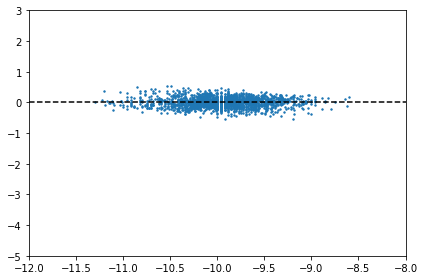

Fit to logMdot: 
 Fit: [-5.12781483 -0.79363455] 
 R^2: 0.7936345478649854 
 BSE: Intercept    0.059234
x            0.009167
dtype: float64 
 Covar:            Intercept         x
Intercept   3.285714  0.508452
x           0.508452  0.078693


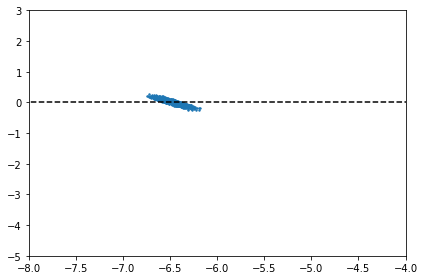

Beta= 0.5 :
(array([-9.0664324 , -0.79363455]), 0.7936345478649773, Intercept    0.104860
x            0.009167
dtype: float64,            Intercept         x
Intercept   0.194897  0.017016
x           0.017016  0.001489)
Beta= 1 :
(array([-13.00504996,  -0.79363455]), 0.7936345478649801, Intercept    0.150386
x            0.009167
dtype: float64,            Intercept         x
Intercept   0.225488  0.013729
x           0.013729  0.000838)
Beta= 1.5 :
(array([-16.94366752,  -0.79363455]), 0.7936345478649787, Intercept    0.195914
x            0.009167
dtype: float64,            Intercept         x
Intercept   0.244915  0.011448
x           0.011448  0.000536)
Alpha: 3.864607186086209e-05 ; beta: -0.793634547864976
Minimum rho: 259.41635270121463 ; Maximum rho: 35974.36925484105 ; Range: 35714.952902139834
________________________
(array([-6.60489456, -0.65707902]), 0.6570790219180465, Intercept    0.102766
x            0.010214
dtype: float64,            Intercept         x
Intercept  

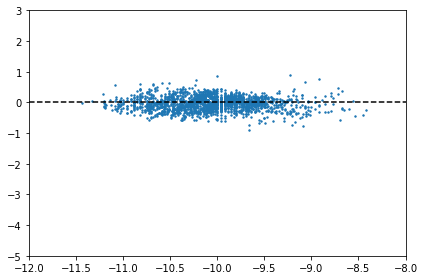

Fit to logMdot: 
 Fit: [-4.32854911 -0.65707902] 
 R^2: 0.6570790219180447 
 BSE: Intercept    0.067301
x            0.010214
dtype: float64 
 Covar:            Intercept         x
Intercept   0.868826  0.131819
x           0.131819  0.020010


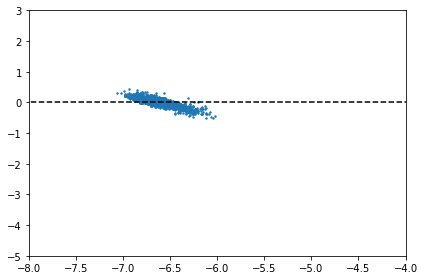

Beta= 0.5 :
(array([-7.63099639, -0.65707902]), 0.6570790219180408, Intercept    0.118810
x            0.010214
dtype: float64,            Intercept         x
Intercept   0.141516  0.012146
x           0.012146  0.001046)
Beta= 1 :
(array([-10.93344367,  -0.65707902]), 0.657079021918044, Intercept    0.170190
x            0.010214
dtype: float64,            Intercept         x
Intercept   0.163339  0.009789
x           0.009789  0.000588)
Beta= 1.5 :
(array([-14.23589095,  -0.65707902]), 0.6570790219180356, Intercept    0.221571
x            0.010214
dtype: float64,            Intercept         x
Intercept   0.177186  0.008157
x           0.008157  0.000376)
Alpha: 0.0007235123017446465 ; beta: -0.6570790219180436
Minimum rho: 246.7138203805339 ; Maximum rho: 23498.53296206254 ; Range: 23251.81914168201
________________________
(array([-5.69346997, -0.57939792]), 0.5793979207365161, Intercept    0.108791
x            0.011061
dtype: float64,            Intercept         x
Intercept   0

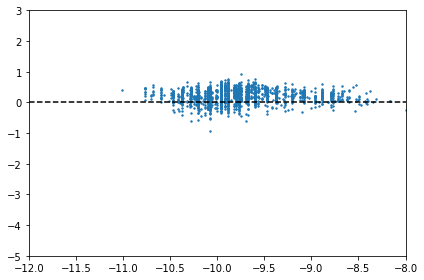

Fit to logMdot: 
 Fit: [-3.9168471  -0.57939792] 
 R^2: 0.5793979207365199 
 BSE: Intercept    0.074799
x            0.011061
dtype: float64 
 Covar:            Intercept         x
Intercept   0.704135  0.104085
x           0.104085  0.015397


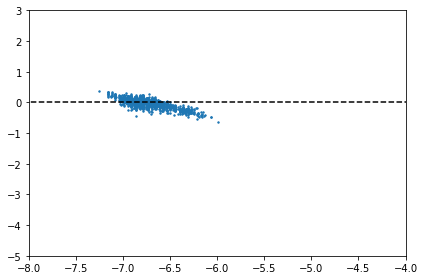

Beta= 0.5 :
(array([-6.76358209, -0.57939792]), 0.5793979207365187, Intercept    0.129312
x            0.011061
dtype: float64,            Intercept         x
Intercept   0.165465  0.014131
x           0.014131  0.001211)
Beta= 1 :
(array([-9.61031707, -0.57939792]), 0.5793979207365163, Intercept    0.183705
x            0.011061
dtype: float64,            Intercept         x
Intercept   0.187842  0.011295
x           0.011295  0.000681)
Beta= 1.5 :
(array([-12.45705206,  -0.57939792]), 0.5793979207365174, Intercept    0.238099
x            0.011061
dtype: float64,            Intercept         x
Intercept   0.201951  0.009370
x           0.009370  0.000436)
Alpha: 0.002359695457202065 ; beta: -0.5793979207365165
Minimum rho: 101.86836185854173 ; Maximum rho: 5640.487979736596 ; Range: 5538.619617878054
________________________
(array([-6.18469422, -0.61787789]), 0.6178778936298219, Intercept    0.174335
x            0.017409
dtype: float64,            Intercept         x
Intercept   1.

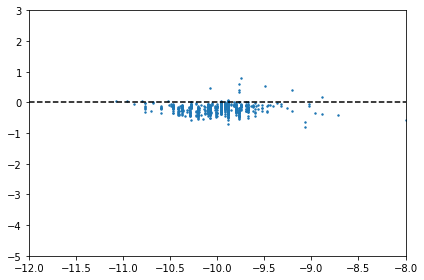

Fit to logMdot: 
 Fit: [-4.29007922 -0.61787789] 
 R^2: 0.6178778936298217 
 BSE: Intercept    0.120893
x            0.017409
dtype: float64 
 Covar:            Intercept         x
Intercept   4.954452  0.713380
x           0.713380  0.102744


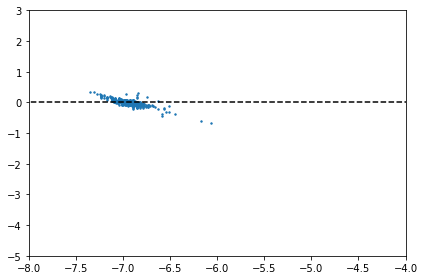

Beta= 0.5 :
(array([-7.38242633, -0.61787789]), 0.617877893629821, Intercept    0.208148
x            0.017409
dtype: float64,            Intercept         x
Intercept   0.953140  0.079667
x           0.079667  0.006668)
Beta= 1 :
(array([-10.47477344,  -0.61787789]), 0.6178778936298194, Intercept    0.295314
x            0.017409
dtype: float64,            Intercept         x
Intercept   1.079200  0.063583
x           0.063583  0.003751)
Beta= 1.5 :
(array([-13.56712055,  -0.61787789]), 0.6178778936298228, Intercept    0.382480
x            0.017409
dtype: float64,            Intercept         x
Intercept   1.158598  0.052707
x           0.052707  0.002400)
Alpha: 0.000761433015322684 ; beta: -0.6178778936298213
Minimum rho: 44.91787113919322 ; Maximum rho: 5309.757521894333 ; Range: 5264.83965075514
________________________


In [33]:
find_multiplier_for_flat_residual (M0StarData, multiplier = int(ratios_M[1]))
find_multiplier_for_flat_residual (M1StarData, multiplier = int(ratios_M[1]))
find_multiplier_for_flat_residual (C0StarData, multiplier = int(ratios_C[1]))
find_multiplier_for_flat_residual (C1StarData, multiplier = int(ratios_C[1]))

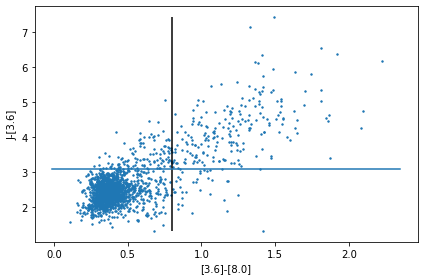

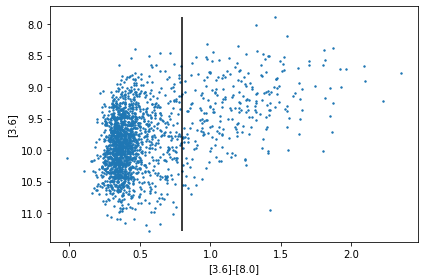

Non-sortable star found at index  0 . Assumed to not be extreme.
Non-sortable star found at index  227 . Assumed to not be extreme.
Non-sortable star found at index  243 . Assumed to not be extreme.
Non-sortable star found at index  250 . Assumed to not be extreme.
Non-sortable star found at index  748 . Assumed to not be extreme.
Non-sortable star found at index  917 . Assumed to not be extreme.
Non-sortable star found at index  1035 . Assumed to not be extreme.
Non-sortable star found at index  1189 . Assumed to not be extreme.
Non-sortable star found at index  1331 . Assumed to not be extreme.
Non-sortable star found at index  1339 . Assumed to not be extreme.
Non-sortable star found at index  1385 . Assumed to not be extreme.
Non-sortable star found at index  1597 . Assumed to not be extreme.


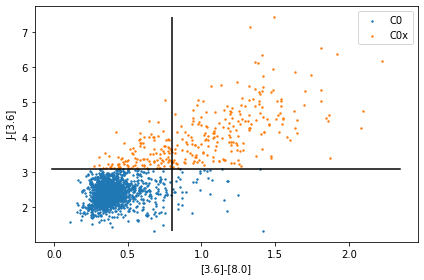

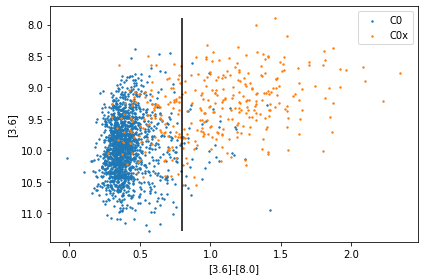

In [34]:
C0StarData_n,C0StarData_x  = sort_xC0(C0StarData)

In [35]:

print('Calculating colors for M0 stars...')
M0_reduced_for_K_minus_80 = clear_rows_with_nAn_for_color (M0StarData, KIndex, EightPointZeroIndex)
M0_color_K_minus_80 = calculate_color (M0_reduced_for_K_minus_80[KIndex],M0_reduced_for_K_minus_80[EightPointZeroIndex])

print('Calculating colors for M1 stars...')
M1_reduced_for_K_minus_80 = clear_rows_with_nAn_for_color (M1StarData, KIndex, EightPointZeroIndex)
M1_reduced_for_K_minus_80 = clear_rows_with_color_less_than_value (M1_reduced_for_K_minus_80, KIndex, EightPointZeroIndex,value=0)
M1_color_K_minus_80 = calculate_color (M1_reduced_for_K_minus_80[KIndex],M1_reduced_for_K_minus_80[EightPointZeroIndex])

print('Calculating colors for C0 stars...')
C0_n_reduced_for_K_minus_80 = clear_rows_with_nAn_for_color (C0StarData_n, KIndex, EightPointZeroIndex)
C0_n_reduced_for_K_minus_80 = clear_rows_with_color_less_than_value (C0_n_reduced_for_K_minus_80, KIndex, EightPointZeroIndex,value=0)
C0_n_color_K_minus_80 = calculate_color (C0_n_reduced_for_K_minus_80[KIndex],C0_n_reduced_for_K_minus_80[EightPointZeroIndex])

print('Calculating colors for C0x stars...')
C0_x_reduced_for_K_minus_80 = clear_rows_with_nAn_for_color (C0StarData_x, KIndex, EightPointZeroIndex)
C0_x_reduced_for_K_minus_80 = clear_rows_with_color_less_than_value (C0_x_reduced_for_K_minus_80, KIndex, EightPointZeroIndex,value=0)
C0_x_color_K_minus_80 = calculate_color (C0_x_reduced_for_K_minus_80[KIndex],C0_x_reduced_for_K_minus_80[EightPointZeroIndex])

print('Calculating colors for C1 stars...')
C1_reduced_for_K_minus_80 = clear_rows_with_nAn_for_color (C1StarData, KIndex, EightPointZeroIndex)
C1_color_K_minus_80 = calculate_color (C1_reduced_for_K_minus_80[KIndex],C1_reduced_for_K_minus_80[EightPointZeroIndex])

Calculating colors for M0 stars...
Stars removed (nAn): 9
Calculating colors for M1 stars...
Stars removed (nAn): 6
Stars removed (color<0): 1
Calculating colors for C0 stars...
Stars removed (nAn): 22
Stars removed (color<0): 1
Calculating colors for C0x stars...
Stars removed (nAn): 26
Stars removed (color<0): 0
Calculating colors for C1 stars...
Stars removed (nAn): 2


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:27: DeprecationWarning: using a non-integer array as obj in delete will result in an error in the future


In [36]:
# Functions to sort a list
def examine_index_third(elem): 
    # Sorting Key. Will sort a list based on the specified index hard coded here.
    return elem[tauIndex]

def sort_star_data_third(DataToSort):
    TransposedArray=np.transpose(DataToSort)
    TempList=TransposedArray.tolist()
    TempList=sorted(TempList,key = operator.itemgetter(1)) # use 2 because we index from 0
    return np.transpose(np.asarray(TempList))

def RangeSelect (DataToTrim, LowerBound, UpperBound ):
    return np.transpose(np.transpose(sort_star_data_third(DataToTrim))[LowerBound:UpperBound])

In [37]:
# Save folder: Mdot_resid_v_color
def plot_mdot_resids_vs_color (star_data, band_1_ind, band_2_ind, mdot_color_coeffs, comp_plus_mode = '', save_fig = False, save_folder = '', less_than_value_color_1 = -np.inf, less_than_value_color_2 = -np.inf):
    # first, we will need to trim the data sets so they are the same size after eliminating possible nAn entries.
    reduced_for_K_minus_eight = clear_rows_with_nAn_for_color(star_data, KIndex, EightPointZeroIndex) # Hard code this color because we have already settled on that as our first to examine. Could be changed if necessary.
    if less_than_value_color_1 != -np.inf:
        reduced_for_K_minus_eight = clear_rows_with_color_less_than_value(reduced_for_K_minus_eight, KIndex, EightPointZeroIndex, value=less_than_value_color_1 )
    reduced_for_chosen_color = clear_rows_with_nAn_for_color(reduced_for_K_minus_eight, band_1_ind, band_2_ind)
    if less_than_value_color_2 != -np.inf:
        reduced_for_chosen_color = clear_rows_with_color_less_than_value(reduced_for_chosen_color, band_1_ind, band_2_ind, value=less_than_value_color_2 )
    color_1 = calculate_color (reduced_for_chosen_color[KIndex],reduced_for_chosen_color[EightPointZeroIndex]) # Hard code as K-[8.0]
    color_2 = calculate_color (reduced_for_chosen_color[band_1_ind],reduced_for_chosen_color[band_2_ind])
    a = mdot_color_coeffs[0]
    b = mdot_color_coeffs[1]
    c = mdot_color_coeffs[2]
    mdot_from_color = calc_mdot_from_color(color_1, a, b, c)
    mdot_from_model = np.log10(reduced_for_chosen_color[MdotIndex])
    mdot_residual = mdot_from_color - mdot_from_model
    #print(mdot_from_model)
    chisqparams = chi_sq_fit_2d (color_2, mdot_residual )
    fit_parameters = chisqparams[0]
    line_coords = np.asarray([np.nanmin(color_2),np.nanmax(color_2)])
    print(fit_parameters)
    fit_x = line_coords
    fit_y = fit_parameters[0] + fit_parameters[1]*fit_x
    fit_label = "{:6e}".format(fit_parameters[0]) +'+'+ "{:6e}".format(fit_parameters[1])+'*'+'Color'+'; R^2 ='+ "{:6e}".format(chisqparams[1])
    plot.scatter(color_2,mdot_residual,s=2, label='Data')
    plot.plot(fit_x,fit_y, color='orange',label = fit_label)
    #plot.title(comp_plus_mode)
    # (J, H, K, 3.6micron, 4.5micron, 5.8micron, and 8.0micron)
    if band_1_ind == JIndex:
        band_1_str = 'J'
    if band_1_ind == HIndex:
        band_1_str = 'H'
    if band_1_ind == KIndex:
        band_1_str = 'K'
    if band_1_ind == ThreePointSixIndex:
        band_1_str = '[3.6]'
    if band_1_ind == FourPointFiveIndex:
        band_1_str = '[4.5]'
    if band_1_ind == FivePointEightIndex:
        band_1_str = '[5.8]'
    if band_1_ind == EightPointZeroIndex:
        band_1_str = '[8.0]'
    if band_2_ind == JIndex:
        band_2_str = 'K'
    if band_2_ind == HIndex:
        band_2_str = 'H'
    if band_2_ind == KIndex:
        band_2_str = 'K'
    if band_2_ind == ThreePointSixIndex:
        band_2_str = '[3.6]'
    if band_2_ind == FourPointFiveIndex:
        band_2_str = '[4.5]'
    if band_2_ind == FivePointEightIndex:
        band_2_str = '[5.8]'
    if band_2_ind == EightPointZeroIndex:
        band_2_str = '[8.0]'
    plot.xlabel('Color: ' + band_1_str + '-' + band_2_str)
    plot.ylabel(r'$\log \dot{M}_{color} - \log \dot{M}_{GRAMS\ model}$')
    plot.legend()
    if save_fig == True:
        plot.tight_layout()
        plot_name = save_folder + '/' + band_1_str + '-' + band_2_str + '_'+ comp_plus_mode
        plot.savefig(plot_name+'.png')
        plot.savefig(plot_name+'.pdf') # Why do journals require this format...
        plot.show()
    else:
        plot.tight_layout()
        plot.show()
    plot.close()
    
    return reduced_for_chosen_color

In [38]:
def hyperbolic_func (C, P0, P1, P2):
    # logMdot = a/(C + b) + c
    return ((P0/(C+P1)))+P2 

def hyperbolic_func_pls_lin (C, P0, P1, P2, P3):
    # logMdot = a/(K - [8.0] + b) - α col + (c - β) => logMdot = P0/(C1 + {1}) - P2*C2 + P3
    C0 = np.asarray(C[0])
    C1 = np.asarray(C[1])
    return ((P0/(C0+P1)))-P2*C1 + P3 

In [39]:
def fit_to_hyperbolic (xdata, ydata, save_fig = 0, plot_title = '', x_label='',y_label='',y_label_sanitized='', save_folder = '', flip_axes = 0, z_color_by_data=[],manual_data_bin_tau=0, z_data_to_sort=[],initial_guess=[]):
    if len (initial_guess) >0:
        fit_parameters, fit_covariances = sp.optimize.curve_fit(hyperbolic_func, xdata, ydata,p0=initial_guess)
    else:
        fit_parameters, fit_covariances = sp.optimize.curve_fit(hyperbolic_func, xdata, ydata)
    fit_left = np.min(xdata)
    fit_right = np.max(xdata)
    #fit_left = 0
    #fit_right = 5
    #print(fit_left,fit_right)
    fit_data = [fit_left]
    new_elem = fit_left + np.abs((fit_right-fit_left))/100
    while len(fit_data)<100:
        fit_data.append(new_elem)
        new_elem = new_elem + np.abs((fit_right-fit_left))/100
    #print(fit_data)
    fit_curve = hyperbolic_func (fit_data, fit_parameters[0], fit_parameters[1], fit_parameters[2])
    standard_dev_of_coeff = np.sqrt(np.diag(fit_covariances))
    fit_curve_up = hyperbolic_func (fit_data, fit_parameters[0]-standard_dev_of_coeff[0], fit_parameters[1]+standard_dev_of_coeff[1], fit_parameters[2]-standard_dev_of_coeff[2])
    fit_curve_low = hyperbolic_func (fit_data, fit_parameters[0]+standard_dev_of_coeff[0], fit_parameters[1]-standard_dev_of_coeff[1], fit_parameters[2]+standard_dev_of_coeff[2])
    
    fig, ax = plt.subplots()
    if flip_axes == 0:
        if len(z_color_by_data)>0: 
            ax.scatter(xdata, ydata, label='Data',s=2,c=z_color_by_data,cmap='Dark2')
        elif manual_data_bin_tau >0:
            zdata = np.asarray(z_data_to_sort)
            data_to_sort = np.transpose(np.asarray([xdata, ydata, zdata])) # Stack our data so we can associate data points with each other
            a = data_to_sort
            ind=np.argsort(a[:,-1])
            sorted_data=np.transpose(np.asarray(a[ind]))
            #print('sorted_data:',sorted_data)
            #print(len(data_to_sort))
            #print('sorted_data:',sorted_data)
            #print(data_to_sort)
            bin_size = len(data_to_sort)//manual_data_bin_tau
            bin_bottom = 0
            bin_top = bin_size
            print('len(data_to_sort):',len(data_to_sort))
            i=0
            while i < manual_data_bin_tau:
                if i ==0: # When on first bin
                    working_x=sorted_data[0][:bin_top]
                    working_y=sorted_data[1][:bin_top]
                    data_label = 'tau<'+str( np.max(sorted_data[2][:bin_size]))[0:7]
                    ax.scatter(working_x, working_y, label=data_label,s=2)
                elif i == manual_data_bin_tau-1: # If we are on the last bin
                    working_x=sorted_data[0][bin_bottom:]
                    working_y=sorted_data[1][bin_bottom:]
                    data_label = 'tau>'+str(np.min(sorted_data[2][bin_bottom:]))[0:7]
                    ax.scatter(working_x, working_y, label=data_label,s=2)
                else: # We are on some intermediate bin
                    working_x=sorted_data[0][bin_bottom:bin_top]
                    working_y=sorted_data[1][bin_bottom:bin_top]
                    #print('tau range:',sorted_data[2][bin_bottom:bin_top])
                    data_label = str(np.min(sorted_data[2][bin_bottom:bin_top]))[0:7] +'<tau<'+str(np.max(sorted_data[2][bin_bottom:bin_top]))[0:7]
                    ax.scatter(working_x, working_y, label=data_label,s=2)
                bin_bottom = bin_bottom+bin_size
                print('bin_bottom:',bin_bottom)
                bin_top = bin_top + bin_size
                print('bin_top:',bin_top)
                i = i + 1
        else:
            ax.scatter(xdata, ydata, label='Data',s=2)
        ax.plot(fit_data,fit_curve,label='fit: a=%5.3f, b=%5.3f, c=%5.3f' % tuple(fit_parameters),color='orange')
        ax.text(0.03, .97,plot_title,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
        #plot.plot(fit_data,fit_curve_up ,color='orange',linestyle='--')
        #plot.plot(fit_data,fit_curve_low ,color='orange',linestyle='--')
        #ax.set_title(plot_title, loc='left', pad=-100)
        #plot.legend()
        #plot.xlim(0,5)
        ax.set_ylim((np.min(ydata)-0.1), (np.max(ydata)+0.1))
        #plot.ylim(-8,-4.5)
        plot.xlabel(x_label)
        plot.ylabel(y_label)
        plot.tight_layout()
        if save_fig !=0:
            if y_label_sanitized != '':
                plot.savefig(save_folder+'/'+plot_title+'_'+y_label_sanitized+'_vs_'+x_label+'.pdf')
                plot.savefig(save_folder+'/'+plot_title+'_'+y_label_sanitized+'_vs_'+x_label+'.png')
            else:
                plot.savefig(save_folder+'/'+plot_title+'_'+y_label+'_vs_'+x_label+'.pdf')
                plot.savefig(save_folder+'/'+plot_title+'_'+y_label+'_vs_'+x_label+'.png')
            plot.show()
        else:
            plot.show()
        plot.close()
    else:
        if len(z_color_by_data)>0: 
            ax.scatter(xdata, ydata, label='Data',s=2,c=z_color_by_data,cmap='Dark2')
        elif manual_data_bin_tau >0:
            zdata = np.asarray(z_data_to_sort)
            data_to_sort = np.transpose(np.asarray([xdata, ydata, zdata])) # Stack our data so we can associate data points with each other
            a = data_to_sort
            ind=np.argsort(a[:,-1])
            sorted_data=np.transpose(np.asarray(a[ind]))
            print('sorted_data:',sorted_data)
            #print(len(data_to_sort))
            #print('sorted_data:',sorted_data)
            #print(data_to_sort)
            bin_size = len(data_to_sort)//manual_data_bin_tau
            bin_bottom = 0
            bin_top = bin_size
            print('len(data_to_sort):',len(data_to_sort))
            i=0
            while i < manual_data_bin_tau:
                if i ==0: # When on first bin
                    working_x=sorted_data[0][:bin_top]
                    working_y=sorted_data[1][:bin_top]
                    data_label = 'tau<'+str( np.max(sorted_data[2][:bin_size]))[0:7]
                    ax.scatter(working_x, working_y, label=data_label,s=2)
                elif i == manual_data_bin_tau-1: # If we are on the last bin
                    working_x=sorted_data[0][bin_bottom:]
                    working_y=sorted_data[1][bin_bottom:]
                    data_label = 'tau>'+str(np.min(sorted_data[2][bin_bottom:]))[0:7]
                    ax.scatter(working_x, working_y, label=data_label,s=2)
                else: # We are on some intermediate bin
                    working_x=sorted_data[0][bin_bottom:bin_top]
                    working_y=sorted_data[1][bin_bottom:bin_top]
                    #print('tau range:',sorted_data[2][bin_bottom:bin_top])
                    data_label = str(np.min(sorted_data[2][bin_bottom:bin_top]))[0:7] +'<tau<'+str(np.max(sorted_data[2][bin_bottom:bin_top]))[0:7]
                    ax.scatter(working_x, working_y, label=data_label,s=2)
                bin_bottom = bin_bottom+bin_size
                print('bin_bottom:',bin_bottom)
                bin_top = bin_top + bin_size
                print('bin_top:',bin_top)
                i = i + 1
        else:
            ax.scatter(xdata, ydata, label='Data',s=2)
        ax.plot(fit_curve,fit_data,label='fit: a=%5.3f, b=%5.3f, c=%5.3f' % tuple(fit_parameters),color='orange')
        #ax.set_title(plot_title, loc='left', pad=-100)
        ax.text(0.03, .97,plot_title,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
        #plot.legend()
        plot.xlabel(y_label)
        plot.ylabel(x_label)
        plot.tight_layout()
        if save_fig !=0:
            if y_label_sanitized != '':
                plot.savefig(save_folder+'/'+plot_title+'_'+y_label_sanitized+'_vs_'+x_label+'.pdf')
                plot.savefig(save_folder+'/'+plot_title+'_'+y_label_sanitized+'_vs_'+x_label+'.png')
            else:
                plot.savefig(save_folder+'/'+plot_title+'_'+y_label+'_vs_'+x_label+'.pdf')
                plot.savefig(save_folder+'/'+plot_title+'_'+y_label+'_vs_'+x_label+'.png')
            plot.show()
        else:
            plot.show()
        plot.close()
    return [fit_parameters[0], fit_parameters[1], fit_parameters[2]], fit_covariances
    

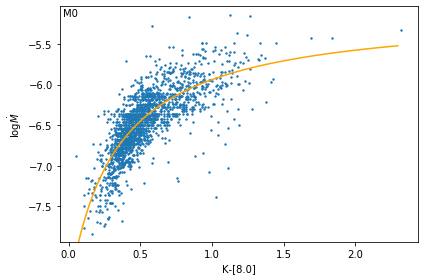

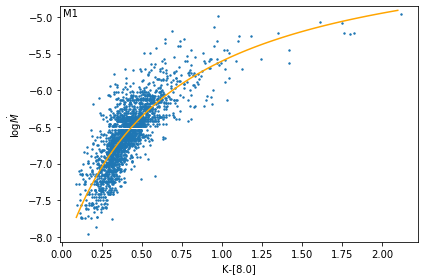

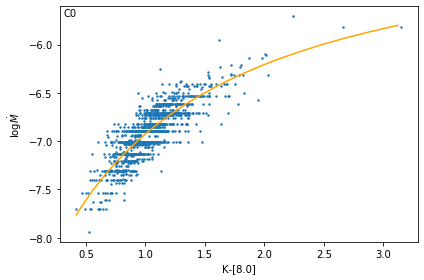

In [40]:

save_value = 0
M0_color_coeffs, M0_color_covars = fit_to_hyperbolic(M0_color_K_minus_80,np.log10(M0_reduced_for_K_minus_80[MdotIndex]), plot_title='M0', x_label='K-[8.0]', y_label = r'$\log \dot{M}$', y_label_sanitized = 'logMdot', z_data_to_sort=M0_reduced_for_K_minus_80[tauIndex])
M1_color_coeffs, M1_color_covars = fit_to_hyperbolic(M1_color_K_minus_80,np.log10(M1_reduced_for_K_minus_80[MdotIndex]), plot_title='M1', x_label='K-[8.0]', y_label = r'$\log \dot{M}$', y_label_sanitized = 'logMdot', z_data_to_sort=M1_reduced_for_K_minus_80[tauIndex])
C0_color_coeffs, C0_color_covars = fit_to_hyperbolic(C0_n_color_K_minus_80,np.log10(C0_n_reduced_for_K_minus_80[MdotIndex]), plot_title='C0', x_label='K-[8.0]', y_label = r'$\log \dot{M}$', y_label_sanitized = 'logMdot', z_data_to_sort=C0_n_reduced_for_K_minus_80[tauIndex])


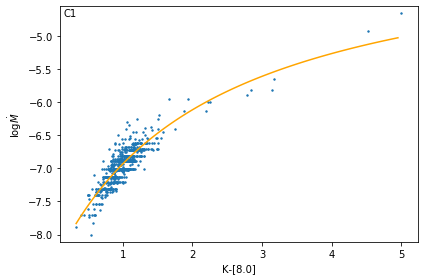

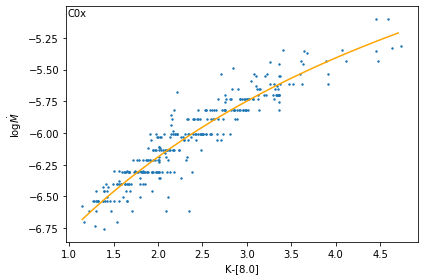

In [41]:
Directory = 'Single_Parameter_Fits/1color_Mdot'
save_value = 1

C1_color_coeffs, C1_color_covars = fit_to_hyperbolic(C1_color_K_minus_80,np.log10(C1_reduced_for_K_minus_80[MdotIndex]), plot_title='C1', x_label='K-[8.0]', y_label = r'$\log \dot{M}$', y_label_sanitized = 'logMdot', z_data_to_sort=C1_reduced_for_K_minus_80[tauIndex],save_fig = save_value,initial_guess = C0_color_coeffs,save_folder=Directory)
C0x_color_coeffs, C0x_color_covars = fit_to_hyperbolic(C0_x_color_K_minus_80,np.log10(C0_x_reduced_for_K_minus_80[MdotIndex]), plot_title='C0x', x_label='K-[8.0]', y_label = r'$\log \dot{M}$', y_label_sanitized = 'logMdot', z_data_to_sort=C0_x_reduced_for_K_minus_80[tauIndex],initial_guess = C0_color_coeffs, save_fig = save_value,save_folder=Directory )

In [42]:
print(C0x_color_coeffs)
print(np.sqrt(np.diag(C0x_color_covars)))
print(C1_color_coeffs)
print(np.sqrt(np.diag(C1_color_covars)))

[-23.406931502744033, 4.806309838601964, -2.7495017740520336]
[8.61687488 1.32296441 0.59601383]
[-11.273442785426498, 2.2461195636970555, -3.4620901139479208]
[1.72707533 0.26164228 0.255049  ]


Other colors? We have 7 wavelengths (J, H, K, 3.6micron, 4.5micron, 5.8micron, and 8.0micron):
    J-H, J-K, J-3.6, J-4.5, J-5.8, J-8.0
    H-K, H-3.6, H-4.5, H-5.8, H-8.0
    K-3.6, K-4.5, K-5.8
    3.6-4.5, 3.6-5.8, 3.6-8.0
    4.5-5.8, 4.5-8.0
    5.8-8.0

Stars removed (nAn): 9
Stars removed (nAn): 7
[ 1.09678774 -1.23631458]


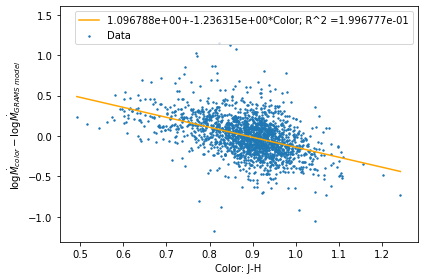

Stars removed (nAn): 6
Stars removed (nAn): 5
[ 0.90687062 -0.97933765]


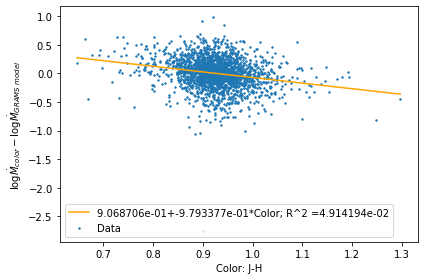

Stars removed (nAn): 22
Stars removed (nAn): 5
[ 0.57856052 -0.50286086]


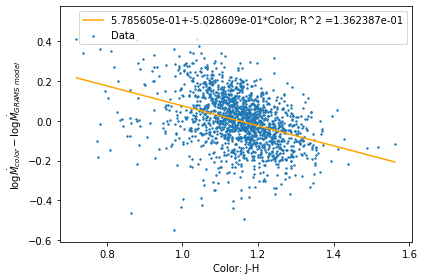

Stars removed (nAn): 26
Stars removed (nAn): 1
[ 0.11028316 -0.07313528]


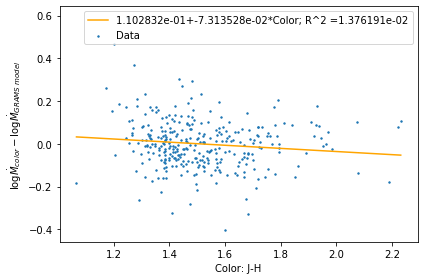

Stars removed (nAn): 2
Stars removed (nAn): 2
[ 0.13767271 -0.12196666]


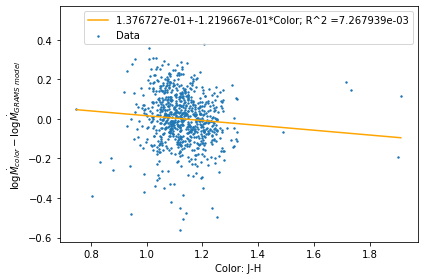

Stars removed (nAn): 9
Stars removed (nAn): 6
[ 1.02630281 -0.86897687]


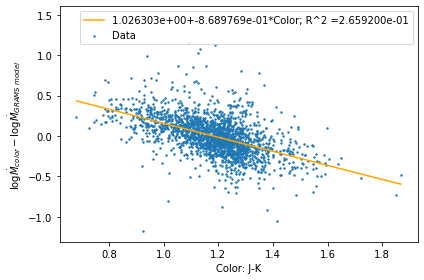

Stars removed (nAn): 6
Stars removed (nAn): 4
[ 0.9824925  -0.80353049]


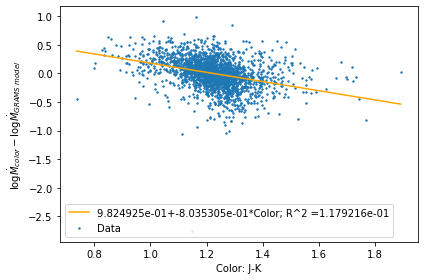

Stars removed (nAn): 22
Stars removed (nAn): 4
[ 0.45017317 -0.25227651]


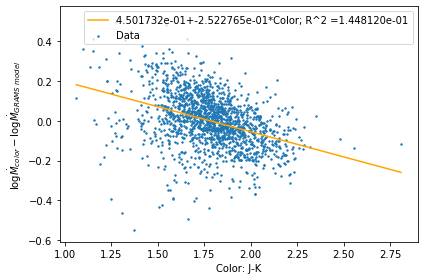

Stars removed (nAn): 26
Stars removed (nAn): 1
[ 0.07524171 -0.02856183]


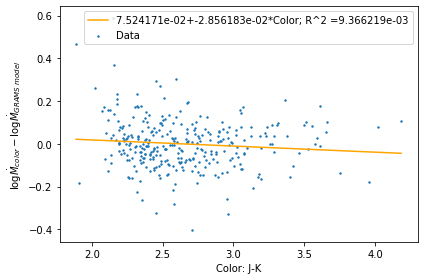

Stars removed (nAn): 2
Stars removed (nAn): 2
[ 0.13841479 -0.08078407]


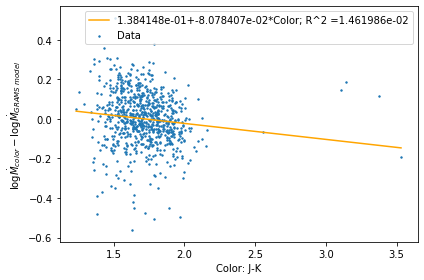

Stars removed (nAn): 9
Stars removed (nAn): 6
[ 0.56570908 -0.39092227]


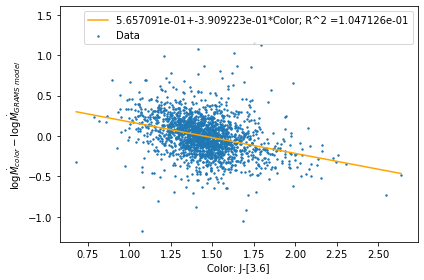

Stars removed (nAn): 6
Stars removed (nAn): 13
[ 0.51536672 -0.3543821 ]


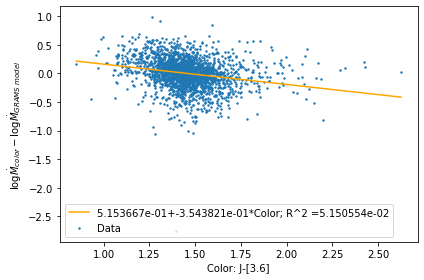

Stars removed (nAn): 22
Stars removed (nAn): 14
[ 0.27866009 -0.11536603]


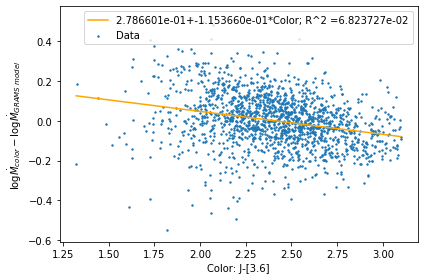

Stars removed (nAn): 26
Stars removed (nAn): 1
[-0.02940996  0.00726426]


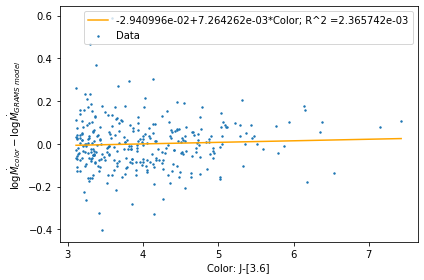

Stars removed (nAn): 2
Stars removed (nAn): 11
[ 0.049512  -0.0208947]


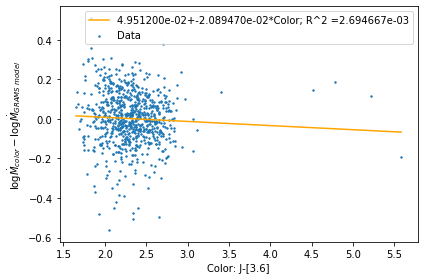

Stars removed (nAn): 9
Stars removed (nAn): 7
[ 0.41202919 -0.2869472 ]


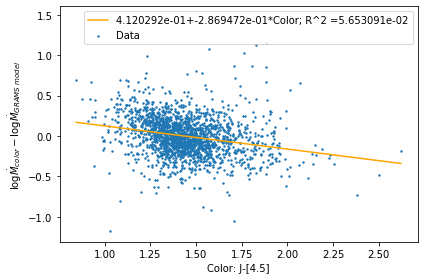

Stars removed (nAn): 6
Stars removed (nAn): 4
[ 0.31088742 -0.22402439]


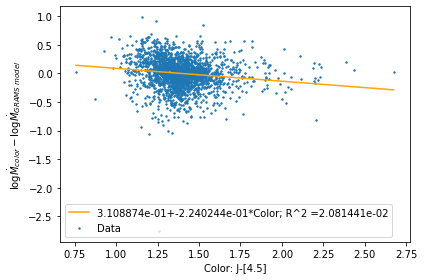

Stars removed (nAn): 22
Stars removed (nAn): 5
[ 0.25844771 -0.11103246]


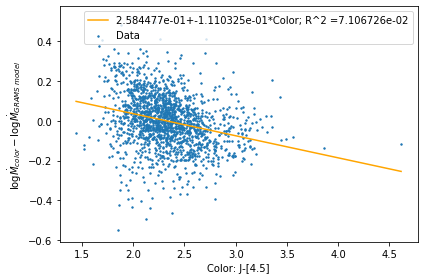

Stars removed (nAn): 26
Stars removed (nAn): 1
[-0.00137313  0.00025377]


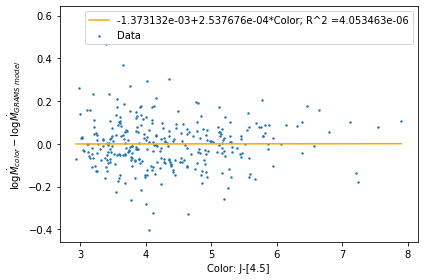

Stars removed (nAn): 2
Stars removed (nAn): 2
[ 0.04006935 -0.01810138]


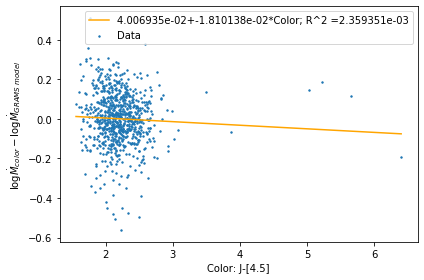

Stars removed (nAn): 9
Stars removed (nAn): 7
[ 0.4543422  -0.28594256]


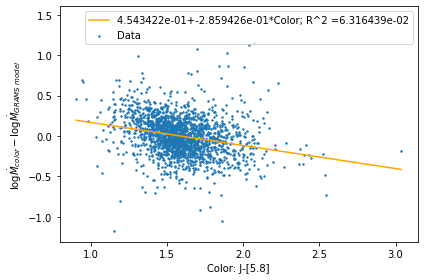

Stars removed (nAn): 6
Stars removed (nAn): 11
[ 0.39783339 -0.25836979]


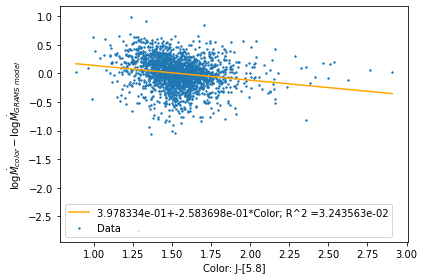

Stars removed (nAn): 22
Stars removed (nAn): 12
[ 0.22017386 -0.09220083]


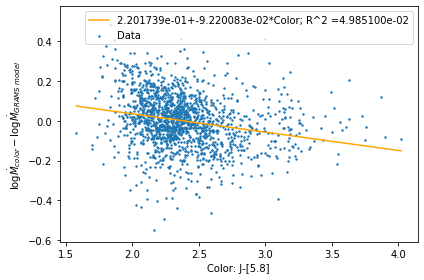

Stars removed (nAn): 26
Stars removed (nAn): 2
[ 0.0083266  -0.00211264]


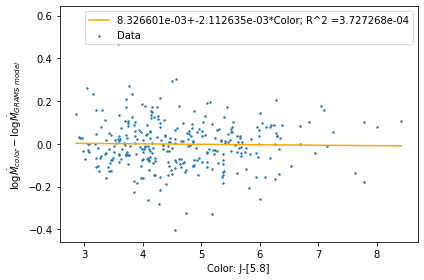

Stars removed (nAn): 2
Stars removed (nAn): 7
[ 0.0192341  -0.00806738]


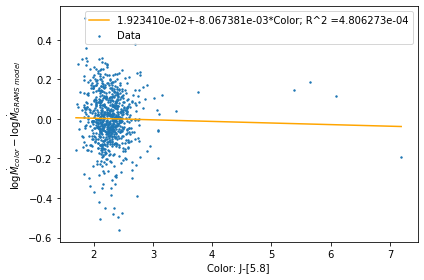

Stars removed (nAn): 9
Stars removed (nAn): 6
[ 0.41673732 -0.24249658]


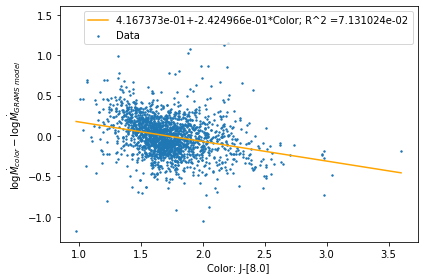

Stars removed (nAn): 6
Stars removed (nAn): 4
[ 0.25621728 -0.15600805]


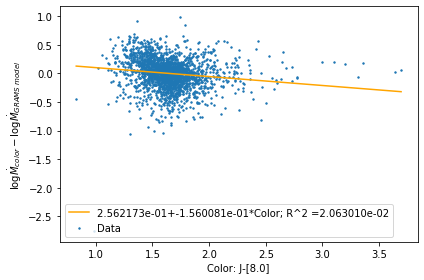

Stars removed (nAn): 22
Stars removed (nAn): 4
[ 0.22721583 -0.08057951]


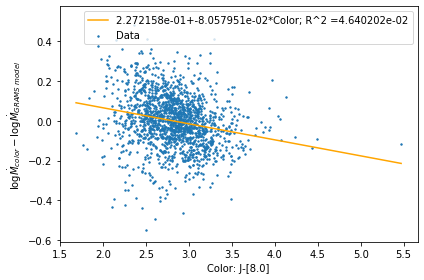

Stars removed (nAn): 26
Stars removed (nAn): 1
[ 0.01963637 -0.00397244]


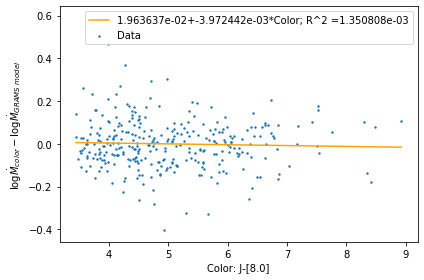

Stars removed (nAn): 2
Stars removed (nAn): 2
[ 0.03790565 -0.01389837]


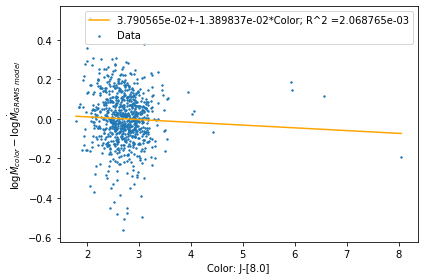

Stars removed (nAn): 9
Stars removed (nAn): 2
[ 0.41076999 -1.39714151]


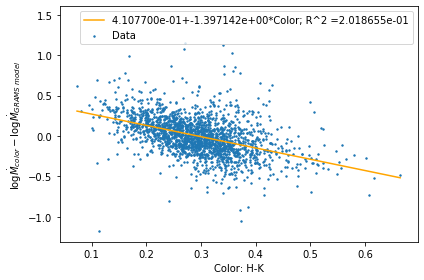

Stars removed (nAn): 6
Stars removed (nAn): 3
[ 0.40187874 -1.35673374]


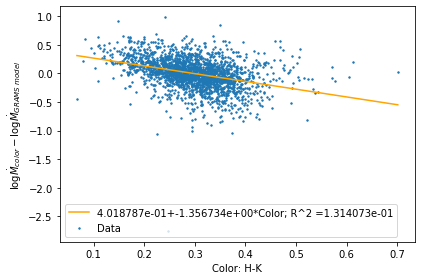

Stars removed (nAn): 22
Stars removed (nAn): 4
[ 0.26197312 -0.41209328]


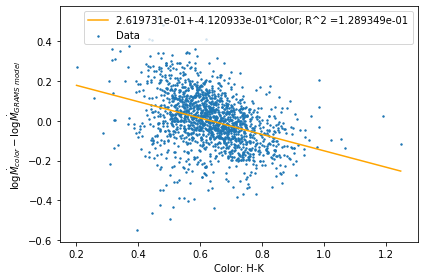

Stars removed (nAn): 26
Stars removed (nAn): 0
[ 0.04311041 -0.03803615]


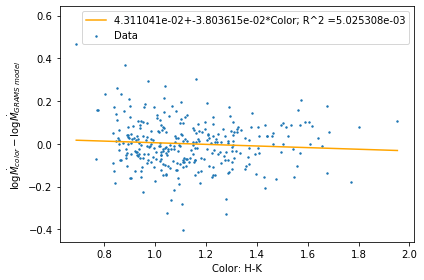

Stars removed (nAn): 2
Stars removed (nAn): 0
[ 0.09463775 -0.16151816]


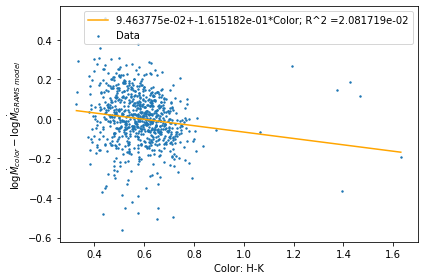

Stars removed (nAn): 9
Stars removed (nAn): 2
[0.41076999 1.39714151]


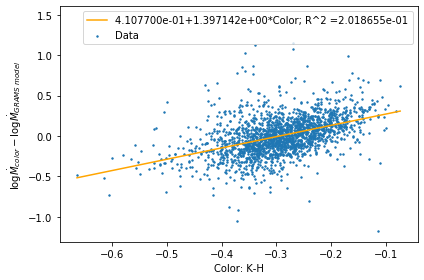

Stars removed (nAn): 6
Stars removed (nAn): 3
[0.40187874 1.35673374]


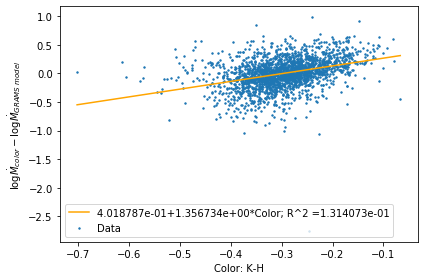

Stars removed (nAn): 22
Stars removed (nAn): 4
[0.26197312 0.41209328]


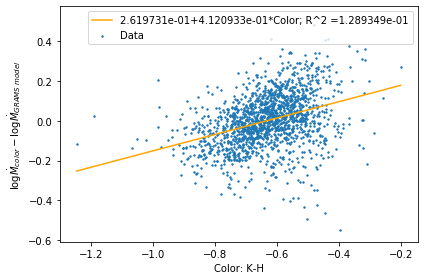

Stars removed (nAn): 26
Stars removed (nAn): 0
[0.04311041 0.03803615]


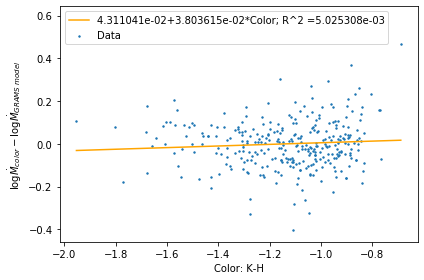

Stars removed (nAn): 2
Stars removed (nAn): 0
[0.09463775 0.16151816]


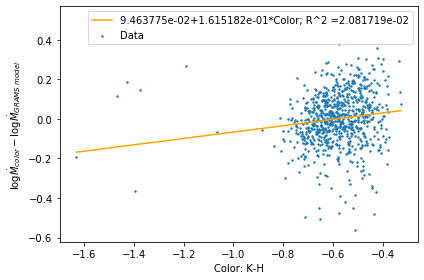

Stars removed (nAn): 9
Stars removed (nAn): 2
[ 0.13705505 -0.24445479]


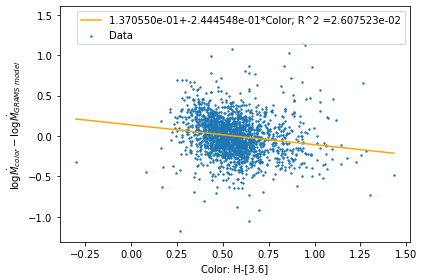

Stars removed (nAn): 6
Stars removed (nAn): 12
[ 0.20540933 -0.38988603]


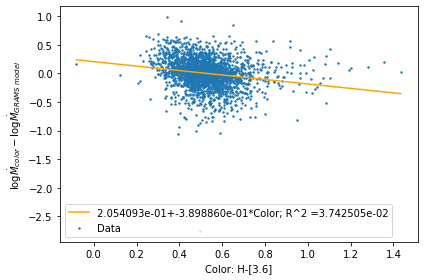

Stars removed (nAn): 22
Stars removed (nAn): 15
[ 0.14100586 -0.11115509]


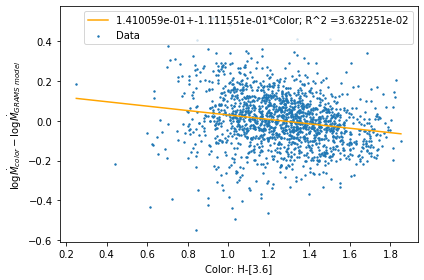

Stars removed (nAn): 26
Stars removed (nAn): 0
[-0.04728667  0.01888965]


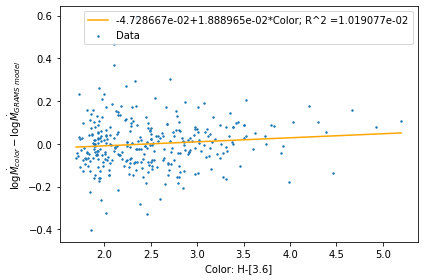

Stars removed (nAn): 2
Stars removed (nAn): 10
[ 0.04274654 -0.03529511]


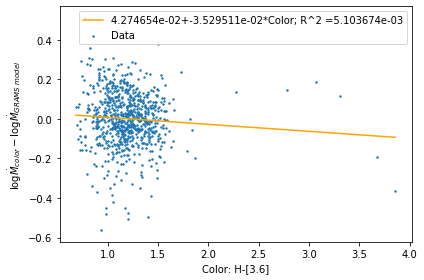

Stars removed (nAn): 9
Stars removed (nAn): 3
[ 0.03532729 -0.06444512]


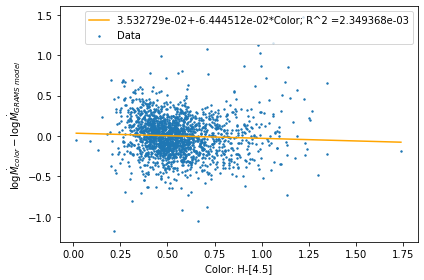

Stars removed (nAn): 6
Stars removed (nAn): 3
[ 0.07347652 -0.16078413]


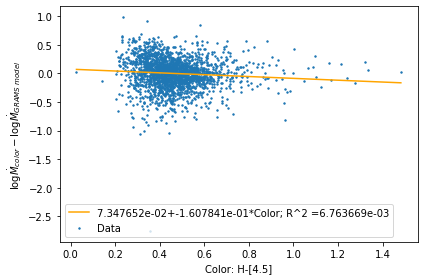

Stars removed (nAn): 22
Stars removed (nAn): 5
[ 0.10985737 -0.09297021]


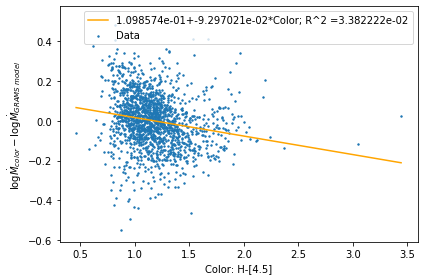

Stars removed (nAn): 26
Stars removed (nAn): 0
[-0.01498655  0.00530797]


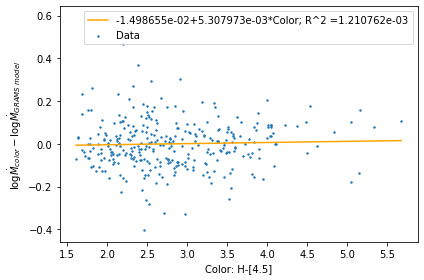

Stars removed (nAn): 2
Stars removed (nAn): 0
[ 0.02237143 -0.02058388]


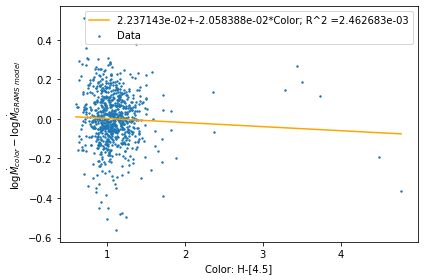

Stars removed (nAn): 9
Stars removed (nAn): 3
[ 0.06549471 -0.09334954]


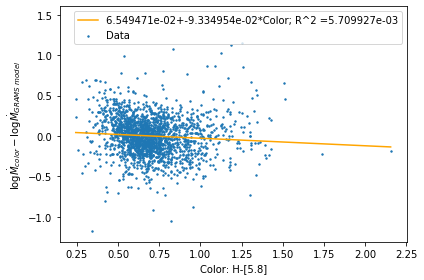

Stars removed (nAn): 6
Stars removed (nAn): 10
[ 0.14518762 -0.23742481]


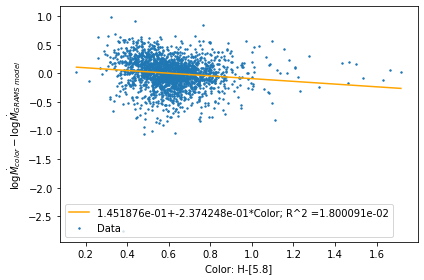

Stars removed (nAn): 22
Stars removed (nAn): 12
[ 0.07133131 -0.0571246 ]


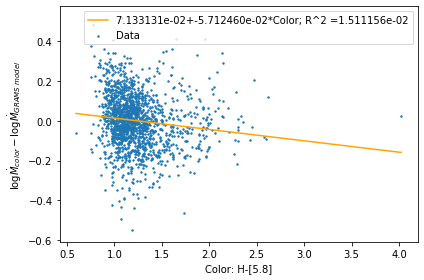

Stars removed (nAn): 26
Stars removed (nAn): 1
[-0.00250303  0.00042518]


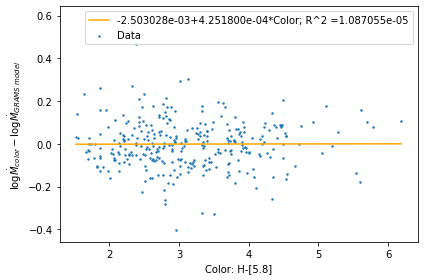

Stars removed (nAn): 2
Stars removed (nAn): 5
[ 0.01170515 -0.00944797]


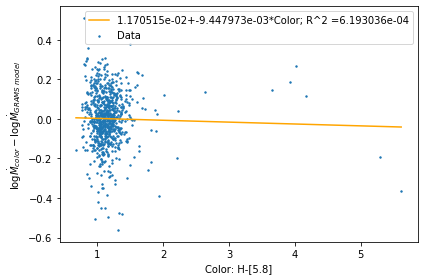

Stars removed (nAn): 9
Stars removed (nAn): 2
[ 0.10390317 -0.12481143]


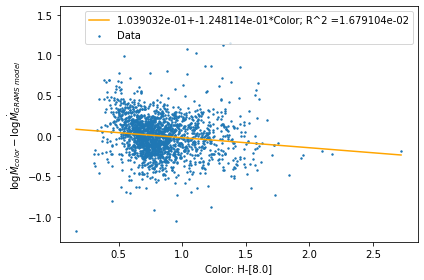

Stars removed (nAn): 6
Stars removed (nAn): 3
[ 0.09121587 -0.12828306]


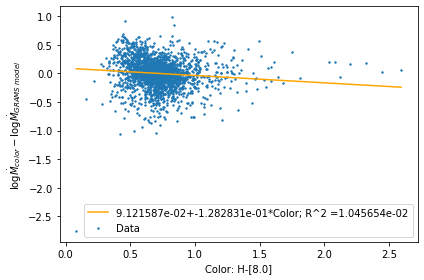

Stars removed (nAn): 22
Stars removed (nAn): 4
[ 0.09842055 -0.05873325]


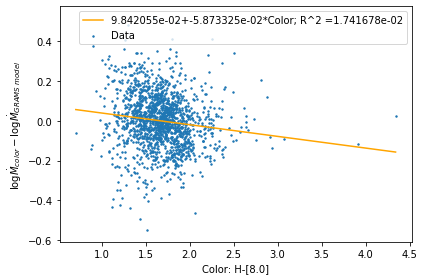

Stars removed (nAn): 26
Stars removed (nAn): 0
[ 0.00702831 -0.00200538]


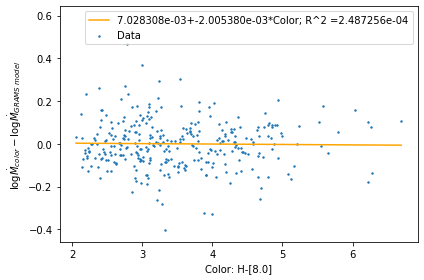

Stars removed (nAn): 2
Stars removed (nAn): 0
[ 0.02693338 -0.01682879]


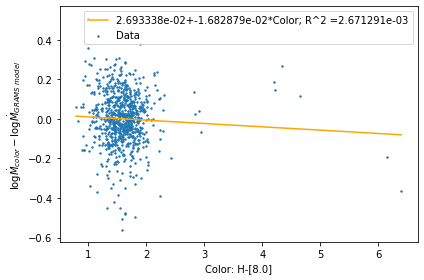

Stars removed (nAn): 9
Stars removed (nAn): 0
[-0.04280104  0.16024949]


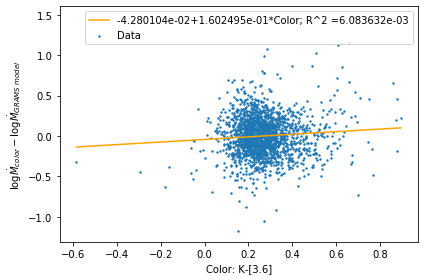

Stars removed (nAn): 6
Stars removed (nAn): 9
[-0.00094576  0.00169927]


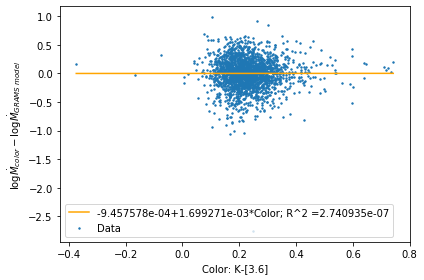

Stars removed (nAn): 22
Stars removed (nAn): 11
[-0.00848116  0.01269728]


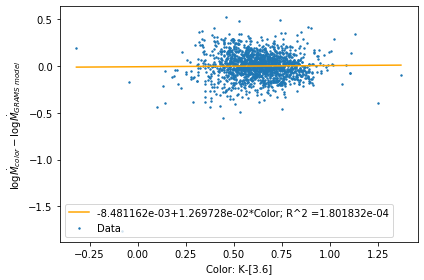

Stars removed (nAn): 26
Stars removed (nAn): 0
[-0.06578884  0.04802438]


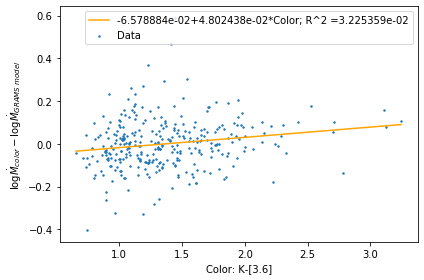

Stars removed (nAn): 2
Stars removed (nAn): 10
[ 0.00506541 -0.0072472 ]


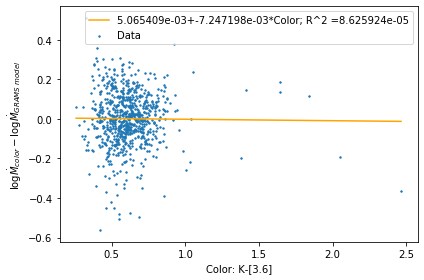

Stars removed (nAn): 9
Stars removed (nAn): 1
[-0.06617718  0.25760936]


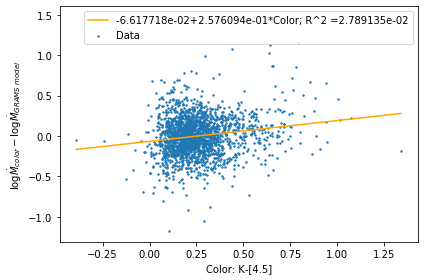

Stars removed (nAn): 6
Stars removed (nAn): 0
[-0.06539867  0.3842375 ]


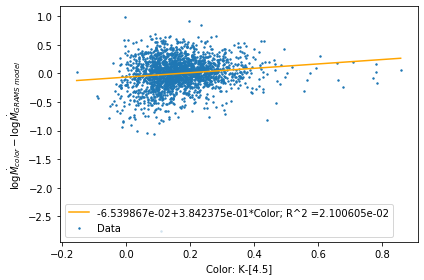

Stars removed (nAn): 22
Stars removed (nAn): 1
[ 0.00290902 -0.00744035]


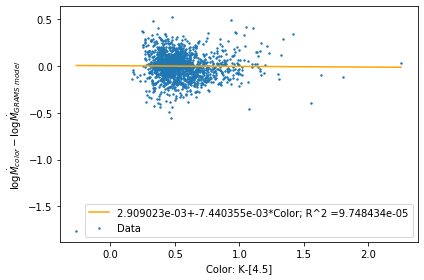

Stars removed (nAn): 26
Stars removed (nAn): 0
[-0.02574019  0.0152309 ]


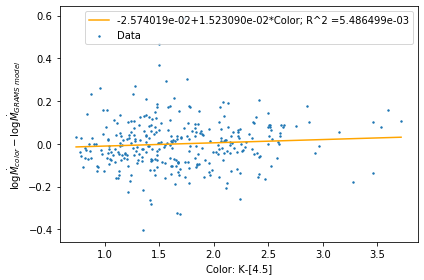

Stars removed (nAn): 2
Stars removed (nAn): 0
[-0.00158141  0.00315708]


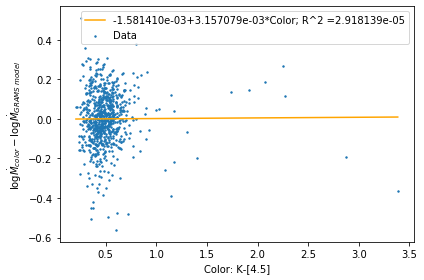

Stars removed (nAn): 9
Stars removed (nAn): 1
[-0.06971566  0.16996907]


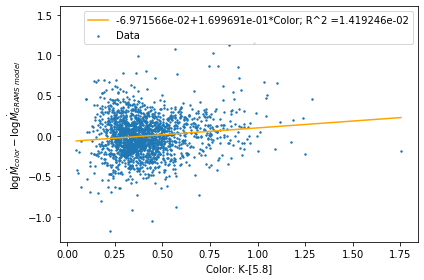

Stars removed (nAn): 6
Stars removed (nAn): 7
[-0.03878241  0.11979387]


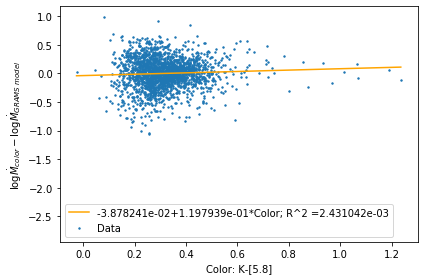

Stars removed (nAn): 22
Stars removed (nAn): 8
[-0.01380108  0.02217254]


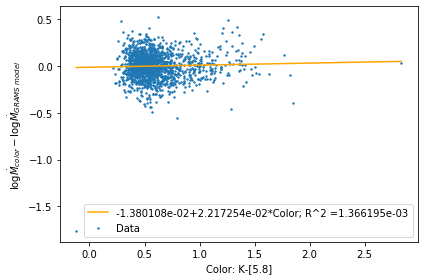

Stars removed (nAn): 26
Stars removed (nAn): 1
[-0.00878619  0.00382925]


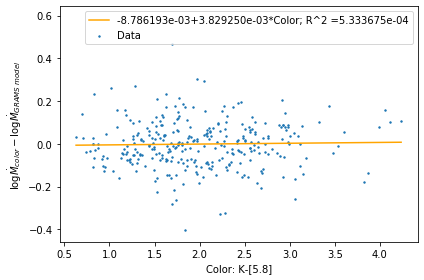

Stars removed (nAn): 2
Stars removed (nAn): 5
[-0.00696551  0.0131717 ]


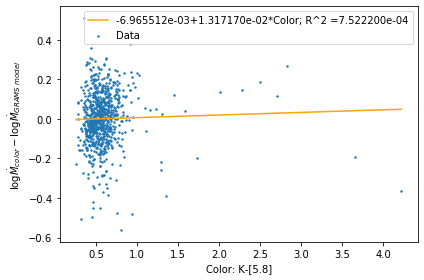

Stars removed (nAn): 9
Stars removed (nAn): 1
[0.00466517 0.45748499]


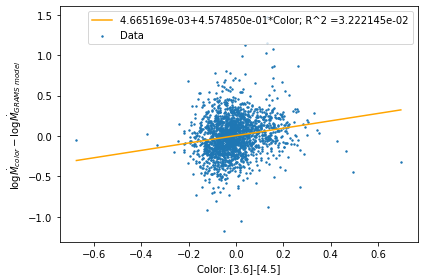

Stars removed (nAn): 6
Stars removed (nAn): 9
[0.05319088 0.82533427]


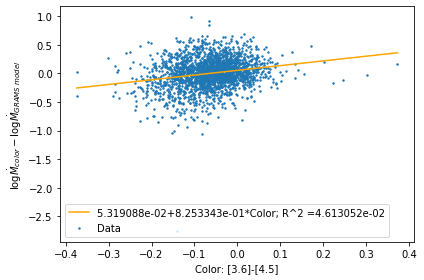

Stars removed (nAn): 22
Stars removed (nAn): 12
[-0.00267825 -0.02466565]


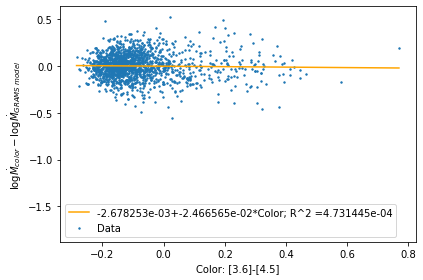

Stars removed (nAn): 26
Stars removed (nAn): 0
[ 0.02632823 -0.08225161]


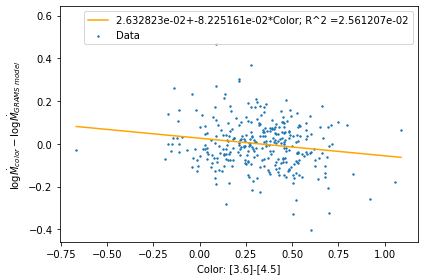

Stars removed (nAn): 2
Stars removed (nAn): 10
[-0.00023617 -0.0078808 ]


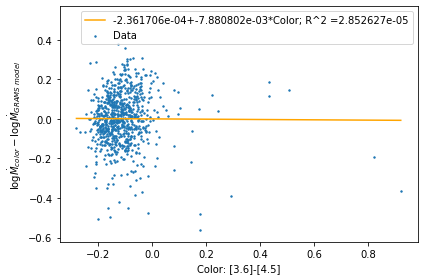

Stars removed (nAn): 9
Stars removed (nAn): 1
[-0.03416611  0.23877251]


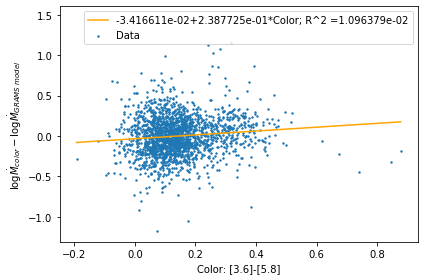

Stars removed (nAn): 6
Stars removed (nAn): 9
[-0.02365541  0.26867891]


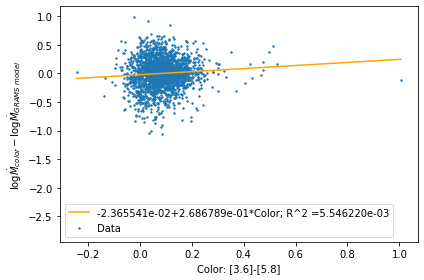

Stars removed (nAn): 22
Stars removed (nAn): 13
[0.00016252 0.01990083]


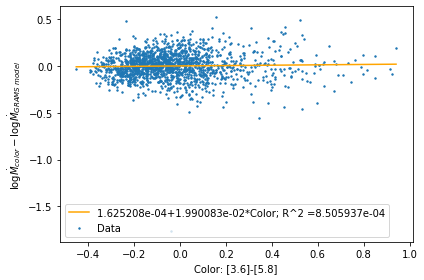

Stars removed (nAn): 26
Stars removed (nAn): 1
[ 0.0331331  -0.05559869]


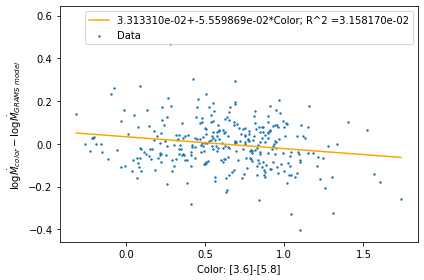

Stars removed (nAn): 2
Stars removed (nAn): 10
[0.00113087 0.01585516]


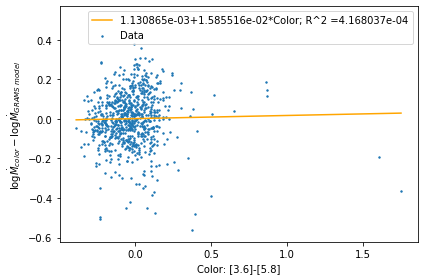

Stars removed (nAn): 9
Stars removed (nAn): 0
[ 0.01823723 -0.06695406]


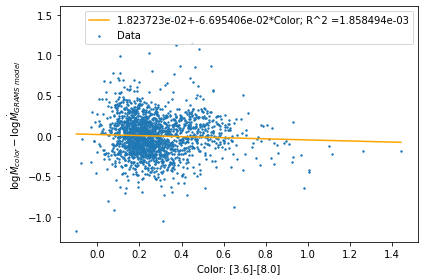

Stars removed (nAn): 6
Stars removed (nAn): 9
[-0.01441789  0.07285215]


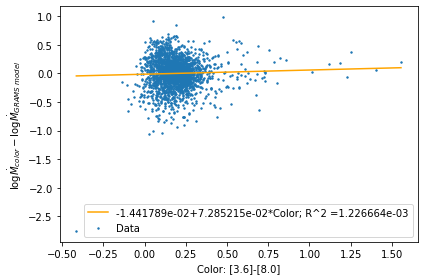

Stars removed (nAn): 22
Stars removed (nAn): 11
[-0.02497202  0.06029942]


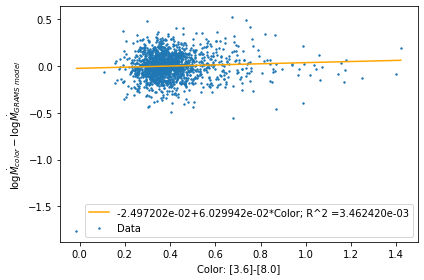

Stars removed (nAn): 26
Stars removed (nAn): 0
[ 0.05980125 -0.0597168 ]


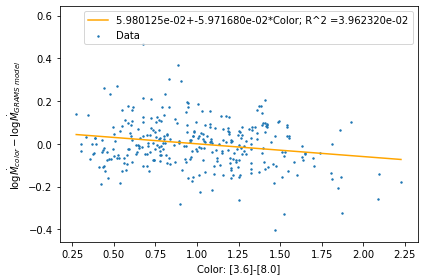

Stars removed (nAn): 2
Stars removed (nAn): 10
[ 0.01317669 -0.03128277]


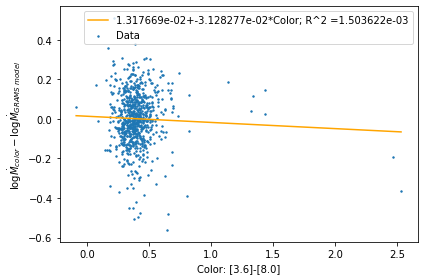

Stars removed (nAn): 9
Stars removed (nAn): 2
[ 0.08643326 -0.56566927]


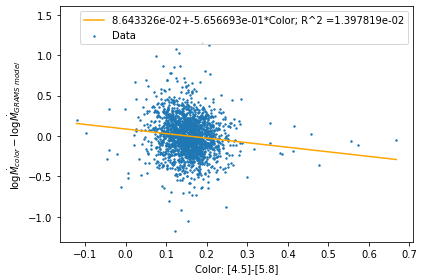

Stars removed (nAn): 6
Stars removed (nAn): 7
[ 0.15467992 -1.02854954]


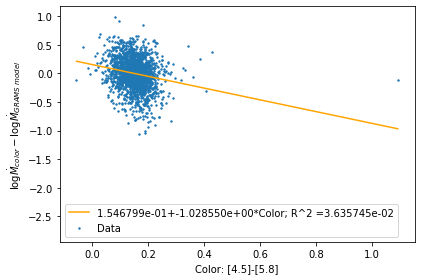

Stars removed (nAn): 22
Stars removed (nAn): 9
[-0.00717957  0.11672389]


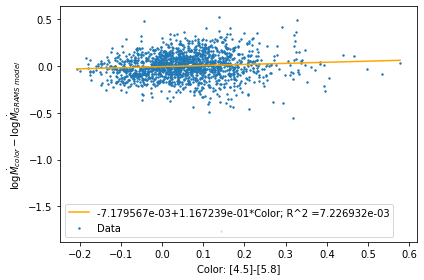

Stars removed (nAn): 26
Stars removed (nAn): 1
[ 0.028513   -0.10001264]


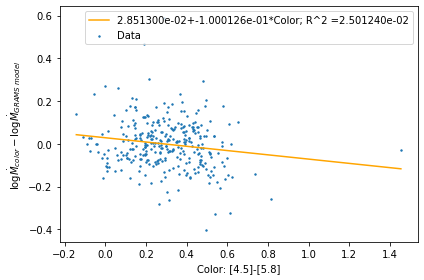

Stars removed (nAn): 2
Stars removed (nAn): 5
[-0.00569269  0.07764001]


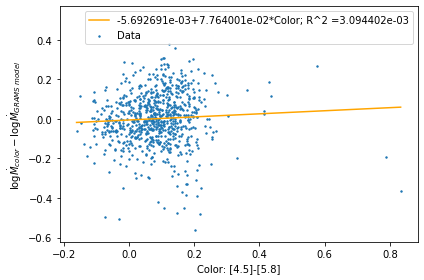

Stars removed (nAn): 9
Stars removed (nAn): 1
[ 0.13593042 -0.48089633]


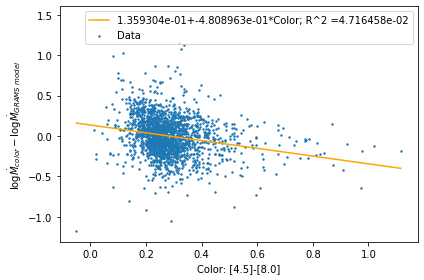

Stars removed (nAn): 6
Stars removed (nAn): 0
[ 0.05934006 -0.23699847]


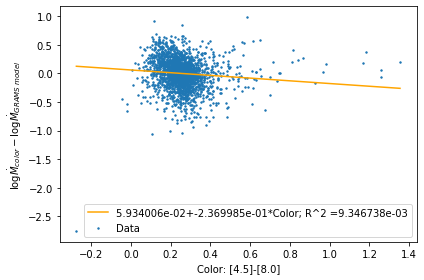

Stars removed (nAn): 22
Stars removed (nAn): 1
[-0.07067721  0.14162   ]


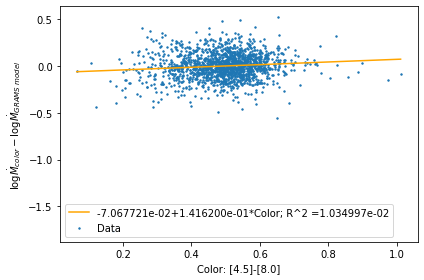

Stars removed (nAn): 26
Stars removed (nAn): 0
[ 0.07179973 -0.10538321]


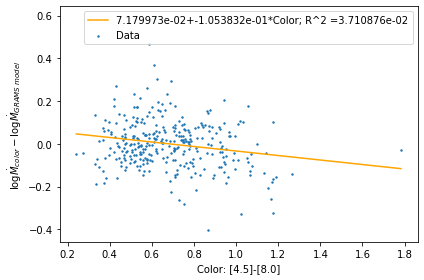

Stars removed (nAn): 2
Stars removed (nAn): 0
[ 0.02474101 -0.04817243]


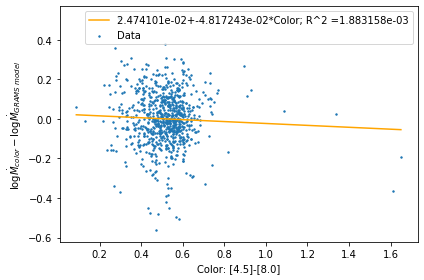

Stars removed (nAn): 9
Stars removed (nAn): 1
[ 0.0662944  -0.51276384]


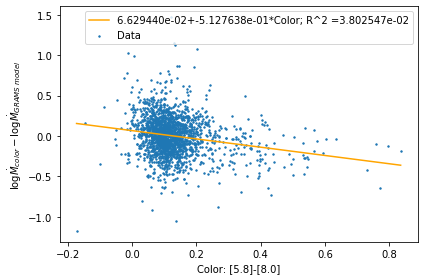

Stars removed (nAn): 6
Stars removed (nAn): 7
[ 0.00272587 -0.03336157]


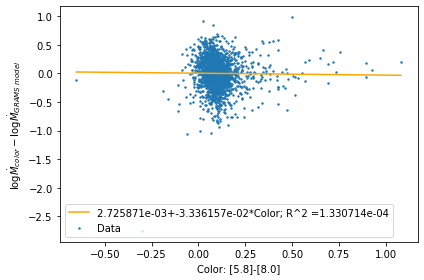

Stars removed (nAn): 22
Stars removed (nAn): 8
[-0.00619443  0.01309504]


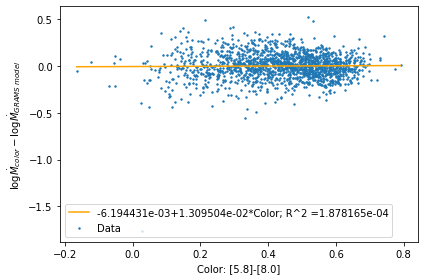

Stars removed (nAn): 26
Stars removed (nAn): 1
[ 0.0467757  -0.12464632]


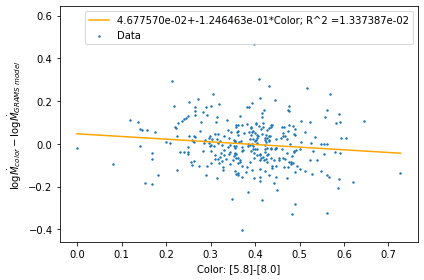

Stars removed (nAn): 2
Stars removed (nAn): 5
[ 0.03097137 -0.07023915]


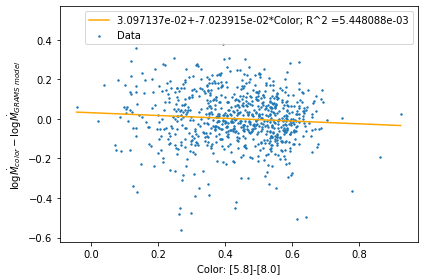

array([[1.16850000e+04, 1.16900000e+04, 1.17010000e+04, ...,
        1.48910000e+04, 1.49120000e+04, 1.50560000e+04],
       [1.00000000e+00, 1.00000000e+00, 1.00000000e+00, ...,
        1.00000000e+00, 1.00000000e+00, 1.00000000e+00],
       [3.80000000e-11, 2.50000000e-11, 1.10000000e-10, ...,
        1.30000000e-09, 1.10000000e-09, 1.90000000e-08],
       ...,
       [3.26590006e+03, 3.39319873e+03, 3.19802733e+03, ...,
        2.86146380e+03, 2.83433158e+03, 2.99400008e+03],
       [1.38000000e+01, 1.04400000e+01, 1.38200000e+01, ...,
        4.35900000e+01, 1.54270000e+02, 3.42700000e+01],
       [6.00000000e-03, 6.00000000e-03, 4.00000000e-03, ...,
        3.00000000e-01, 3.00000000e-01, 4.00000000e-01]])

In [43]:
## J-...
# J-H
plot_mdot_resids_vs_color(M0StarData, JIndex , HIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, JIndex , HIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
C0_2Color_Data_JMinH = plot_mdot_resids_vs_color(C0StarData_n, JIndex , HIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, JIndex , HIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, JIndex , HIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# J-K
M0_2Color_Data_JMinK = plot_mdot_resids_vs_color(M0StarData, JIndex , KIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
M1_2Color_Data_JMinK = plot_mdot_resids_vs_color(M1StarData, JIndex , KIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
C0_2Color_Data_JMinK = plot_mdot_resids_vs_color(C0StarData_n, JIndex , KIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, JIndex , KIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, JIndex , KIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# J-3.6
plot_mdot_resids_vs_color(M0StarData, JIndex , ThreePointSixIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, JIndex , ThreePointSixIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, JIndex , ThreePointSixIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, JIndex , ThreePointSixIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, JIndex , ThreePointSixIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# J-4.5
plot_mdot_resids_vs_color(M0StarData, JIndex , FourPointFiveIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, JIndex , FourPointFiveIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, JIndex , FourPointFiveIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, JIndex , FourPointFiveIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, JIndex , FourPointFiveIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# J-5.8
plot_mdot_resids_vs_color(M0StarData, JIndex , FivePointEightIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, JIndex , FivePointEightIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, JIndex , FivePointEightIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, JIndex , FivePointEightIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, JIndex , FivePointEightIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# J-8.0
plot_mdot_resids_vs_color(M0StarData, JIndex , EightPointZeroIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, JIndex , EightPointZeroIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, JIndex , EightPointZeroIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, JIndex , EightPointZeroIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, JIndex , EightPointZeroIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
## H-...
# H-K/K-H
plot_mdot_resids_vs_color(M0StarData, HIndex , KIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, HIndex , KIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, HIndex , KIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, HIndex , KIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, HIndex , KIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')

plot_mdot_resids_vs_color(M0StarData, KIndex , HIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
M1_2Color_Data_KMinH = plot_mdot_resids_vs_color(M1StarData, KIndex , HIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
C0_2Color_Data_KMinH = plot_mdot_resids_vs_color(C0StarData_n, KIndex , HIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, KIndex , HIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, KIndex , HIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# H-3.6
plot_mdot_resids_vs_color(M0StarData, HIndex , ThreePointSixIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, HIndex , ThreePointSixIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, HIndex , ThreePointSixIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, HIndex , ThreePointSixIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, HIndex , ThreePointSixIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# H-4.5
plot_mdot_resids_vs_color(M0StarData, HIndex , FourPointFiveIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, HIndex , FourPointFiveIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, HIndex , FourPointFiveIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, HIndex , FourPointFiveIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, HIndex , FourPointFiveIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# H-5.8
plot_mdot_resids_vs_color(M0StarData, HIndex , FivePointEightIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, HIndex , FivePointEightIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, HIndex , FivePointEightIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, HIndex , FivePointEightIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, HIndex , FivePointEightIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# H-8.0
plot_mdot_resids_vs_color(M0StarData, HIndex , EightPointZeroIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, HIndex , EightPointZeroIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, HIndex , EightPointZeroIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, HIndex , EightPointZeroIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, HIndex , EightPointZeroIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
## K-...
# K-3.6
plot_mdot_resids_vs_color(M0StarData, KIndex , ThreePointSixIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, KIndex , ThreePointSixIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, KIndex , ThreePointSixIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, KIndex , ThreePointSixIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, KIndex , ThreePointSixIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# K-4.5
plot_mdot_resids_vs_color(M0StarData, KIndex , FourPointFiveIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, KIndex , FourPointFiveIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, KIndex , FourPointFiveIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, KIndex , FourPointFiveIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, KIndex , FourPointFiveIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# K-5.8
plot_mdot_resids_vs_color(M0StarData, KIndex , FivePointEightIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, KIndex , FivePointEightIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, KIndex , FivePointEightIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, KIndex , FivePointEightIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, KIndex , FivePointEightIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
## 3.6-...
# 3.6-4.5
plot_mdot_resids_vs_color(M0StarData, ThreePointSixIndex , FourPointFiveIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, ThreePointSixIndex , FourPointFiveIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, ThreePointSixIndex , FourPointFiveIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, ThreePointSixIndex , FourPointFiveIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, ThreePointSixIndex , FourPointFiveIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# 3.6-5.8
plot_mdot_resids_vs_color(M0StarData, ThreePointSixIndex , FivePointEightIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, ThreePointSixIndex , FivePointEightIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, ThreePointSixIndex , FivePointEightIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, ThreePointSixIndex , FivePointEightIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, ThreePointSixIndex , FivePointEightIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# 3.6-8.0
plot_mdot_resids_vs_color(M0StarData, ThreePointSixIndex , EightPointZeroIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, ThreePointSixIndex , EightPointZeroIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, ThreePointSixIndex , EightPointZeroIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, ThreePointSixIndex , EightPointZeroIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, ThreePointSixIndex , EightPointZeroIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
## 4.5-...
# 4.5-5.8
plot_mdot_resids_vs_color(M0StarData, FourPointFiveIndex , FivePointEightIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, FourPointFiveIndex , FivePointEightIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, FourPointFiveIndex , FivePointEightIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, FourPointFiveIndex , FivePointEightIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, FourPointFiveIndex , FivePointEightIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
# 4.5-8.0
plot_mdot_resids_vs_color(M0StarData, FourPointFiveIndex , EightPointZeroIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, FourPointFiveIndex , EightPointZeroIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, FourPointFiveIndex , EightPointZeroIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, FourPointFiveIndex , EightPointZeroIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, FourPointFiveIndex , EightPointZeroIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')
## 5.8-...
# 5.8-8.0
plot_mdot_resids_vs_color(M0StarData, FivePointEightIndex , EightPointZeroIndex, M0_color_coeffs, comp_plus_mode = 'M0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(M1StarData, FivePointEightIndex , EightPointZeroIndex, M1_color_coeffs, comp_plus_mode = 'M1', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_n, FivePointEightIndex , EightPointZeroIndex, C0_color_coeffs, comp_plus_mode = 'C0', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C0StarData_x, FivePointEightIndex , EightPointZeroIndex, C0x_color_coeffs, comp_plus_mode = 'C0x', save_fig = True, save_folder = 'Mdot_resid_v_color')
plot_mdot_resids_vs_color(C1StarData, FivePointEightIndex , EightPointZeroIndex, C1_color_coeffs, comp_plus_mode = 'C1', save_fig = True, save_folder = 'Mdot_resid_v_color')

The fits for residual vs H-K and J-K have the most distinctive trends, so we'll use that data to provide a second variable to fit with.

In [44]:
def fit_to_hyperbolic_pls_lin (xdata, ydata, save_fig = 0, plot_title = '', x_label_0='',x_label_1 = '',y_label='',y_label_sanitized='', save_folder = '', z_color_by_data=[],manual_data_bin_tau=0, z_data_to_sort=[],initial_guess=[]):
    # logMdot = a/(K - [8.0] + b) - α col + (c - β) => logMdot = P0/(C0 + P1) - P2*C1 + P3
    if len (initial_guess) >0:
        fit_parameters, fit_covariances = sp.optimize.curve_fit(hyperbolic_func_pls_lin, xdata, ydata,p0=initial_guess)
    else:
        fit_parameters, fit_covariances = sp.optimize.curve_fit(hyperbolic_func_pls_lin, xdata, ydata)
    fit_parameters_1_color, fit_covariances_1_color = sp.optimize.curve_fit(hyperbolic_func, xdata[0], ydata)
    fit_left_C0 = np.min(xdata[0])
    fit_left_C1 = np.min(xdata[1])
    fit_right_C0 = np.max(xdata[0])
    fit_right_C1 = np.max(xdata[1])
    #print(fit_left,fit_right)
    fit_data_0 = [fit_left_C0]
    new_elem_0 = fit_left_C0 + np.abs((fit_right_C0-fit_left_C0))/100
    while len(fit_data_0)<100:
        fit_data_0.append(new_elem_0)
        new_elem_0 = new_elem_0 + np.abs((fit_right_C0-fit_left_C0))/100
    fit_data_1 = [fit_left_C1]
    new_elem_1 = fit_left_C1 + np.abs((fit_right_C1-fit_left_C1))/100
    while len(fit_data_1)<100:
        fit_data_1.append(new_elem_1)
        new_elem_1 = new_elem_1 + np.abs((fit_right_C1-fit_left_C1))/100
    #print(fit_data)
    fit_data = [fit_data_0,fit_data_1]
    standard_dev_of_coeff = np.sqrt(np.diag(fit_covariances))
    fit_curve = hyperbolic_func_pls_lin (fit_data, fit_parameters[0], fit_parameters[1], fit_parameters[2], fit_parameters[3])
    fit_curve_up = hyperbolic_func_pls_lin (fit_data, fit_parameters[0]-standard_dev_of_coeff[0], fit_parameters[1]+standard_dev_of_coeff[1], fit_parameters[2]-standard_dev_of_coeff[2],  fit_parameters[3]-standard_dev_of_coeff[3])
    fit_curve_low = hyperbolic_func_pls_lin (fit_data, fit_parameters[0]+standard_dev_of_coeff[0], fit_parameters[1]-standard_dev_of_coeff[1], fit_parameters[2]+standard_dev_of_coeff[2],  fit_parameters[3]+standard_dev_of_coeff[3])
    
    fit_y = hyperbolic_func_pls_lin (xdata, fit_parameters[0], fit_parameters[1], fit_parameters[2], fit_parameters[3])
    fit_curve = fit_curve + fit_parameters[2]*np.asarray(fit_data[1])
    fit_curve_up = fit_curve_up + fit_parameters[2]*np.asarray(fit_data[1])
    fit_curve_low = fit_curve_low + fit_parameters[2]*np.asarray(fit_data[1])
    #print((fit_parameters_1_color[2]-fit_parameters[3]))
    # Plot 1: logMdot vs Main Color
    fig, ax = plt.subplots()
    if len(z_color_by_data)>0: 
        plot.scatter(xdata[0], ydata-xdata[1], label='Data',s=2,c=z_color_by_data,cmap='Dark2')
    elif manual_data_bin_tau >0:
        zdata = np.asarray(z_data_to_sort)
        data_to_sort = np.transpose(np.asarray([xdata[0], ydata-xdata[1]])) # Stack our data so we can associate data points with each other
        a = data_to_sort
        ind=np.argsort(a[:,-1])
        sorted_data=np.transpose(np.asarray(a[ind]))
            #print('sorted_data:',sorted_data)
            #print(len(data_to_sort))
            #print('sorted_data:',sorted_data)
            #print(data_to_sort)
        bin_size = len(data_to_sort)//manual_data_bin_tau
        bin_bottom = 0
        bin_top = bin_size
        print('len(data_to_sort):',len(data_to_sort))
        i=0
        while i < manual_data_bin_tau:
            if i ==0: # When on first bin
                working_x=sorted_data[0][:bin_top]
                working_y=sorted_data[1][:bin_top]
                data_label = 'tau<'+str( np.max(sorted_data[2][:bin_size]))[0:7]
                plot.scatter(working_x, working_y, label=data_label,s=2)
            elif i == manual_data_bin_tau-1: # If we are on the last bin
                working_x=sorted_data[0][bin_bottom:]
                working_y=sorted_data[1][bin_bottom:]
                data_label = 'tau>'+str(np.min(sorted_data[2][bin_bottom:]))[0:7]
                plot.scatter(working_x, working_y, label=data_label,s=2)
            else: # We are on some intermediate bin
                working_x=sorted_data[0][bin_bottom:bin_top]
                working_y=sorted_data[1][bin_bottom:bin_top]
                #print('tau range:',sorted_data[2][bin_bottom:bin_top])
                data_label = str(np.min(sorted_data[2][bin_bottom:bin_top]))[0:7] +'<tau<'+str(np.max(sorted_data[2][bin_bottom:bin_top]))[0:7]
                plot.scatter(working_x, working_y, label=data_label,s=2)
            bin_bottom = bin_bottom+bin_size
            print('bin_bottom:',bin_bottom)
            bin_top = bin_top + bin_size
            print('bin_top:',bin_top)
            i = i + 1
    else:
        plot.scatter(xdata[0], ydata+fit_parameters[2]*xdata[1], label='Data',s=2)
    plot.plot(fit_data[0],fit_curve,color='orange')
    #plot.plot(fit_data[0],fit_curve_up,color='orange',linestyle='--')
    #plot.plot(fit_data[0],fit_curve_low,color='orange',linestyle='--')
    #plot.title(plot_title)
    ax.text(0.03, .97,plot_title,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    #plot.legend()
    plot.ylim((np.min(ydata+fit_parameters[2]*xdata[1])-0.1), (np.max(ydata+fit_parameters[2]*xdata[1])+0.1))
    plot.xlabel(x_label_0)
    plot.ylabel(y_label+'+'+str(fit_parameters[2])[1:5]+'('+x_label_1+')')
    plot.tight_layout()
    if save_fig !=0:
        if y_label_sanitized != '':
            plot.savefig(save_folder+'/'+plot_title+y_label_sanitized+'_vs_'+x_label_0+'.png')
            plot.savefig(save_folder+'/'+plot_title+y_label_sanitized+'_vs_'+x_label_0+'.pdf')
        else:
            plot.savefig(save_folder+'/'+plot_title+y_label+'_vs_'+x_label_0+'.png')
            plot.savefig(save_folder+'/'+plot_title+y_label+'_vs_'+x_label_0+'.pdf')
        plot.show()
        plot.close()
    else:
        plot.show()
        plot.close()
        
    # Plot 2: logMdot_GRAMS vs logMdot_color
    fig, ax = plt.subplots()
    plot.scatter(fit_y,ydata,label='Data',s=2)
    #plot.title(plot_title)
    ax.text(0.03, .97,plot_title,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    #print(np.min(ydata),np.min(fit_y))
    bottom_left = np.min([np.min(ydata),np.min(fit_y)])-0.1
    top_right = np.max([np.max(ydata),np.max(fit_y)])+0.1
    fit_parameters_2, r2_parameters_2 = chi_sq_fit_2d (fit_y,ydata)
    fit_line = np.asarray([fit_parameters_2[1]*bottom_left + fit_parameters_2[0], fit_parameters_2[1]*top_right + fit_parameters_2[0]])
    OneToOneData=[bottom_left,top_right]
    plot.plot(OneToOneData, fit_line,marker='.',label='fit: int.=%5.3f, slope.=%5.3f' % tuple(fit_parameters_2),color='orange')
    OneToOneData=[bottom_left,top_right]
    plot.plot(OneToOneData, OneToOneData,color='k',marker='.')
    #print(bottom_left,top_right)
    plot.xlim(bottom_left, top_right)
    plot.ylim(bottom_left, top_right)
    plot.xlabel(r'$\log \dot{M}_{2color}$')
    plot.ylabel(r'$\log \dot{M}_{GRAMS}$')
    plot.tight_layout()
    #plot.legend()
    if save_fig !=0:
        plot.savefig(save_folder+'/'+plot_title+'logMdot_GRAMS'+'_vs_'+'logMdot_2color'+'.png')
        plot.savefig(save_folder+'/'+plot_title+'logMdot_GRAMS'+'_vs_'+'logMdot_2color'+'.pdf')
        plot.show()
        plot.close()
    else:
        plot.show()
        plot.close()
        
        
    # Plot 3: Histogram of Residuals. We want to know which has the smallest range for the C0 Stars.
    fig, ax = plt.subplots()
    hist_data = fit_y-ydata # New Residual, after applying 2nd color correction
    n, bins, patches = plot.hist(hist_data,bins=10) # Histogram of residual logMdot_color-logMdot_GRAMS
    print('n:',n)
    print('np.max(n):',np.max(n))
    standard_dev = hist_data.std()
    print('Standard Dev.', standard_dev)
    mean = hist_data.mean()
    print('mean:',mean)
    hist_left=np.min(hist_data)
    hist_right=np.max(hist_data)
    
    normal_sample = [hist_left]
    new_elem_norm_samp = hist_left + np.abs((hist_right-hist_left))/100
    while len(normal_sample)<100:
        normal_sample.append(new_elem_norm_samp)
        new_elem_norm_samp = new_elem_norm_samp + np.abs((hist_right-hist_left))/100
    #print(normal_sample)
    # f(x) = 1/(sigma*sqrt(2*pi))*exp(-1/2*((x-mean)/sigma)**2)
    normal_func = (1/(standard_dev*np.sqrt(2*np.pi)) )*np.exp(-0.5*((normal_sample-mean)/standard_dev)**2)
    normal_func = np.max(n)/np.max(normal_func)*normal_func
    #print(normal_func)
    plot.plot(normal_sample,normal_func,ls='--',marker='',label='normal: std=%5.3f, mean=%5.3f' % tuple([standard_dev,mean]))
    plot.xlabel(r'$\log \dot{M}_{2color}- \log \dot{M}_{GRAMS}$')
    plot.ylabel('N')
    #plot.title(plot_title)
    ax.text(0.03, .97,plot_title,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    #plot.legend()
    plot.tight_layout()
    if save_fig !=0:
        plot.savefig(save_folder+'/'+plot_title+'Hist_logMdot_2color-logMdot_GRAMS'+'.png')
        plot.savefig(save_folder+'/'+plot_title+'Hist_logMdot_2color-logMdot_GRAMS'+'.pdf')
        plot.show()
        plot.close()
    else:
        plot.show()
        plot.close()
        
    # Plot 4: Residual vs Color 1
    fig, ax = plt.subplots()
    plot.scatter(xdata[0],hist_data,s=2)
    #plot.title(plot_title)
    ax.text(0.03, .97,plot_title,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot.ylabel(r'$\log \dot{M}_{2color}- \log \dot{M}_{GRAMS}$')
    plot.xlabel(x_label_0)
    residual_parameters_plot_4, residual_r2_plot_4 = chi_sq_fit_2d (xdata[0],hist_data)
    #print('np.nanmin(xdata[0]):',np.nanmin(xdata[0]))
    #print('np.nanmax(xdata[0]):',np.nanmax(xdata[0]))
    lr_bounds = np.asarray([np.nanmin(xdata[0]),np.nanmax(xdata[0])])
    tb_values = residual_parameters_plot_4[1]*lr_bounds+residual_parameters_plot_4[0]
    #print('tb_values:',tb_values)
    plot.plot(lr_bounds,tb_values,marker='',label='fit: int.=%5.3f, slope.=%5.3f' % tuple(residual_parameters_plot_4),color='orange')
    #plot.legend()
    #plot.plot(lr_bounds,tb_values,marker='')
    plot.tight_layout()
    if save_fig !=0:
        plot.savefig(save_folder+'/'+plot_title+'Residual_vs_Color1'+'.png')
        plot.savefig(save_folder+'/'+plot_title+'Residual_vs_Color1'+'.pdf')
        plot.show()
        plot.close()
    else:
        plot.show()
        plot.close()
    
    
    # Plot 5: Residual vs Color 2
    fig, ax = plt.subplots()
    plot.scatter(xdata[1],hist_data,s=2)
    #plot.title(plot_title)
    ax.text(0.03, .97,plot_title,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot.ylabel(r'$\log \dot{M}_{2color}- \log \dot{M}_{GRAMS}$')
    plot.xlabel(x_label_1)
    residual_parameters_plot_5, residual_r2_plot_5 = chi_sq_fit_2d (xdata[1],hist_data)
    lr_bounds = np.asarray([np.nanmin(xdata[1]),np.nanmax(xdata[1])])
    tb_values = residual_parameters_plot_5[1]*lr_bounds+residual_parameters_plot_5[0]
    plot.plot(lr_bounds,tb_values,marker='',label='fit: int.=%5.3f, slope.=%5.3f' % tuple(residual_parameters_plot_5),color='orange')
    #plot.legend()
    plot.tight_layout()
    if save_fig !=0:
        plot.savefig(save_folder+'/'+plot_title+'Residual_vs_Color2'+'.png')
        plot.savefig(save_folder+'/'+plot_title+'Residual_vs_Color2'+'.pdf')
        plot.show()
        plot.close()
    else:
        plot.show()
        plot.close()
    
    return [fit_parameters[0], fit_parameters[1], fit_parameters[2], fit_parameters[3]], fit_covariances
    

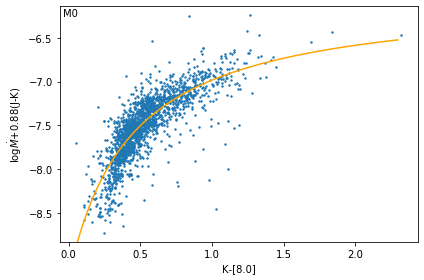

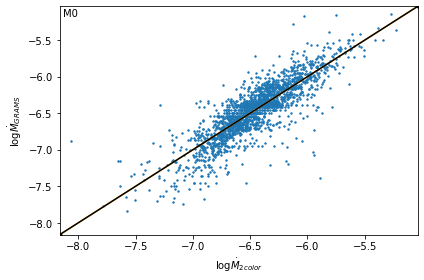

n: [1.00e+00 4.00e+00 4.30e+01 4.83e+02 1.08e+03 2.58e+02 5.50e+01 7.00e+00
 4.00e+00 1.00e+00]
np.max(n): 1080.0
Standard Dev. 0.20711156344396722
mean: 7.138262385318903e-08


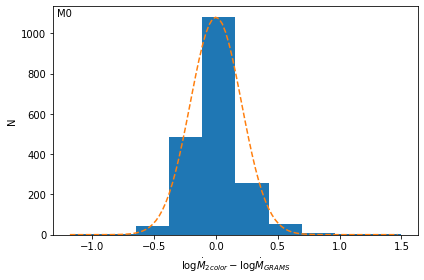

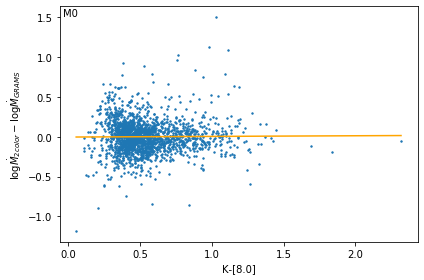

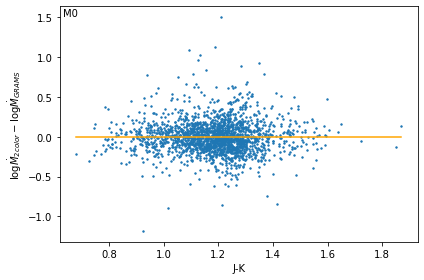

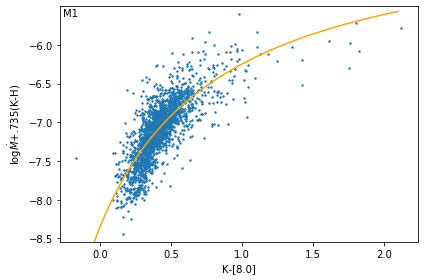

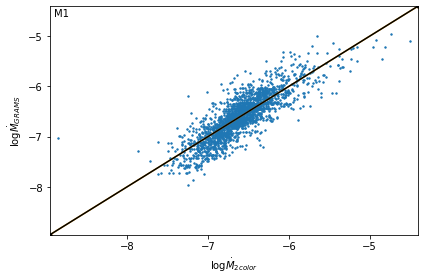

n: [1.000e+00 0.000e+00 1.000e+00 1.100e+01 5.200e+01 2.940e+02 1.041e+03
 5.960e+02 1.430e+02 1.400e+01]
np.max(n): 1041.0
Standard Dev. 0.23864348786214246
mean: 2.453279306797183e-07


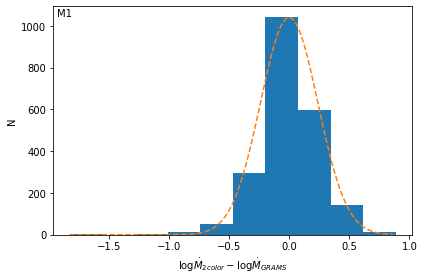

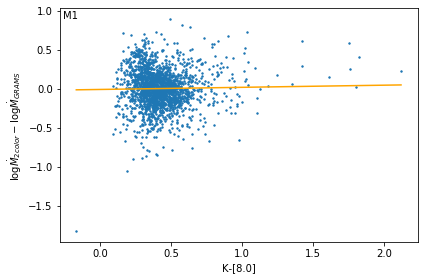

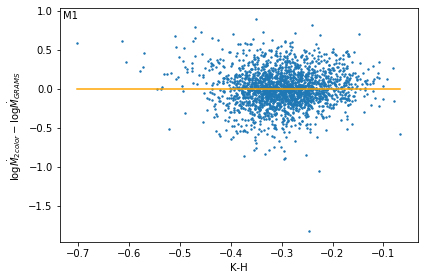

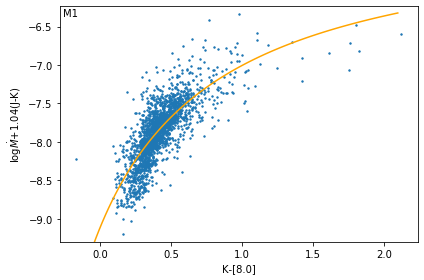

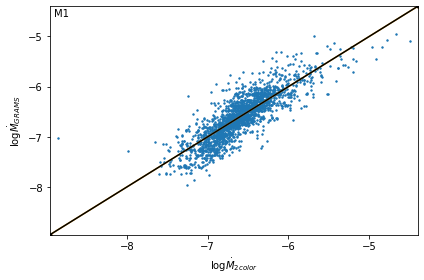

n: [1.000e+00 0.000e+00 1.000e+00 1.200e+01 4.800e+01 2.750e+02 1.021e+03
 6.180e+02 1.600e+02 1.600e+01]
np.max(n): 1021.0
Standard Dev. 0.2402824204617528
mean: 5.2116847904620564e-08


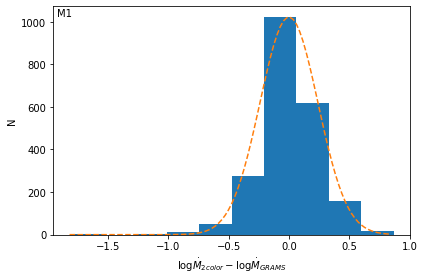

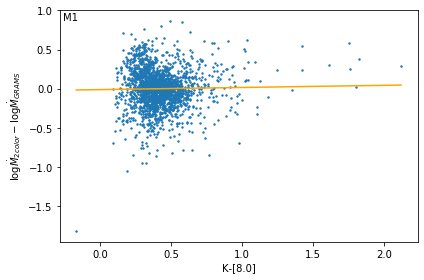

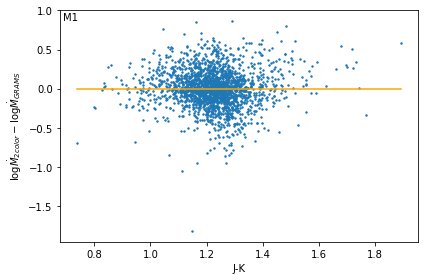

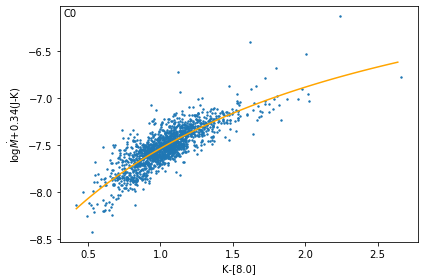

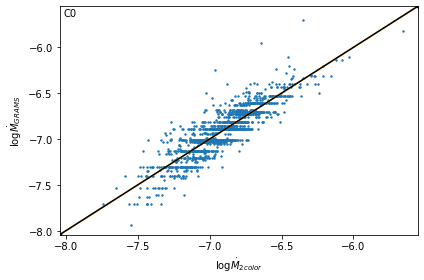

n: [  3.   1.   5.  41. 121. 469. 654. 284.  44.   6.]
np.max(n): 654.0
Standard Dev. 0.12048544758773357
mean: 1.7973229522210094e-09


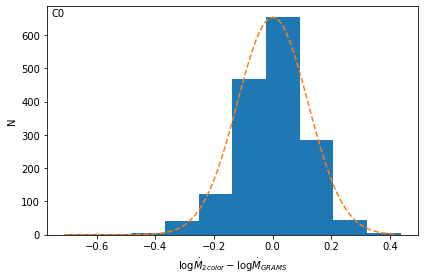

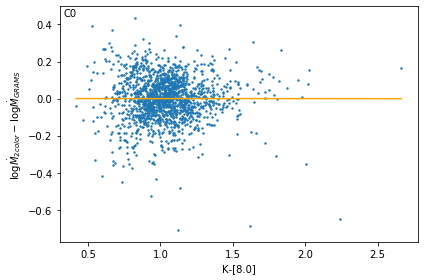

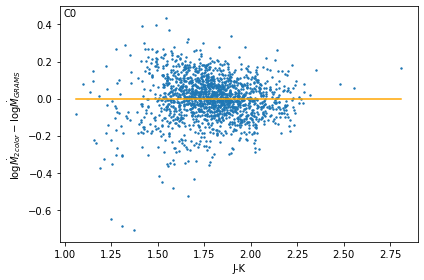

In [45]:
# Data: M0_2Color_Data_JMinK, M1_2Color_Data_KMinH, C0_2Color_Data_JMinH, C0_2Color_Data_JMinK, C0_2Color_Data_KMinH

Directory = 'Single_Parameter_Fits/2color_Mdot'
save_value = 1
# M0
M0_K_Min_Eight = calculate_color(M0_2Color_Data_JMinK[KIndex],M0_2Color_Data_JMinK[EightPointZeroIndex])
M0_J_Min_K = calculate_color(M0_2Color_Data_JMinK[JIndex],M0_2Color_Data_JMinK[KIndex])
M0_Coeff_2color, M0_Covar_2color = fit_to_hyperbolic_pls_lin(np.asarray([M0_K_Min_Eight,M0_J_Min_K]),np.log10(M0_2Color_Data_JMinK[MdotIndex]), plot_title='M0', x_label_0='K-[8.0]', x_label_1='J-K', y_label = r'$\log \dot{M}$', y_label_sanitized = 'logMdot', z_data_to_sort=M0_2Color_Data_JMinK[tauIndex], save_fig = save_value,save_folder=Directory)
# M1
M1_K_Min_Eight = calculate_color(M1_2Color_Data_KMinH[KIndex],M1_2Color_Data_KMinH[EightPointZeroIndex])
M1_K_Min_H = calculate_color(M1_2Color_Data_KMinH[KIndex],M1_2Color_Data_KMinH[HIndex])
M1_J_Min_K = calculate_color(M1_2Color_Data_JMinK[JIndex],M1_2Color_Data_JMinK[KIndex])
M1_Coeff_2color,M1_Covar_2color = fit_to_hyperbolic_pls_lin(np.asarray([M1_K_Min_Eight,M1_K_Min_H]),np.log10(M1_2Color_Data_KMinH[MdotIndex]), plot_title='M1', x_label_0='K-[8.0]', x_label_1='K-H', initial_guess = M0_Coeff_2color,y_label = r'$\log \dot{M}$', y_label_sanitized = 'logMdot', z_data_to_sort=M1_2Color_Data_KMinH[tauIndex], save_fig = save_value,save_folder=Directory)
M1_K_Min_Eight_for_J_Min_K = calculate_color(M1_2Color_Data_JMinK[KIndex],M1_2Color_Data_JMinK[EightPointZeroIndex])
M1_Coeff_2color_J_Min_K,M1_Covar_2color_J_Min_K = fit_to_hyperbolic_pls_lin(np.asarray([M1_K_Min_Eight_for_J_Min_K,M1_J_Min_K]),np.log10(M1_2Color_Data_JMinK[MdotIndex]), plot_title='M1', x_label_0='K-[8.0]', x_label_1='J-K', y_label = r'$\log \dot{M}$', y_label_sanitized = 'logMdot', z_data_to_sort=M1_2Color_Data_JMinK[tauIndex], save_fig = save_value,save_folder=Directory,initial_guess=[-1,1,1,-1])
# C0
#C0_K_Min_Eight_for_J_Min_H = calculate_color(C0_2Color_Data_JMinH[KIndex],C0_2Color_Data_JMinH[EightPointZeroIndex])
#C0_J_Min_H = calculate_color(C0_2Color_Data_JMinH[JIndex],C0_2Color_Data_JMinH[HIndex])
#fit_to_hyperbolic_pls_lin(np.asarray([C0_K_Min_Eight_for_J_Min_H,C0_J_Min_H]),np.log10(C0_2Color_Data_JMinH[MdotIndex]), plot_title='C0', x_label_0='K-[8.0]', x_label_1='J-H', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=C0_2Color_Data_JMinH[tauIndex], save_fig = save_value,save_folder=Directory)

C0_K_Min_Eight_for_J_Min_K = calculate_color(C0_2Color_Data_JMinK[KIndex],C0_2Color_Data_JMinK[EightPointZeroIndex])
C0_J_Min_K = calculate_color(C0_2Color_Data_JMinK[JIndex],C0_2Color_Data_JMinK[KIndex])
C0_Coeff_2color,C0_Covar_2color = fit_to_hyperbolic_pls_lin(np.asarray([C0_K_Min_Eight_for_J_Min_K,C0_J_Min_K]),np.log10(C0_2Color_Data_JMinK[MdotIndex]), plot_title='C0', x_label_0='K-[8.0]', x_label_1='J-K', y_label = r'$\log \dot{M}$', y_label_sanitized = 'logMdot', z_data_to_sort=C0_2Color_Data_JMinK[tauIndex], initial_guess = M0_Coeff_2color, save_fig = save_value,save_folder=Directory)

#C0_K_Min_Eight_for_K_Min_H = calculate_color(C0_2Color_Data_KMinH[KIndex],C0_2Color_Data_KMinH[EightPointZeroIndex])
#C0_K_Min_H = calculate_color(C0_2Color_Data_KMinH[KIndex],C0_2Color_Data_KMinH[HIndex])
#fit_to_hyperbolic_pls_lin(np.asarray([C0_K_Min_Eight_for_K_Min_H,C0_K_Min_H]),np.log10(C0_2Color_Data_KMinH[MdotIndex]), plot_title='C0', x_label_0='K-[8.0]', x_label_1='K-H', y_label = 'logMdot',manual_data_bin_tau=4, z_data_to_sort=C0_2Color_Data_KMinH[tauIndex], save_fig = save_value,save_folder=Directory)


In [46]:
# Data: M0_2Color_Data_JMinK, M1_2Color_Data_KMinH, C0_2Color_Data_JMinH, C0_2Color_Data_JMinK, C0_2Color_Data_KMinH

print(M0_Coeff_2color)
print(np.sqrt(np.diag(M0_Covar_2color)))
print(M1_Coeff_2color_J_Min_K)
print(np.sqrt(np.diag(M1_Covar_2color_J_Min_K)))
print(M1_Coeff_2color)
print(np.sqrt(np.diag(M1_Covar_2color)))
print(C0_Coeff_2color)
print(np.sqrt(np.diag(C0_Covar_2color)))

[-1.3835145209493838, 0.4283506004610463, -0.8847799308128578, -6.013982883911922]
[0.14418885 0.04757664 0.033098   0.08356092]
[-3.470504720942111, 0.8749398903841783, -1.0444388646865919, -5.155025380214687]
[0.4850136  0.09000449 0.05186343 0.2123038 ]
[-3.429427688444469, 0.869379941224002, 1.7356834893133544, -4.412527876079017]
[0.4747508  0.0887739  0.08157312 0.19307727]
[-7.24248049263793, 1.8744197060675025, -0.3411133006787844, -5.016020047035441]
[1.88617074 0.38110591 0.01715765 0.32174414]


In [47]:
np.shape(M0_2Color_Data_JMinK)

(28, 1936)

In [48]:
# Calculates the mass-loss rate from a hyperbolic fit to color
#                  a
#   log Mdot = _________ + c
#              color + b
def calc_mdot_from_color_1 (color_data, coeff_data): # Color_data should be a numpy array. Using the function written, turn it into Mdot data for a given star type
    color_log_mdot = coeff_data[0]/(color_data+coeff_data[1]) + coeff_data[2]
    return color_log_mdot
def calc_mdot_from_color (color_data, coeff_data): # Color_data should be a numpy array. Using the function written, turn it into Mdot data for a given star type
    color_log_mdot = coeff_data[0]/(color_data[0]+coeff_data[1]) - coeff_data[2]*color_data[1] + coeff_data[3]
    return color_log_mdot

In [49]:
def plot_x_y_data (xdata,ydata):
    plot.scatter(xdata,ydata,s=2)
    plot.show()
    plot.close()

In [50]:
def calc_PE_scale (stellar_data):
    Mass = stellar_data[MIndex]
    Radius = stellar_data[RIndex]
    potential_energy_scale = np.log10(Mass/Radius)
    return potential_energy_scale

def calc_g_scale (stellar_data):
    Mass = stellar_data[MIndex]
    Radius = stellar_data[RIndex]
    g_scale = np.log10(Mass/Radius**2)
    return g_scale

def calc_lum_pressure_scale (stellar_data):
    Luminosity = stellar_data[LIndex]
    Radius = stellar_data[RIndex]
    L_Pressure_scale = np.log10(Luminosity/Radius**2)
    return L_Pressure_scale

def calc_core_lum_param (stellar_data):
    Luminosity = stellar_data[LIndex]
    Mass = stellar_data[MIndex]
    core_lum_param = np.log10(Luminosity/Mass)
    return core_lum_param

In [51]:
def plot_logmdot_vs_parameter (mdot, parameter, title='', parameter_label='',save_fig = 0, save_folder = '',testing = 0):
    fig, ax = plt.subplots()
    plot.scatter(parameter,mdot,s=2,label='Data')
    chisqparams = chi_sq_fit_2d (parameter, mdot)
    fit_parameters = chisqparams[0]
    fit_x = np.asarray([np.nanmin(parameter), np.nanmax(parameter)])
    if testing != 0:
        print('parameter:',parameter)
        print('np.min(parameter):',np.nanmin(parameter))
        print('np.max(parameter):',np.nanmax(parameter))
        print('fit_x:',fit_x)
    fit_y = fit_parameters[0] + fit_parameters[1]*fit_x
    if testing != 0:
        print('fit_y:',fit_x)
    fit_label = "{:6e}".format(fit_parameters[0]) +'+'+ "{:6e}".format(fit_parameters[1])+'*('+parameter_label+'); R^2 ='+ "{:6e}".format(chisqparams[1])
    plot.plot(fit_x,fit_y,color='orange', label = fit_label)
    #plot.title(title)
    ax.text(0.03, .97,title,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot.xlabel(parameter_label)
    plot.ylabel('logMdot_obsv')
    plot.legend(loc=8)
    if save_fig != 0:
            plot_name = save_folder + '/' + 'logMdot_versus_' + parameter_label + '/' + title
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()

In [52]:
def plot_residual_vs_parameter (mdot_resid, parameter, title='', parameter_label='',save_fig = 0, save_folder = ''):
    fig, ax = plt.subplots()
    plot.scatter(parameter,mdot_resid,s=2, label = 'Data')
    chisqparams = chi_sq_fit_2d (parameter, mdot_resid)
    fit_parameters = chisqparams[0]
    fit_x = np.asarray([np.nanmin(parameter), np.nanmax(parameter)])
    fit_y = fit_parameters[0] + fit_parameters[1]*fit_x
    fit_label = "{:6e}".format(fit_parameters[0]) +'+'+ "{:6e}".format(fit_parameters[1])+'*('+parameter_label+'); R^2 ='+ "{:6e}".format(chisqparams[1])
    plot.plot(fit_x,fit_y,color='orange', label = fit_label)
    #plot.title(title)
    ax.text(0.03, .97,title,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot.xlabel(parameter_label)
    plot.ylabel('logMdot_calc-logMdot_obsv')
    plot.legend(loc=8)
    if save_fig != 0:
            plot_name = save_folder + '/' + 'Residuals/'+ 'residual_versus_'+ parameter_label + '/' + title
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()
    return fit_parameters

In [53]:
def plot_logmdot_vs_logmdot (mdot, calc_mdot, title='',save_fig = 0, save_folder = ''):
    fig, ax = plt.subplots()
    plot.scatter(mdot,calc_mdot,s=2, label = 'Data')
    chisqparams = chi_sq_fit_2d (mdot, calc_mdot)
    fit_parameters = chisqparams[0]
    line_coords = np.asarray([np.min([np.nanmin(mdot),np.nanmin(calc_mdot)]),np.nanmax([np.max(mdot),np.nanmax(calc_mdot)])])
    fit_x = line_coords
    fit_y = fit_parameters[0] + fit_parameters[1]*fit_x
    fit_label = "{:6e}".format(fit_parameters[0]) +'+'+ "{:6e}".format(fit_parameters[1])+'*'+'logMdot_obsv'+'; R^2 ='+ "{:6e}".format(chisqparams[1])
    plot.plot(line_coords,line_coords,color='black', label = '1:1 Line')
    plot.plot(fit_x,fit_y,color='orange', label = fit_label)
    #plot.title(title)
    ax.text(0.03, .97,title,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot.xlabel('logMdot_obsv')
    plot.ylabel('logMdot_calc')
    plot.legend(loc=8)
    plot.tight_layout()
    if save_fig != 0:
            plot_name = save_folder + '/' + 'logMdot_calc_versus_logMdot_obsv' + '/' + title
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()

In [54]:
def full_parameter_analysis (stellar_data_x, stellar_data_mdot, full_stellar_data, stellar_data_xlabel='', plot_label = '', save_folder = '', save_fig = 0):
    #fig, ax = plt.subplots()
    # Data Analysis: Do a chi^2 fit of our chosen parameter vs Mdot for our star, and find the residuals of that fit
    chisqfit_returns = chi_sq_fit_2d (stellar_data_x,stellar_data_mdot)
    Betas = chisqfit_returns[0]
    RSquared = chisqfit_returns[1]
    print('\n Fit: logMdot=', Betas[1],'*x+',Betas[0])
    logMdot_calc = Betas[1]*stellar_data_x+Betas[0]
    logMdot_residual = logMdot_calc- stellar_data_mdot
    # First Plot: Chosen Parameter vs Mdot, so we can see what the chi^2 fit looks like
    plot_logmdot_vs_parameter (stellar_data_mdot, stellar_data_x, title=plot_label, parameter_label=stellar_data_xlabel,save_folder = save_folder,save_fig = save_fig)
    #plot.scatter(stellar_data_x,stellar_data_mdot,s=2)
    #fit_x = np.asarray([np.min(stellar_data_x), np.max(stellar_data_x)])
    #fit_y = Betas[0] + Betas[1]*fit_x
    #plot.plot(fit_x,fit_y,color='orange')
    #plot.xlabel(stellar_data_xlabel)
    #plot.ylabel('logMdot_obsv')
    #plot.title(plot_label)
    #ax.text(0.03, .97,plot_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    #plot.show()
    #plot.close()
    # Data Analysis: For the input, calculate some proxies for stellar parameters (so they don't have to be fed to the function indvidually)
    logPE = calc_PE_scale(full_stellar_data)
    logg = calc_g_scale(full_stellar_data)
    logLP = calc_lum_pressure_scale(full_stellar_data)
    logCL = calc_core_lum_param(full_stellar_data)
    # More plots
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[PIndex]),title=plot_label,parameter_label='logP',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[LIndex]),title=plot_label,parameter_label='logL',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[MIndex]),title=plot_label,parameter_label='logM',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logPE,title=plot_label,parameter_label='log(M/R)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logg,title=plot_label,parameter_label='log(M/R^2)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logLP,title=plot_label,parameter_label='log(L/R^2)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logCL,title=plot_label,parameter_label='log(L/M)',save_folder = save_folder,save_fig = save_fig)
    
    color_J_minus_ThreePointSix = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[ThreePointSixIndex])
    color_ThreePointSix_minus_EightPointZero = np.asarray(full_stellar_data[ThreePointSixIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    color_J_minus_K = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[KIndex])
    color_K_minus_EightPointZero = np.asarray(full_stellar_data[KIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    plot_logmdot_vs_parameter (stellar_data_mdot,color_ThreePointSix_minus_EightPointZero , title=plot_label, parameter_label='[3.6]-[8.0]')
    plot_logmdot_vs_parameter (stellar_data_mdot, color_K_minus_EightPointZero, title=plot_label, parameter_label='K-[8.0]')
    plot_residual_vs_parameter(logMdot_residual,color_ThreePointSix_minus_EightPointZero,title=plot_label,parameter_label='[3.6]-[8.0]',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,color_K_minus_EightPointZero,title=plot_label,parameter_label='K-[8.0]',save_folder = save_folder,save_fig = save_fig)
    
    plot_logmdot_vs_logmdot(stellar_data_mdot, logMdot_calc, title=plot_label,save_folder = save_folder,save_fig = save_fig)

In [55]:
M0_color_Mdot = calc_mdot_from_color ([M0_K_Min_Eight,M0_J_Min_K], M0_Coeff_2color)
M1_color_Mdot = calc_mdot_from_color ([M1_K_Min_Eight_for_J_Min_K,M1_J_Min_K], M1_Coeff_2color_J_Min_K)
C0_color_Mdot = calc_mdot_from_color ([C0_K_Min_Eight_for_J_Min_K,C0_J_Min_K], C0_Coeff_2color)

C0x_color_Mdot = calc_mdot_from_color_1 (C0_x_color_K_minus_80, C0x_color_coeffs)
C1_color_Mdot = calc_mdot_from_color_1 (C1_color_K_minus_80, C1_color_coeffs)

M0:

 Fit: logMdot= 0.96727967538885 *x+ -8.585276929408504


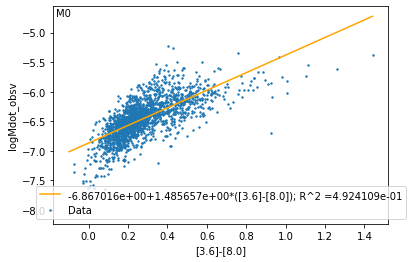

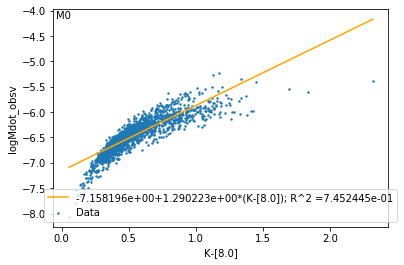


M1:

 Fit: logMdot= 1.2533685769496015 *x+ -9.024814713044924


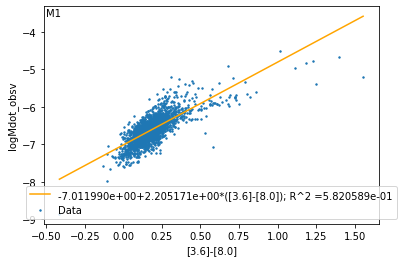

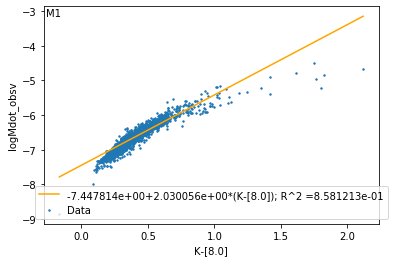


C0

 Fit: logMdot= 0.8384535604922904 *x+ -9.011417348271925


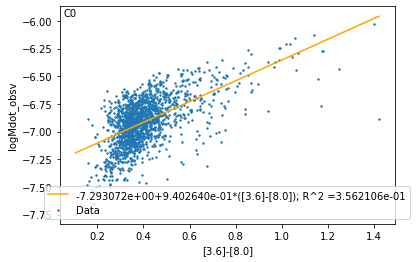

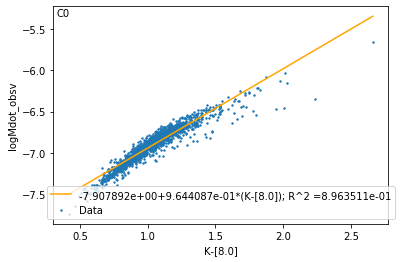

In [56]:
Directory = 'Single_Parameter_Fits/2color_Mdot/logP'
print('M0:')
full_parameter_analysis (np.log10(M0_2Color_Data_JMinK[PIndex]), M0_color_Mdot, M0_2Color_Data_JMinK, stellar_data_xlabel='log(P)', plot_label='M0', save_fig = 1, save_folder=Directory)
print('\nM1:')
full_parameter_analysis (np.log10(M1_2Color_Data_JMinK[PIndex]), M1_color_Mdot, M1_2Color_Data_JMinK, stellar_data_xlabel='log(P)', plot_label='M1', save_fig = 1, save_folder=Directory)
print('\nC0')
full_parameter_analysis (np.log10(C0_2Color_Data_JMinK[PIndex]), C0_color_Mdot, C0_2Color_Data_JMinK, stellar_data_xlabel='log(P)', plot_label='C0', save_fig = 1, save_folder=Directory)


M0:

 Fit: logMdot= 0.0896060013702423 *x+ -6.77845901873796


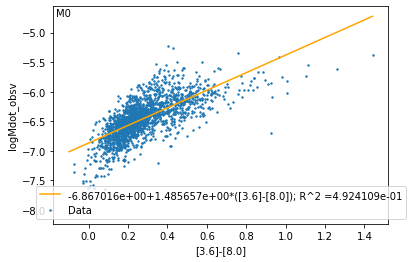

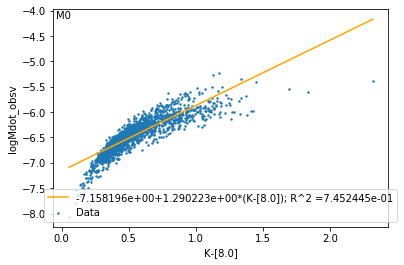


M1:

 Fit: logMdot= 0.5993597909729043 *x+ -8.73688042819425


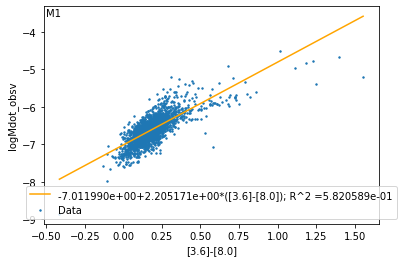

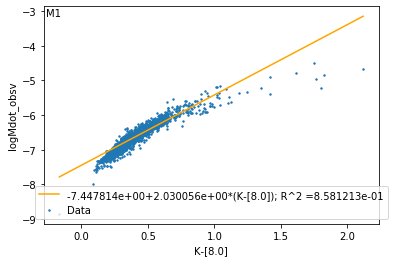


C0

 Fit: logMdot= 0.10822511782055311 *x+ -7.322266830298897


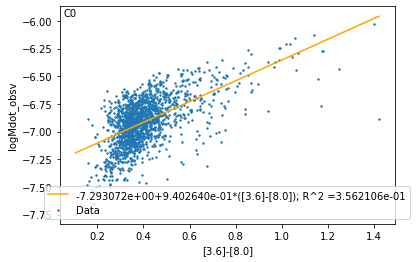

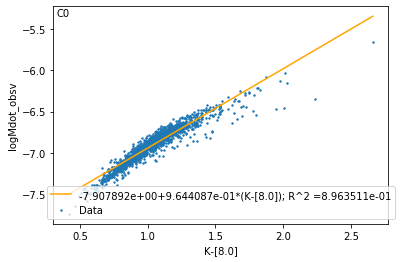

In [57]:
Directory = 'Single_Parameter_Fits/2color_Mdot/logL'
print('M0:')
full_parameter_analysis (np.log10(M0_2Color_Data_JMinK[LIndex]), M0_color_Mdot, M0_2Color_Data_JMinK, stellar_data_xlabel='log(L)', plot_label='M0', save_fig = 1, save_folder=Directory)
print('\nM1:')
full_parameter_analysis (np.log10(M1_2Color_Data_JMinK[LIndex]), M1_color_Mdot, M1_2Color_Data_JMinK, stellar_data_xlabel='log(L)', plot_label='M1', save_fig = 1, save_folder=Directory)
print('\nC0')
full_parameter_analysis (np.log10(C0_2Color_Data_JMinK[LIndex]), C0_color_Mdot, C0_2Color_Data_JMinK, stellar_data_xlabel='log(L)', plot_label='C0', save_fig = 1, save_folder=Directory)


M0:

 Fit: logMdot= 0.5372250067819704 *x+ -7.637840924745467


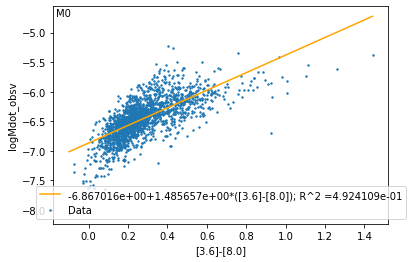

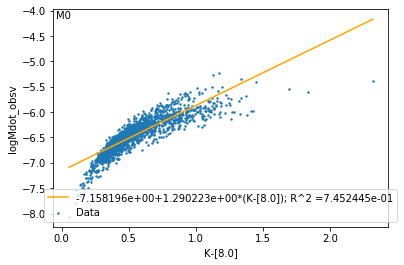


M1:

 Fit: logMdot= 1.208913127825394 *x+ -9.28470947614725


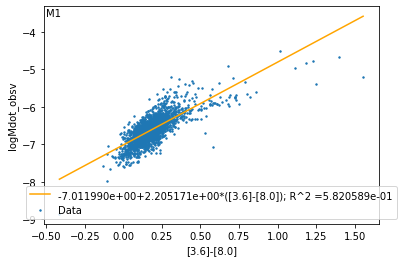

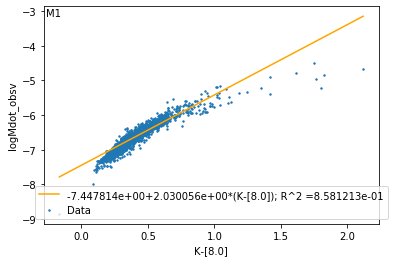


C0

 Fit: logMdot= 0.47252442338805534 *x+ -8.05215150628946


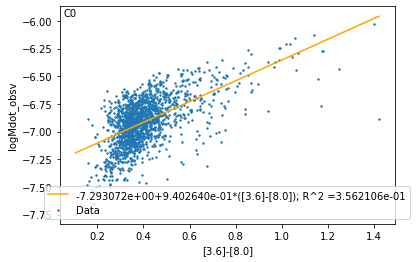

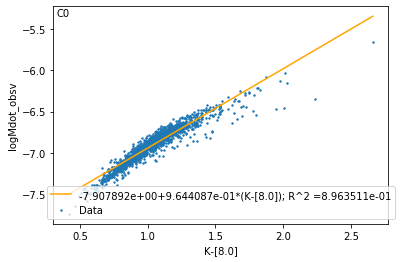

In [58]:
Directory = 'Single_Parameter_Fits/2color_Mdot/logR'
print('M0:')
full_parameter_analysis (np.log10(M0_2Color_Data_JMinK[RIndex]), M0_color_Mdot, M0_2Color_Data_JMinK, stellar_data_xlabel='log(R)', plot_label='M0', save_fig = 1, save_folder=Directory)
print('\nM1:')
full_parameter_analysis (np.log10(M1_2Color_Data_JMinK[RIndex]), M1_color_Mdot, M1_2Color_Data_JMinK, stellar_data_xlabel='log(R)', plot_label='M1', save_fig = 1, save_folder=Directory)
print('\nC0')
full_parameter_analysis (np.log10(C0_2Color_Data_JMinK[RIndex]), C0_color_Mdot, C0_2Color_Data_JMinK, stellar_data_xlabel='log(R)', plot_label='C0', save_fig = 1, save_folder=Directory)

M0:

 Fit: logMdot= -0.7887731243077631 *x+ -6.452395506974632


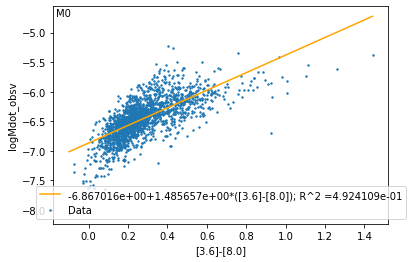

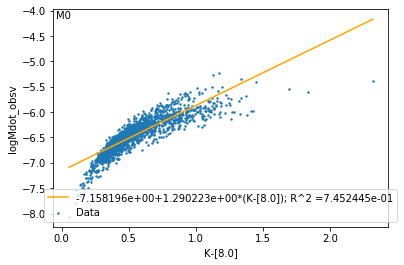


M1:

 Fit: logMdot= 0.2626435316649246 *x+ -6.591436460216555


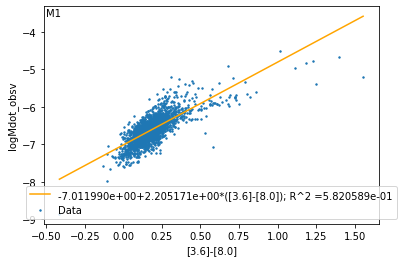

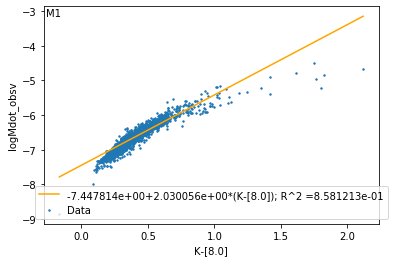


C0

 Fit: logMdot= -0.1977537417862745 *x+ -6.873604553452311


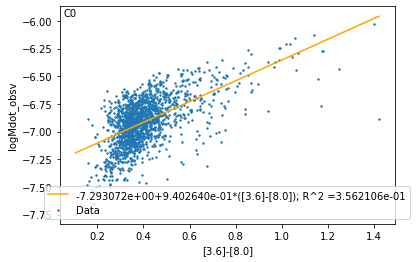

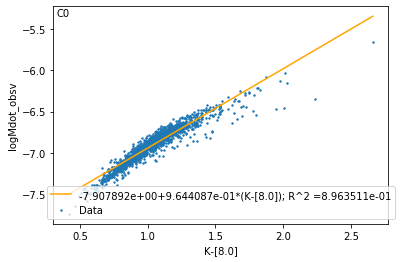

In [59]:
Directory = 'Single_Parameter_Fits/2color_Mdot/logM'
print('M0:')
full_parameter_analysis (np.log10(M0_2Color_Data_JMinK[MIndex]), M0_color_Mdot, M0_2Color_Data_JMinK, stellar_data_xlabel='log(M)', plot_label='M0', save_fig = 1, save_folder=Directory)
print('\nM1:')
full_parameter_analysis (np.log10(M1_2Color_Data_JMinK[MIndex]), M1_color_Mdot, M1_2Color_Data_JMinK, stellar_data_xlabel='log(M)', plot_label='M1', save_fig = 1, save_folder=Directory)
print('\nC0')
full_parameter_analysis (np.log10(C0_2Color_Data_JMinK[MIndex]), C0_color_Mdot, C0_2Color_Data_JMinK, stellar_data_xlabel='log(M)', plot_label='C0', save_fig = 1, save_folder=Directory)


In [60]:
M0_logPE = calc_PE_scale(M0_2Color_Data_JMinK)
M1_logPE = calc_PE_scale(M1_2Color_Data_JMinK)
C0_logPE = calc_PE_scale(C0_2Color_Data_JMinK)

M0_logg = calc_g_scale(M0_2Color_Data_JMinK)
M1_logg = calc_g_scale(M1_2Color_Data_JMinK)
C0_logg = calc_g_scale(C0_2Color_Data_JMinK)

M0_logLP = calc_lum_pressure_scale(M0_2Color_Data_JMinK)
M1_logLP = calc_lum_pressure_scale(M1_2Color_Data_JMinK)
C0_logLP = calc_lum_pressure_scale(C0_2Color_Data_JMinK)

M0_logCL = calc_core_lum_param(M0_2Color_Data_JMinK)
M1_logCL = calc_core_lum_param(M1_2Color_Data_JMinK)
C0_logCL = calc_core_lum_param(C0_2Color_Data_JMinK)


 Fit: logMdot= -2.270279337172963 *x+ -11.401304105009185


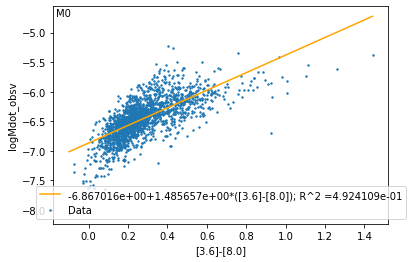

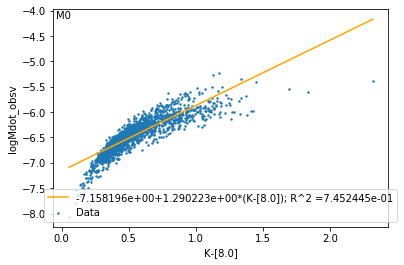


 Fit: logMdot= -2.500450926233774 *x+ -12.148008923036492


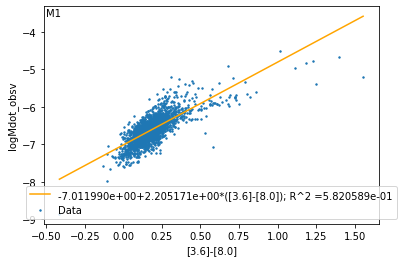

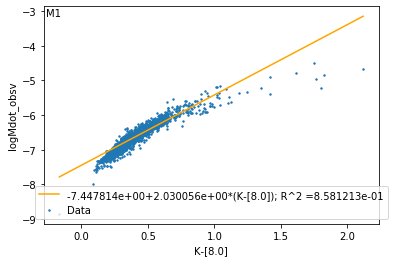


 Fit: logMdot= -1.281597167278935 *x+ -9.773059664580588


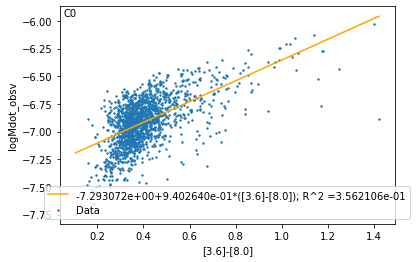

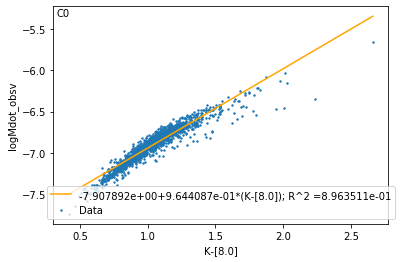

In [61]:
Directory = 'Single_Parameter_Fits/2color_Mdot/log(M/R)'
full_parameter_analysis (M0_logPE, M0_color_Mdot, M0_2Color_Data_JMinK, stellar_data_xlabel='log(M/R)', plot_label='M0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (M1_logPE, M1_color_Mdot, M1_2Color_Data_JMinK, stellar_data_xlabel='log(M/R)', plot_label='M1', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C0_logPE, C0_color_Mdot, C0_2Color_Data_JMinK, stellar_data_xlabel='log(M/R)', plot_label='C0', save_fig = 1, save_folder=Directory)


 Fit: logMdot= -1.223356963436922 *x+ -11.800560493092911


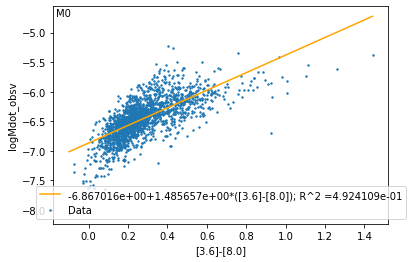

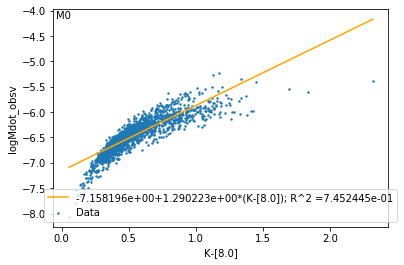


 Fit: logMdot= -1.220481709979875 *x+ -12.023498549600196


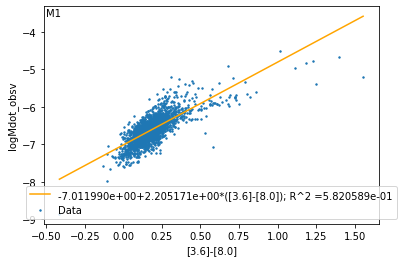

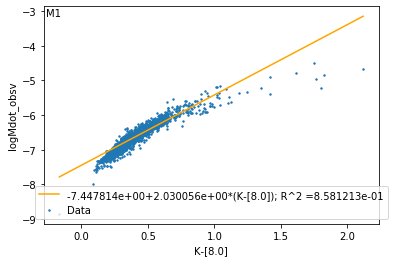


 Fit: logMdot= -1.048047471806772 *x+ -11.784863652859865


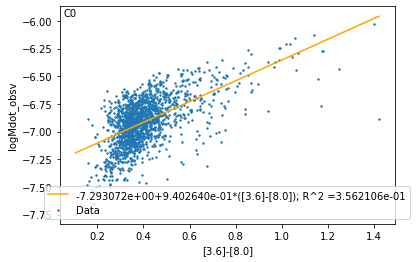

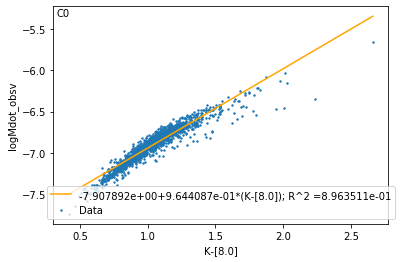

In [62]:
Directory = 'Single_Parameter_Fits/2color_Mdot/log(M/R^2)'
full_parameter_analysis (M0_logg, M0_color_Mdot, M0_2Color_Data_JMinK, stellar_data_xlabel='log(M/R^2)', plot_label='M0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (M1_logg, M1_color_Mdot, M1_2Color_Data_JMinK, stellar_data_xlabel='log(M/R^2)', plot_label='M1', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C0_logg, C0_color_Mdot, C0_2Color_Data_JMinK, stellar_data_xlabel='log(M/R^2)', plot_label='C0', save_fig = 1, save_folder=Directory)



 Fit: logMdot= -5.090240925357657 *x+ -10.78052657506949


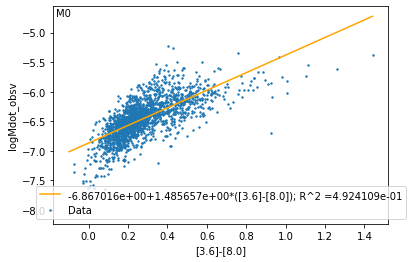

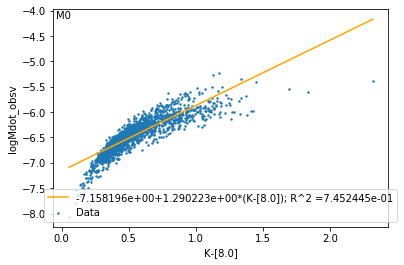


 Fit: logMdot= -5.118719232013738 *x+ -11.074337692334096


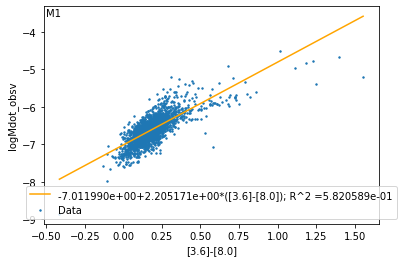

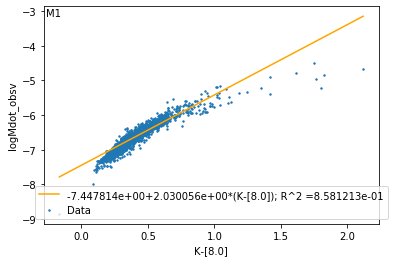


 Fit: logMdot= -3.0684213999262164 *x+ -10.052560108547668


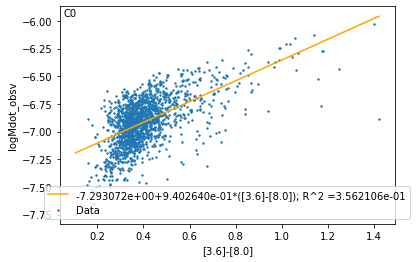

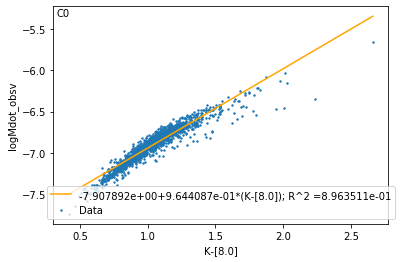

In [63]:
Directory = 'Single_Parameter_Fits/2color_Mdot/log(L/R^2)'
full_parameter_analysis (M0_logLP, M0_color_Mdot, M0_2Color_Data_JMinK, stellar_data_xlabel='log(L/R^2)', plot_label='M0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (M1_logLP, M1_color_Mdot, M1_2Color_Data_JMinK, stellar_data_xlabel='log(L/R^2)', plot_label='M1', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C0_logLP, C0_color_Mdot, C0_2Color_Data_JMinK, stellar_data_xlabel='log(L/R^2)', plot_label='C0', save_fig = 1, save_folder=Directory)



 Fit: logMdot= 1.5183994324590488 *x+ -11.799904494508617


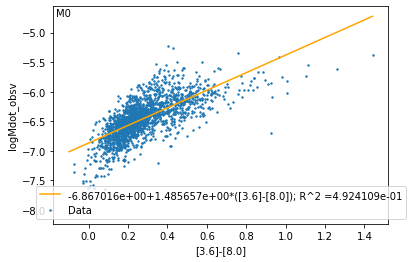

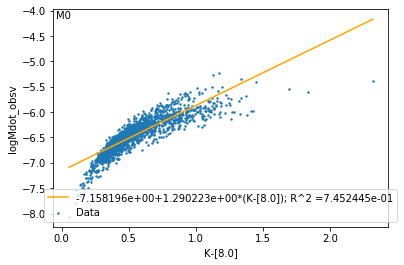


 Fit: logMdot= 1.5622000669727962 *x+ -12.176207983827336


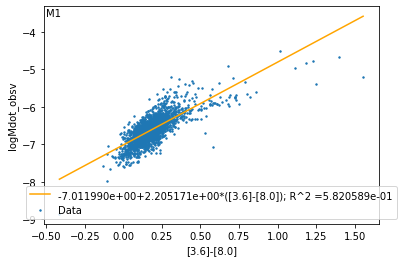

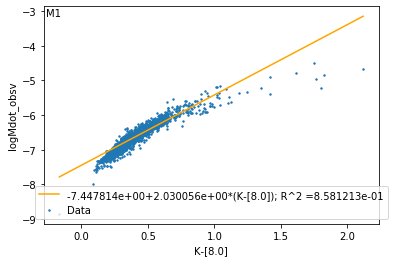


 Fit: logMdot= 1.1409599411558473 *x+ -11.048467264939779


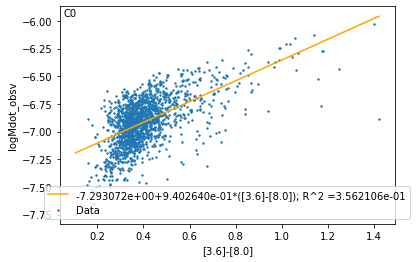

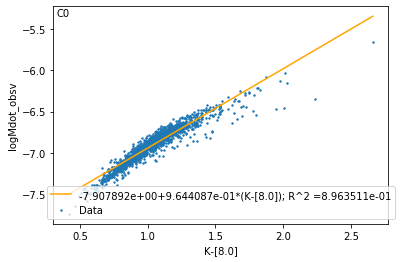

In [64]:
Directory = 'Single_Parameter_Fits/2color_Mdot/log(L/M)'
full_parameter_analysis (M0_logCL, M0_color_Mdot, M0_2Color_Data_JMinK, stellar_data_xlabel='log(L/M)', plot_label='M0', save_fig = 1, save_folder=Directory)
full_parameter_analysis (M1_logCL, M1_color_Mdot, M1_2Color_Data_JMinK, stellar_data_xlabel='log(L/M)', plot_label='M1', save_fig = 1, save_folder=Directory)
full_parameter_analysis (C0_logCL, C0_color_Mdot, C0_2Color_Data_JMinK, stellar_data_xlabel='log(L/M)', plot_label='C0', save_fig = 1, save_folder=Directory)


In [65]:
def PE_minus_resid (stellar_data_x, stellar_data_mdot, full_stellar_data, stellar_data_xlabel='', plot_label = '', save_folder = '', save_fig = 0):
    #fig, ax = plt.subplots()
    # Data Analysis: Do a chi^2 fit of our chosen parameter vs Mdot for our star, and find the residuals of that fit
    chisqfit_returns = chi_sq_fit_2d (stellar_data_x,stellar_data_mdot)
    Betas = chisqfit_returns[0]
    RSquared = chisqfit_returns[1]
    print('\n Initial Fit: logMdot=', Betas[1],'*x+',Betas[0])
    logMdot_calc = Betas[1]*stellar_data_x+Betas[0]
    logMdot_residual = logMdot_calc- stellar_data_mdot
    # Data Analysis: For the input, calculate some proxies for stellar parameters (so they don't have to be fed to the function indvidually)
    logPE = calc_PE_scale(full_stellar_data)
    logg = calc_g_scale(full_stellar_data)
    logLP = calc_lum_pressure_scale(full_stellar_data)
    logCL = calc_core_lum_param(full_stellar_data)
    Correction_betas = plot_residual_vs_parameter(logMdot_residual,logCL,title=plot_label,parameter_label='log(L/M)')
    logMdot_calc = Betas[1]*stellar_data_x+Betas[0] - (Correction_betas[0] + Correction_betas[1]*logCL)
    chisqfit_returns = chi_sq_fit_2d (stellar_data_x,logMdot_calc)
    Betas = chisqfit_returns[0]
    logMdot_residual = logMdot_calc- stellar_data_mdot
    print('\n Corrected Fit: logMdot=', Betas[1],'*log(M/R)+',Correction_betas[1],'log(L/M)+',Betas[0]-Correction_betas[0])
    # First Plot: Chosen Parameter vs Mdot, so we can see what the chi^2 fit looks like
    plot.scatter(stellar_data_x,stellar_data_mdot,s=2,label = 'Data')
    fit_x = np.asarray([np.min(stellar_data_x), np.max(stellar_data_x)])
    fit_y = Betas[0] + Betas[1]*fit_x
    fit_label = str(Betas[1])[:6]+'*log(M/R)+'+str(Correction_betas[1])[:6]+'log(L/M)+'+str(Betas[0]-Correction_betas[0])[:6]+'; R^2 ='+ str(chisqfit_returns[1])[0:6]
    plot.plot(fit_x,fit_y,color='orange',label = fit_label)
    plot.xlabel(stellar_data_xlabel)
    plot.ylabel('logMdot_obsv')
    #plot.title(plot_label)
    #ax.text(0.03, .97,plot_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot.legend()
    plot.tight_layout()
    if save_fig != 0:
            plot_name = save_folder + '/' + 'logMdot_versus_' + 'log(M/R)' + '/' + plot_label
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()
    # More plots
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[PIndex]),title=plot_label,parameter_label='logP',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[LIndex]),title=plot_label,parameter_label='logL',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[MIndex]),title=plot_label,parameter_label='logM',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logPE,title=plot_label,parameter_label='log(M/R)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logg,title=plot_label,parameter_label='log(M/R^2)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logLP,title=plot_label,parameter_label='log(L/R^2)',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,logCL,title=plot_label,parameter_label='log(L/M)',save_folder = save_folder,save_fig = save_fig)
    # Add some plots vs color (J-[3.6] and J-K)
    color_J_minus_ThreePointSix = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[ThreePointSixIndex])
    color_ThreePointSix_minus_EightPointZero = np.asarray(full_stellar_data[ThreePointSixIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    color_J_minus_K = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[KIndex])
    color_K_minus_EightPointZero = np.asarray(full_stellar_data[KIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    plot_logmdot_vs_parameter (stellar_data_mdot,color_ThreePointSix_minus_EightPointZero , title=plot_label, parameter_label='[3.6]-[8.0]')
    plot_logmdot_vs_parameter (stellar_data_mdot, color_K_minus_EightPointZero, title=plot_label, parameter_label='K-[8.0]')
    plot_residual_vs_parameter(logMdot_residual,color_ThreePointSix_minus_EightPointZero,title=plot_label,parameter_label='[3.6]-[8.0]',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,color_K_minus_EightPointZero,title=plot_label,parameter_label='K-[8.0]',save_folder = save_folder,save_fig = save_fig)
    
    print('\n')
    plot_logmdot_vs_logmdot(stellar_data_mdot, logMdot_calc, title=plot_label,save_folder = save_folder,save_fig = save_fig)


 Initial Fit: logMdot= -2.270279337172963 *x+ -11.401304105009185


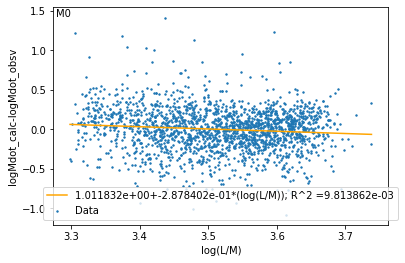


 Corrected Fit: logMdot= -2.473376866464769 *log(M/R)+ -0.2878401693231528 log(L/M)+ -12.854972132551225


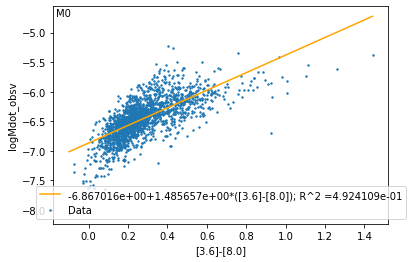

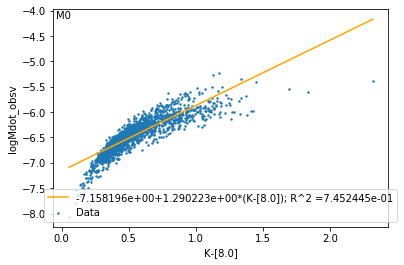




 Initial Fit: logMdot= -2.500450926233774 *x+ -12.148008923036492


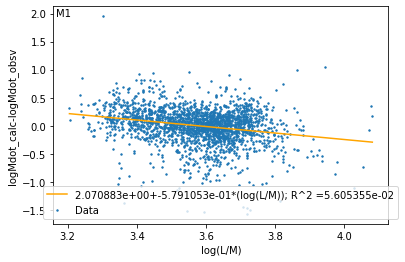


 Corrected Fit: logMdot= -3.109908164153332 *log(M/R)+ -0.5791053193538546 log(L/M)+ -15.573650038853586


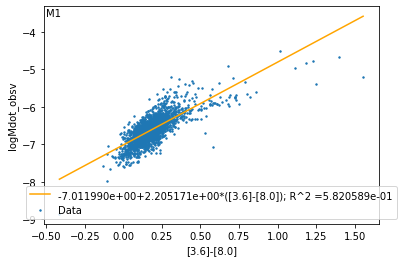

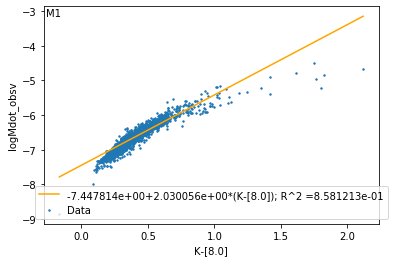




 Initial Fit: logMdot= -1.281597167278935 *x+ -9.773059664580588


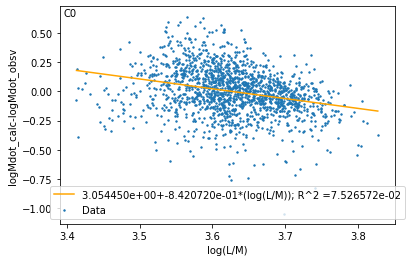


 Corrected Fit: logMdot= -1.4924631294341388 *log(M/R)+ -0.8420720275854344 log(L/M)+ -13.298602892992285


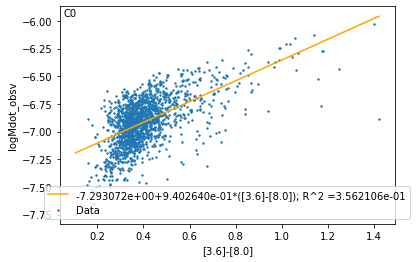

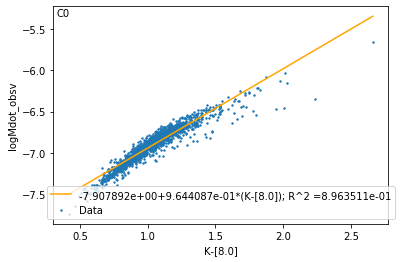

In [66]:
Directory = 'Single_Parameter_Fits/2color_Mdot/ExtendedAnalyses/log(MdivR)'
PE_minus_resid (M0_logPE, M0_color_Mdot, M0_2Color_Data_JMinK, stellar_data_xlabel='log(M/R)', plot_label='M0', save_fig = 1, save_folder=Directory)
PE_minus_resid (M1_logPE, M1_color_Mdot, M1_2Color_Data_JMinK, stellar_data_xlabel='log(M/R)', plot_label='M1', save_fig = 1, save_folder=Directory)
PE_minus_resid (C0_logPE, C0_color_Mdot, C0_2Color_Data_JMinK, stellar_data_xlabel='log(M/R)', plot_label='C0', save_fig = 1, save_folder=Directory)

In [67]:
def T_minus_resid (stellar_data_x, stellar_data_mdot, full_stellar_data, fed_index, stellar_data_xlabel='', plot_label = '', save_folder = '', save_fig = 0):
    #fig, ax = plt.subplots()
    # Data Analysis: Do a chi^2 fit of our chosen parameter vs Mdot for our star, and find the residuals of that fit
    chisqfit_returns = chi_sq_fit_2d (stellar_data_x,stellar_data_mdot)
    Betas = chisqfit_returns[0]
    print('\n Initial Fit: logMdot=', Betas[1],'*x+',Betas[0])
    logMdot_calc = Betas[1]*stellar_data_x+Betas[0]
    logMdot_residual = logMdot_calc- stellar_data_mdot
    # Data Analysis: For the input, calculate some proxies for stellar parameters (so they don't have to be fed to the function indvidually)
    logPE = calc_PE_scale(full_stellar_data)
    logg = calc_g_scale(full_stellar_data)
    logLP = calc_lum_pressure_scale(full_stellar_data)
    logCL = calc_core_lum_param(full_stellar_data)
    if fed_index == RIndex:
        Correction_betas = plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[fed_index]),title=plot_label,parameter_label='log(R)')
    elif fed_index == LIndex:
        Correction_betas = plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[fed_index]),title=plot_label,parameter_label='log(L)')
    elif fed_index == PIndex:
        Correction_betas = plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[fed_index]),title=plot_label,parameter_label='log(P)')
    elif fed_index == MIndex:
        Correction_betas = plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[fed_index]),title=plot_label,parameter_label='log(M)')
    
    logMdot_calc = Betas[1]*stellar_data_x+Betas[0] - (Correction_betas[0] + Correction_betas[1]*np.log10(full_stellar_data[fed_index]))
    chisqfit_returns = chi_sq_fit_2d (stellar_data_x,logMdot_calc)
    Betas = chisqfit_returns[0]
    logMdot_residual = logMdot_calc- stellar_data_mdot
    if fed_index == RIndex:
        print('\n Corrected Fit: logMdot=', Betas[1],'*log(L/R^2)+',Correction_betas[1],'log(R)+',Betas[0]-Correction_betas[0])
        fit_label = str(Betas[1])[:6]+'*log(L/R^2)+'+str(Correction_betas[1])[:6]+'log(R)+'+str(Betas[0]-Correction_betas[0])[:6]
    elif fed_index == LIndex:
        print('\n Corrected Fit: logMdot=', Betas[1],'*log(L/R^2)+',Correction_betas[1],'log(L)+',Betas[0]-Correction_betas[0])
        fit_label = str(Betas[1])[:6]+'*log(L/R^2)+'+str(Correction_betas[1])[:6]+'log(L)+'+str(Betas[0]-Correction_betas[0])[:6]
    elif fed_index == PIndex:
        print('\n Corrected Fit: logMdot=', Betas[1],'*log(L/R^2)+',Correction_betas[1],'log(P)+',Betas[0]-Correction_betas[0])
        fit_label = str(Betas[1])[:6]+'*log(L/R^2)+'+str(Correction_betas[1])[:6]+'log(P)+'+str(Betas[0]-Correction_betas[0])[:6]
    elif fed_index == MIndex:
        print('\n Corrected Fit: logMdot=', Betas[1],'*log(L/R^2)+',Correction_betas[1],'log(M)+',Betas[0]-Correction_betas[0])
        fit_label = str(Betas[1])[:6]+'*log(L/R^2)+'+str(Correction_betas[1])[:6]+'log(M)+'+str(Betas[0]-Correction_betas[0])[:6]
    # First Plot: Chosen Parameter vs Mdot, so we can see what the chi^2 fit looks like
    plot.scatter(stellar_data_x,stellar_data_mdot,s=2,label='Data')
    fit_x = np.asarray([np.min(stellar_data_x), np.max(stellar_data_x)])
    fit_y = Betas[0] + Betas[1]*fit_x
    plot.plot(fit_x,fit_y,color='orange',label=fit_label)
    plot.xlabel(stellar_data_xlabel)
    plot.ylabel('logMdot_obsv')
    #plot.title(plot_label)
    #ax.text(0.03, .97,plot_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    if save_fig != 0:
            plot_name = save_folder + '/' + 'logMdot_versus_' + 'log(L/R^2)' + '/' + plot_label
            plot_name = plot_name.replace('(M/R)', '(MdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(M/R^2)', '(MdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R)', '(LdivR)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/R^2)', '(LdivR^2)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot_name = plot_name.replace('(L/M)', '(LdivM)') # Illegal character on Windows. Replace the Directory character with a simple string
            plot.savefig(plot_name+'.png')
            plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    else:
        plot.show()
    plot.close()
    # More plots
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[PIndex]),title=plot_label,parameter_label='logP', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[LIndex]),title=plot_label,parameter_label='logL', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,np.log10(full_stellar_data[MIndex]),title=plot_label,parameter_label='logM', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,logPE,title=plot_label,parameter_label='log(M/R)', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,logg,title=plot_label,parameter_label='log(M/R^2)', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,logLP,title=plot_label,parameter_label='log(L/R^2)', save_fig = 1, save_folder=Directory)
    plot_residual_vs_parameter(logMdot_residual,logCL,title=plot_label,parameter_label='log(L/M)', save_fig = 1, save_folder=Directory)
    # Add some plots vs color (J-[3.6] and J-K)
    color_J_minus_ThreePointSix = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[ThreePointSixIndex])
    color_ThreePointSix_minus_EightPointZero = np.asarray(full_stellar_data[ThreePointSixIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    color_J_minus_K = np.asarray(full_stellar_data[JIndex])-np.asarray(full_stellar_data[KIndex])
    color_K_minus_EightPointZero = np.asarray(full_stellar_data[KIndex])-np.asarray(full_stellar_data[EightPointZeroIndex])
    plot_logmdot_vs_parameter (stellar_data_mdot,color_ThreePointSix_minus_EightPointZero , title=plot_label, parameter_label='[3.6]-[8.0]')
    plot_logmdot_vs_parameter (stellar_data_mdot, color_K_minus_EightPointZero, title=plot_label, parameter_label='K-[8.0]')
    plot_residual_vs_parameter(logMdot_residual,color_ThreePointSix_minus_EightPointZero,title=plot_label,parameter_label='[3.6]-[8.0]',save_folder = save_folder,save_fig = save_fig)
    plot_residual_vs_parameter(logMdot_residual,color_K_minus_EightPointZero,title=plot_label,parameter_label='K-[8.0]',save_folder = save_folder,save_fig = save_fig)
    
    #print('\n')
    plot_logmdot_vs_logmdot(stellar_data_mdot, logMdot_calc, title=plot_label, save_fig = 1, save_folder=Directory)


 Initial Fit: logMdot= -5.090240925357657 *x+ -10.78052657506949


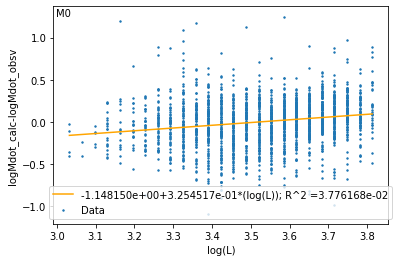


 Corrected Fit: logMdot= -4.515975946766487 *log(L/R^2)+ 0.32545171955952723 log(L)+ -9.145212607878587


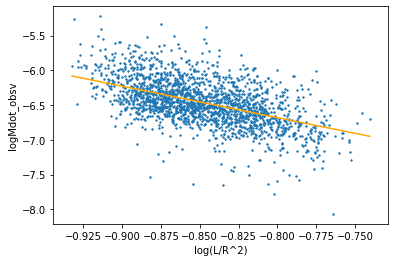

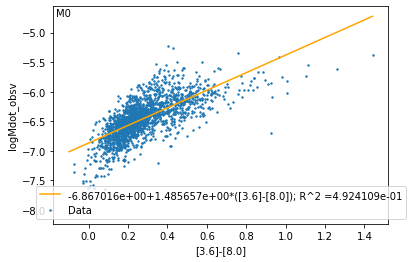

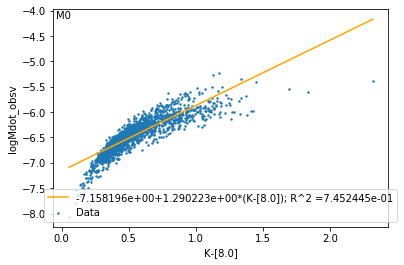

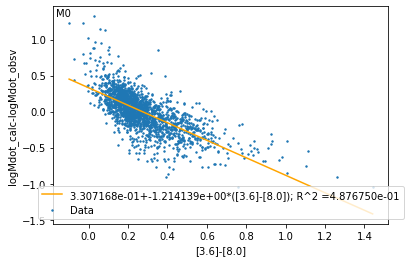

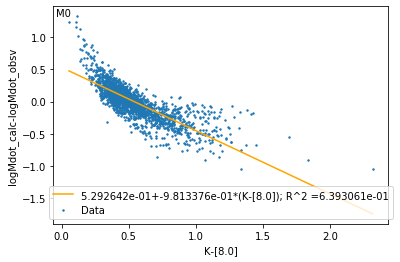


 Initial Fit: logMdot= -5.118719232013738 *x+ -11.074337692334096


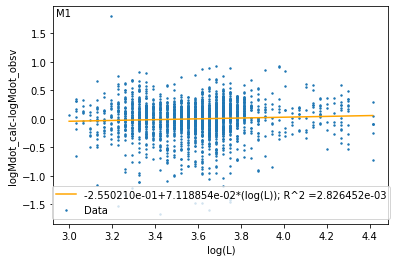


 Corrected Fit: logMdot= -4.861179072841483 *log(L/R^2)+ 0.07118853940481162 log(L)+ -10.593683039357646


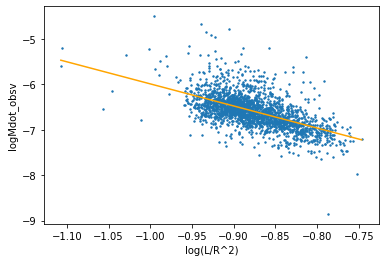

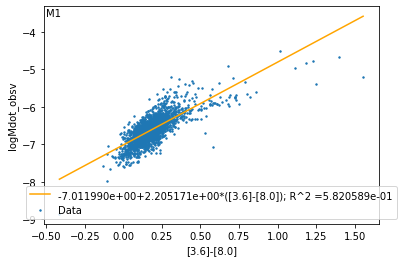

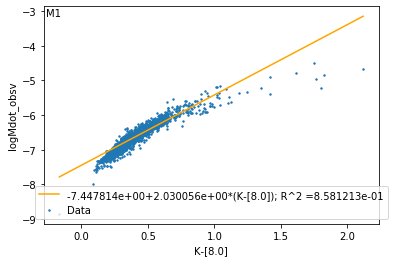

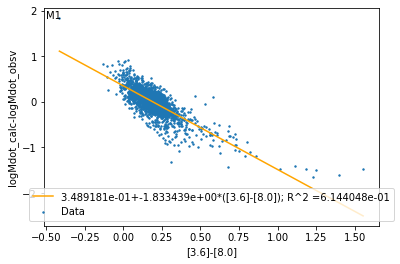

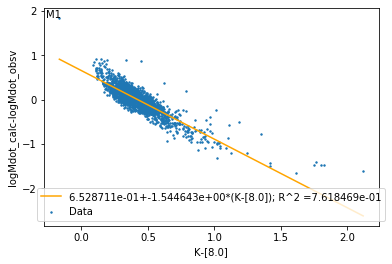


 Initial Fit: logMdot= -3.0684213999262164 *x+ -10.052560108547668


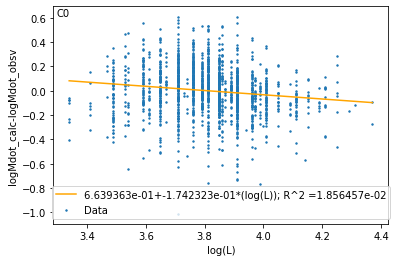


 Corrected Fit: logMdot= -2.978365795712311 *log(L/R^2)+ -0.1742322813579333 log(L)+ -10.624260823837606


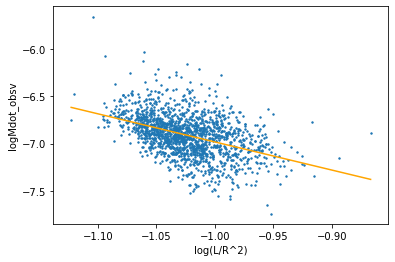

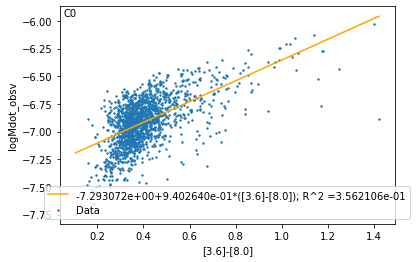

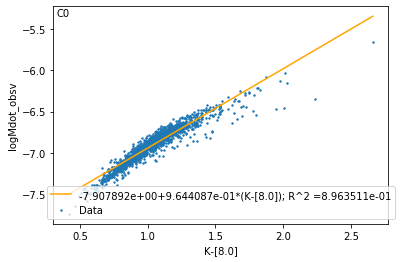

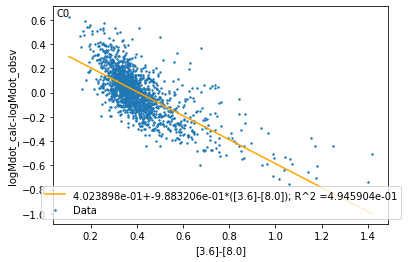

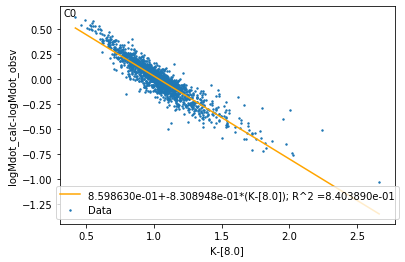

In [68]:
Directory = 'Single_Parameter_Fits/2color_Mdot/ExtendedAnalyses/log(LdivR^2)/subtract_logL'
T_minus_resid (M0_logLP, M0_color_Mdot, M0_2Color_Data_JMinK, LIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M0')
T_minus_resid (M1_logLP, M1_color_Mdot, M1_2Color_Data_JMinK, LIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M1')
T_minus_resid (C0_logLP, C0_color_Mdot, C0_2Color_Data_JMinK, LIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C0')


 Initial Fit: logMdot= -5.090240925357657 *x+ -10.78052657506949


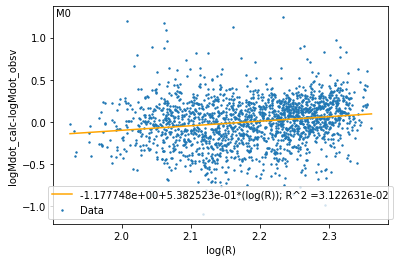


 Corrected Fit: logMdot= -4.34623726693809 *log(L/R^2)+ 0.5382522531568577 log(R)+ -8.971621141895417


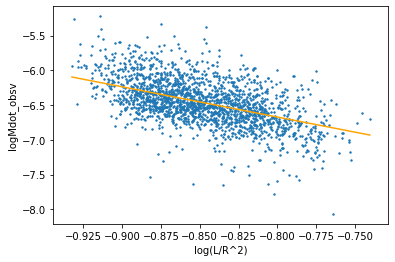

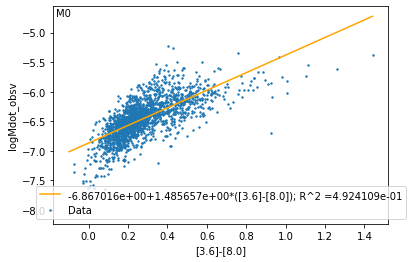

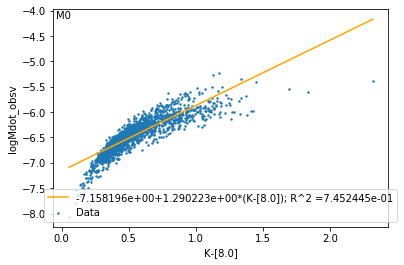

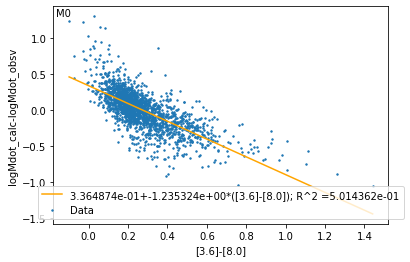

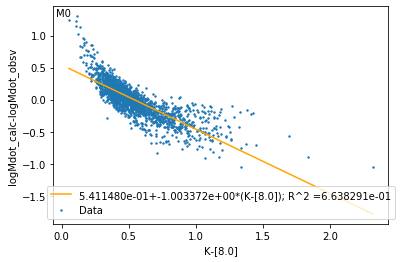


 Initial Fit: logMdot= -5.118719232013738 *x+ -11.074337692334096


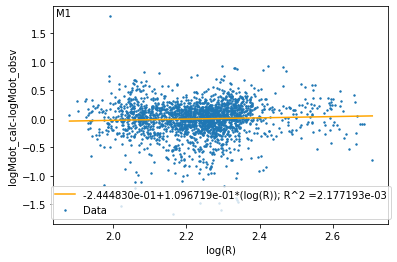


 Corrected Fit: logMdot= -4.865502133183332 *log(L/R^2)+ 0.10967193005107041 log(R)+ -10.608008516694037


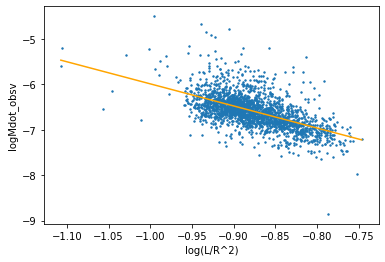

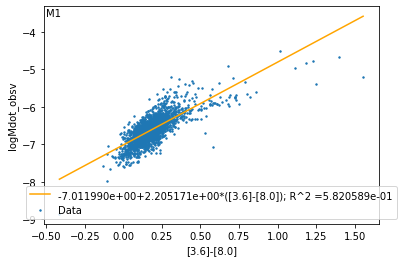

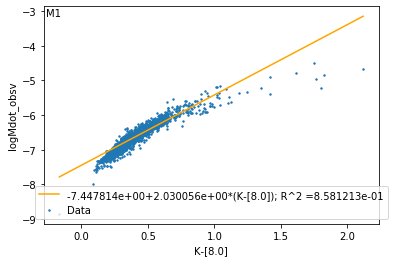

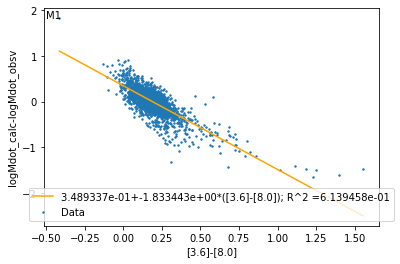

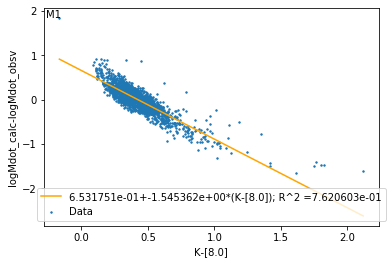


 Initial Fit: logMdot= -3.0684213999262164 *x+ -10.052560108547668


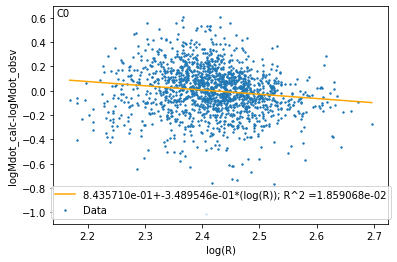


 Corrected Fit: logMdot= -3.1527164535680865 *log(L/R^2)+ -0.3489546036150536 log(R)+ -10.982466712821168


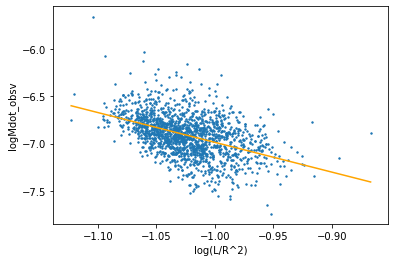

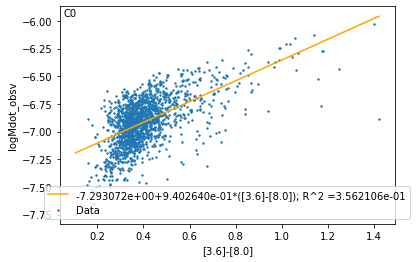

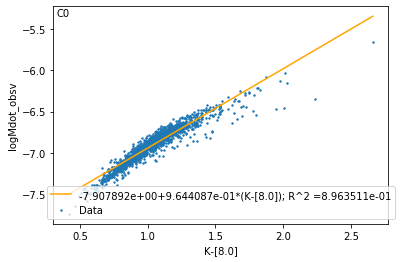

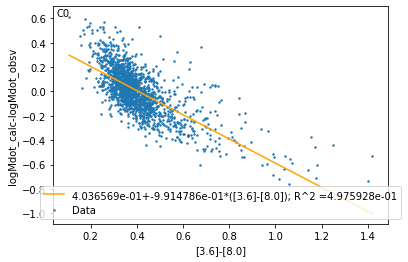

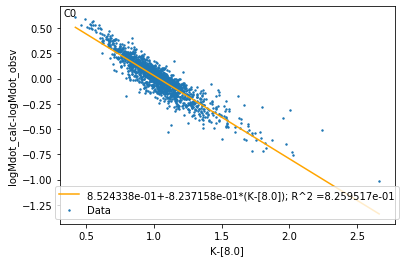

In [69]:
Directory = 'Single_Parameter_Fits/2color_Mdot/ExtendedAnalyses/log(LdivR^2)/subtract_logR'
T_minus_resid (M0_logLP, M0_color_Mdot, M0_2Color_Data_JMinK, RIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M0')
T_minus_resid (M1_logLP, M1_color_Mdot, M1_2Color_Data_JMinK, RIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M1')
T_minus_resid (C0_logLP, C0_color_Mdot, C0_2Color_Data_JMinK, RIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C0')



 Initial Fit: logMdot= -5.090240925357657 *x+ -10.78052657506949


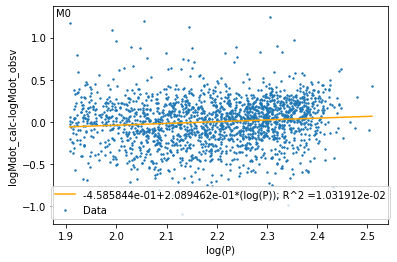


 Corrected Fit: logMdot= -4.397552332169579 *log(L/R^2)+ 0.208946176149526 log(P)+ -9.734316243200993


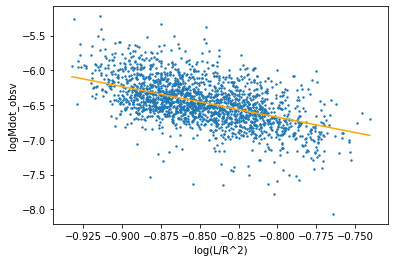

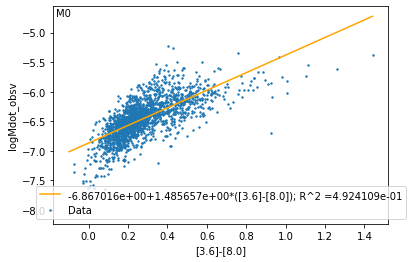

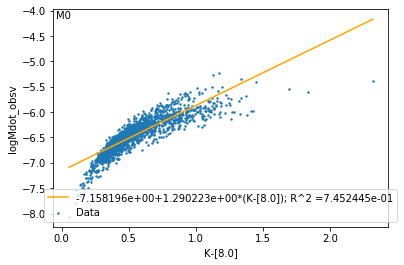

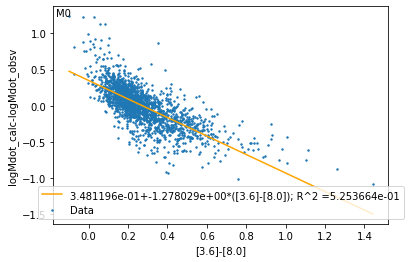

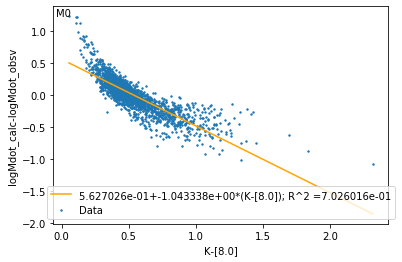


 Initial Fit: logMdot= -5.118719232013738 *x+ -11.074337692334096


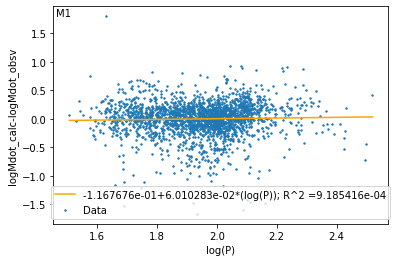


 Corrected Fit: logMdot= -4.924537728136395 *log(L/R^2)+ 0.06010283213562115 log(P)+ -10.787445659324518


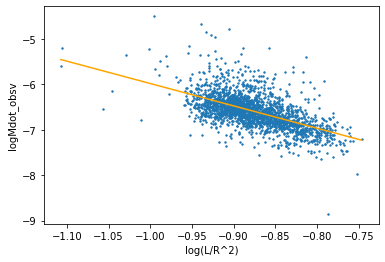

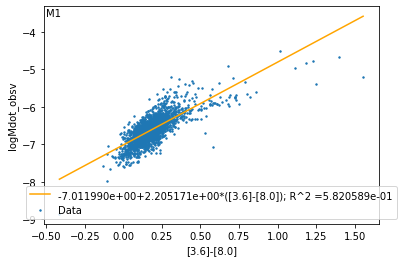

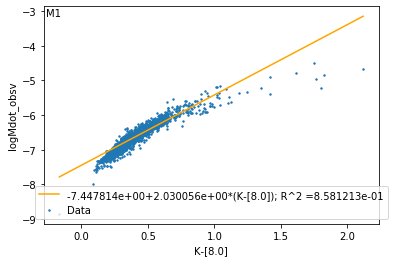

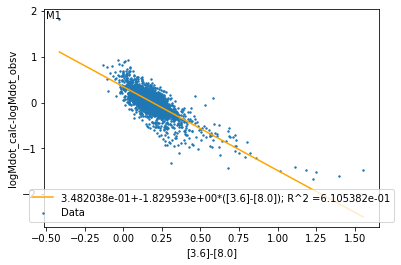

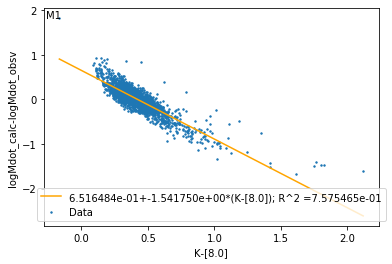


 Initial Fit: logMdot= -3.0684213999262164 *x+ -10.052560108547668


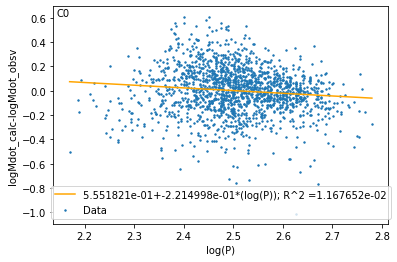


 Corrected Fit: logMdot= -3.484865165369445 *log(L/R^2)+ -0.2214997520790858 log(P)+ -11.034267062935362


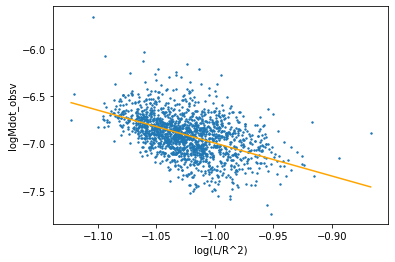

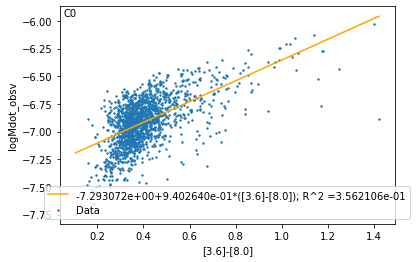

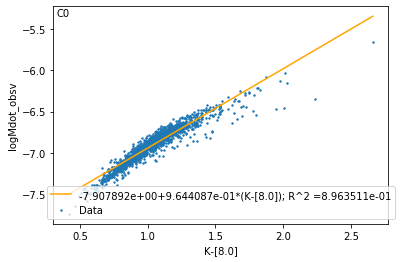

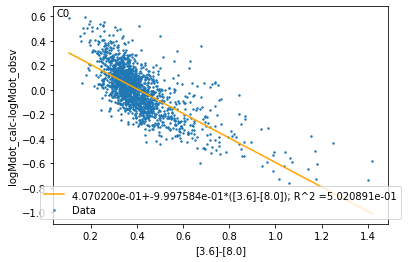

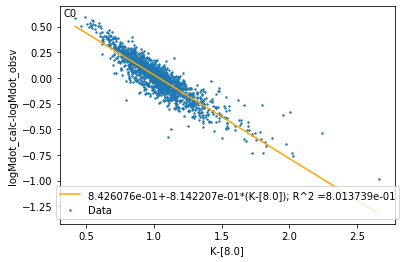

In [70]:
Directory = 'Single_Parameter_Fits/2color_Mdot/ExtendedAnalyses/log(LdivR^2)/subtract_logP'
T_minus_resid (M0_logLP, M0_color_Mdot, M0_2Color_Data_JMinK, PIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M0')
T_minus_resid (M1_logLP, M1_color_Mdot, M1_2Color_Data_JMinK, PIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M1')
T_minus_resid (C0_logLP, C0_color_Mdot, C0_2Color_Data_JMinK, PIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C0')


 Initial Fit: logMdot= -5.090240925357657 *x+ -10.78052657506949


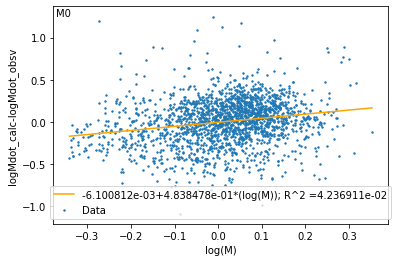


 Corrected Fit: logMdot= -5.408641003950176 *log(L/R^2)+ 0.48384779181029713 log(M)+ -11.04453293679451


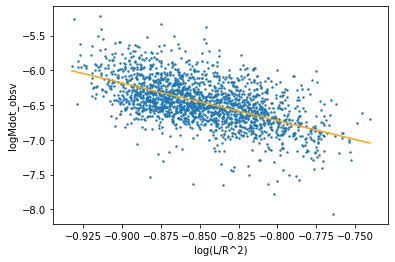

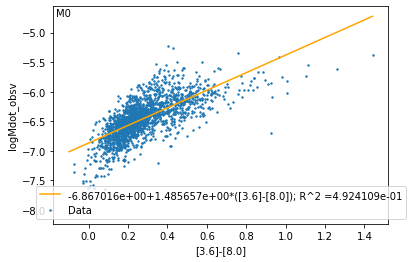

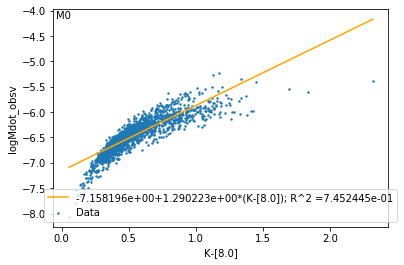

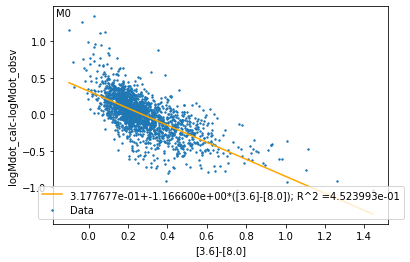

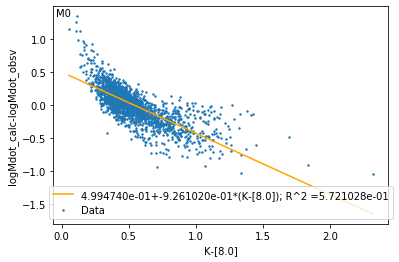


 Initial Fit: logMdot= -5.118719232013738 *x+ -11.074337692334096


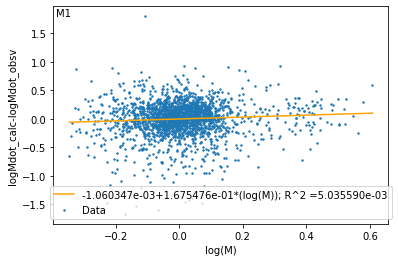


 Corrected Fit: logMdot= -4.993648129402902 *log(L/R^2)+ 0.16754758619760635 log(M)+ -10.963701244992988


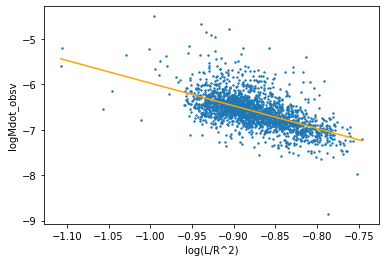

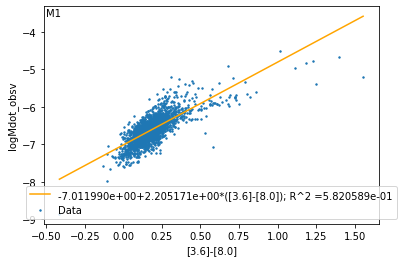

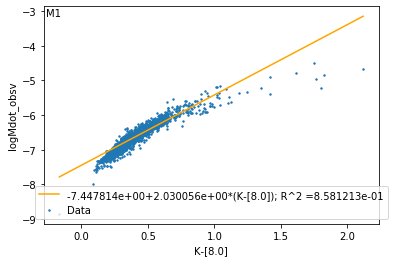

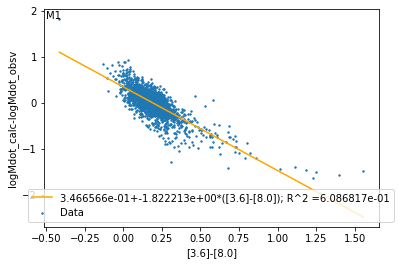

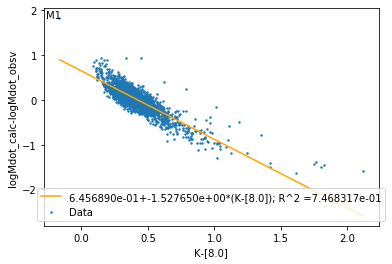


 Initial Fit: logMdot= -3.0684213999262164 *x+ -10.052560108547668


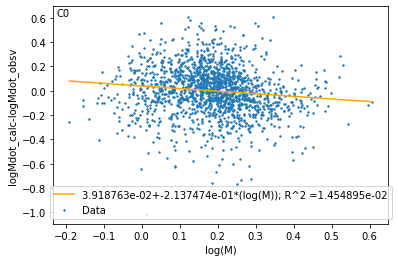


 Corrected Fit: logMdot= -2.7097761140322953 *log(L/R^2)+ -0.21374737347879277 log(M)+ -9.724420550990947


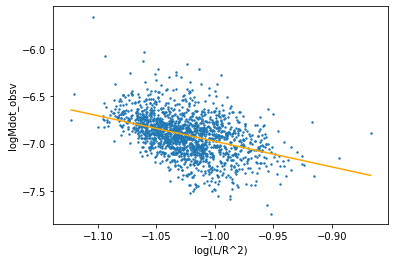

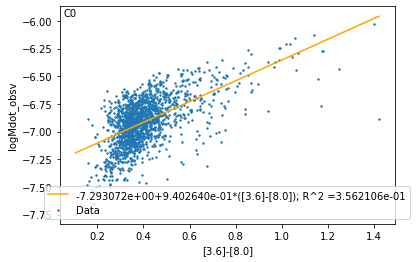

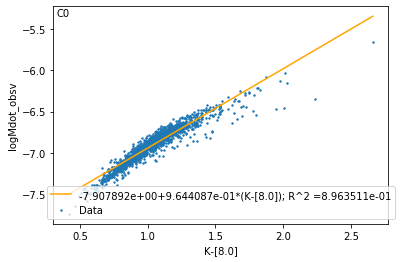

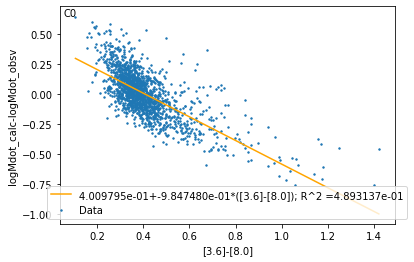

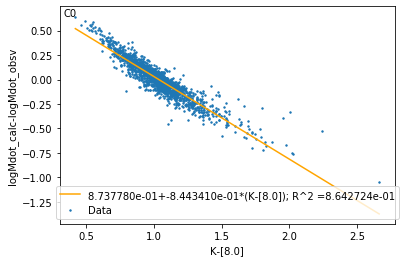

In [71]:
Directory = 'Single_Parameter_Fits/2color_Mdot/ExtendedAnalyses/log(LdivR^2)/subtract_logM'
T_minus_resid (M0_logLP, M0_color_Mdot, M0_2Color_Data_JMinK, MIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M0')
T_minus_resid (M1_logLP, M1_color_Mdot, M1_2Color_Data_JMinK, MIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'M1')
T_minus_resid (C0_logLP, C0_color_Mdot, C0_2Color_Data_JMinK, MIndex, stellar_data_xlabel='log(L/R^2)', plot_label = 'C0')


In [72]:
def multilinear_fit_2var_WLS (xdata, ydata, xdata_error, ydata_error):
    std_error_x0 = np.nanstd(xdata_error)
    std_error_y = np.nanstd(ydata_error)
    x0 = xdata[0] # logL
    x1 = xdata[1] # logP
    y = ydata # logMdot
    
    wls_model = sm.WLS(ydata, xdata, [1/std_error_x0**2, 1, 1/std_error_y**2])
    
    # Parameters are returned in the format intercept, slope 1, slope 2
    return model._results.params, model._results.rsquared, model.bse

In [73]:
def do_final_fits(bulk_raw_data,mdot_data, fed_label = '',star_type_label=''):
    break_line = '__________________________________________________________________________\n'
    
    #########################################################
    # Fit 1: Multilinear of L,P vs provided Mdot
    #########################################################
    fig, ax = plt.subplots()
    logLData = np.log10(bulk_raw_data[LIndex])
    logPData = np.log10(bulk_raw_data[PIndex])
    print('Fit 1: Multilinear of L,P vs provided Mdot')
    LPmultilinear_fit = multilinear_fit_2var([logLData,logPData],mdot_data)
    ## PRINT: Coefficients of fit, functional form
    if LPmultilinear_fit[0][1] >= 0:
        if LPmultilinear_fit[0][2] >= 0:
            print('Fit:', LPmultilinear_fit[0][0], '+', LPmultilinear_fit[0][1],'logL', '+', LPmultilinear_fit[0][2],'logP')
        else:
            print('Fit:', LPmultilinear_fit[0][0], '+', LPmultilinear_fit[0][1],'logL', '-', np.abs(LPmultilinear_fit[0][2]),'logP')
    else:
        if LPmultilinear_fit[0][2] >= 0:
            print('Fit:', LPmultilinear_fit[0][0], '-',np.abs(LPmultilinear_fit[0][1]),'logL', '+', LPmultilinear_fit[0][2],'logP')
        else:
            print('Fit:', LPmultilinear_fit[0][0], '-', np.abs(LPmultilinear_fit[0][1]),'logL', '-', np.abs(LPmultilinear_fit[0][2]),'logP')
    print('R^2:', LPmultilinear_fit[1])
    print('Standard Errors (x0 = logL, x1 = logP):\n', LPmultilinear_fit[2])
    LPCoeffs = LPmultilinear_fit[0]
    plot.scatter(logLData,mdot_data, color='tab:blue',s=2)
    plot.xlabel(r'$\log L$')
    if fed_label == "GRAMS":
        plot.ylabel(r'$log \dot{M}\ \mathrm{(GRAMS)}$')
    elif fed_label == "Color":
        plot.ylabel(r'$log \dot{M}\ \mathrm{(Color)}$')
    else:
        plot.ylabel(r'$log \dot{M}\ \mathrm{(Data)}$')
    #plot.title(star_type_label)
    ax.text(0.03, .97,star_type_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot_name = Directory + '/' + star_type_label + '_Mdot'+ fed_label +'_vs_' + 'logL'
    plot.savefig(plot_name+'.png')
    plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    plot.show()
    plot.close()
    fig, ax = plt.subplots()
    plot.scatter(logPData,mdot_data, color='tab:blue',s=2)
    plot.xlabel(r'$\log P$')
    if fed_label == "GRAMS":
        plot.ylabel(r'$log \dot{M}\ \mathrm{(GRAMS)}$')
    elif fed_label == "Color":
        plot.ylabel(r'$log \dot{M}\ \mathrm{(Color)}$')
    else:
        plot.ylabel(r'$log \dot{M}\ \mathrm{(Data)}$')
    #plot.title(star_type_label)
    ax.text(0.03, .97,star_type_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot_name = Directory + '/' + star_type_label + '_Mdot'+ fed_label +'_vs_' + 'logP'
    plot.tight_layout()
    plot.savefig(plot_name+'.png')
    plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    plot.show()
    plot.close()
    #fit_1_flat = np.asarray([multilinear_fit[0][0],multilinear_fit[0][1],multilinear_fit[0][2],multilinear_fit[1]])
    ## Append to returned array: Coefficients of fit
    print(break_line)
    
    #########################################################
    # Fit 2: provided Mdot vs FormulaMdot
    #########################################################
    # Figure 1: Fit vs data
    fig, ax = plt.subplots()
    if fed_label == "GRAMS":
        print('Fit 2: GRAMS Mdot vs Formula Mdot')
    elif fed_label == "Color":
        print('Fit 2: Color Mdot vs Formula Mdot')
    else:
        print('Fit 2: Data Mdot vs Formula Mdot')
    FormulaMdot = LPCoeffs[0] + LPCoeffs[1]*logLData + LPCoeffs[2]*logPData
    form_vs_fed_fit = linear_fit_1var(FormulaMdot,mdot_data)
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    print('form_vs_fed_Coeffs',form_vs_fed_Coeffs)
    plot.scatter(FormulaMdot,mdot_data, color='tab:blue',s=2)
    plot.xlabel(r'$\log \dot{M}\  \mathrm{(Formula)}$')
    if fed_label == "GRAMS":
        plot.ylabel(r'$\log \dot{M} (GRAMS)$')
    elif fed_label == "Color":
        plot.ylabel(r'$\log \dot{M} (Color)$')
    else:
        plot.ylabel(r'$\log \dot{M} (Data)$')
    #plot.title(star_type_label)
    ax.text(0.03, .97,star_type_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    # And the fit line...
    limits = np.asarray([np.nanmin([np.nanmin(FormulaMdot),np.nanmin(mdot_data)]), np.nanmax([np.nanmax(FormulaMdot),np.nanmax(mdot_data)])])
    min_val = limits[0]
    max_val = limits[1]
    quality_line_x = np.asarray([min_val,max_val])
    quality_line_y = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*quality_line_x
    plot.plot(quality_line_x,quality_line_y,color='orange')
    #print('limits',limits)
    plot.plot([limits[0],limits[1]],[limits[0],limits[1]],color='black',linestyle='-.')
    plot.xlim(limits[0]-0.1,limits[1]+0.1)
    plot.ylim(limits[0]-0.1,limits[1]+0.1)
    plot.tight_layout()
    plot_name = Directory + '/' + star_type_label + '_Mdot'+ fed_label +'_vs_' + 'MdotFormula'
    plot.savefig(plot_name+'.png')
    plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    plot.show()
    plot.close()
    ## PRINT: Coefficients of fit, formula of fit line
    print('Quality of Fit Line:')
    if fed_label == "GRAMS":
        print('Fit: logMdot_GRAMS=%5.3f + %5.3f * logMdot_Formula' % tuple(form_vs_fed_Coeffs) )
    elif fed_label == "Color":
        print('Fit: logMdot_Color=%5.3f + %5.3f * logMdot_Formula' % tuple(form_vs_fed_Coeffs) )
    else:
        print('Fit: logMdot_Data=%5.3f + %5.3f * logMdot_Formula' % tuple(form_vs_fed_Coeffs) )
    print('R^2:',form_vs_fed_fit[1])
    ## Append to returned array: Coefficients of fit
    residual = mdot_data - FormulaMdot
    # Figure 2: logMdot (data) - ClogP vs logL
    fig, ax = plt.subplots()
    plot.scatter(logLData, mdot_data - LPCoeffs[2]*logPData,s=2)
    plot.plot(logLData, FormulaMdot - LPCoeffs[2]*logPData,marker='',color='orange')
    plot.xlabel(r'$\log L$')
    
    if LPmultilinear_fit[2][2] < 0:
        i = 2 # start after decimal, knowing the error is less than 1
    else:
        i = 0
    while True:
        if str(np.abs(LPmultilinear_fit[2][2]))[i] == '0':
            i += 1
        else:
            break
    rounded_coeff = np.round(LPCoeffs[2],i)
    plot.ylabel(r'$\log \dot{M} -' + str(rounded_coeff)+r'\log P$')
    plot_name = Directory + '/' + star_type_label + '_Mdot-P'+ fed_label +'_vs_' + 'MdotFormula'
    #plot.title(star_type_label)
    ax.text(0.03, .97,star_type_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot.tight_layout()
    plot.savefig(plot_name+'.png')
    plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    plot.show()
    plot.close()
    # Figure 3: logMdot (data) - ClogP vs logP
    fig, ax = plt.subplots()
    plot.scatter(logPData, mdot_data - LPCoeffs[1]*logLData,s=2)
    plot.plot(logPData, FormulaMdot - LPCoeffs[1]*logLData,marker='',color='orange')
    plot.xlabel(r'$\log P$')
    
    if LPmultilinear_fit[2][1] < 0:
        i = 2 # start after decimal, knowing the error is less than 1
    else:
        i = 0
    while True:
        if str(np.abs(LPmultilinear_fit[2][1]))[i] == '0':
            i += 1
        else:
            break
    rounded_coeff = np.round(LPCoeffs[1],i)
    plot.ylabel(r'$\log \dot{M} +' + str(rounded_coeff)+r'\log L$')
    plot_name = Directory + '/' + star_type_label + '_Mdot-L'+ fed_label +'_vs_' + 'MdotFormula'
    #plot.title(star_type_label)
    ax.text(0.03, .97,star_type_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot.tight_layout()
    plot.savefig(plot_name+'.png')
    plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    plot.show()
    plot.close()
    print(break_line)
    
    #########################################################
    # Fit 3: Resiudal provided Mdot-FormulaMdot vs Luminosity
    #########################################################
    fig, ax = plt.subplots()
    if fed_label == "GRAMS":
        print('Fit 3: Mdot Residual (GRAMS-Formula) vs logL')
    elif fed_label == "Color":
        print('Fit 3: Mdot Residual (Color-Formula) vs logL')
    else:
        print('Fit 3: Mdot Residual (Data-Formula) vs logL')
    resid_vs_L_fit = linear_fit_1var(logLData,residual)
    resid_vs_L_Coeffs = resid_vs_L_fit[0]
    plot.scatter(logLData, residual, color='tab:blue',s=2)
    plot.xlabel('logL')
    if fed_label == "GRAMS":
        plot.ylabel(r'$\log \dot{M}\ \mathrm{(GRAMS)} - \log \dot{M}\ \mathrm{(Formula)}$')
    elif fed_label == "Color":
        plot.ylabel(r'$\log \dot{M}\ \mathrm{(Color)} - \log \dot{M}\ \mathrm{(Formula)}$')
    else:
        plot.ylabel(r'$\log \dot{M}\ \mathrm{(Data)} - \log \dot{M}\ \mathrm{(Formula)}$')
    #plot.title(star_type_label)
    ax.text(0.03, .97,star_type_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    fit_line_x = np.asarray([np.nanmin(logLData),np.nanmax(logLData)])
    fit_line_y = resid_vs_L_Coeffs[0] + resid_vs_L_Coeffs[1]*fit_line_x
    plot.plot(fit_line_x,fit_line_y,color='orange')
    plot.tight_layout()
    plot_name = Directory + '/' + star_type_label + '_Mdot'+ fed_label +'-' + 'MdotFormula' + '_vs_' + 'logL'
    plot.savefig(plot_name+'.png')
    plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    plot.show()
    plot.close()
    ## PRINT: Coefficients of fit, formula of fit line
    print('Quality of Residual Fit:')
    if fed_label == "GRAMS":
        print('Fit: logMdot (GRAMS) - logMdot (Formula)=%5.3f + %5.3f * logL' % tuple(resid_vs_L_Coeffs) )
    elif fed_label == "Color":
        print('Fit: logMdot (Color) - logMdot (Formula)=%5.3f + %5.3f * logL' % tuple(resid_vs_L_Coeffs) )
    else:
        print('Fit: logMdot (Data) - logMdot (Formula)=%5.3f + %5.3f * logL' % tuple(resid_vs_L_Coeffs) )
    print('R^2:',resid_vs_L_fit[1])
    ## Append to returned array: Coefficients of fit
    print(break_line)
    
    #########################################################
    # Fit 4: Resiudal provided Mdot-FormulaMdot vs Period
    #########################################################
    fig, ax = plt.subplots()
    if fed_label == "GRAMS":
        print('Fit 4: Mdot Residual (GRAMS-Formula) vs logP')
    elif fed_label == "Color":
        print('Fit 4: Mdot Residual (Color-Formula) vs logP')
    else:
        print('Fit 4: Mdot Residual (Data-Formula) vs logP')
    resid_vs_P_fit = linear_fit_1var(logPData,residual)
    resid_vs_P_Coeffs = resid_vs_P_fit[0]
    plot.scatter(logPData, residual, color='tab:blue',s=2)
    plot.xlabel('logP')
    if fed_label == "GRAMS":
        plot.ylabel(r'$\log \dot{M}\ \mathrm{(GRAMS)} - \log \dot{M}\ \mathrm{(Formula)}$')
    elif fed_label == "Color":
        plot.ylabel(r'$\log \dot{M}\ \mathrm{(Color)} - \log \dot{M}\ \mathrm{(Formula)}$')
    else:
        plot.ylabel(r'$\log \dot{M}\ \mathrm{(Data)} - \log \dot{M}\ \mathrm{(Formula)}$')
    #plot.title(star_type_label)
    ax.text(0.03, .97,star_type_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    fit_line_x = np.asarray([np.nanmin(logPData),np.nanmax(logPData)])
    fit_line_y = resid_vs_P_Coeffs[0] + resid_vs_P_Coeffs[1]*fit_line_x
    plot.plot(fit_line_x,fit_line_y,color='orange')
    plot.tight_layout()
    plot_name = Directory + '/' + star_type_label + '_Mdot'+ fed_label +'-' + 'MdotFormula' + '_vs_' + 'logP'
    plot.savefig(plot_name+'.png')
    plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    plot.show()
    plot.close()
    ## PRINT: Coefficients of fit, formula of fit line
    print('Quality of Residual Fit:')
    if fed_label == "GRAMS":
        print('Fit: logMdot (GRAMS) - logMdot (Formula)=%5.3f + %5.3f * logP' % tuple(resid_vs_P_Coeffs) )
    elif fed_label == "Color":
        print('Fit: logMdot (Color) - logMdot (Formula)=%5.3f + %5.3f * logP' % tuple(resid_vs_P_Coeffs) )
    else:
        print('Fit: logMdot (Data) - logMdot (Formula)=%5.3f + %5.3f * logP' % tuple(resid_vs_P_Coeffs) )
    print('R^2:',resid_vs_P_fit[1])
    ## PRINT: Coefficients of fit, formula of fit line
    ## Append to returned array: Coefficients of fit
    
    return LPCoeffs # Information for the fits. Need this to find the differentials between pairs of formulas 

In [74]:
def helpful_plots_different_mdot (bulk_raw_data,mdot_data, fed_label = '',star_type_label=''):
    color_mdot = mdot_data[0]
    GRAMS_mdot = mdot_data[1]
    logLData = np.log10(bulk_raw_data[LIndex])
    logPData = np.log10(bulk_raw_data[PIndex])
    
    ####################
    # Fit L, P to Mdot 
    ####################
    LPmultilinear_fit_color = multilinear_fit_2var([logLData,logPData],color_mdot)
    LPmultilinear_fit_GRAMS = multilinear_fit_2var([logLData,logPData],GRAMS_mdot)
    LPCoeffs_color = LPmultilinear_fit_color[0]
    LPCoeffs_GRAMS = LPmultilinear_fit_GRAMS[0]
    
    ####################
    # Calculate Mdot from two formulas (the fit)
    ####################
    FormulaMdot_color = LPCoeffs_color[0] + LPCoeffs_color[1]*logLData + LPCoeffs_color[2]*logPData
    FormulaMdot_GRAMS = LPCoeffs_GRAMS[0] + LPCoeffs_GRAMS[1]*logLData + LPCoeffs_GRAMS[2]*logPData
    
    # Plot 1
    fig, ax1 = plot.subplots()
    ax1.set_xlabel(r'$\log L$')
    ax1.set_ylabel(r'$\log \dot{M}_{\mathrm{color}}-$'+str(LPCoeffs_color[2])[0:4]+r'$\times \log P$')
    ax1.scatter(logLData, color_mdot-LPCoeffs_color[2]*logPData, color = 'tab:blue',s=2,alpha=0.3)
    ax1.plot(logLData, FormulaMdot_color-LPCoeffs_color[2]*logPData, color = 'tab:blue',label='Color')
    
    ax2 = ax1.twinx()
    ax2.set_ylabel(r'$\log \dot{M}_{\mathrm{GRAMS}}-$'+str(LPCoeffs_GRAMS[2])[0:4]+r'$\times \log P$')
    ax2.scatter(logLData, GRAMS_mdot-LPCoeffs_GRAMS[2]*logPData, color = 'tab:orange',s=2,alpha=0.3)
    ax2.plot(logLData, FormulaMdot_GRAMS-LPCoeffs_GRAMS[2]*logPData, color = 'tab:orange',label='GRAMS')
    
    #plot.title(star_type_label)
    ax1.text(0.03, .97,star_type_label,horizontalalignment='center',verticalalignment='center',transform = ax1.transAxes,fontsize=10)
    fig.tight_layout()
    plot_name = Directory + '/' + star_type_label + '_logMdot-ClogP_vs_' + 'logL'
    plot.savefig(plot_name+'.png')
    plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    plot.show()
    plot.close()
    
    # Plot 2
    fig, ax1 = plot.subplots()
    ax1.set_xlabel(r'$\log P$')
    ax1.set_ylabel(r'$\log \dot{M}_{\mathrm{color}}+$'+str(LPCoeffs_color[1])[1:5]+r'$\times \log L$')
    ax1.scatter(logPData, color_mdot-LPCoeffs_color[1]*logLData, color = 'tab:blue',s=2,alpha=0.25)
    ax1.plot(logPData, FormulaMdot_color-LPCoeffs_color[1]*logLData, color = 'tab:blue',label='Color')
    
    ax2 = ax1.twinx()
    ax2.set_ylabel(r'$\log \dot{M}_{\mathrm{GRAMS}}+$'+str(LPCoeffs_GRAMS[1])[1:5]+r'$\times \log L$')
    ax2.scatter(logPData, GRAMS_mdot-LPCoeffs_GRAMS[1]*logLData, color = 'tab:orange',s=2,alpha=0.25)
    ax2.plot(logPData, FormulaMdot_GRAMS-LPCoeffs_GRAMS[1]*logLData, color = 'tab:orange',label='GRAMS')
    
    
    #plot.title(star_type_label)
    ax1.text(0.03, .97,star_type_label,horizontalalignment='center',verticalalignment='center',transform = ax1.transAxes,fontsize=10)
    fig.tight_layout()
    plot_name = Directory + '/' + star_type_label + '_logMdot-BlogL_vs_' + 'logP'
    plot.savefig(plot_name+'.png')
    plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    plot.show()
    plot.close()
    

In [75]:
Directory = 'Final_Fit/Color_and_GRAMS'

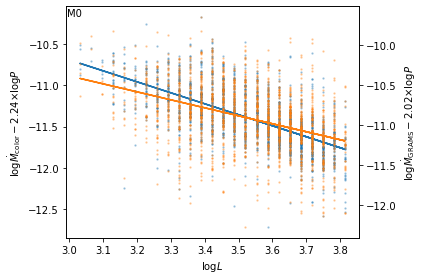

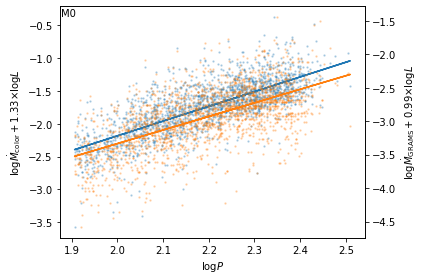

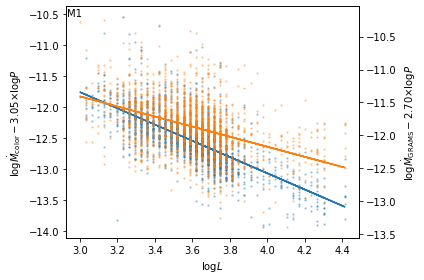

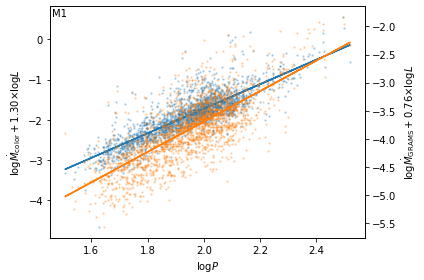

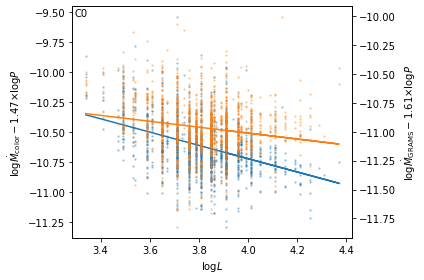

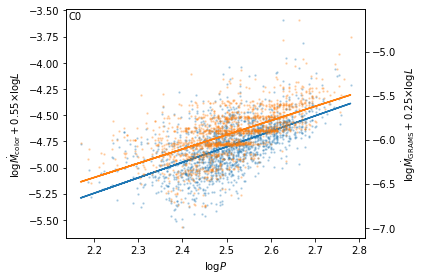

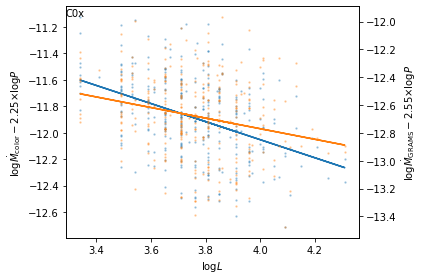

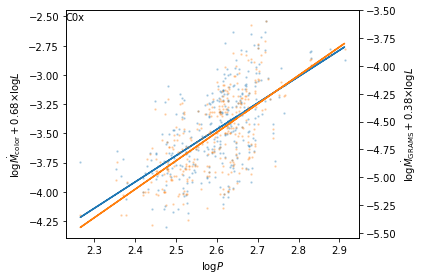

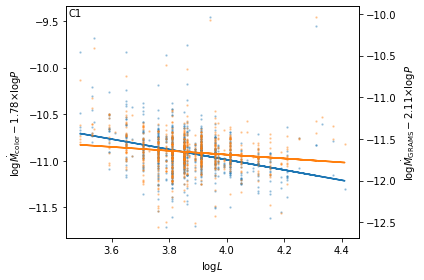

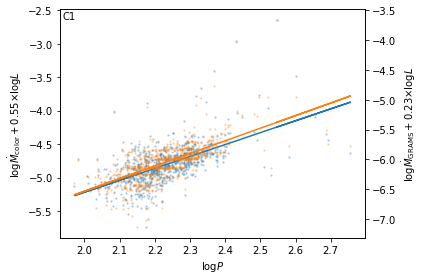

In [76]:
helpful_plots_different_mdot(M0_2Color_Data_JMinK, [M0_color_Mdot, np.log10(M0_2Color_Data_JMinK[MdotIndex])],star_type_label='M0')
helpful_plots_different_mdot(M1_2Color_Data_JMinK, [M1_color_Mdot, np.log10(M1_2Color_Data_JMinK[MdotIndex])],star_type_label='M1')
helpful_plots_different_mdot(C0_2Color_Data_JMinK, [C0_color_Mdot, np.log10(C0_2Color_Data_JMinK[MdotIndex])],star_type_label='C0')
helpful_plots_different_mdot(C0_x_reduced_for_K_minus_80, [C0x_color_Mdot, np.log10(C0_x_reduced_for_K_minus_80[MdotIndex])],star_type_label='C0x')
helpful_plots_different_mdot(C1_reduced_for_K_minus_80, [C1_color_Mdot, np.log10(C1_reduced_for_K_minus_80[MdotIndex])],star_type_label='C1')

In [77]:
Directory = 'Final_Fit/Color'

Fit 1: Multilinear of L,P vs provided Mdot
Fit: -6.67858928181519 - 1.3364753117545956 logL + 2.2467962489426236 logP
R^2: 0.33007930511614736
Standard Errors (x0 = logL, x1 = logP):
 Intercept    0.131573
x0           0.059460
x1           0.073025
dtype: float64


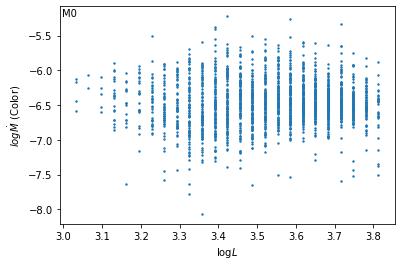

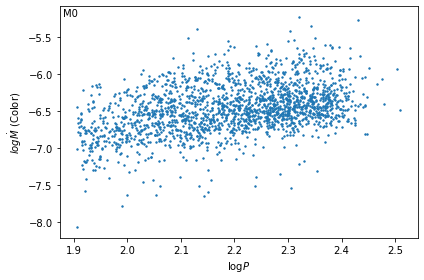

__________________________________________________________________________

Fit 2: Color Mdot vs Formula Mdot
form_vs_fed_Coeffs [2.70061751e-14 1.00000000e+00]


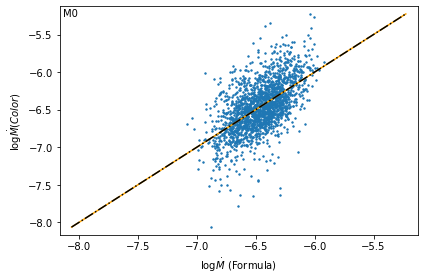

Quality of Fit Line:
Fit: logMdot_Color=0.000 + 1.000 * logMdot_Formula
R^2: 0.33007930511614736


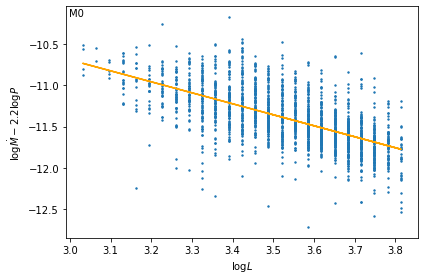

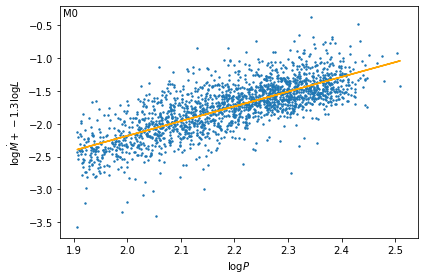

__________________________________________________________________________

Fit 3: Mdot Residual (Color-Formula) vs logL


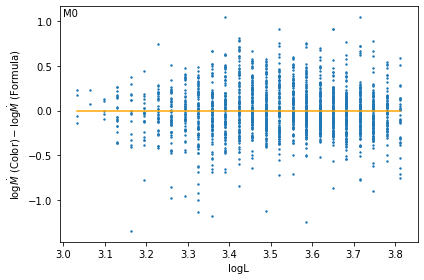

Quality of Residual Fit:
Fit: logMdot (Color) - logMdot (Formula)=0.000 + 0.000 * logL
R^2: 2.220446049250313e-16
__________________________________________________________________________

Fit 4: Mdot Residual (Color-Formula) vs logP


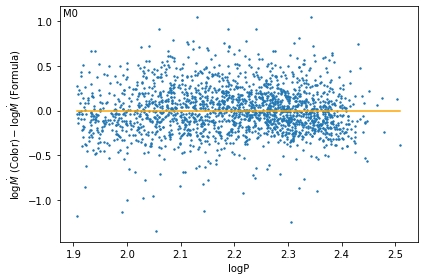

Quality of Residual Fit:
Fit: logMdot (Color) - logMdot (Formula)=0.000 + 0.000 * logP
R^2: 2.220446049250313e-16


In [78]:
LPCoeffsM0_color = do_final_fits(M0_2Color_Data_JMinK,M0_color_Mdot, fed_label = 'Color',star_type_label='M0')

Fit 1: Multilinear of L,P vs provided Mdot
Fit: -7.82531101743878 - 1.309643959262119 logL + 3.050816799380228 logP
R^2: 0.34955497777386024
Standard Errors (x0 = logL, x1 = logP):
 Intercept    0.108823
x0           0.076664
x1           0.113539
dtype: float64


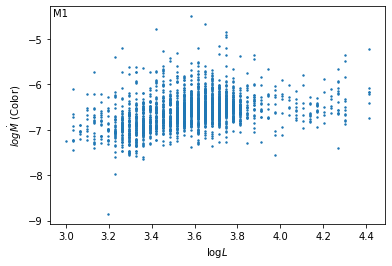

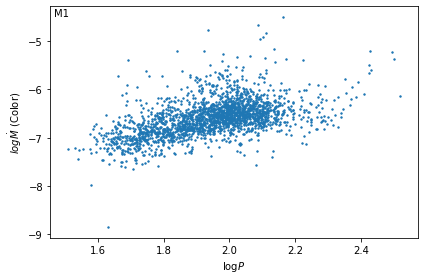

__________________________________________________________________________

Fit 2: Color Mdot vs Formula Mdot
form_vs_fed_Coeffs [-7.18730631e-14  1.00000000e+00]


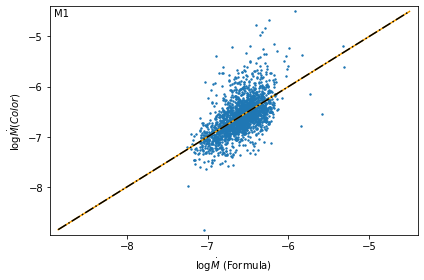

Quality of Fit Line:
Fit: logMdot_Color=-0.000 + 1.000 * logMdot_Formula
R^2: 0.3495549777738606


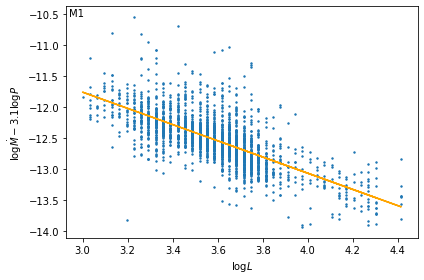

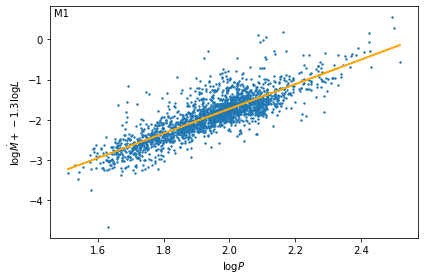

__________________________________________________________________________

Fit 3: Mdot Residual (Color-Formula) vs logL


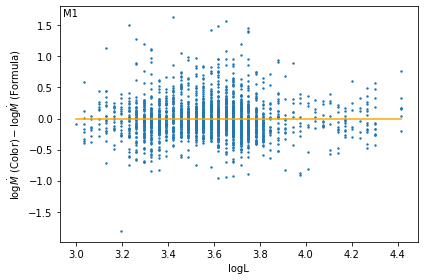

Quality of Residual Fit:
Fit: logMdot (Color) - logMdot (Formula)=0.000 + -0.000 * logL
R^2: -2.220446049250313e-16
__________________________________________________________________________

Fit 4: Mdot Residual (Color-Formula) vs logP


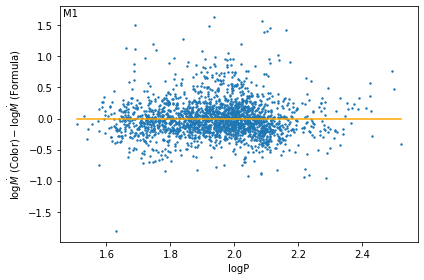

Quality of Residual Fit:
Fit: logMdot (Color) - logMdot (Formula)=0.000 + -0.000 * logP
R^2: -2.220446049250313e-16


In [79]:
LPCoeffsM1_color = do_final_fits(M1_2Color_Data_JMinK,M1_color_Mdot, fed_label = 'Color',star_type_label='M1')

Fit 1: Multilinear of L,P vs provided Mdot
Fit: -8.500134190801118 - 0.5556791651919251 logL + 1.4792793373292779 logP
R^2: 0.2084556389438036
Standard Errors (x0 = logL, x1 = logP):
 Intercept    0.133025
x0           0.045241
x1           0.072520
dtype: float64


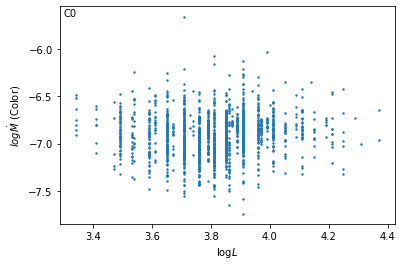

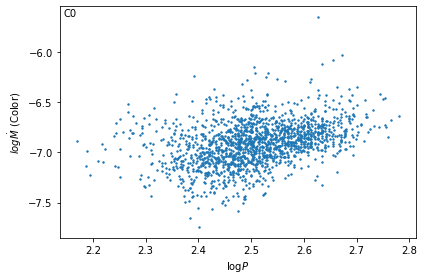

__________________________________________________________________________

Fit 2: Color Mdot vs Formula Mdot
form_vs_fed_Coeffs [-7.22755189e-14  1.00000000e+00]


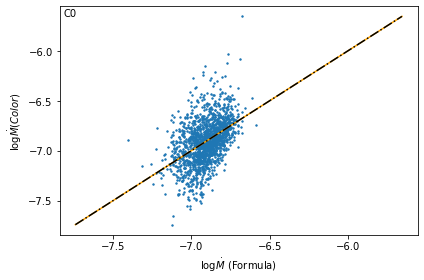

Quality of Fit Line:
Fit: logMdot_Color=-0.000 + 1.000 * logMdot_Formula
R^2: 0.20845563894380348


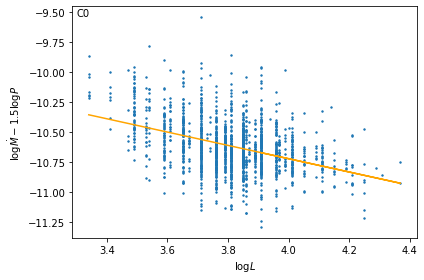

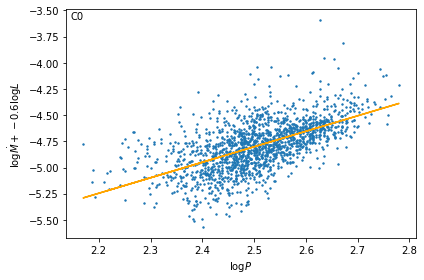

__________________________________________________________________________

Fit 3: Mdot Residual (Color-Formula) vs logL


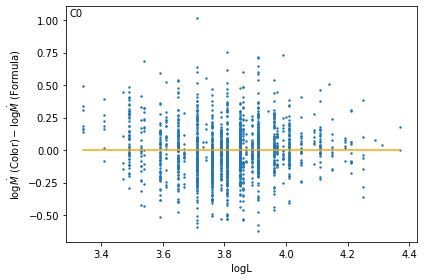

Quality of Residual Fit:
Fit: logMdot (Color) - logMdot (Formula)=0.000 + -0.000 * logL
R^2: 2.220446049250313e-16
__________________________________________________________________________

Fit 4: Mdot Residual (Color-Formula) vs logP


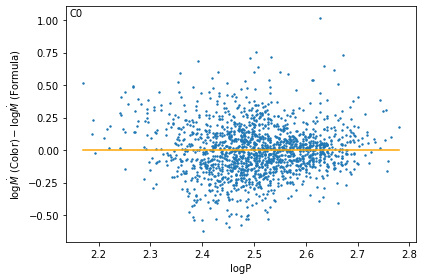

Quality of Residual Fit:
Fit: logMdot (Color) - logMdot (Formula)=0.000 + -0.000 * logP
R^2: 2.220446049250313e-16


In [80]:
LPCoeffsC0_color = do_final_fits(C0_2Color_Data_JMinK,C0_color_Mdot, fed_label = 'Color',star_type_label='C0')

Fit 1: Multilinear of L,P vs provided Mdot
Fit: -9.324503499052836 - 0.6820128549851897 logL + 2.253545643228248 logP
R^2: 0.1553231822979263
Standard Errors (x0 = logL, x1 = logP):
 Intercept    0.467437
x0           0.164895
x1           0.325843
dtype: float64


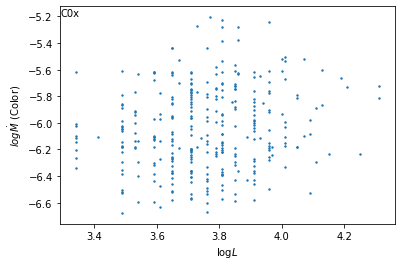

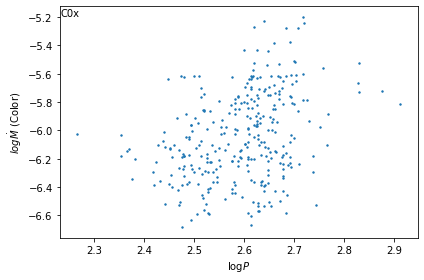

__________________________________________________________________________

Fit 2: Color Mdot vs Formula Mdot
form_vs_fed_Coeffs [4.4408921e-14 1.0000000e+00]


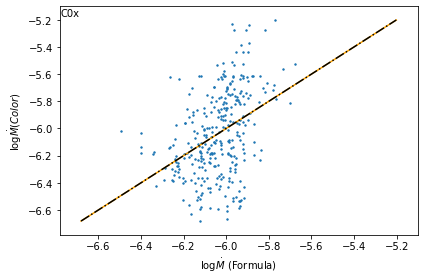

Quality of Fit Line:
Fit: logMdot_Color=0.000 + 1.000 * logMdot_Formula
R^2: 0.15532318229792663


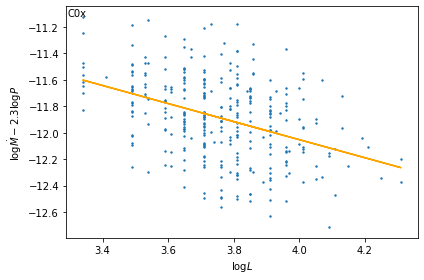

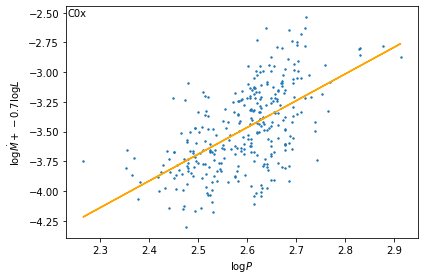

__________________________________________________________________________

Fit 3: Mdot Residual (Color-Formula) vs logL


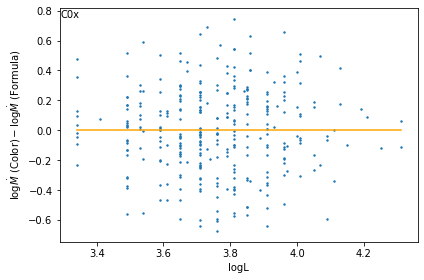

Quality of Residual Fit:
Fit: logMdot (Color) - logMdot (Formula)=-0.000 + 0.000 * logL
R^2: 0.0
__________________________________________________________________________

Fit 4: Mdot Residual (Color-Formula) vs logP


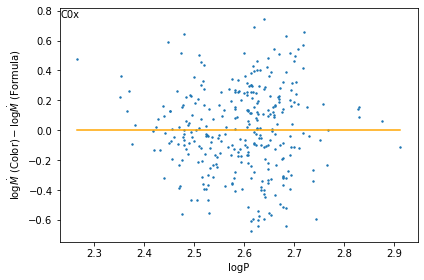

Quality of Residual Fit:
Fit: logMdot (Color) - logMdot (Formula)=-0.000 + 0.000 * logP
R^2: -2.220446049250313e-16


In [81]:
LPCoeffsC0x_color = do_final_fits(C0_x_reduced_for_K_minus_80,C0x_color_Mdot, fed_label = 'Color',star_type_label='C0x')

Fit 1: Multilinear of L,P vs provided Mdot
Fit: -8.781630351977357 - 0.5516118455772699 logL + 1.7812162590290297 logP
R^2: 0.24774516162799287
Standard Errors (x0 = logL, x1 = logP):
 Intercept    0.224824
x0           0.078527
x1           0.117028
dtype: float64


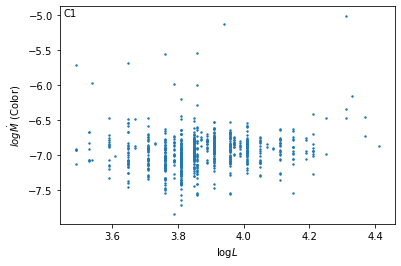

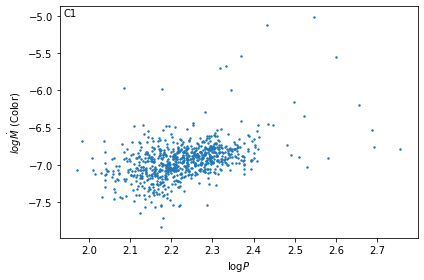

__________________________________________________________________________

Fit 2: Color Mdot vs Formula Mdot
form_vs_fed_Coeffs [1.18793864e-14 1.00000000e+00]


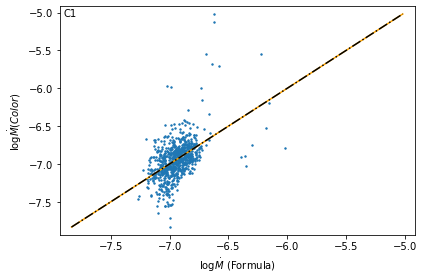

Quality of Fit Line:
Fit: logMdot_Color=0.000 + 1.000 * logMdot_Formula
R^2: 0.2477451616279931


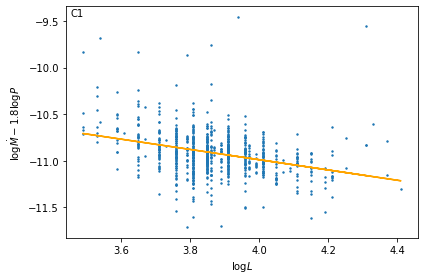

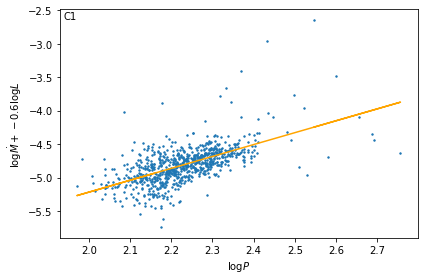

__________________________________________________________________________

Fit 3: Mdot Residual (Color-Formula) vs logL


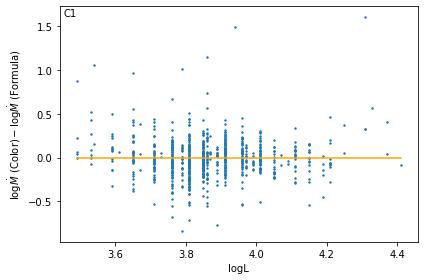

Quality of Residual Fit:
Fit: logMdot (Color) - logMdot (Formula)=0.000 + -0.000 * logL
R^2: 0.0
__________________________________________________________________________

Fit 4: Mdot Residual (Color-Formula) vs logP


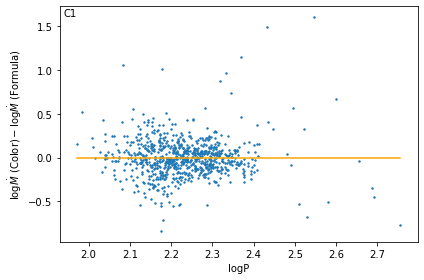

Quality of Residual Fit:
Fit: logMdot (Color) - logMdot (Formula)=0.000 + -0.000 * logP
R^2: 0.0


In [82]:
LPCoeffsC1_color = do_final_fits(C1_reduced_for_K_minus_80,C1_color_Mdot, fed_label = 'Color',star_type_label='C1')

In [83]:
Directory = 'Final_Fit/GRAMS'

Fit 1: Multilinear of L,P vs provided Mdot
Fit: -7.388158771513019 - 1.005665316322142 logL + 2.0387720751424845 logP
R^2: 0.20636545213502622
Standard Errors (x0 = logL, x1 = logP):
 Intercept    0.168589
x0           0.076281
x1           0.093964
dtype: float64


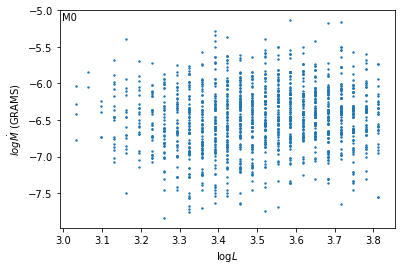

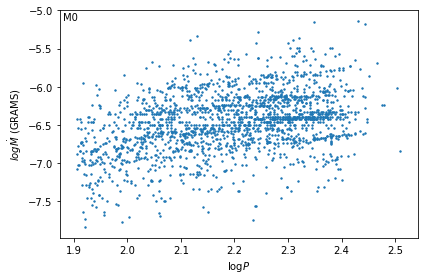

__________________________________________________________________________

Fit 2: GRAMS Mdot vs Formula Mdot
form_vs_fed_Coeffs [5.23331378e-14 1.00000000e+00]


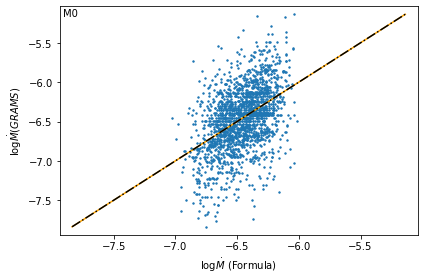

Quality of Fit Line:
Fit: logMdot_GRAMS=0.000 + 1.000 * logMdot_Formula
R^2: 0.206365452135026


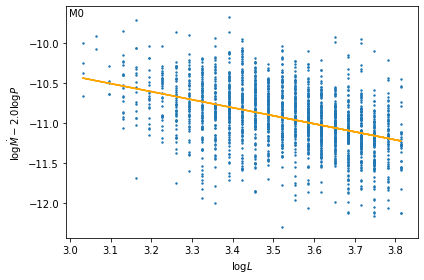

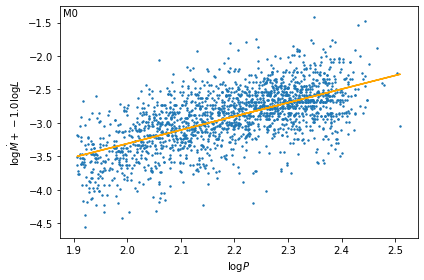

__________________________________________________________________________

Fit 3: Mdot Residual (GRAMS-Formula) vs logL


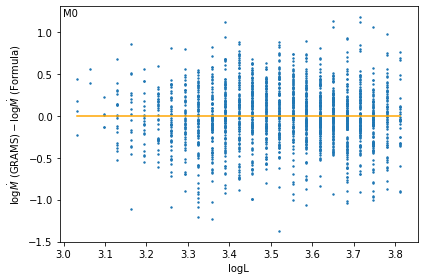

Quality of Residual Fit:
Fit: logMdot (GRAMS) - logMdot (Formula)=-0.000 + 0.000 * logL
R^2: 2.220446049250313e-16
__________________________________________________________________________

Fit 4: Mdot Residual (GRAMS-Formula) vs logP


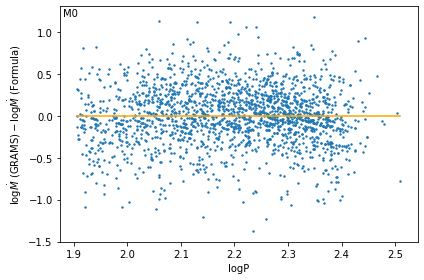

Quality of Residual Fit:
Fit: logMdot (GRAMS) - logMdot (Formula)=-0.000 + 0.000 * logP
R^2: 2.220446049250313e-16


In [84]:
LPCoeffsM0_GRAMS = do_final_fits(M0StarData,np.log10(M0StarData[MdotIndex]), fed_label = 'GRAMS',star_type_label='M0')

Fit 1: Multilinear of L,P vs provided Mdot
Fit: -9.089358285438802 - 0.7730420667303209 logL + 2.7128930575022596 logP
R^2: 0.34292097808195965
Standard Errors (x0 = logL, x1 = logP):
 Intercept    0.129781
x0           0.091410
x1           0.135346
dtype: float64


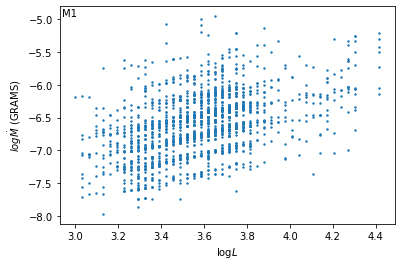

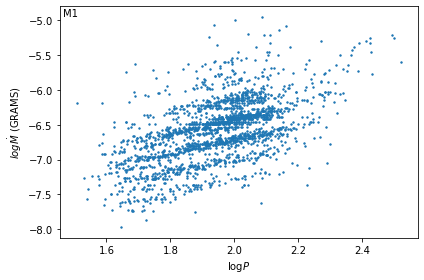

__________________________________________________________________________

Fit 2: GRAMS Mdot vs Formula Mdot
form_vs_fed_Coeffs [1.73194792e-14 1.00000000e+00]


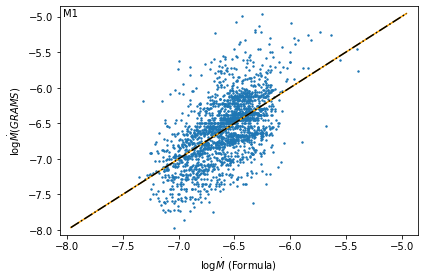

Quality of Fit Line:
Fit: logMdot_GRAMS=0.000 + 1.000 * logMdot_Formula
R^2: 0.34292097808195976


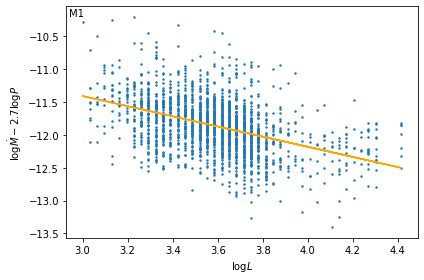

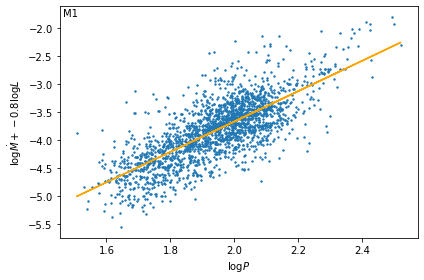

__________________________________________________________________________

Fit 3: Mdot Residual (GRAMS-Formula) vs logL


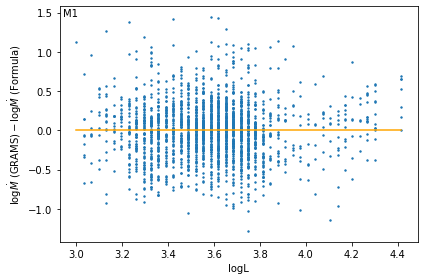

Quality of Residual Fit:
Fit: logMdot (GRAMS) - logMdot (Formula)=-0.000 + 0.000 * logL
R^2: -2.220446049250313e-16
__________________________________________________________________________

Fit 4: Mdot Residual (GRAMS-Formula) vs logP


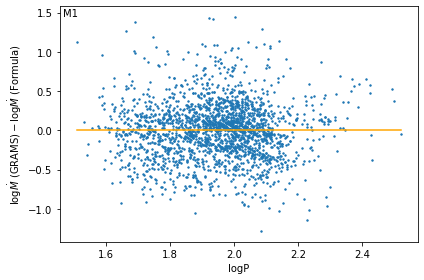

Quality of Residual Fit:
Fit: logMdot (GRAMS) - logMdot (Formula)=-0.000 + 0.000 * logP
R^2: 0.0


In [85]:
LPCoeffsM1_GRAMS = do_final_fits(M1StarData,np.log10(M1StarData[MdotIndex]), fed_label = 'GRAMS',star_type_label='M1')

Fit 1: Multilinear of L,P vs provided Mdot
Fit: -9.996397243650726 - 0.2789546923594095 logL + 1.6553157873965993 logP
R^2: 0.2707589145251824
Standard Errors (x0 = logL, x1 = logP):
 Intercept    0.146462
x0           0.049505
x1           0.079347
dtype: float64


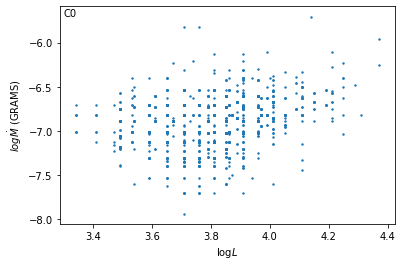

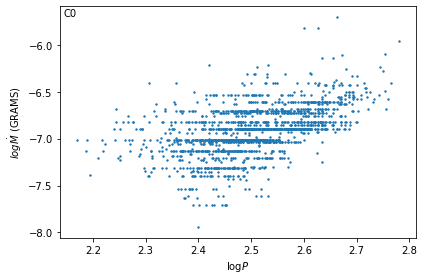

__________________________________________________________________________

Fit 2: GRAMS Mdot vs Formula Mdot
form_vs_fed_Coeffs [5.66213743e-15 1.00000000e+00]


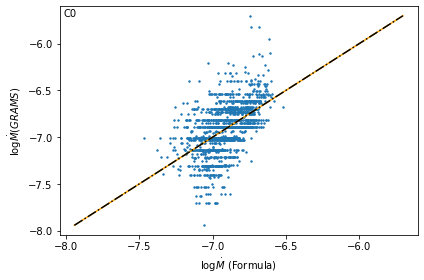

Quality of Fit Line:
Fit: logMdot_GRAMS=0.000 + 1.000 * logMdot_Formula
R^2: 0.2707589145251822


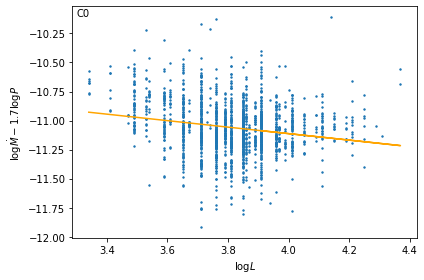

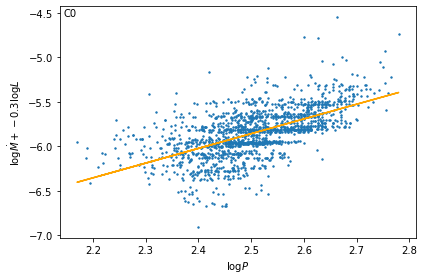

__________________________________________________________________________

Fit 3: Mdot Residual (GRAMS-Formula) vs logL


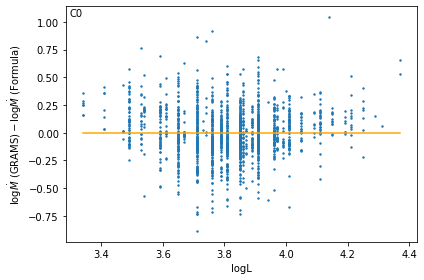

Quality of Residual Fit:
Fit: logMdot (GRAMS) - logMdot (Formula)=-0.000 + 0.000 * logL
R^2: -2.220446049250313e-16
__________________________________________________________________________

Fit 4: Mdot Residual (GRAMS-Formula) vs logP


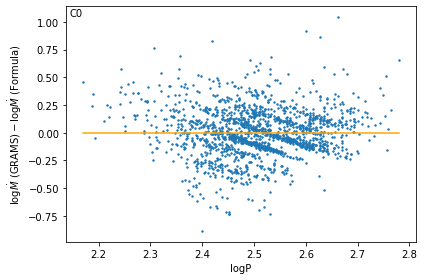

Quality of Residual Fit:
Fit: logMdot (GRAMS) - logMdot (Formula)=-0.000 + 0.000 * logP
R^2: -2.220446049250313e-16


In [86]:
LPCoeffsC0_GRAMS = do_final_fits(C0StarData_n,np.log10(C0StarData_n[MdotIndex]), fed_label = 'GRAMS',star_type_label='C0')

Fit 1: Multilinear of L,P vs provided Mdot
Fit: -11.462209794685188 - 0.2817162588472474 logL + 2.5037891787567554 logP
R^2: 0.30157616903474194
Standard Errors (x0 = logL, x1 = logP):
 Intercept    0.450097
x0           0.141329
x1           0.290497
dtype: float64


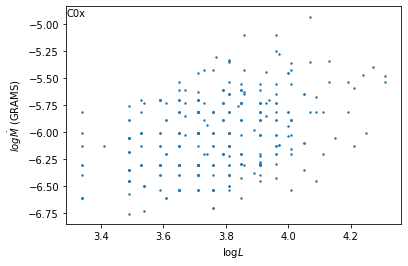

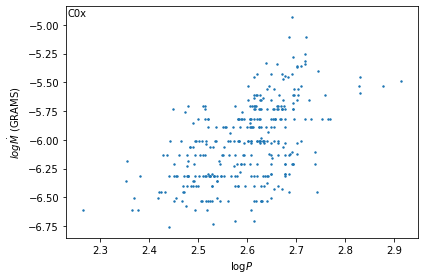

__________________________________________________________________________

Fit 2: GRAMS Mdot vs Formula Mdot
form_vs_fed_Coeffs [-1.98729921e-14  1.00000000e+00]


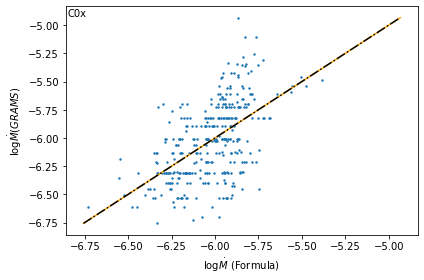

Quality of Fit Line:
Fit: logMdot_GRAMS=-0.000 + 1.000 * logMdot_Formula
R^2: 0.3015761690347418


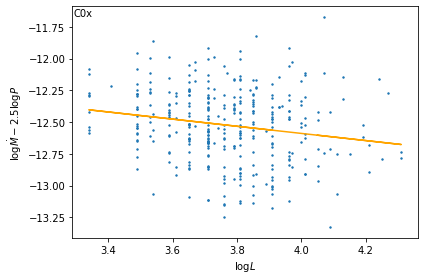

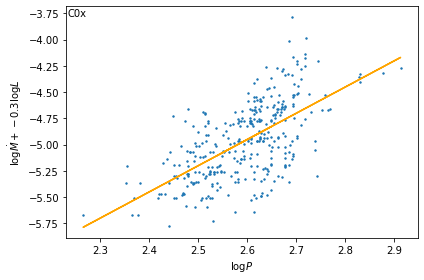

__________________________________________________________________________

Fit 3: Mdot Residual (GRAMS-Formula) vs logL


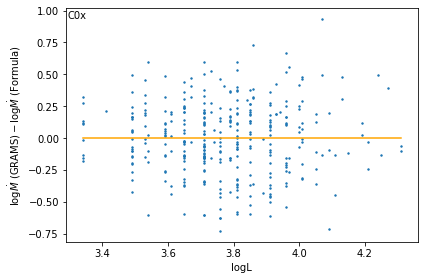

Quality of Residual Fit:
Fit: logMdot (GRAMS) - logMdot (Formula)=-0.000 + -0.000 * logL
R^2: 1.1102230246251565e-16
__________________________________________________________________________

Fit 4: Mdot Residual (GRAMS-Formula) vs logP


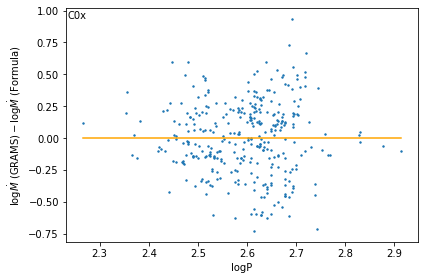

Quality of Residual Fit:
Fit: logMdot (GRAMS) - logMdot (Formula)=-0.000 + -0.000 * logP
R^2: 1.1102230246251565e-16


In [87]:
LPCoeffsC0x_GRAMS = do_final_fits(C0StarData_x,np.log10(C0StarData_x[MdotIndex]), fed_label = 'GRAMS',star_type_label='C0x')

Fit 1: Multilinear of L,P vs provided Mdot
Fit: -10.766834965320808 - 0.2240625182840398 logL + 2.103540946168206 logP
R^2: 0.38212210637017974
Standard Errors (x0 = logL, x1 = logP):
 Intercept    0.229507
x0           0.079929
x1           0.119122
dtype: float64


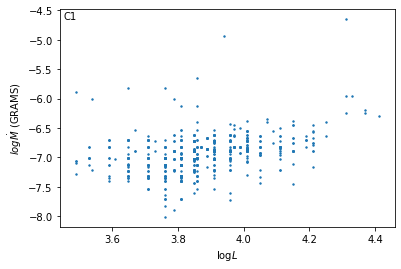

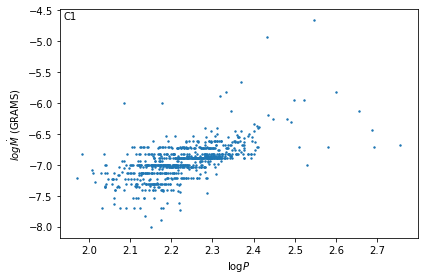

__________________________________________________________________________

Fit 2: GRAMS Mdot vs Formula Mdot
form_vs_fed_Coeffs [-3.88578059e-16  1.00000000e+00]


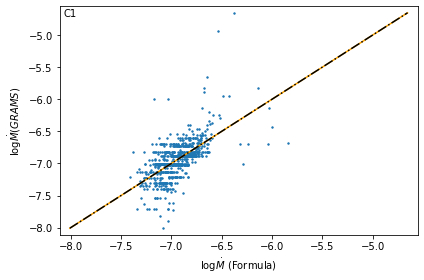

Quality of Fit Line:
Fit: logMdot_GRAMS=-0.000 + 1.000 * logMdot_Formula
R^2: 0.38212210637017974


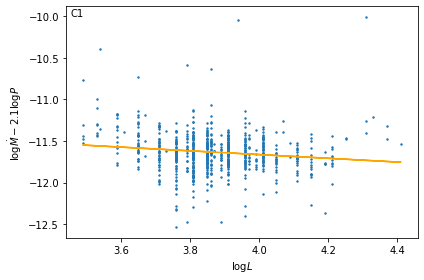

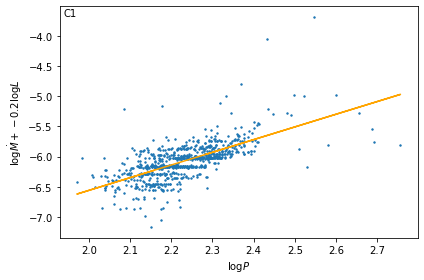

__________________________________________________________________________

Fit 3: Mdot Residual (GRAMS-Formula) vs logL


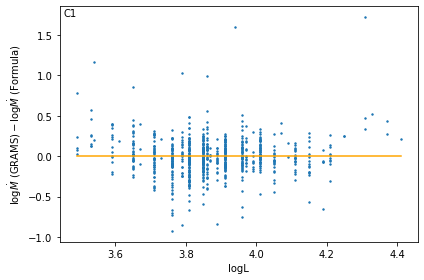

Quality of Residual Fit:
Fit: logMdot (GRAMS) - logMdot (Formula)=-0.000 + 0.000 * logL
R^2: -2.220446049250313e-16
__________________________________________________________________________

Fit 4: Mdot Residual (GRAMS-Formula) vs logP


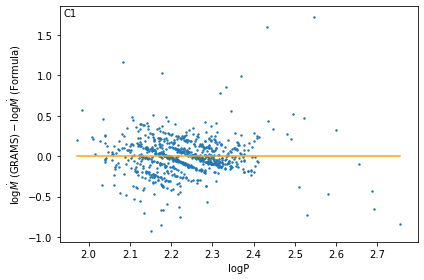

Quality of Residual Fit:
Fit: logMdot (GRAMS) - logMdot (Formula)=-0.000 + -0.000 * logP
R^2: -2.220446049250313e-16


In [88]:
LPCoeffsC1_GRAMS = do_final_fits(C1StarData,np.log10(C1StarData[MdotIndex]), fed_label = 'GRAMS',star_type_label='C1')

In [89]:
def find_formula_differentials (coeffs_1, coeffs_2, data_set,plot_title,debug=False):
    # Using two sets of coefficients with some matching property (mode or stellar composition), calculate the difference between
    # the predictions for the correct formula (using coeffs_1) and incorrect formula (coeffs_2). Then, plot this data.
    if debug == True:
        print('coeffs_1:', coeffs_1)
        print('coeffs_2:', coeffs_2)
        print('logL Range:',np.nanmax(np.log10(data_set[LIndex]))-np.nanmin(np.log10(data_set[LIndex])))
        print('coeffs_1[1] * logL Range:',coeffs_1[1]*np.nanmax(np.log10(data_set[LIndex]))-np.nanmin(np.log10(data_set[LIndex])))
        print('coeffs_2[1] * logL Range:',coeffs_2[1]*np.nanmax(np.log10(data_set[LIndex]))-np.nanmin(np.log10(data_set[LIndex])))
        print('logP Range:',np.nanmax(np.log10(data_set[PIndex]))-np.nanmin(np.log10(data_set[PIndex])))
        print('coeffs_1[2] * logP Range:',coeffs_1[2]*np.nanmax(np.log10(data_set[PIndex]))-np.nanmin(np.log10(data_set[PIndex])))
        print('coeffs_2[2] * logP Range:',coeffs_2[2]*np.nanmax(np.log10(data_set[PIndex]))-np.nanmin(np.log10(data_set[PIndex])))
    MdotPredict_1 = coeffs_1[0] + coeffs_1[1] * np.log10(data_set[LIndex]) + coeffs_1[2] * np.log10(data_set[PIndex])
    MdotPredict_2 = coeffs_2[0] + coeffs_2[1] * np.log10(data_set[LIndex]) + coeffs_2[2] * np.log10(data_set[PIndex])
    if debug == True:
        print ('MdotPredict_1:', MdotPredict_1)
        print ('MdotPredict_2:', MdotPredict_2)
    differential = np.log10(-(10**MdotPredict_1 - 10**MdotPredict_2))
    print(differential)
    limits = np.asarray([np.nanmin([np.nanmin(MdotPredict_1),np.nanmin(MdotPredict_2)]), np.nanmax([np.nanmax(MdotPredict_1),np.nanmax(MdotPredict_2)])])
    
    fig, ax = plt.subplots()
    plot.scatter(MdotPredict_1, differential,s = 2)
    #plot.plot([limits[0],limits[1]],[limits[0],limits[1]],color='black',linestyle='-.')
    #plot.xlim(limits[0]-0.1,limits[1]+0.1)
    #plot.ylim(limits[0]-0.1,limits[1]+0.1)
    plot.xlabel('logMdotPredict_1')
    plot.ylabel('np.log10(-(10**MdotPredict_1 - 10**MdotPredict_2))')
    plot.title(plot_title)
    plot.show()
    plot.close()
    
    return differential

coeffs_1: [-6.67858928 -1.33647531  2.24679625]
coeffs_2: [-7.82531102 -1.30964396  3.0508168 ]
logL Range: 0.7808980507099172
coeffs_1[1] * logL Range: -8.128348096441425
coeffs_2[1] * logL Range: -8.026037097213727
logP Range: 0.6027622000590196
coeffs_1[2] * logP Range: 3.731397458397538
coeffs_2[2] * logP Range: 5.748958102056156
MdotPredict_1: [-6.48688762 -6.33879996 -6.51841759 ... -6.64788219 -6.59446502
 -6.64022792]
MdotPredict_2: [-5.80332682 -5.47082699 -5.81327538 ... -6.02193361 -5.9329818
 -5.84724975]
[-5.9041761  -5.53407575 -5.90865595 ... -6.13919283 -6.03979185
 -5.9235254 ]


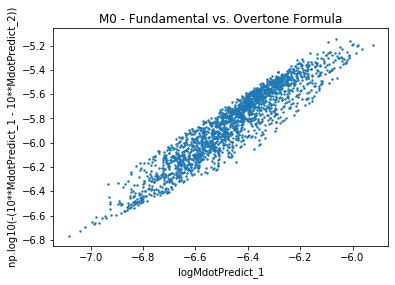

array([-5.9041761 , -5.53407575, -5.90865595, ..., -6.13919283,
       -6.03979185, -5.9235254 ])

In [90]:
find_formula_differentials(LPCoeffsM0_color, LPCoeffsM1_color, M0StarData,'M0 - Fundamental vs. Overtone Formula',debug=True)

In [91]:
def make_artificial_set (data, std_multiplier,grid_spacing = 50j,restrict_stars = False,restriction_labels=['','']):
    

    for i in range (0,len(data)):
        if i == 0:
            JoinedlogL = np.log10(data[i][LIndex])
            JoinedlogM = np.log10(data[i][MIndex])
            JoinedData = np.transpose(data[i])
        else:
            JoinedlogL = np.concatenate((JoinedlogL,np.log10(data[i][LIndex])))
            JoinedlogM = np.concatenate((JoinedlogM,np.log10(data[i][MIndex])))
            JoinedData = np.concatenate((JoinedData,np.transpose(data[i])))
    
            
    fit_line = chi_sq_fit_2d(JoinedlogL,JoinedlogM)[0]
    
    left_point = np.nanmin(JoinedlogL)
    right_point = np.nanmax(JoinedlogL)
    fit_x = np.asarray([left_point,right_point])
    fit_y = fit_line[0]+fit_line[1]*fit_x
    
    logL_Limits = []
    logM_Limits = []
    fitting_coeffs_and_bound_size = []
    
    for i in range(0, len(data)):
        if i == 0:
            set_label = 'M0'
        elif i == 1:
            set_label = 'M1'
        elif i == 2:
            set_label = 'C0'
        elif i == 3:
            set_label = 'C1'
        elif i == 4:
            set_label = 'C0x'
        
        star_data = data[i]
        # Take data, fit logM v logL (this line is the deathline)
        deathline_fit = linear_fit_1var(np.log10(star_data[LIndex]),np.log10(star_data[MIndex]))
        deathline_coeffs = deathline_fit[0]
        np.nanstd(np.log10(star_data[MIndex]))
        # Plot logM v logL and fit line for checking
        line_x_vals = np.asarray([np.nanmin(np.log10(star_data[LIndex])),np.nanmax(np.log10(star_data[LIndex]))])
        line_y_vals = deathline_coeffs[0] + deathline_coeffs[1]*line_x_vals
        #bound_size = std_multiplier*np.nanstd(np.log10(star_data[MIndex]))
        stnd_dev_around_DL = np.nanstd(np.log10(star_data[MIndex])-deathline_coeffs[0]-deathline_coeffs[1]*np.log10(star_data[LIndex]))
        print('sigmaDL=',stnd_dev_around_DL)
        # Take the Standard Deviation around the deathline to be the standard deviation of the difference between the dependent logM and the fit of logL
        bound_size = std_multiplier*stnd_dev_around_DL*np.cos(np.arctan(deathline_coeffs[1]))
            
        plot.scatter(np.log10(data[i][LIndex]),np.log10(data[i][MIndex]),s=2,label=set_label)
        #plot.plot(fit_x, fit_y,color = 'black')
        #plot.plot(fit_x, fit_y+bound_size,color = 'black')
        #plot.plot(fit_x, fit_y-bound_size,color = 'black')
        plot.xlabel('logL')
        plot.ylabel('logM')
        plot.title('Input Data ('+set_label+')')
        #plot.legend()
        plot.savefig('Final_Fit/Artificial_Input_'+set_label+'.png')
        plot.savefig('Final_Fit/Artificial_Input_'+set_label+'.pdf')
        plot.show()
        plot.close()
        logL_Limits.append([np.nanmin(np.log10(star_data[LIndex])),np.nanmax(np.log10(star_data[LIndex]))])
        logM_Limits.append([np.nanmin(np.log10(star_data[MIndex])),np.nanmax(np.log10(star_data[MIndex]))])
        fitting_coeffs_and_bound_size.append([deathline_coeffs[0],deathline_coeffs[1],bound_size])
    
    for i in range(0, len(data)):
        if i == 0:
            set_label = 'M0'
        elif i == 1:
            set_label = 'M1'
        elif i == 2:
            set_label = 'C0'
        elif i == 3:
            set_label = 'C1'
        elif i == 4:
            set_label = 'C0x'
        plot.scatter(np.log10(data[i][LIndex]),np.log10(data[i][MIndex]),s=2,label=set_label)
        
    
    star_data = np.transpose(JoinedData)
    # Take data, fit logM v logL (this line is the deathline)
    deathline_fit = linear_fit_1var(np.log10(star_data[LIndex]),np.log10(star_data[MIndex]))
    deathline_coeffs = deathline_fit[0]
    np.nanstd(np.log10(star_data[MIndex]))
    # Plot logM v logL and fit line for checking
    line_x_vals = np.asarray([np.nanmin(np.log10(star_data[LIndex])),np.nanmax(np.log10(star_data[LIndex]))])
    line_y_vals = deathline_coeffs[0] + deathline_coeffs[1]*line_x_vals
    #bound_size = std_multiplier*np.nanstd(np.log10(star_data[MIndex]))
    stnd_dev_around_DL = np.nanstd(np.log10(star_data[MIndex])-deathline_coeffs[0]-deathline_coeffs[1]*np.log10(star_data[LIndex]))
    print('sigmaDL=',stnd_dev_around_DL)
    # Take the Standard Deviation around the deathline to be the standard deviation of the difference between the dependent logM and the fit of logL
    bound_size = std_multiplier*stnd_dev_around_DL*np.cos(np.arctan(deathline_coeffs[1]))
    
    print('bound_size:',bound_size)
    
    #plot.plot(fit_x, fit_y,color = 'black')
    #plot.plot(fit_x, fit_y+bound_size,color = 'black')
    #plot.plot(fit_x, fit_y-bound_size,color = 'black')
    plot.xlabel('logL')
    plot.ylabel('logM')
    plot.title('Input Data')
    plot.legend()
    plot.savefig('Final_Fit/Artificial_Input.png')
    plot.savefig('Final_Fit/Artificial_Input.pdf')
    plot.show()
    plot.close()
    
    # Generate Grid of stars
    LGrid = np.mgrid[np.nanmin(JoinedlogL):np.nanmax(JoinedlogL):grid_spacing]
    MGrid = np.mgrid[np.nanmin(JoinedlogM)-bound_size:np.nanmax(JoinedlogM)+bound_size:grid_spacing]
    print(MGrid)
    
    LValues = []
    i = 0
    while i < len(LGrid):
        current_L = np.full(int(np.abs(grid_spacing)),LGrid[i])
        if i==0:
            LValues = current_L
        else:
            LValues = np.concatenate((LValues,current_L))
        i +=1
    MValues = []
    i = 0
    while i <len(MGrid):
        if i==0:
            MValues = MGrid
        else:
            MValues = np.concatenate((MValues,MGrid))
        i += 1
    LM_Grid = np.vstack((LValues,MValues))
    # Now, trim the grid using the information from the best fit line
    working_grid = np.transpose(LM_Grid)
    i = 0
    delete_list = []
    for i in range(0,len(working_grid)):
        if working_grid[i][1] > fit_line[0]+fit_line[1]*working_grid[i][0] + bound_size:
            delete_list.append(i) # mark for deletion 
        elif working_grid[i][1] < fit_line[0]+fit_line[1]*working_grid[i][0] - bound_size:
            delete_list.append(i) # mark for deletion
        elif working_grid[i][1] < np.log10(0.5):
            delete_list.append(i) # mark for deletion
        elif working_grid[i][1] > np.log10(2.5):
            delete_list.append(i) # mark for deletion
    working_grid_clean = np.delete(working_grid,delete_list,axis=0)
    LM_Grid = np.transpose(working_grid_clean)               
    print('Number of Artifical Points:', np.shape(LM_Grid)[1])
    print('LM_Grid[0]:',LM_Grid[0])
    print('LM_Grid[1]:',LM_Grid[1])
    '''
    # create data sets of constant mass
    checked_log_m_array = []
    working_log_m = 0
    proceed = False
    constant_mass_lists = []
    i = 0
    while i < len(LM_Grid[1]):
        indices_of_current_mass = []
        if i == 0:
            checked_log_m_array.append(LM_Grid[1][0])
            working_log_m = LM_Grid[1][0]
            for k in range(0, len(LM_Grid[1])):
                if working_log_m == LM_Grid[1][k]:
                    indices_of_current_mass.append(k)
            constant_mass_lists.append(indices_of_current_mass)
        else:
            working_log_m = LM_Grid[1][i]
            for k in range(0, len(checked_log_m_array)):
                if working_log_m == checked_log_m_array[k]:
                    proceed = False
                    break
                else:
                    proceed = True
            if proceed == True:
                for l in range(0, len(LM_Grid[1])):
                    checked_log_m_array.append(LM_Grid[1][i])
                    if working_log_m == LM_Grid[1][l]:
                        indices_of_current_mass.append(l)
                constant_mass_lists.append(indices_of_current_mass)
        #print('i:',i)
        i += 1
    #print('constant_mass_lists:',constant_mass_lists)
    i = 0
    constant_mass_arrays = []
    for i in range(0, len(constant_mass_lists)):
        constant_mass_arrays.append(np.transpose(np.transpose(LM_Grid)[constant_mass_lists[i]]))
    #print(constant_mass_arrays)
    '''
    
    
    plot.scatter(LM_Grid[0],LM_Grid[1],s=2)
    plot.plot(fit_x, fit_y,color = 'black')
    plot.plot(fit_x, fit_y+bound_size,color = 'black')
    plot.plot(fit_x, fit_y-bound_size,color = 'black')
    plot.xlabel('logL')
    plot.ylabel('logM')
    plot.title('Output Data')
    plot.savefig('Final_Fit/Artificial_Output.png')
    plot.savefig('Final_Fit/Artificial_Output.pdf')
    plot.show()
    plot.close()
    '''
    # Finally, examine the period for consistencey
    for i in range(0, len(data)):
        plot.scatter(np.log10(data[i][PIndex]),np.log10(data[i][LIndex]),s=2)
    plot.ylabel('logL')
    plot.xlabel('logP')
    plot.title('Input Data')
    plot.show()
    plot.close()
    
    for i in range(0, len(data)):
        plot.scatter(10**(np.log10(data[i][PIndex])),np.log10(data[i][LIndex]),s=2)
    plot.ylabel('logL')
    plot.xlabel('P')
    plot.title('Input Data')
    plot.show()
    plot.close()
    '''
    if restrict_stars == True:
        print('Warning: Restricted data set assumes entry order (M0, M1, C0, C1) for input data.')
        print('logL_Limits:',logL_Limits)
        print('logM_Limits:',logM_Limits)
        new_LGrid = LM_Grid[0]
        new_MGrid = LM_Grid[1]
        for i in range (0, len(restriction_labels)):
            if restriction_labels[i] == 'M0':
                # Cut 1: Remove points outside the range of values for these stars.
                logLGT = np.where(new_LGrid < logL_Limits[0][0])[0]
                logLLT = np.where(new_LGrid > logL_Limits[0][1])[0]
                logMGT = np.where(new_MGrid < logM_Limits[0][0])[0]
                logMLT = np.where(new_MGrid > logM_Limits[0][1])[0]
                indices_to_Cut = np.unique(np.concatenate((logLGT, logLLT, logMGT, logMLT)))
                new_LGrid = np.delete(new_LGrid,indices_to_Cut)
                new_MGrid = np.delete(new_MGrid,indices_to_Cut)
                
                # Cut 2: Remove all stars outside the bounding regions for a given set
                above_region = np.where(new_MGrid > fitting_coeffs_and_bound_size[0][0] 
                                        + fitting_coeffs_and_bound_size[0][1]*new_LGrid + fitting_coeffs_and_bound_size[0][2])[0]
                below_region = np.where(new_MGrid < fitting_coeffs_and_bound_size[0][0] 
                                        + fitting_coeffs_and_bound_size[0][1]*new_LGrid - fitting_coeffs_and_bound_size[0][2])[0]
                indices_to_Cut = np.unique(np.concatenate((above_region, below_region)))
                new_LGrid = np.delete(new_LGrid,indices_to_Cut)
                new_MGrid = np.delete(new_MGrid,indices_to_Cut)
            elif restriction_labels[i] == 'M1':
                # Cut 1: Remove points outside the range of values for these stars.
                logLGT = np.where(new_LGrid < logL_Limits[1][0])[0]
                logLLT = np.where(new_LGrid > logL_Limits[1][1])[0]
                logMGT = np.where(new_MGrid < logM_Limits[1][0])[0]
                logMLT = np.where(new_MGrid > logM_Limits[1][1])[0]
                indices_to_Cut = np.unique(np.concatenate((logLGT, logLLT, logMGT, logMLT)))
                new_LGrid = np.delete(new_LGrid,indices_to_Cut)
                new_MGrid = np.delete(new_MGrid,indices_to_Cut)
                
                # Cut 2: Remove all stars outside the bounding regions for a given set
                above_region = np.where(new_MGrid > fitting_coeffs_and_bound_size[1][0] 
                                        + fitting_coeffs_and_bound_size[1][1]*new_LGrid + fitting_coeffs_and_bound_size[1][2])[0]
                below_region = np.where(new_MGrid < fitting_coeffs_and_bound_size[1][0] 
                                        + fitting_coeffs_and_bound_size[1][1]*new_LGrid - fitting_coeffs_and_bound_size[1][2])[0]
                indices_to_Cut = np.unique(np.concatenate((above_region, below_region)))
                new_LGrid = np.delete(new_LGrid,indices_to_Cut)
                new_MGrid = np.delete(new_MGrid,indices_to_Cut)
            elif restriction_labels[i] == 'C0':
                # Cut 1: Remove points outside the range of values for these stars.
                logLGT = np.where(new_LGrid < logL_Limits[2][0])[0]
                logLLT = np.where(new_LGrid > logL_Limits[2][1])[0]
                logMGT = np.where(new_MGrid < logM_Limits[2][0])[0]
                logMLT = np.where(new_MGrid > logM_Limits[2][1])[0]
                indices_to_Cut = np.unique(np.concatenate((logLGT, logLLT, logMGT, logMLT)))
                new_LGrid = np.delete(new_LGrid,indices_to_Cut)
                new_MGrid = np.delete(new_MGrid,indices_to_Cut)
                
                # Cut 2: Remove all stars outside the bounding regions for a given set
                above_region = np.where(new_MGrid > fitting_coeffs_and_bound_size[2][0] 
                                        + fitting_coeffs_and_bound_size[2][1]*new_LGrid + fitting_coeffs_and_bound_size[2][2])[0]
                below_region = np.where(new_MGrid < fitting_coeffs_and_bound_size[2][0] 
                                        + fitting_coeffs_and_bound_size[2][1]*new_LGrid - fitting_coeffs_and_bound_size[2][2])[0]
                indices_to_Cut = np.unique(np.concatenate((above_region, below_region)))
                new_LGrid = np.delete(new_LGrid,indices_to_Cut)
                new_MGrid = np.delete(new_MGrid,indices_to_Cut)
            elif restriction_labels[i] == 'C1':
                # Cut 1: Remove points outside the range of values for these stars.
                logLGT = np.where(new_LGrid < logL_Limits[3][0])[0]
                logLLT = np.where(new_LGrid > logL_Limits[3][1])[0]
                logMGT = np.where(new_MGrid < logM_Limits[3][0])[0]
                logMLT = np.where(new_MGrid > logM_Limits[3][1])[0]
                indices_to_Cut = np.unique(np.concatenate((logLGT, logLLT, logMGT, logMLT)))
                new_LGrid = np.delete(new_LGrid,indices_to_Cut)
                new_MGrid = np.delete(new_MGrid,indices_to_Cut)
                
                # Cut 2: Remove all stars outside the bounding regions for a given set
                above_region = np.where(new_MGrid > fitting_coeffs_and_bound_size[3][0] 
                                        + fitting_coeffs_and_bound_size[3][1]*new_LGrid + fitting_coeffs_and_bound_size[3][2])[0]
                below_region = np.where(new_MGrid < fitting_coeffs_and_bound_size[3][0] 
                                        + fitting_coeffs_and_bound_size[3][1]*new_LGrid - fitting_coeffs_and_bound_size[3][2])[0]
                indices_to_Cut = np.unique(np.concatenate((above_region, below_region)))
                new_LGrid = np.delete(new_LGrid,indices_to_Cut)
                new_MGrid = np.delete(new_MGrid,indices_to_Cut)
            else:
                print('Error. Label not found.')
        new_LM_grid = np.vstack((new_LGrid,new_MGrid))
        
        plot.scatter(new_LM_grid[0],new_LM_grid[1],s=2)
        plot.plot(fit_x, fit_y,color = 'black')
        plot.plot(fit_x, fit_y+bound_size,color = 'black')
        plot.plot(fit_x, fit_y-bound_size,color = 'black')
        plot.xlabel('logL')
        plot.ylabel('logM')
        plot.title('Output Data')
        #plot.savefig('Final_Fit/Artificial_Output.png')
        #plot.savefig('Final_Fit/Artificial_Output.pdf')
        plot.show()
        plot.close()
        
        LM_Grid = new_LM_grid
        
        
    return LM_Grid

sigmaDL= 0.06519024127945568


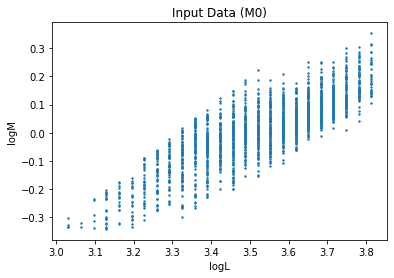

sigmaDL= 0.06192636262963603


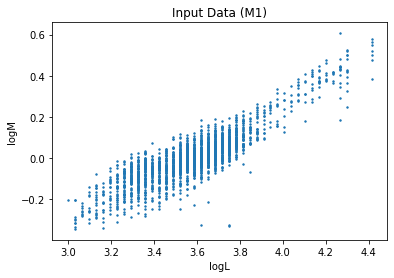

sigmaDL= 0.04833065042469314


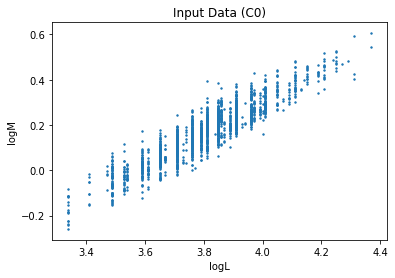

sigmaDL= 0.06220216929796503


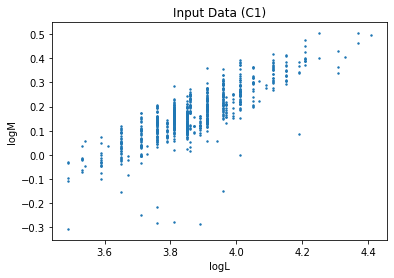

sigmaDL= 0.06381699617454836
bound_size: 0.16636321460903788


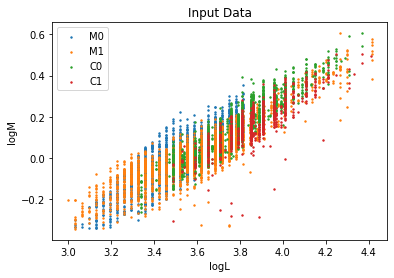

[-0.51255116 -0.49515893 -0.4777667  -0.46037447 -0.44298224 -0.42559001
 -0.40819778 -0.39080555 -0.37341332 -0.35602108 -0.33862885 -0.32123662
 -0.30384439 -0.28645216 -0.26905993 -0.2516677  -0.23427547 -0.21688324
 -0.19949101 -0.18209878 -0.16470655 -0.14731432 -0.12992208 -0.11252985
 -0.09513762 -0.07774539 -0.06035316 -0.04296093 -0.0255687  -0.00817647
  0.00921576  0.02660799  0.04400022  0.06139245  0.07878468  0.09617691
  0.11356915  0.13096138  0.14835361  0.16574584  0.18313807  0.2005303
  0.21792253  0.23531476  0.25270699  0.27009922  0.28749145  0.30488368
  0.32227591  0.33966815  0.35706038  0.37445261  0.39184484  0.40923707
  0.4266293   0.44402153  0.46141376  0.47880599  0.49619822  0.51359045
  0.53098268  0.54837491  0.56576715  0.58315938  0.60055161  0.61794384
  0.63533607  0.6527283   0.67012053  0.68751276  0.70490499  0.72229722
  0.73968945  0.75708168  0.77447391]
Number of Artifical Points: 1153
LM_Grid[0]: [3.         3.         3.         ... 4.41

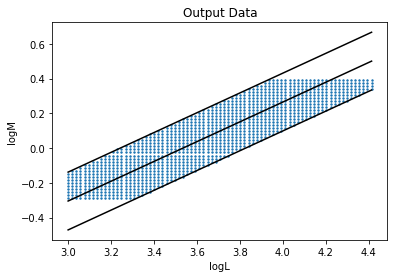

logL_Limits: [[3.0322157032979815, 3.8131137540078988], [3.0, 4.414287958434695], [3.339848783037637, 4.369994661608428], [3.4899584794248346, 4.409983816226542]]
logM_Limits: [[-0.34116528211482455, 0.3529753019135413], [-0.34618794722709323, 0.6081107001981967], [-0.26006819636361916, 0.6061396141442832], [-0.30718579455718587, 0.5043212412290314]]


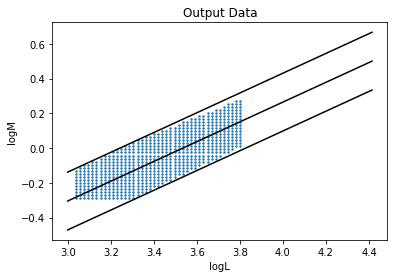

In [92]:
artifical_set_M_stars = make_artificial_set([M0StarData,M1StarData,C0StarData,C1StarData],3,grid_spacing = 75j,restrict_stars = True,restriction_labels=['M0','M1'])

sigmaDL= 0.06519024127945568


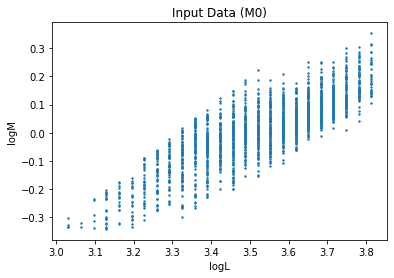

sigmaDL= 0.06192636262963603


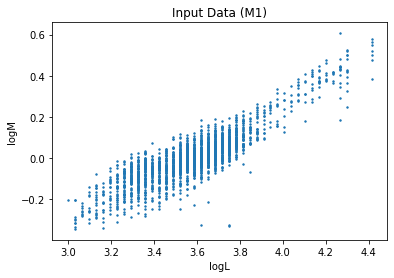

sigmaDL= 0.04833065042469314


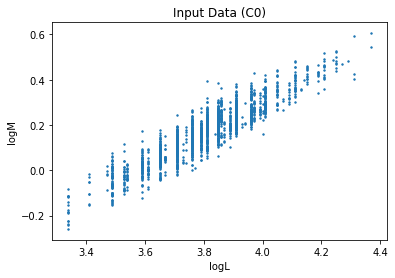

sigmaDL= 0.06220216929796503


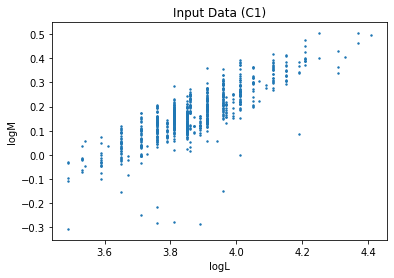

sigmaDL= 0.06381699617454836
bound_size: 0.16636321460903788


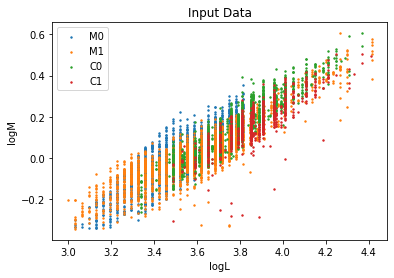

[-0.51255116 -0.49515893 -0.4777667  -0.46037447 -0.44298224 -0.42559001
 -0.40819778 -0.39080555 -0.37341332 -0.35602108 -0.33862885 -0.32123662
 -0.30384439 -0.28645216 -0.26905993 -0.2516677  -0.23427547 -0.21688324
 -0.19949101 -0.18209878 -0.16470655 -0.14731432 -0.12992208 -0.11252985
 -0.09513762 -0.07774539 -0.06035316 -0.04296093 -0.0255687  -0.00817647
  0.00921576  0.02660799  0.04400022  0.06139245  0.07878468  0.09617691
  0.11356915  0.13096138  0.14835361  0.16574584  0.18313807  0.2005303
  0.21792253  0.23531476  0.25270699  0.27009922  0.28749145  0.30488368
  0.32227591  0.33966815  0.35706038  0.37445261  0.39184484  0.40923707
  0.4266293   0.44402153  0.46141376  0.47880599  0.49619822  0.51359045
  0.53098268  0.54837491  0.56576715  0.58315938  0.60055161  0.61794384
  0.63533607  0.6527283   0.67012053  0.68751276  0.70490499  0.72229722
  0.73968945  0.75708168  0.77447391]
Number of Artifical Points: 1153
LM_Grid[0]: [3.         3.         3.         ... 4.41

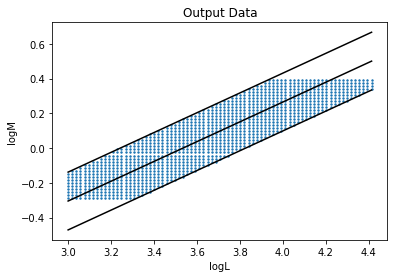

logL_Limits: [[3.0322157032979815, 3.8131137540078988], [3.0, 4.414287958434695], [3.339848783037637, 4.369994661608428], [3.4899584794248346, 4.409983816226542]]
logM_Limits: [[-0.34116528211482455, 0.3529753019135413], [-0.34618794722709323, 0.6081107001981967], [-0.26006819636361916, 0.6061396141442832], [-0.30718579455718587, 0.5043212412290314]]


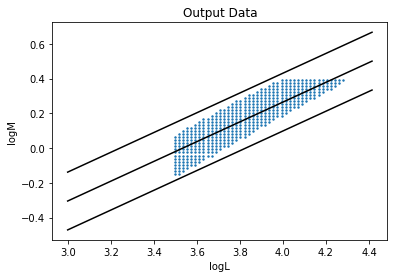

In [93]:
artifical_set_C_stars = make_artificial_set([M0StarData,M1StarData,C0StarData,C1StarData],3,grid_spacing = 75j,restrict_stars = True,restriction_labels=['C0','C1'])

sigmaDL= 0.06519024127945568


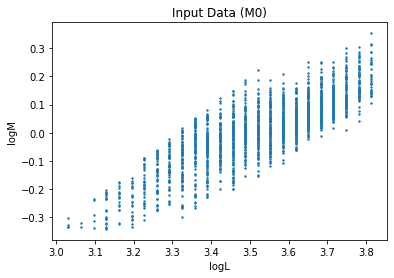

sigmaDL= 0.06192636262963603


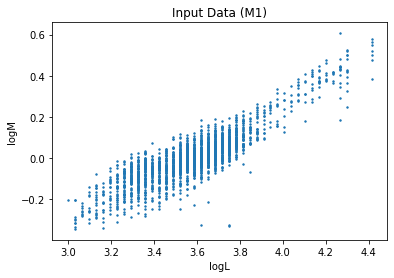

sigmaDL= 0.04833065042469314


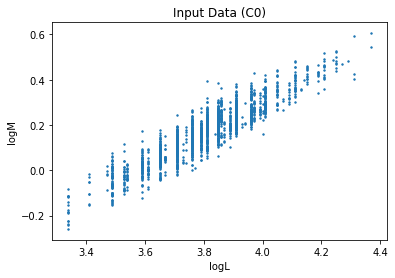

sigmaDL= 0.06220216929796503


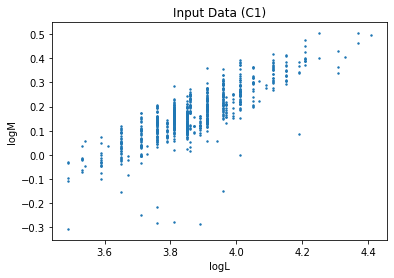

sigmaDL= 0.06381699617454836
bound_size: 0.16636321460903788


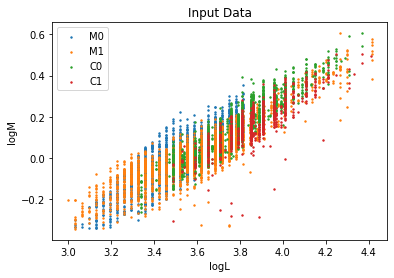

[-0.51255116 -0.49515893 -0.4777667  -0.46037447 -0.44298224 -0.42559001
 -0.40819778 -0.39080555 -0.37341332 -0.35602108 -0.33862885 -0.32123662
 -0.30384439 -0.28645216 -0.26905993 -0.2516677  -0.23427547 -0.21688324
 -0.19949101 -0.18209878 -0.16470655 -0.14731432 -0.12992208 -0.11252985
 -0.09513762 -0.07774539 -0.06035316 -0.04296093 -0.0255687  -0.00817647
  0.00921576  0.02660799  0.04400022  0.06139245  0.07878468  0.09617691
  0.11356915  0.13096138  0.14835361  0.16574584  0.18313807  0.2005303
  0.21792253  0.23531476  0.25270699  0.27009922  0.28749145  0.30488368
  0.32227591  0.33966815  0.35706038  0.37445261  0.39184484  0.40923707
  0.4266293   0.44402153  0.46141376  0.47880599  0.49619822  0.51359045
  0.53098268  0.54837491  0.56576715  0.58315938  0.60055161  0.61794384
  0.63533607  0.6527283   0.67012053  0.68751276  0.70490499  0.72229722
  0.73968945  0.75708168  0.77447391]
Number of Artifical Points: 1153
LM_Grid[0]: [3.         3.         3.         ... 4.41

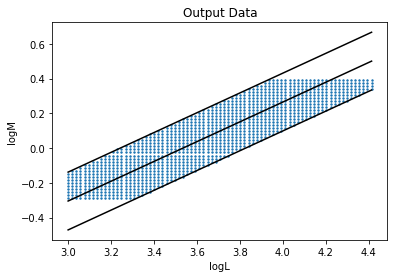

logL_Limits: [[3.0322157032979815, 3.8131137540078988], [3.0, 4.414287958434695], [3.339848783037637, 4.369994661608428], [3.4899584794248346, 4.409983816226542]]
logM_Limits: [[-0.34116528211482455, 0.3529753019135413], [-0.34618794722709323, 0.6081107001981967], [-0.26006819636361916, 0.6061396141442832], [-0.30718579455718587, 0.5043212412290314]]


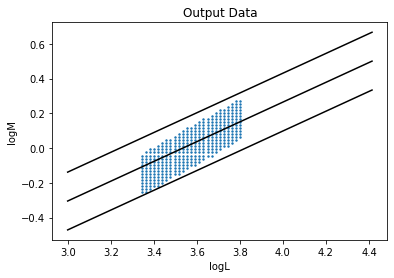

In [94]:
artifical_set_0_stars = make_artificial_set([M0StarData,M1StarData,C0StarData,C1StarData],3,grid_spacing = 75j,restrict_stars = True,restriction_labels=['M0','C0'])

sigmaDL= 0.06519024127945568


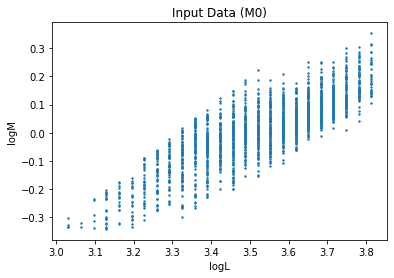

sigmaDL= 0.06192636262963603


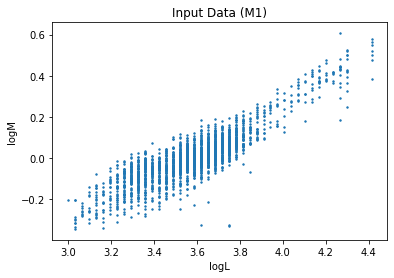

sigmaDL= 0.04833065042469314


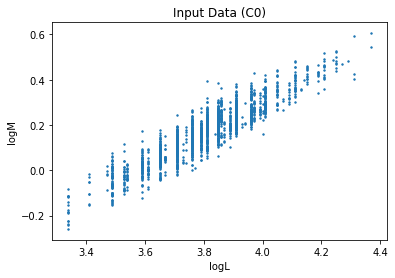

sigmaDL= 0.06220216929796503


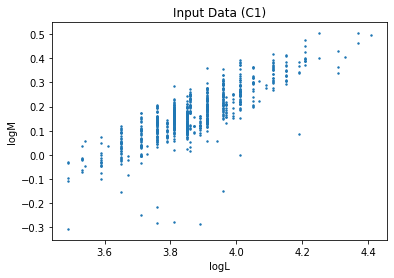

sigmaDL= 0.06381699617454836
bound_size: 0.16636321460903788


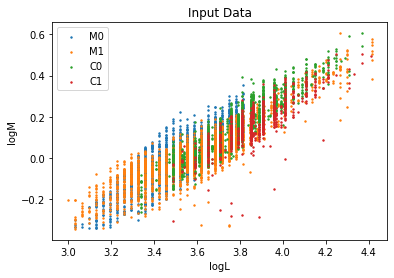

[-0.51255116 -0.49515893 -0.4777667  -0.46037447 -0.44298224 -0.42559001
 -0.40819778 -0.39080555 -0.37341332 -0.35602108 -0.33862885 -0.32123662
 -0.30384439 -0.28645216 -0.26905993 -0.2516677  -0.23427547 -0.21688324
 -0.19949101 -0.18209878 -0.16470655 -0.14731432 -0.12992208 -0.11252985
 -0.09513762 -0.07774539 -0.06035316 -0.04296093 -0.0255687  -0.00817647
  0.00921576  0.02660799  0.04400022  0.06139245  0.07878468  0.09617691
  0.11356915  0.13096138  0.14835361  0.16574584  0.18313807  0.2005303
  0.21792253  0.23531476  0.25270699  0.27009922  0.28749145  0.30488368
  0.32227591  0.33966815  0.35706038  0.37445261  0.39184484  0.40923707
  0.4266293   0.44402153  0.46141376  0.47880599  0.49619822  0.51359045
  0.53098268  0.54837491  0.56576715  0.58315938  0.60055161  0.61794384
  0.63533607  0.6527283   0.67012053  0.68751276  0.70490499  0.72229722
  0.73968945  0.75708168  0.77447391]
Number of Artifical Points: 1153
LM_Grid[0]: [3.         3.         3.         ... 4.41

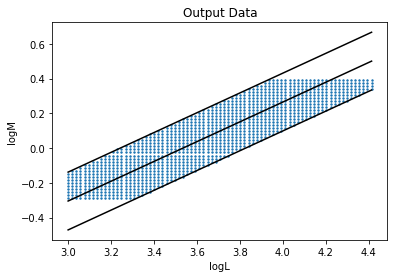

logL_Limits: [[3.0322157032979815, 3.8131137540078988], [3.0, 4.414287958434695], [3.339848783037637, 4.369994661608428], [3.4899584794248346, 4.409983816226542]]
logM_Limits: [[-0.34116528211482455, 0.3529753019135413], [-0.34618794722709323, 0.6081107001981967], [-0.26006819636361916, 0.6061396141442832], [-0.30718579455718587, 0.5043212412290314]]


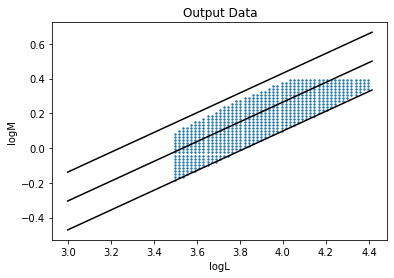

In [95]:
artifical_set_1_stars = make_artificial_set([M0StarData,M1StarData,C0StarData,C1StarData],3,grid_spacing = 75j,restrict_stars = True,restriction_labels=['M1','C1'])

sigmaDL= 0.06519024127945568


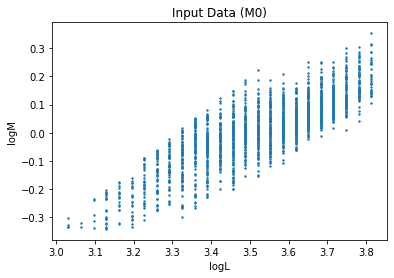

sigmaDL= 0.06192636262963603


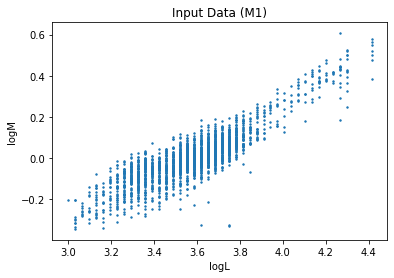

sigmaDL= 0.04833065042469314


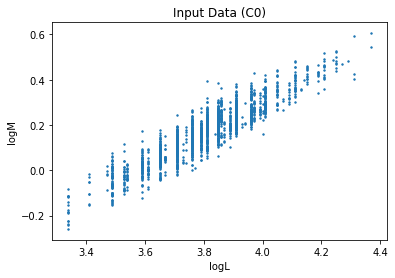

sigmaDL= 0.06220216929796503


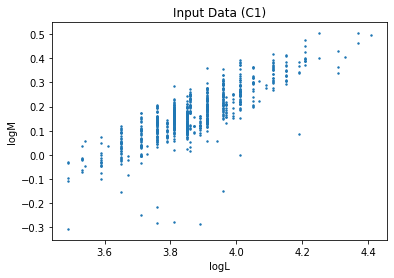

sigmaDL= 0.06381699617454836
bound_size: 0.16636321460903788


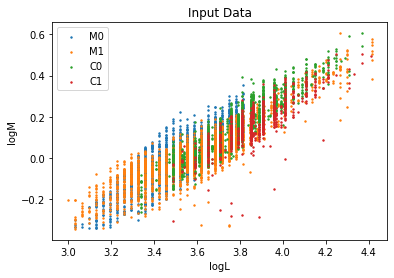

[-0.51255116 -0.49515893 -0.4777667  -0.46037447 -0.44298224 -0.42559001
 -0.40819778 -0.39080555 -0.37341332 -0.35602108 -0.33862885 -0.32123662
 -0.30384439 -0.28645216 -0.26905993 -0.2516677  -0.23427547 -0.21688324
 -0.19949101 -0.18209878 -0.16470655 -0.14731432 -0.12992208 -0.11252985
 -0.09513762 -0.07774539 -0.06035316 -0.04296093 -0.0255687  -0.00817647
  0.00921576  0.02660799  0.04400022  0.06139245  0.07878468  0.09617691
  0.11356915  0.13096138  0.14835361  0.16574584  0.18313807  0.2005303
  0.21792253  0.23531476  0.25270699  0.27009922  0.28749145  0.30488368
  0.32227591  0.33966815  0.35706038  0.37445261  0.39184484  0.40923707
  0.4266293   0.44402153  0.46141376  0.47880599  0.49619822  0.51359045
  0.53098268  0.54837491  0.56576715  0.58315938  0.60055161  0.61794384
  0.63533607  0.6527283   0.67012053  0.68751276  0.70490499  0.72229722
  0.73968945  0.75708168  0.77447391]
Number of Artifical Points: 1153
LM_Grid[0]: [3.         3.         3.         ... 4.41

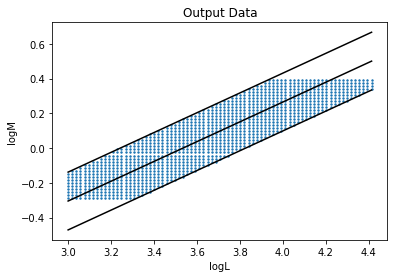

In [96]:
artifical_set_all_stars = make_artificial_set([M0StarData,M1StarData,C0StarData,C1StarData],3,grid_spacing = 75j)

In [97]:
# PML coefficients can be constructed from RLM and PMR relations
# logR = AR + BRlogL + CRlogM
# logP = AP + BPlogM + CPlogR
# => logP = AP + BPlogM + CP(AR + BRlogL + CRlogM) = (AP + CP*AR) + (BP+CP*CR)logM + (CP*BR)logL = A + BlogM + C logL
RLM_M = [-0.241, 0.690, -0.251]
RLM_C = [-0.323, 0.737, -0.371]
PMR_M0 = [-2.234, -0.7802, 2.027]
PMR_M1 = [-1.554, -0.529, 1.570]
PMR_C0 = [-2.285, -0.826, 2.043]
PMR_C1 = [-1.554, -0.529, 1.570]

def calculate_PML_coeffs (RLM_coeffs, PMR_coeffs):
    A = PMR_coeffs[0] + PMR_coeffs[2]*RLM_coeffs[0]
    B = PMR_coeffs[1] + PMR_coeffs[2]*RLM_coeffs[2]
    C = PMR_coeffs[2]*RLM_coeffs[1]
    return np.asarray([A, B, C])

PML_M0 = calculate_PML_coeffs(RLM_M,PMR_M0)
PML_M1 = calculate_PML_coeffs(RLM_M,PMR_M1)
PML_C0 = calculate_PML_coeffs(RLM_C,PMR_C0)
PML_C1 = calculate_PML_coeffs(RLM_C,PMR_C1)

In [98]:
print(PML_M0)
print(PML_M1)
print(PML_C0)
print(PML_C1)

[-2.722507 -1.288977  1.39863 ]
[-1.93237 -0.92307  1.0833 ]
[-2.944889 -1.583953  1.505691]
[-2.06111 -1.11147  1.15709]


In [99]:
def calc_vw_mdot (log_period, log_mass):
    # log Mdot = -11.4 + 0.0125(P-100(M-2.5))
    # http://cdsads.u-strasbg.fr/pdf/1993ApJ...413..641V
    logMdot_array = []
    for i in range (0, len(log_period)):
        mass = 10**(log_mass[i])
        period = 10**(log_period[i])
        if mass > 2.5:
            # eq. 5 in above reference
            logMdot = -11.4 + 0.0125*(period - 100*(mass-2.5))
        else:
            # Eq. 2 in above reference
            logMdot = -11.4 + 0.0123*(period)
        logMdot_array.append(logMdot)
    return np.asarray(logMdot_array)

def calc_de_beck_mdot (log_period):
    # log Mdot = -7.37 + 3.42*10^-3 * P (P<850)
    #          = -4.46                  (P>850)
    logMdot_array = []
    for i in range (0, len(log_period)):
        period = 10**(log_period[i])
        if period < 850:
            logMdot = -7.37 + 3.42*10**(-3)*period
        else:
            logMdot = -4.46
        logMdot_array.append(logMdot)
    return np.asarray(logMdot_array)

In [100]:
# PML coefficients can be constructed from RLM and PMR relations
# logR = AR + BRlogL + CRlogM
# logP = AP + BPlogM + CPlogR
# => logP = AP + BPlogM + CP(AR + BRlogL + CRlogM) = (AP + CP*AR) + (BP+CP*CR)logM + (CP*BR)logL = A + BlogM + C logL
RLM_M = [-0.241, 0.690, -0.251]
RLM_C = [-0.323, 0.737, -0.371]
PMR_M0 = [-2.234, -0.7802, 2.027]
PMR_M1 = [-1.554, -0.529, 1.570]
PMR_C0 = [-2.285, -0.826, 2.043]
PMR_C1 = [-1.554, -0.529, 1.570]

def calculate_PML_coeffs (RLM_coeffs, PMR_coeffs):
    A = PMR_coeffs[0] + PMR_coeffs[2]*RLM_coeffs[0]
    B = PMR_coeffs[1] + PMR_coeffs[2]*RLM_coeffs[2]
    C = PMR_coeffs[2]*RLM_coeffs[1]
    return np.asarray([A, B, C])

PML_M0 = calculate_PML_coeffs(RLM_M,PMR_M0)
PML_M1 = calculate_PML_coeffs(RLM_M,PMR_M1)
PML_C0 = calculate_PML_coeffs(RLM_C,PMR_C0)
PML_C1 = calculate_PML_coeffs(RLM_C,PMR_C1)

In [101]:
def histogram_check_mdot_by_crit_mdot (star_data, spec_mode_label, bins=10,tev=2*10**6):
    log_mdot_by_mdotcrit = np.log10(star_data[MdotIndex]/(star_data[MIndex]/tev)) 
    plot.hist(log_mdot_by_mdotcrit,bins)
    plot.xlabel(r'$\log(\dot{M}/\dot{M}_{\mathrm{crit}})$')
    plot.title(spec_mode_label)
    plot.show()
    plot.close('all')

In [102]:
def histogram_check_log_index (star_data, index,spec_mode_label, xlab,bins=10, tev=2*10**6):
    hist_values = np.log10(star_data[index]) 
    plot.hist(hist_values,bins)
    plot.title(spec_mode_label)
    plot.xlabel(xlab)
    plot.show()
    plot.close('all')
    
def histogram_check_log_index_multi_list (star_data, index,spec_mode_label, xlab,bins=10, tev=2*10**6):
    # Type 1: Overlay
    hist_values_list = []
    for i in range(0, len(star_data)):
        hist_values_list.append(star_data[i][index])
    hist_values_array = np.asarray(hist_values_list)
    plot.hist(hist_values_array,bins,histtype='bar')
    plot.title(spec_mode_label)
    plot.xlabel(xlab)
    plot.show()
    plot.close('all')
    # Type 2: Stacked
    hist_values_list = []
    for i in range(0, len(star_data)):
        hist_values_list.append(star_data[i][index])
    hist_values_array = np.asarray(hist_values_list)
    plot.hist(hist_values_array,bins,histtype='barstacked')
    plot.title(spec_mode_label)
    plot.xlabel(xlab)
    plot.show()
    plot.close('all')

histogram_check_log_index(C0StarData,MIndex,'C0',r'$\log M$')
histogram_check_log_index(C0StarData_n,MIndex,'C0n',r'$\log M$')
histogram_check_log_index(C0StarData_x,MIndex,'C0x',r'$\log M$')
histogram_check_log_index_multi_list([C0StarData_n,C0StarData_x],MIndex,'C0',r'$\log M$')

In [103]:
combined_data_set_raw = np.hstack([M0StarData[0:28],M1StarData[0:28],C0StarData,C1StarData])

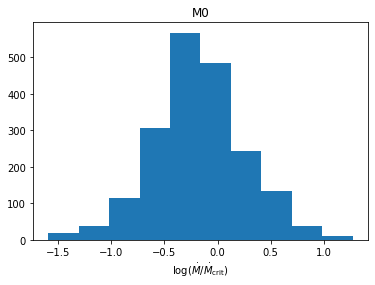

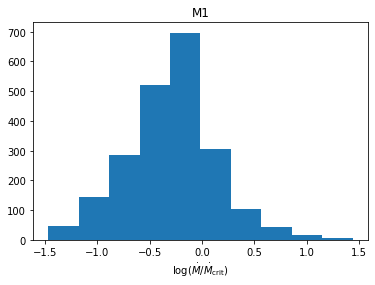

C:\ProgramData\Anaconda3\lib\site-packages\numpy\lib\histograms.py:839: RuntimeWarning: invalid value encountered in greater_equal
  keep = (tmp_a >= first_edge)
C:\ProgramData\Anaconda3\lib\site-packages\numpy\lib\histograms.py:840: RuntimeWarning: invalid value encountered in less_equal
  keep &= (tmp_a <= last_edge)


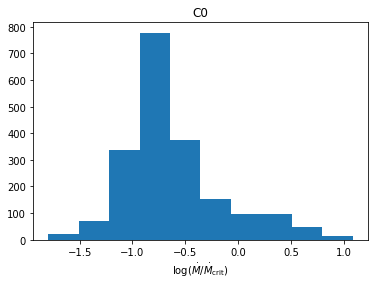

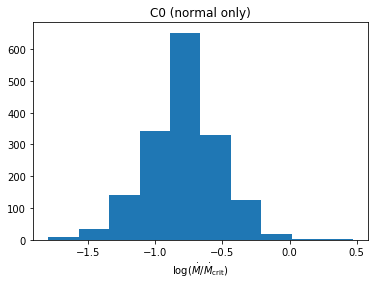

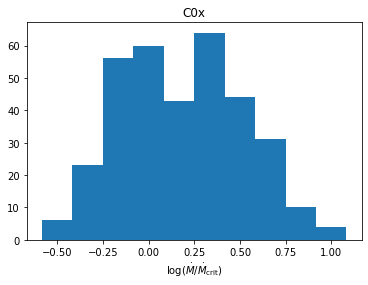

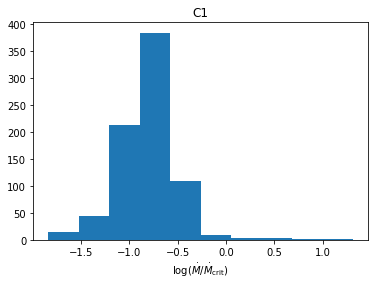

In [104]:
histogram_check_mdot_by_crit_mdot(M0StarData,'M0')
histogram_check_mdot_by_crit_mdot(M1StarData,'M1')
histogram_check_mdot_by_crit_mdot(C0StarData,'C0')
histogram_check_mdot_by_crit_mdot(C0StarData_n,'C0 (normal only)')
histogram_check_mdot_by_crit_mdot(C0StarData_x,'C0x')
histogram_check_mdot_by_crit_mdot(C1StarData,'C1')

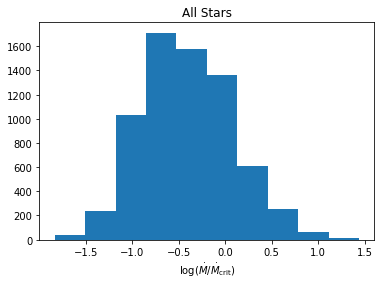

In [105]:
histogram_check_mdot_by_crit_mdot(combined_data_set_raw,'All Stars')

In [106]:
M0StarData_critzone = critical_zone_only(M0StarData)
M1StarData_critzone = critical_zone_only(M1StarData)
C0StarData_critzone = critical_zone_only(C0StarData_n)
C0xStarData_critzone = critical_zone_only(C0StarData_x)
C1StarData_critzone = critical_zone_only(C1StarData)

69 stars cut. 1882 stars remaining.
10 stars over the critical mass-loss rate. 59 stars under the critical mass-loss rate.
_____
134 stars cut. 2028 stars remaining.
10 stars over the critical mass-loss rate. 124 stars under the critical mass-loss rate.
_____
319 stars cut. 1335 stars remaining.
0 stars over the critical mass-loss rate. 319 stars under the critical mass-loss rate.
_____
3 stars cut. 338 stars remaining.
3 stars over the critical mass-loss rate. 0 stars under the critical mass-loss rate.
_____
174 stars cut. 607 stars remaining.
2 stars over the critical mass-loss rate. 172 stars under the critical mass-loss rate.
_____


In [107]:
combined_data_set = np.hstack([M0StarData_critzone[0:28],M1StarData_critzone[0:28],C0StarData_critzone,C1StarData_critzone,C0xStarData_critzone])

In [108]:
len(M0StarData)

28

In [494]:
def deathline_analysis (star_data,spec_mode_label = '',std_multiplier=1,text_x=0.03):
    # Take data, fit logM v logL (this line is the deathline)
    deathline_fit = linear_fit_1var(np.log10(star_data[LIndex]),np.log10(star_data[MIndex]))
    deathline_coeffs = deathline_fit[0]
    np.nanstd(np.log10(star_data[MIndex]))
    # Plot logM v logL and fit line for checking
    line_x_vals = np.asarray([np.nanmin(np.log10(star_data[LIndex])),np.nanmax(np.log10(star_data[LIndex]))])
    line_y_vals = deathline_coeffs[0] + deathline_coeffs[1]*line_x_vals
    #bound_size = std_multiplier*np.nanstd(np.log10(star_data[MIndex]))
    stnd_dev_around_DL = np.nanstd(np.log10(star_data[MIndex])-deathline_coeffs[0]-deathline_coeffs[1]*np.log10(star_data[LIndex]))
    print('sigmaDL=',stnd_dev_around_DL)
    # Take the Standard Deviation around the deathline to be the standard deviation of the difference between the dependent logM and the fit of logL
    bound_size = std_multiplier*stnd_dev_around_DL*np.cos(np.arctan(deathline_coeffs[1]))



    print('Bound Size (logM):', bound_size)
    line_y_vals_up = deathline_coeffs[0] + deathline_coeffs[1]*line_x_vals + bound_size
    line_y_vals_down = deathline_coeffs[0] + deathline_coeffs[1]*line_x_vals - bound_size
    # Find width of deltaLogL and deltaLogM using fit line, and plot them
    logL_left = (np.average(line_y_vals) - deathline_coeffs[0]-bound_size)/deathline_coeffs[1]
    logL_right = (np.average(line_y_vals) - deathline_coeffs[0]+bound_size)/deathline_coeffs[1]
    delta_logL = logL_right - logL_left
    print('∆logL =',delta_logL)
    delta_logM = line_y_vals_up[1] - line_y_vals_down[1]
    print('∆logM =',delta_logM)
    # Using data, calculate deltaLogMdot
    delta_logMdot = np.nanmax(np.log10(star_data[MdotIndex])) - np.nanmin(np.log10(star_data[MdotIndex]))
    print('Dumb delta_logMdot:',delta_logMdot)
    '''
    We should be more sophisticated than what we have above. Taking the maximum or minimum of the mass loss rate 
    of the unbounded data will lead to significant skew. With the other two variables, we are saying something like
    "if we hold M (or L) constant, what range of L (or M) do we measure?". We need to keep this restriction on the 
    Mdot data, so instead we could ask "what range of Mdot do we measure after bounding?" (a valid approximation if B is large)
    or we could have the same confidence restriction, just in Mdot. So, for example, say what is the range of logMdot that falls
    within 2-sigma of the mean.
    '''
    # Option 1: Range of the *bounded* data
    stars_in_bound = []
    print(len(star_data[MdotIndex]))
    for i in range(0, len(star_data[MdotIndex])):
        if np.log10(star_data[MIndex][i]) < deathline_coeffs[0] + deathline_coeffs[1]*np.log10(star_data[LIndex][i]) + bound_size:
            #print('True value found.')
            if np.log10(star_data[MIndex][i]) > deathline_coeffs[0] + deathline_coeffs[1]*np.log10(star_data[LIndex][i]) - bound_size:
                #print('Double True value found.')
                stars_in_bound.append(np.transpose(star_data)[i])
            else:
                continue
        else:
            continue
    stars_in_bound = np.transpose(np.asarray(stars_in_bound))
    #print('stars_in_bound:',stars_in_bound)
    delta_logMdot = np.nanmax(np.log10(stars_in_bound[MdotIndex])) - np.nanmin(np.log10(stars_in_bound[MdotIndex]))
    print('Option 1 delta_logMdot:',delta_logMdot)
    
    # Option 2: What is the width of the distribution of mdot?
    #delta_logMdot = 2*std_multiplier*np.nanstd(np.log10(star_data[MdotIndex]))
    std_dev_logMdot = np.nanstd(np.log10(star_data[MdotIndex]))
    min_logmdot = np.nanmin(np.log10(star_data[MdotIndex]))
    max_logmdot = np.nanmax(np.log10(star_data[MdotIndex]))
    midpoint_logMdot = (min_logmdot + max_logmdot)/2.
    print('max_logmdot:',max_logmdot)
    print('min_logmdot:',min_logmdot)
    print('midpoint_logMdot:',midpoint_logMdot)
    midpoint_logMdot = np.nanmean(np.log10(star_data[MdotIndex]))
    delta_logMdot = 2*std_multiplier*std_dev_logMdot
    print('Option 2 delta_logMdot:',delta_logMdot)
    FWHM = 2*np.sqrt(2*np.log(2))
    fig, ax = plt.subplots()
    plot.hist(np.log10(star_data[MdotIndex]))
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot.vlines([midpoint_logMdot-std_dev_logMdot,midpoint_logMdot+std_dev_logMdot],0,300,colors='tab:orange')
    plot.vlines([midpoint_logMdot-FWHM/2*std_dev_logMdot,midpoint_logMdot+FWHM/2*std_dev_logMdot],0,300,colors='tab:pink')
    plot.vlines([midpoint_logMdot-1.5*std_dev_logMdot,midpoint_logMdot+1.5*std_dev_logMdot],0,300,colors='tab:red')
    plot.vlines([midpoint_logMdot-2*std_dev_logMdot,midpoint_logMdot+2*std_dev_logMdot],0,300,colors='tab:purple')
    plot.vlines([midpoint_logMdot-2.5*std_dev_logMdot,midpoint_logMdot+2.5*std_dev_logMdot],0,300,colors='k')
    plot.show()
    plot.close()
    
    
    #delta_logMdot = 2
    print('∆logMdot =',delta_logMdot)
    # Calculate B = deltaLogMdot/deltaLogL and C = deltaLogMdot/deltaLogM
    B = delta_logMdot/delta_logL
    C = -delta_logMdot/delta_logM

    # From actually testing this method, we know there is a possibility of a residual trend in log M or log L. We can correct for this
    # immediately by setting A = 0, calculating a residual, and finding the slope (intercept is irrelevant) when plotted vs logM. 
    A = 0.
    logMdot_guess = A + B*np.log10(star_data[LIndex]) + C*np.log10(star_data[MIndex])
    resid = np.log10(star_data[MdotIndex]) - logMdot_guess
    trend = linear_fit_1var(np.log10(star_data[MIndex]),resid)[0][1]
    print('Old C:',C)
    print('Old C/New C:',C/(C+trend))
    C = C + trend
    print('New C:',C)
    trend = linear_fit_1var(np.log10(star_data[LIndex]),resid)[0][1]
    print('Old B:',B)
    print('Old B/New B:',B/(B+trend))
    B = B + trend
    print('New B:',B)
    new_delta_logL = delta_logMdot/B
    new_delta_logM = -delta_logMdot/C
    
    # Plot
    fig, ax = plt.subplots()
    plot.scatter(np.log10(star_data[LIndex]), np.log10(star_data[MIndex]),s=2)
    plot.plot(line_x_vals,line_y_vals,linestyle='--',color='black')
    plot.plot(line_x_vals,line_y_vals_up,linestyle='--',color='tab:red')
    plot.plot(line_x_vals,line_y_vals_down,linestyle='--',color='tab:red')
    plot.xlabel(r'$\log L$')
    plot.ylabel(r'$\log M$')
    #plot.title(spec_mode_label)
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot.vlines(np.average(line_x_vals),np.average(line_y_vals)-delta_logM/2,np.average(line_y_vals)+delta_logM/2,color='tab:green',linestyle='-',linewidth=4)
    plot.vlines(np.average(line_x_vals),np.average(line_y_vals)-new_delta_logM/2,np.average(line_y_vals)+new_delta_logM/2,color='tab:red',linestyle='--',linewidth=2)
    plot.plot([logL_left,logL_right],[np.average(line_y_vals),np.average(line_y_vals)],color='tab:purple',linewidth=4)
    plot.plot([np.average(line_x_vals)-new_delta_logL,np.average(line_x_vals)+new_delta_logL],[np.average(line_y_vals),np.average(line_y_vals)],color='tab:orange',linewidth=2,linestyle='--')
    if type(std_multiplier) == int:
        plot_name = 'deathzone_'+spec_mode_label+'_stnd_dev_'+str(std_multiplier)
    #elif std_multiplier/(1/2*std_multiplier) == 2:
    #    plot_name = 'deathzone_'+spec_mode_label+'_stnd_dev_of_all_double'
    else:
        plot_name = 'deathzone_'+spec_mode_label+'_stnd_dev_of_all'
    plot.savefig(plot_name+'.png')
    plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    plot.show()
    plot.close('all')
    
    
    
    
    
    # Determine A
    '''
    # Idea: Find all points within 0.0125335 std. devs. of deathline (the closest 1% of stars), and assume they are 
    # 'on' the deathline
    indices_on_DL = []
    for i in range (0, len(star_data[MdotIndex])):
        PredictedLogM = deathline_coeffs[0]+deathline_coeffs[1]*np.log10(star_data[LIndex][i])
        if np.log10(star_data[MIndex][i]) < PredictedLogM + 0.0125335*stnd_dev_around_DL:
            if np.log10(star_data[MIndex][i]) > PredictedLogM - 0.0125335*stnd_dev_around_DL:
                indices_on_DL.append(i)
    print('Number of Stars within 1% of DL:', len(indices_on_DL))
    # Then, find their mass-loss rate. 
    closest_logMdots = np.log10(star_data[MdotIndex][indices_on_DL])
    #print('DEBUG: closest_logMdots=',closest_logMdots)
    # Then, take that mass-loss rate and set equal to A+BlogL+ClogM, solve for A.
    AList = closest_logMdots - B*np.log10(star_data[LIndex][indices_on_DL]) + C*np.log10(star_data[MIndex][indices_on_DL])
    #print('DEBUG: AList=',AList)
    # Finally, average this value of logA over all included points
    A = np.mean(AList)
    ATestResults = A + B*np.log10(star_data[LIndex][indices_on_DL]) - C*np.log10(star_data[MIndex][indices_on_DL])
    #print('DEBUG: ATestResults', ATestResults)
    '''
    '''
    # Idea:
    # We have B, C, logM = X + Y*logL, logMdot = A + BlogL + ClogM. Pick a series of masses and determine log L.
    # Assuming logMdot = logMdotcrit, we have what we need to calculate A for a given mass and luminosity.
    min_mass = np.nanmin(star_data[MIndex])
    max_mass = np.nanmax(star_data[MIndex])
    sample_logM = np.log10(np.arange(min_mass, max_mass, (max_mass-min_mass)/200))
    sample_logL = (sample_logM - deathline_coeffs[0])/deathline_coeffs[1]
    sample_logMdot = np.log10((10**sample_logM)/(2*10**6))
    A_list = sample_logMdot - B*sample_logL - C*sample_logM
    A_fit = linear_fit_1var(sample_logM,A_list)
    #print('A_list:', A_list)
    print('A_fit: Intercept=',A_fit[0][0], ', Slope=',A_fit[0][1])
    A = np.mean(A_list)
    plot.scatter(sample_logM,A_list,s=2)
    plot.xlabel(r'$\log M$')
    plot.ylabel(r'$A$')
    plot.title(spec_mode_label)
    plot.show()
    plot.close('all')
    '''
    # Simpler, we can force A to be whatever is necessary for the mean residual to be 0
    # <logMdot_obsv - logMdot_calc> = 0 = sum(logMdot_obsv[i] - (A + BlogL[i] + ClogM[i]))/len(data)  
    # => <A> = sum(logMdot_obsv[i] - BlogL[i] - ClogM[i])/len(data)
    A = 0
    for i in range(0, np.shape(star_data)[1]):
        if np.isnan(np.log10(star_data[MdotIndex][i]))==True:
            print('Index ',i,' skipped due to NaN in logMdot')
        elif np.isnan(np.log10(star_data[LIndex][i]))==True:
            print('Index ',i,' skipped due to NaN in logL')
        elif np.isnan(np.log10(star_data[MIndex][i]))==True:
            print('Index ',i,' skipped due to NaN in logM')
        else:
            A = A + np.log10(star_data[MdotIndex][i])-B*np.log10(star_data[LIndex][i]) - C*np.log10(star_data[MIndex][i])
    A = A/np.shape(star_data)[1]
    logMdot_predict = A + B*np.log10(star_data[LIndex]) + C*np.log10(star_data[MIndex])
    correction = np.nanmean(np.log10(star_data[MdotIndex])-logMdot_predict)
    print('Correction to A:',correction)
    A = A + correction
    
    
    # Check: Make histogram of log(Mdot/Mdotcrit); this should be about 2 dex wide and that will match the theoretical death zone width.
    log_mdot_by_mdotcrit = np.log10(star_data[MdotIndex]/(star_data[MIndex]/(2*10**6))) 
    fig, ax = plt.subplots()
    plot.hist(log_mdot_by_mdotcrit,10)
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    #plot.title(spec_mode_label)
    plot.show()
    plot.close('all')
    
    
    # Check: Make histogram of logL/logMdot and logM/logMdot
    
    
    
    print('For set '+spec_mode_label+': A=',A,', B=', B,', C=', -C)
    print('_____ _____ _____ _____ _____')
    return A, B, C

In [495]:
def deathline_analysis_multidata (star_data,spec_mode_label = '',std_multiplier=1,text_x=0.03):
    
    
    # Make Title Label
    title_string = ''
    for i in range(0, len(spec_mode_label)):
        if i == 0:
            title_string = spec_mode_label[0]
        elif i < len(spec_mode_label)-1:
            title_string = title_string + ', '+spec_mode_label[i]
        else:
            if len(spec_mode_label) == 2:
                title_string = title_string + ' and ' + spec_mode_label[i]
            else:
                title_string = title_string + ', and '+ spec_mode_label[i]
    #plot.title(title_string)
    
    star_data_stacked = np.hstack(star_data) # Assume a list of data that would be used in version above. Need the stacked version for calculations.
    # Take data, fit logM v logL (this line is the deathline)
    deathline_fit = linear_fit_1var(np.log10(star_data_stacked[LIndex]),np.log10(star_data_stacked[MIndex]))
    deathline_coeffs = deathline_fit[0]
    np.nanstd(np.log10(star_data_stacked[MIndex]))
    # Plot logM v logL and fit line for checking
    line_x_vals = np.asarray([np.nanmin(np.log10(star_data_stacked[LIndex])),np.nanmax(np.log10(star_data_stacked[LIndex]))])
    line_y_vals = deathline_coeffs[0] + deathline_coeffs[1]*line_x_vals
    #bound_size = std_multiplier*np.nanstd(np.log10(star_data[MIndex]))
    stnd_dev_around_DL = np.nanstd(np.log10(star_data_stacked[MIndex])-deathline_coeffs[0]-deathline_coeffs[1]*np.log10(star_data_stacked[LIndex]))
    print('sigmaDL=',stnd_dev_around_DL)
    # Take the Standard Deviation around the deathline to be the standard deviation of the difference between the dependent logM and the fit of logL
    bound_size = std_multiplier*stnd_dev_around_DL*np.cos(np.arctan(deathline_coeffs[1]))



    print('Bound Size (logM):', bound_size)
    line_y_vals_up = deathline_coeffs[0] + deathline_coeffs[1]*line_x_vals + bound_size
    line_y_vals_down = deathline_coeffs[0] + deathline_coeffs[1]*line_x_vals - bound_size
    # Find width of deltaLogL and deltaLogM using fit line, and plot them
    logL_left = (np.average(line_y_vals) - deathline_coeffs[0]-bound_size)/deathline_coeffs[1]
    logL_right = (np.average(line_y_vals) - deathline_coeffs[0]+bound_size)/deathline_coeffs[1]
    delta_logL = logL_right - logL_left
    print('∆logL =',delta_logL)
    delta_logM = line_y_vals_up[1] - line_y_vals_down[1]
    print('∆logM =',delta_logM)
    # Using data, calculate deltaLogMdot
    delta_logMdot = np.nanmax(np.log10(star_data_stacked[MdotIndex])) - np.nanmin(np.log10(star_data_stacked[MdotIndex]))
    print('Dumb delta_logMdot:',delta_logMdot)
    '''
    We should be more sophisticated than what we have above. Taking the maximum or minimum of the mass loss rate 
    of the unbounded data will lead to significant skew. With the other two variables, we are saying something like
    "if we hold M (or L) constant, what range of L (or M) do we measure?". We need to keep this restriction on the 
    Mdot data, so instead we could ask "what range of Mdot do we measure after bounding?" (a valid approximation if B is large)
    or we could have the same confidence restriction, just in Mdot. So, for example, say what is the range of logMdot that falls
    within 2-sigma of the mean.
    '''
    # Option 1: Range of the *bounded* data
    stars_in_bound = []
    print(len(star_data_stacked[MdotIndex]))
    for i in range(0, len(star_data_stacked[MdotIndex])):
        if np.log10(star_data_stacked[MIndex][i]) < deathline_coeffs[0] + deathline_coeffs[1]*np.log10(star_data_stacked[LIndex][i]) + bound_size:
            #print('True value found.')
            if np.log10(star_data_stacked[MIndex][i]) > deathline_coeffs[0] + deathline_coeffs[1]*np.log10(star_data_stacked[LIndex][i]) - bound_size:
                #print('Double True value found.')
                stars_in_bound.append(np.transpose(star_data_stacked)[i])
            else:
                continue
        else:
            continue
    stars_in_bound = np.transpose(np.asarray(stars_in_bound))
    #print('stars_in_bound:',stars_in_bound)
    delta_logMdot = np.nanmax(np.log10(stars_in_bound[MdotIndex])) - np.nanmin(np.log10(stars_in_bound[MdotIndex]))
    print('Option 1 delta_logMdot:',delta_logMdot)
    
    # Option 2: What is the width of the distribution of mdot?
    #delta_logMdot = 2*std_multiplier*np.nanstd(np.log10(star_data[MdotIndex]))
    std_dev_logMdot = np.nanstd(np.log10(star_data_stacked[MdotIndex]))
    min_logmdot = np.nanmin(np.log10(star_data_stacked[MdotIndex]))
    max_logmdot = np.nanmax(np.log10(star_data_stacked[MdotIndex]))
    midpoint_logMdot = (min_logmdot + max_logmdot)/2.
    print('max_logmdot:',max_logmdot)
    print('min_logmdot:',min_logmdot)
    print('midpoint_logMdot:',midpoint_logMdot)
    midpoint_logMdot = np.nanmean(np.log10(star_data_stacked[MdotIndex]))
    delta_logMdot = 2*std_multiplier*std_dev_logMdot
    print('Option 2 delta_logMdot:',delta_logMdot)
    FWHM = 2*np.sqrt(2*np.log(2))
    fig, ax = plt.subplots()
    plot.hist(np.log10(star_data_stacked[MdotIndex]))
    ax.text(text_x, .97,title_string,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot.vlines([midpoint_logMdot-std_dev_logMdot,midpoint_logMdot+std_dev_logMdot],0,300,colors='tab:orange')
    plot.vlines([midpoint_logMdot-FWHM/2*std_dev_logMdot,midpoint_logMdot+FWHM/2*std_dev_logMdot],0,300,colors='tab:pink')
    plot.vlines([midpoint_logMdot-1.5*std_dev_logMdot,midpoint_logMdot+1.5*std_dev_logMdot],0,300,colors='tab:red')
    plot.vlines([midpoint_logMdot-2*std_dev_logMdot,midpoint_logMdot+2*std_dev_logMdot],0,300,colors='tab:purple')
    plot.vlines([midpoint_logMdot-2.5*std_dev_logMdot,midpoint_logMdot+2.5*std_dev_logMdot],0,300,colors='k')
    plot.show()
    plot.close()
    
    
    
    
    print('∆logMdot =',delta_logMdot)
    # Calculate B = deltaLogMdot/deltaLogL and C = deltaLogMdot/deltaLogM
    B = delta_logMdot/delta_logL
    C = -delta_logMdot/delta_logM
    
    
    # From actually testing this method, we know there is a possibility of a residual trend in log M or log L. We can correct for this
    # immediately by setting A = 0, calculating a residual, and finding the slope (intercept is irrelevant) when plotted vs logM. 
    A = 0.
    logMdot_guess = A + B*np.log10(star_data_stacked[LIndex]) + C*np.log10(star_data_stacked[MIndex])
    resid = np.log10(star_data_stacked[MdotIndex]) - logMdot_guess
    trend = linear_fit_1var(np.log10(star_data_stacked[MIndex]),resid)[0][1]
    print('Old C:',C)
    print('Old C/New C:',C/(C+trend))
    C = C + trend
    print('New C:',C)
    trend = linear_fit_1var(np.log10(star_data_stacked[LIndex]),resid)[0][1]
    print('Old B:',B)
    print('Old B/New B:',B/(B+trend))
    B = B + trend
    print('New B:',B)
    new_delta_logL = delta_logMdot/B
    new_delta_logM = -delta_logMdot/C

    # Plot
    fig, ax = plt.subplots()
    for i in range(0,len(star_data)):
        plot.scatter(np.log10(star_data[i][LIndex]), np.log10(star_data[i][MIndex]),s=2,label=spec_mode_label[i])
    plot.plot(line_x_vals,line_y_vals,linestyle='--',color='black')
    plot.plot(line_x_vals,line_y_vals_up,linestyle='--',color='tab:red')
    plot.plot(line_x_vals,line_y_vals_down,linestyle='--',color='tab:red')
    plot.xlabel(r'$\log L$')
    plot.ylabel(r'$\log M$')
    ax.text(text_x, .97,title_string,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot.vlines(np.average(line_x_vals),np.average(line_y_vals)-delta_logM/2,np.average(line_y_vals)+delta_logM/2,color='tab:green',linestyle='-',linewidth=4)
    plot.plot([logL_left,logL_right],[np.average(line_y_vals),np.average(line_y_vals)],color='tab:purple',linewidth=4)
    plot.vlines(np.average(line_x_vals),np.average(line_y_vals)-new_delta_logM/2,np.average(line_y_vals)+new_delta_logM/2,color='tab:red',linestyle='--',linewidth=2)
    plot.plot([np.average(line_x_vals)-new_delta_logL,np.average(line_x_vals)+new_delta_logL],[np.average(line_y_vals),np.average(line_y_vals)],color='tab:orange',linewidth=2,linestyle='--')
    if type(std_multiplier) == int:
        plot_name = 'deathzone_'+title_string+'_stnd_dev_'+str(std_multiplier)
    #elif std_multiplier/(1/2*std_multiplier) == 2:
    #    plot_name = 'deathzone_'+spec_mode_label+'_stnd_dev_of_all_double'
    else:
        plot_name = 'deathzone_'+title_string+'_stnd_dev_of_all'
    plot.legend(loc=4)
    plot.savefig(plot_name+'.png')
    plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    plot.show()
    plot.close('all')
    # Determine A
    '''
    # Idea: Find all points within 0.0125335 std. devs. of deathline (the closest 1% of stars), and assume they are 
    # 'on' the deathline
    indices_on_DL = []
    for i in range (0, len(star_data[MdotIndex])):
        PredictedLogM = deathline_coeffs[0]+deathline_coeffs[1]*np.log10(star_data[LIndex][i])
        if np.log10(star_data[MIndex][i]) < PredictedLogM + 0.0125335*stnd_dev_around_DL:
            if np.log10(star_data[MIndex][i]) > PredictedLogM - 0.0125335*stnd_dev_around_DL:
                indices_on_DL.append(i)
    print('Number of Stars within 1% of DL:', len(indices_on_DL))
    # Then, find their mass-loss rate. 
    closest_logMdots = np.log10(star_data[MdotIndex][indices_on_DL])
    #print('DEBUG: closest_logMdots=',closest_logMdots)
    # Then, take that mass-loss rate and set equal to A+BlogL+ClogM, solve for A.
    AList = closest_logMdots - B*np.log10(star_data[LIndex][indices_on_DL]) + C*np.log10(star_data[MIndex][indices_on_DL])
    #print('DEBUG: AList=',AList)
    # Finally, average this value of logA over all included points
    A = np.mean(AList)
    ATestResults = A + B*np.log10(star_data[LIndex][indices_on_DL]) - C*np.log10(star_data[MIndex][indices_on_DL])
    #print('DEBUG: ATestResults', ATestResults)
    '''
    '''
    # Idea:
    # We have B, C, logM = X + Y*logL, logMdot = A + BlogL + ClogM. Pick a series of masses and determine log L.
    # Assuming logMdot = logMdotcrit, we have what we need to calculate A for a given mass and luminosity.
    min_mass = np.nanmin(star_data[MIndex])
    max_mass = np.nanmax(star_data[MIndex])
    sample_logM = np.log10(np.arange(min_mass, max_mass, (max_mass-min_mass)/200))
    sample_logL = (sample_logM - deathline_coeffs[0])/deathline_coeffs[1]
    sample_logMdot = np.log10((10**sample_logM)/(2*10**6))
    A_list = sample_logMdot - B*sample_logL - C*sample_logM
    A_fit = linear_fit_1var(sample_logM,A_list)
    #print('A_list:', A_list)
    print('A_fit: Intercept=',A_fit[0][0], ', Slope=',A_fit[0][1])
    A = np.mean(A_list)
    plot.scatter(sample_logM,A_list,s=2)
    plot.xlabel(r'$\log M$')
    plot.ylabel(r'$A$')
    plot.title(spec_mode_label)
    plot.show()
    plot.close('all')
    '''
    # Simpler, we can force A to be whatever is necessary for the mean residual to be 0
    # <logMdot_obsv - logMdot_calc> = 0 = sum(logMdot_obsv[i] - (A + BlogL[i] + ClogM[i]))/len(data)  
    # => <A> = sum(logMdot_obsv[i] - BlogL[i] - ClogM[i])/len(data)
    A = 0
    for i in range(0, np.shape(star_data_stacked)[1]):
        if np.isnan(np.log10(star_data_stacked[MdotIndex][i]))==True:
            print('Index ',i,' skipped due to NaN in logMdot')
        elif np.isnan(np.log10(star_data_stacked[LIndex][i]))==True:
            print('Index ',i,' skipped due to NaN in logL')
        elif np.isnan(np.log10(star_data_stacked[MIndex][i]))==True:
            print('Index ',i,' skipped due to NaN in logM')
        else:
            A = A + np.log10(star_data_stacked[MdotIndex][i])-B*np.log10(star_data_stacked[LIndex][i]) - C*np.log10(star_data_stacked[MIndex][i])
    A = A/np.shape(star_data_stacked)[1]
    
    logMdot_predict = A + B*np.log10(star_data_stacked[LIndex]) + C*np.log10(star_data_stacked[MIndex])
    correction = np.nanmean(np.log10(star_data_stacked[MdotIndex])-logMdot_predict)
    print('Correction to A:',correction)
    A = A + correction
    
    # Check: Make histogram of log(Mdot/Mdotcrit); this should be about 2 dex wide and that will match the theoretical death zone width.
    fig, ax = plt.subplots()
    log_mdot_by_mdotcrit = []
    for i in range(0, len(star_data)):
        log_mdot_by_mdotcrit.append(np.log10(star_data[i][MdotIndex]/(star_data[i][MIndex]/(2*10**6))))
    #log_mdot_by_mdotcrit = np.log10(star_data_stacked[MdotIndex]/(star_data_stacked[MIndex]/(2*10**6))) 
    plot.hist(log_mdot_by_mdotcrit,10,stacked=True)
    ax.text(text_x, .97,title_string,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    #plot.title(title_string)
    plot.show()
    plot.close('all')
    
    
    # Check: Make histogram of logL/logMdot and logM/logMdot
    
    
    
    print('For set '+title_string+': A=',A,', B=', B,', C=', -C)
    print('_____ _____ _____ _____ _____')
    return A, B, C

def deathline_analysis_with_errors (star_data,spec_mode_label = '',std_multiplier=1):
    # Take data, fit logM v logL (this line is the deathline)
    deathline_fit = linear_fit_1var(np.log10(star_data[LIndex]),np.log10(star_data[MIndex]))
    deathline_coeffs = deathline_fit[0]
    np.nanstd(np.log10(star_data[MIndex]))
    # Plot logM v logL and fit line for checking
    line_x_vals = np.asarray([np.nanmin(np.log10(star_data[LIndex])),np.nanmax(np.log10(star_data[LIndex]))])
    line_y_vals = deathline_coeffs[0] + deathline_coeffs[1]*line_x_vals
    print('Bound Size (logM):', std_multiplier*np.nanstd(np.log10(star_data[MIndex])))
    line_y_vals_up = deathline_coeffs[0] + deathline_coeffs[1]*line_x_vals + std_multiplier*np.nanstd(np.log10(star_data[MIndex]))
    line_y_vals_down = deathline_coeffs[0] + deathline_coeffs[1]*line_x_vals - std_multiplier*np.nanstd(np.log10(star_data[MIndex]))
    plot.scatter(star_data[LIndex], star_data[MIndex],s=2)
    plot.plot(10**line_x_vals,10**line_y_vals,linestyle='--',color='black')
    plot.plot(10**line_x_vals,10**line_y_vals_up,linestyle='--',color='red')
    plot.plot(10**line_x_vals,10**line_y_vals_down,linestyle='--',color='red')
    plot.errorbar(star_data[LIndex],star_data[MIndex],xerr=star_data[LErrorIndex],fmt='none',markersize=1)
    plot.xscale('log')
    plot.yscale('log')
    plot.xlabel(r'$L$')
    plot.ylabel(r'$M$')
    plot.title(spec_mode_label)
    # Find width of deltaLogL and deltaLogM using fit line, and plot them
    logL_left = (np.average(line_y_vals) - deathline_coeffs[0]-std_multiplier*np.nanstd(np.log10(star_data[MIndex])))/deathline_coeffs[1]
    logL_right = (np.average(line_y_vals) - deathline_coeffs[0]+std_multiplier*np.nanstd(np.log10(star_data[MIndex])))/deathline_coeffs[1]
    delta_logL = logL_right - logL_left
    print('∆logL =',delta_logL)
    plot.plot([10**logL_left,10**logL_right],[10**(np.average(line_y_vals)),10**(np.average(line_y_vals))],color='purple')
    delta_logM = line_y_vals_up[1] - line_y_vals_down[1]
    print('∆logM =',delta_logM)
    plot.vlines(10**np.average(line_x_vals),10**(np.average(line_y_vals)-delta_logM/2),10**(np.average(line_y_vals)+delta_logM/2),color='green',linestyle='-')
    # Using data, calculate deltaLogMdot
    #delta_logMdot = np.nanmax(np.log10(star_data[MdotIndex])) - np.nanmin(np.log10(star_data[MdotIndex]))
    delta_logMdot = 2
    print('∆logMdot =',delta_logMdot)
    # Calculate B = deltaLogMdot/deltaLogL and C = deltaLogMdot/deltaLogM
    B = delta_logMdot/delta_logL
    C = delta_logMdot/delta_logM
    print('For set '+spec_mode_label+', B=',B, ', C=',C )
    plot.show()
    plot.close()
    
    
    return B, C

deathline_analysis(M0StarData_critzone, spec_mode_label = 'M0')
deathline_analysis(M1StarData_critzone, spec_mode_label = 'M1')
deathline_analysis(C0StarData_critzone, spec_mode_label = 'C0')
deathline_analysis(C1StarData_critzone, spec_mode_label = 'C1')
deathline_analysis(C0xStarData_critzone, spec_mode_label = 'C0x')
deathline_analysis(combined_data_set, spec_mode_label = 'All Stars')

deathline_analysis_multidata([C0StarData_critzone[0:28],C0xStarData_critzone[0:28]], spec_mode_label = ['C0','C0x'])

sigma= 1
sigmaDL= 0.06519024127945568
Bound Size (logM): 0.05605792482204062
∆logL = 0.18887564645151667
∆logM = 0.11211584964408122
Dumb delta_logMdot: 2.6989700043360187
1951
Option 1 delta_logMdot: 2.587819552213352
max_logmdot: -5.137719506700295
min_logmdot: -7.8366895110363135
midpoint_logMdot: -6.487204508868304
Option 2 delta_logMdot: 0.7821591090214547


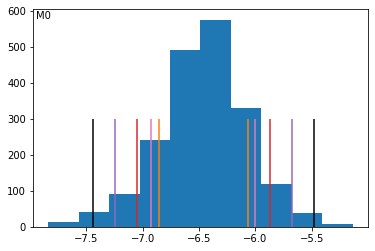

∆logMdot = 0.7821591090214547
Old C: -6.97634733629962
Old C/New C: 1.3133760781460846
New C: -5.311766715095943
Old B: 4.1411326643545365
Old B/New B: 0.9355268353984313
New B: 4.426524721325467


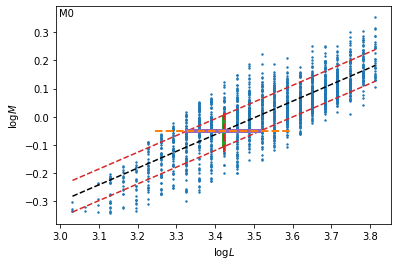

Correction to A: 2.1201196729645552e-13


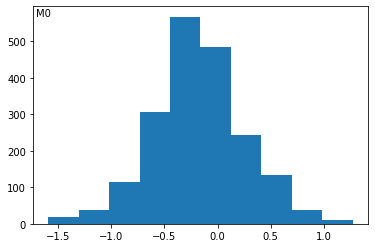

For set M0: A= -22.010528157677143 , B= 4.426524721325467 , C= 5.311766715095943
_____ _____ _____ _____ _____


In [496]:
print('sigma=',1)
deathzone_values_M0 = deathline_analysis(M0StarData, spec_mode_label = 'M0',std_multiplier=1)

sigma= 1
sigmaDL= 0.06192636262963603
Bound Size (logM): 0.05548014652936275
∆logL = 0.2237724807752146
∆logM = 0.11096029305872546
Dumb delta_logMdot: 3.011581872549816
2162
Option 1 delta_logMdot: 2.8297382846050434
max_logmdot: -4.955875918755522
min_logmdot: -7.967457791305338
midpoint_logMdot: -6.46166685503043
Option 2 delta_logMdot: 0.8867107021380476


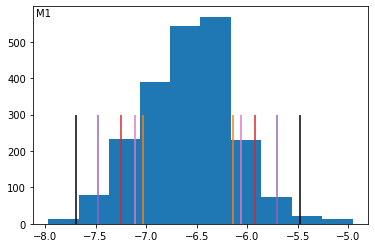

∆logMdot = 0.8867107021380476
Old C: -7.9912433330430925
Old C/New C: 1.5152751825536346
New C: -5.273790150496466
Old B: 3.962554729992791
Old B/New B: 0.8107601184158565
New B: 4.887456400464324


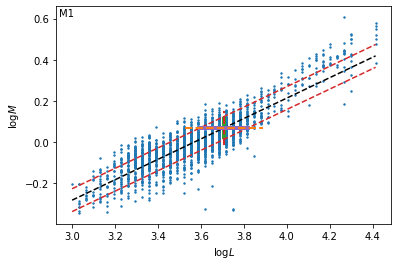

Correction to A: 1.174203092656654e-13


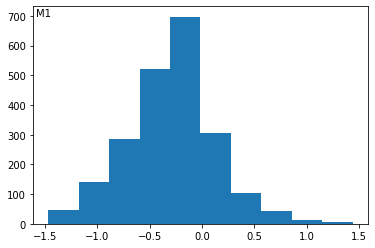

For set M1: A= -24.06376137107632 , B= 4.887456400464324 , C= 5.273790150496466
_____ _____ _____ _____ _____


In [497]:
print('sigma=',1)
deathzone_values_M1 = deathline_analysis(M1StarData, spec_mode_label = 'M1',std_multiplier=1)

sigma= 1
sigmaDL= 0.06220216929796503
Bound Size (logM): 0.05278120333695356
∆logL = 0.16928689190036028
∆logM = 0.10556240667390715
Dumb delta_logMdot: 3.3544743148909477
781
Option 1 delta_logMdot: 2.0534443192269665
max_logmdot: -4.6549204736851335
min_logmdot: -8.009394788576081
midpoint_logMdot: -6.332157631130608
Option 2 delta_logMdot: 0.5842830697259592


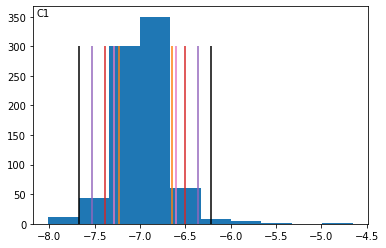

∆logMdot = 0.5842830697259592
Old C: -5.534954044112202
Old C/New C: 1.50624450844574
New C: -3.6746716838314626
Old B: 3.4514371618911843
Old B/New B: 0.8211807092779267
New B: 4.203017828957613


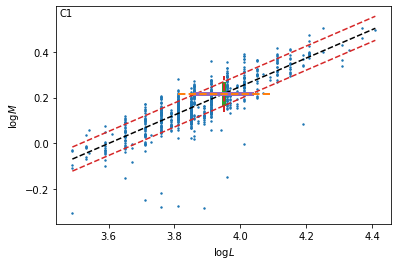

Correction to A: -1.0060525467192263e-13


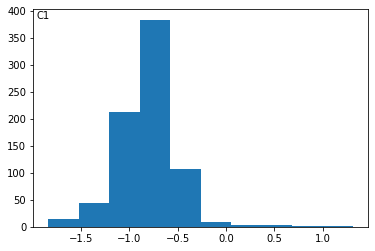

For set C1: A= -22.590992140526392 , B= 4.203017828957613 , C= 3.6746716838314626
_____ _____ _____ _____ _____


In [498]:
print('sigma=',1)
deathzone_values_C1 = deathline_analysis(C1StarData, spec_mode_label = 'C1',std_multiplier=1)

sigmaDL= 0.06519024127945568
Bound Size (logM): 0.11211584964408124
∆logL = 0.37775129290303333
∆logM = 0.22423169928816244
Dumb delta_logMdot: 2.6989700043360187
1951
Option 1 delta_logMdot: 2.6812412373755867
max_logmdot: -5.137719506700295
min_logmdot: -7.8366895110363135
midpoint_logMdot: -6.487204508868304
Option 2 delta_logMdot: 1.5643182180429094


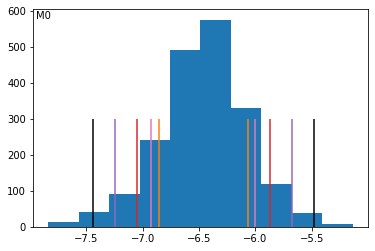

∆logMdot = 1.5643182180429094
Old C: -6.97634733629962
New C: -5.311766715095943
Old B: 4.1411326643545365
New B: 4.426524721325467


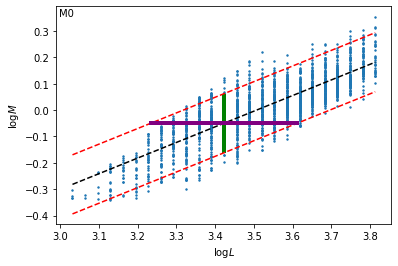

Correction to A: 2.1201196729645552e-13


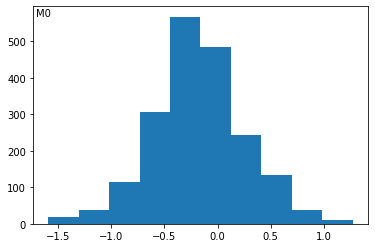

For set M0: A= -22.010528157677143 , B= 4.426524721325467 , C= 5.311766715095943
_____ _____ _____ _____ _____
sigmaDL= 0.06192636262963603
Bound Size (logM): 0.1109602930587255
∆logL = 0.44754496155042833
∆logM = 0.22192058611745097
Dumb delta_logMdot: 3.011581872549816
2162
Option 1 delta_logMdot: 3.011581872549816
max_logmdot: -4.955875918755522
min_logmdot: -7.967457791305338
midpoint_logMdot: -6.46166685503043
Option 2 delta_logMdot: 1.7734214042760952


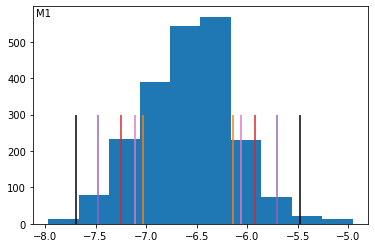

∆logMdot = 1.7734214042760952
Old C: -7.991243333043091
New C: -5.273790150496492
Old B: 3.962554729992799
New B: 4.887456400464315


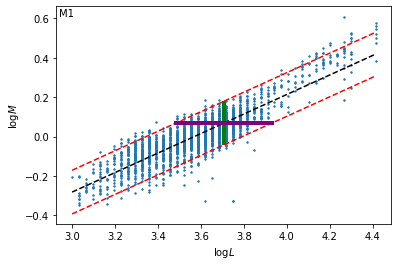

Correction to A: 1.4534246968665436e-13


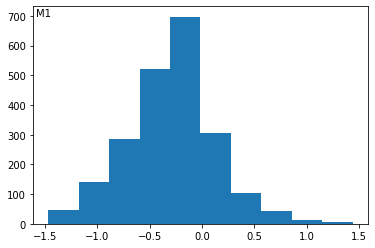

For set M1: A= -24.06376137107629 , B= 4.887456400464315 , C= 5.273790150496492
_____ _____ _____ _____ _____
sigmaDL= 0.04249438417421918
Bound Size (logM): 0.07063347456655861
∆logL = 0.2111102202573738
∆logM = 0.14126694913311727
Dumb delta_logMdot: 2.239222845685779
1654
Option 1 delta_logMdot: 2.239222845685779
max_logmdot: -5.703225153259688
min_logmdot: -7.942447998945467
midpoint_logMdot: -6.822836576102578
Option 2 delta_logMdot: 1.016717496723715


C:\ProgramData\Anaconda3\lib\site-packages\numpy\lib\histograms.py:839: RuntimeWarning: invalid value encountered in greater_equal
  keep = (tmp_a >= first_edge)
C:\ProgramData\Anaconda3\lib\site-packages\numpy\lib\histograms.py:840: RuntimeWarning: invalid value encountered in less_equal
  keep &= (tmp_a <= last_edge)


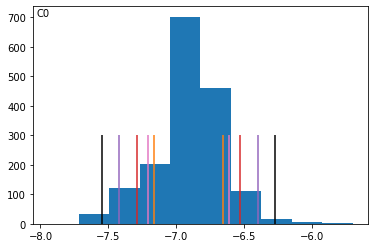

∆logMdot = 1.016717496723715
Old C: -7.197136364611738
New C: -5.948111447513197
Old B: 4.816050570570149
New B: 5.276447379609071


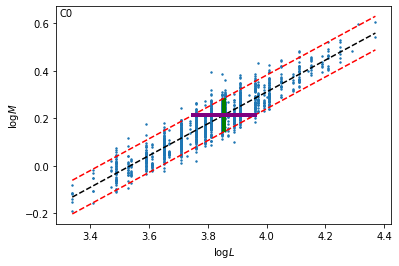

Index  0  skipped due to NaN in logMdot
Correction to A: -0.015674510015243497


C:\ProgramData\Anaconda3\lib\site-packages\numpy\lib\histograms.py:839: RuntimeWarning: invalid value encountered in greater_equal
  keep = (tmp_a >= first_edge)
C:\ProgramData\Anaconda3\lib\site-packages\numpy\lib\histograms.py:840: RuntimeWarning: invalid value encountered in less_equal
  keep &= (tmp_a <= last_edge)


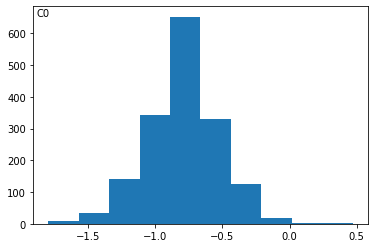

For set C0: A= -25.925639564797347 , B= 5.276447379609071 , C= 5.948111447513197
_____ _____ _____ _____ _____
sigmaDL= 0.06220216929796503
Bound Size (logM): 0.10556240667390712
∆logL = 0.3385737838007197
∆logM = 0.2111248133478143
Dumb delta_logMdot: 3.3544743148909477
781
Option 1 delta_logMdot: 3.3544743148909477
max_logmdot: -4.6549204736851335
min_logmdot: -8.009394788576081
midpoint_logMdot: -6.332157631130608
Option 2 delta_logMdot: 1.1685661394519185


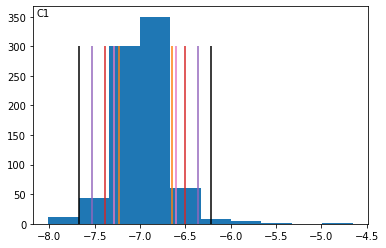

∆logMdot = 1.1685661394519185
Old C: -5.534954044112202
New C: -3.6746716838314706
Old B: 3.4514371618911937
New B: 4.203017828957615


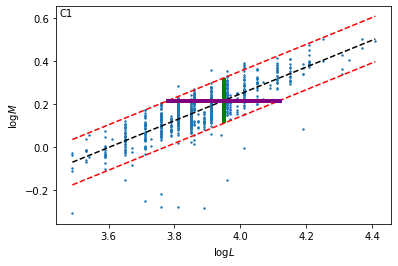

Correction to A: -1.0926527857207175e-13


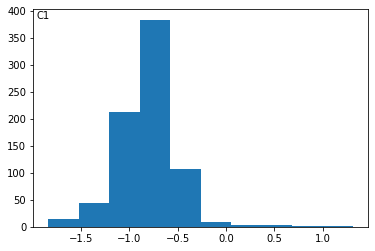

For set C1: A= -22.590992140526403 , B= 4.203017828957615 , C= 3.6746716838314706
_____ _____ _____ _____ _____
sigmaDL= 0.03373761311414754
Bound Size (logM): 0.05520769722519318
∆logL = 0.1571298355501658
∆logM = 0.11041539445038634
Dumb delta_logMdot: 1.8239087409443187
341
Option 1 delta_logMdot: 1.8239087409443187
max_logmdot: -4.933674074637962
min_logmdot: -6.757582815582281
midpoint_logMdot: -5.845628445110122
Option 2 delta_logMdot: 1.3667364938642113


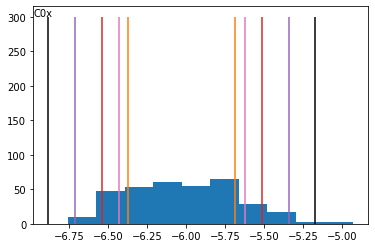

∆logMdot = 1.3667364938642113
Old C: -12.378133508170691
New C: -10.918270658522166
Old B: 8.698134820028258
New B: 9.40165901426434


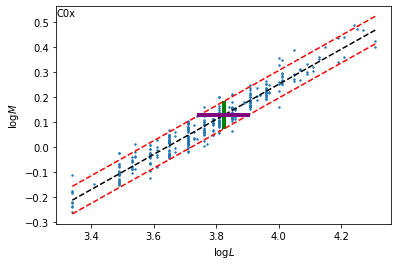

Correction to A: -2.318640554888714e-14


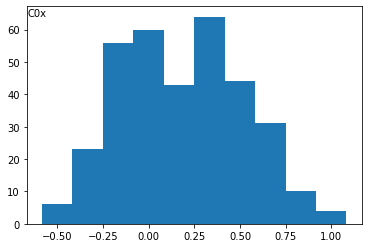

For set C0x: A= -40.49983892150037 , B= 9.40165901426434 , C= 10.918270658522166
_____ _____ _____ _____ _____


In [418]:
deathzone_values_M0 = deathline_analysis(M0StarData, spec_mode_label = 'M0',std_multiplier=2)
deathzone_values_M1 = deathline_analysis(M1StarData, spec_mode_label = 'M1',std_multiplier=2)
deathzone_values_C0 = deathline_analysis(C0StarData_n, spec_mode_label = 'C0',std_multiplier=2)
deathzone_values_C1 = deathline_analysis(C1StarData, spec_mode_label = 'C1',std_multiplier=2)
deathzone_values_C0x = deathline_analysis(C0StarData_x, spec_mode_label = 'C0x',std_multiplier=2)


sigmaDL= 0.04833065042469314
Bound Size (logM): 0.039730533518466865
∆logL = 0.11471873572932356
∆logM = 0.07946106703693379
Dumb delta_logMdot: 3.008773924307505
1995
Option 1 delta_logMdot: 2.769551078621726
max_logmdot: -4.933674074637962
min_logmdot: -7.942447998945467
midpoint_logMdot: -6.438061036791715
Option 2 delta_logMdot: 0.8581878368910804


C:\ProgramData\Anaconda3\lib\site-packages\numpy\lib\histograms.py:839: RuntimeWarning: invalid value encountered in greater_equal
  keep = (tmp_a >= first_edge)
C:\ProgramData\Anaconda3\lib\site-packages\numpy\lib\histograms.py:840: RuntimeWarning: invalid value encountered in less_equal
  keep &= (tmp_a <= last_edge)


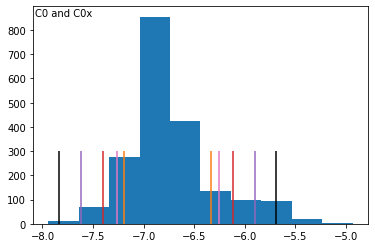

∆logMdot = 0.8581878368910804
Old C: -10.800104615914503
Old C/New C: 1.1226889921666856
New C: -9.619854377543422
Old B: 7.480799290849547
Old B/New B: 0.9607423173240252
New B: 7.786478388592237


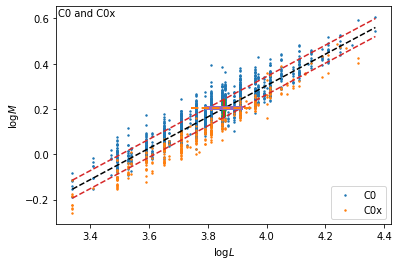

Index  0  skipped due to NaN in logMdot
Correction to A: -0.017426707180245696


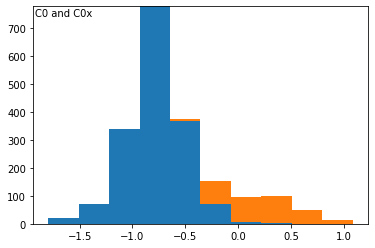

For set C0 and C0x: A= -34.76628082574503 , B= 7.786478388592237 , C= 9.619854377543422
_____ _____ _____ _____ _____
sigmaDL= 0.06381699617454836
Bound Size (logM): 0.1109088097393586
∆logL = 0.3894874714313086
∆logM = 0.22181761947871714
Dumb delta_logMdot: 3.3544743148909477
6889
Option 1 delta_logMdot: 3.3544743148909477
max_logmdot: -4.6549204736851335
min_logmdot: -8.009394788576081
midpoint_logMdot: -6.332157631130608
Option 2 delta_logMdot: 1.7550925329623388


C:\ProgramData\Anaconda3\lib\site-packages\numpy\lib\histograms.py:839: RuntimeWarning: invalid value encountered in greater_equal
  keep = (tmp_a >= first_edge)
C:\ProgramData\Anaconda3\lib\site-packages\numpy\lib\histograms.py:840: RuntimeWarning: invalid value encountered in less_equal
  keep &= (tmp_a <= last_edge)


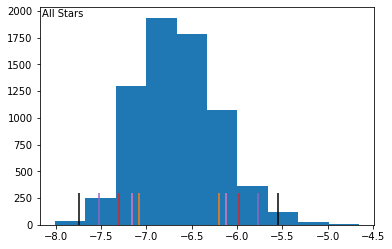

∆logMdot = 1.7550925329623388
Old C: -7.91232246151995
Old C/New C: 1.1535781601749637
New C: -6.858939198640762
Old B: 4.506159149388386
Old B/New B: 0.9964802202202924
New B: 4.522075860564706


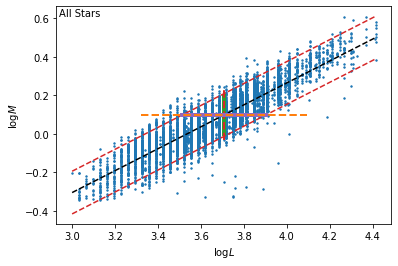

Index  4113  skipped due to NaN in logMdot
Correction to A: -0.003296403221132472


C:\ProgramData\Anaconda3\lib\site-packages\numpy\lib\histograms.py:839: RuntimeWarning: invalid value encountered in greater_equal
  keep = (tmp_a >= first_edge)
C:\ProgramData\Anaconda3\lib\site-packages\numpy\lib\histograms.py:840: RuntimeWarning: invalid value encountered in less_equal
  keep &= (tmp_a <= last_edge)


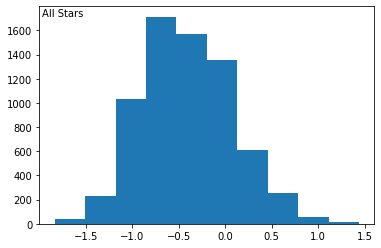

For set All Stars: A= -22.708921791851726 , B= 4.522075860564706 , C= 6.858939198640762
_____ _____ _____ _____ _____


In [499]:
deathzone_values_C0_and_C0x = deathline_analysis_multidata([C0StarData_n, C0StarData_x], spec_mode_label = ['C0', 'C0x'],std_multiplier=1,text_x=0.09)
#deathzone_values_M0_and_M1 = deathline_analysis_multidata([M0StarData, M1StarData], spec_mode_label = ['M0', 'M1'],std_multiplier=2)
combined_data_set = np.hstack([M0StarData[0:28],M1StarData[0:28],C0StarData_n,C1StarData, C0StarData_x])
deathzone_values_All = deathline_analysis(combined_data_set, spec_mode_label = 'All Stars',std_multiplier=2,text_x=0.07)

sigmaDL= 0.06381699617454836
Bound Size (logM): 0.1109088097393586
∆logL = 0.3894874714313086
∆logM = 0.22181761947871714
Dumb delta_logMdot: 3.3544743148909477
6889
Option 1 delta_logMdot: 3.3544743148909477
max_logmdot: -4.6549204736851335
min_logmdot: -8.009394788576081
midpoint_logMdot: -6.332157631130608
Option 2 delta_logMdot: 1.7550925329623388


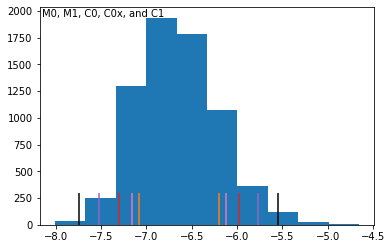

∆logMdot = 1.7550925329623388
Old C: -7.91232246151995
New C: -6.8589391986407655
Old B: 4.506159149388386
New B: 4.522075860564713


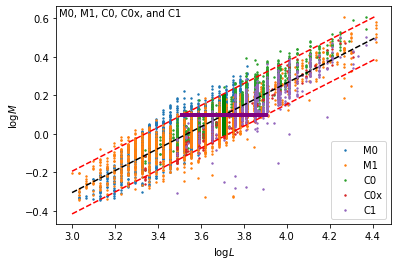

Index  4113  skipped due to NaN in logMdot
Correction to A: -0.00329640322111227


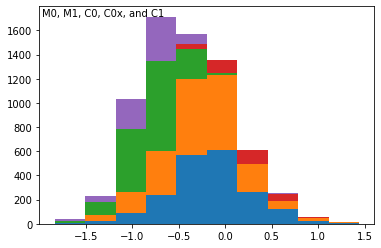

For set M0, M1, C0, C0x, and C1: A= -22.708921791851754 , B= 4.522075860564713 , C= 6.8589391986407655
_____ _____ _____ _____ _____


In [423]:
deathzone_values_All_legend = deathline_analysis_multidata([M0StarData, M1StarData, C0StarData_n, C0StarData_x, C1StarData], 
                                                           spec_mode_label = ['M0', 'M1', 'C0', 'C0x', 'C1'],std_multiplier=2,
                                                          text_x=0.19)

combined_data_std = np.nanstd(np.log10(combined_data_set[MIndex]))

M0_critzone_M_std = np.nanstd(np.log10(M0StarData_critzone[MIndex]))
M1_critzone_M_std = np.nanstd(np.log10(M1StarData_critzone[MIndex]))
C0_critzone_M_std = np.nanstd(np.log10(C0StarData_critzone[MIndex]))
C1_critzone_M_std = np.nanstd(np.log10(C1StarData_critzone[MIndex]))
C0x_critzone_M_std = np.nanstd(np.log10(C0xStarData_critzone[MIndex]))

deathline_analysis(M0StarData_critzone, spec_mode_label = 'M0',std_multiplier=combined_data_std/M0_critzone_M_std)
deathline_analysis(M1StarData_critzone, spec_mode_label = 'M1',std_multiplier=combined_data_std/M1_critzone_M_std)
deathline_analysis(C0StarData_critzone, spec_mode_label = 'C0',std_multiplier=combined_data_std/C0_critzone_M_std)
deathline_analysis(C1StarData_critzone, spec_mode_label = 'C1',std_multiplier=combined_data_std/C1_critzone_M_std)
deathline_analysis(C0xStarData_critzone, spec_mode_label = 'C0x',std_multiplier=combined_data_std/C0x_critzone_M_std)

deathline_analysis(M0StarData_critzone, spec_mode_label = 'M0',std_multiplier=2*combined_data_std/M0_critzone_M_std)
deathline_analysis(M1StarData_critzone, spec_mode_label = 'M1',std_multiplier=2*combined_data_std/M1_critzone_M_std)
deathline_analysis(C0StarData_critzone, spec_mode_label = 'C0',std_multiplier=2*combined_data_std/C0_critzone_M_std)
deathline_analysis(C1StarData_critzone, spec_mode_label = 'C1',std_multiplier=2*combined_data_std/C1_critzone_M_std)
deathline_analysis(C0xStarData_critzone, spec_mode_label = 'C0x',std_multiplier=2*combined_data_std/C0x_critzone_M_std)

deathline_analysis_with_errors(M0StarData_critzone, spec_mode_label = 'M0')
deathline_analysis_with_errors(M1StarData_critzone, spec_mode_label = 'M1')
deathline_analysis_with_errors(C0StarData_critzone, spec_mode_label = 'C0')
deathline_analysis_with_errors(C1StarData_critzone, spec_mode_label = 'C1')
deathline_analysis_with_errors(C0xStarData_critzone, spec_mode_label = 'C0x')
deathline_analysis_with_errors(combined_data_set, spec_mode_label = 'All Stars')

In [424]:
def mdot_vs_mdot_dz (star_data, deathzone_exponents, spec_mode_label = ''):
    mdot_data = np.log10(star_data[MdotIndex])
    predict_log_mdot = deathzone_exponents[0] + deathzone_exponents[1]*np.log10(star_data[LIndex]) - deathzone_exponents[2]*np.log10(star_data[MIndex])
    plot.scatter(predict_log_mdot,mdot_data,s=2)
    
    limits = np.asarray([np.nanmin([np.nanmin(predict_log_mdot),np.nanmin(mdot_data)]), np.nanmax([np.nanmax(predict_log_mdot),np.nanmax(mdot_data)])])
    min_val = limits[0]
    max_val = limits[1]
    form_vs_fed_fit = linear_fit_1var(predict_log_mdot,mdot_data)
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    quality_line_x = np.asarray([min_val,max_val])
    quality_line_y = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*quality_line_x
    plot.plot(quality_line_x,quality_line_y,color='orange')
    #print('limits',limits)
    plot.plot([limits[0],limits[1]],[limits[0],limits[1]],color='black',linestyle='-.')
    plot.xlim(limits[0]-0.1,limits[1]+0.1)
    plot.ylim(limits[0]-0.1,limits[1]+0.1)
    plot.tight_layout()
    plot.xlabel(r'$\log \dot{M}$'+' - Formula')
    plot.ylabel(r'$\log \dot{M}$'+' - GRAMS')
    plot.title(spec_mode_label)

mdot_vs_mdot_dz (M0StarData, deathzone_values_M0, spec_mode_label = 'M0')

In [425]:
def get_parallelogram_points (obsv_log_mdot_data, residual_data):
    # First, do a linear fit of given data
    form_vs_fed_fit = linear_fit_1var(obsv_log_mdot_data,residual_data) # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0] # Get Coeffs from above
    
    # Second, find two standard deviations away from fit line
    np.nanstd(residual_data)
    stnd_dev_around_fit = np.nanstd(residual_data-form_vs_fed_Coeffs[0]-form_vs_fed_Coeffs[1]*obsv_log_mdot_data)
    bound_size = 2*stnd_dev_around_fit*np.cos(np.arctan(form_vs_fed_Coeffs[1]))
    
    # Third, find upper and lower bounding line equations
    upper_bound_coeffs = form_vs_fed_Coeffs + np.asarray([bound_size,0])
    lower_bound_coeffs = form_vs_fed_Coeffs - np.asarray([bound_size,0])
    # Fourth, find left-most and right-most log Mdots (these are edges)
    left_bound = np.nanmin(obsv_log_mdot_data)
    right_bound = np.nanmax(obsv_log_mdot_data)
    
    # Fifth, use edges to find the 4 points on bounding lines
    point_list = []
    point_list.append([left_bound,upper_bound_coeffs[0]+upper_bound_coeffs[1]*left_bound])
    point_list.append([left_bound,lower_bound_coeffs[0]+lower_bound_coeffs[1]*left_bound])
    point_list.append([right_bound,lower_bound_coeffs[0]+lower_bound_coeffs[1]*right_bound])
    point_list.append([right_bound,upper_bound_coeffs[0]+upper_bound_coeffs[1]*right_bound])
    print('Point List:', point_list)
    # Return array ready for pyplot.fill_between
    x_values = [left_bound,right_bound]
    y_values = [[upper_bound_coeffs[0]+upper_bound_coeffs[1]*left_bound,upper_bound_coeffs[0]+upper_bound_coeffs[1]*right_bound],
                [lower_bound_coeffs[0]+lower_bound_coeffs[1]*left_bound,lower_bound_coeffs[0]+lower_bound_coeffs[1]*right_bound]]
    
    print('x-values:',np.asarray(x_values),'\n y-values:', np.asarray(y_values))
    return np.asarray(x_values), np.asarray(y_values)

In [426]:
def mdot_formula_comparison (star_data, spec_mode_label = '',marker_size=2):
    # Use artificial star data to create plots demonstrating how our formulas differ from eachother and other notable formulas 
    logLData = np.log10(star_data[LIndex])
    logMData = np.log10(star_data[MIndex])
    logPData = np.log10(star_data[PIndex])
    logRData = np.log10(star_data[RIndex])
    logTData = np.log10(star_data[TeffCalcIndex])
    logMdotData = np.log10(star_data[MdotIndex])
    
    
    color_list = ['tab:blue','tab:orange','tab:green','tab:red','tab:purple','tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
    
    LPmultilinear_fit = multilinear_fit_2var([logLData,logPData],logMdotData)
    LPCoeffs = LPmultilinear_fit[0]
    our_log_mdot = LPCoeffs[0] + LPCoeffs[1]*logLData + LPCoeffs[2]*logPData
    # log Mdot = A + BlogL + ClogP
    if spec_mode_label[0] == 'M':
        RLM = RLM_M
    if spec_mode_label[0] == 'C':
        RLM = RLM_C
    if spec_mode_label == 'M0':
        PMR = PMR_M0
        dz_values = deathzone_values_M0
    if spec_mode_label == 'M1':
        PMR = PMR_M1
        dz_values = deathzone_values_M1
    if spec_mode_label == 'C0':
        PMR = PMR_C0
        dz_values = deathzone_values_C0
    if spec_mode_label == 'C0x':
        PMR = PMR_C0
        dz_values = deathzone_values_C0x
    if spec_mode_label == 'C0 and C0x':
        PMR = PMR_C0
        dz_values = deathzone_values_C0_and_C0x
    if spec_mode_label == 'C1':
        PMR = PMR_C1
        dz_values = deathzone_values_C1
    if spec_mode_label == 'C0 and C0x':
        PMR = PMR_C0
        dz_values = deathzone_values_C0_and_C0x
    
    #artificial_data = make_artificial_set([star_data],0.2,grid_spacing = 75j)
    #artificial_logLData = artificial_data[0]
    #artificial_logMData = artificial_data[1]
    #artificial_logRData = RLM[0] + RLM[1]*artificial_logLData + RLM[2]*artificial_logMData
    #artificial_logPData = PMR[0] + PMR[1]*artificial_logMData + PMR[2]*artificial_logRData
    #artificial_logTData = np.log10(5778*np.sqrt(10**(artificial_logRData)/np.sqrt(10**artificial_logLData)))
        
    a = LPCoeffs[0]
    arlm = RLM[0]
    aRLM = arlm
    apmr = PMR[0]
    aPMR = apmr
    c = LPCoeffs[2]
    cpmr = PMR[2]
    cPMR = cpmr
    b = LPCoeffs[1]
    brlm = RLM[1]
    bRLM = brlm
    bpmr = PMR[1]
    bPMR = bpmr
    crlm = RLM[2]
    cRLM = crlm
    PMLCoeffs = calculate_PML_coeffs(RLM, PMR)
    aPML = PMLCoeffs[0]
    bPML = PMLCoeffs[1]
    cPML = PMLCoeffs[2]
    
    Anew = a - arlm + apmr*c + arlm*c*cpmr
    Bnew = b - brlm + brlm*c*cpmr 
    Cnew = bpmr*c - crlm + c*cpmr*crlm
    print('log Mdot ~ logL + logP:')
    print('LRM form: logMdot =',Anew,' + ',Bnew,'logL + logR -',-Cnew,'logM')
    print('LM form: logMdot =',Anew+arlm,' + ',Bnew+brlm,'logL -',-(Cnew+crlm),'logM')
    
    print('______________')
    
    print('log Mdot ~ logL + logM')
    print('LM form: logMdot =',dz_values[0],' + ',dz_values[1],'logL -',np.abs(dz_values[2]),'logM')
    
    print('______________')
    
    
    Reimers_log_mdot = np.log10(4*10**-13) + logLData + logRData - logMData
    # Mdot = (4*10^-13) * eta * LR/M => logMdot = log(4*10^-13) + log(eta) + logL + logR - logM
    # 1975
    print('Reimers 1975 LRM form: logMdot =',np.log10(4*10**-13),'+ logL + logR - logM')
    Aprint = np.log10(4*10**-13) + aRLM
    Bprint = 1 + bRLM
    Cprint = -1 + cRLM
    print('Reimers 1975 LM form: logMdot =', Aprint,'+',Bprint,'logL - ',np.abs(Cprint),'logM')
    
    print('______________')
    
    Reimers_log_mdot_2 = Reimers_log_mdot +np.log10(0.35)
    # Mdot = (4*10^-13) * 0.35 * LR/M => logMdot = log(4*10^-13) + log(0.35) + logL + logR - logM
    # http://cdsads.u-strasbg.fr/pdf/1977A%26A....61..217R, 1977
    print('Reimers 1977 LRM form: logMdot =',np.log10(4*10**-13)+np.log10(0.35),'+ logL + logR - logM')
    Aprint = np.log10(4*10**-13)+np.log10(0.35) + aRLM
    Bprint = 1 + bRLM
    Cprint = -1 + cRLM
    print('Reimers 1977 LM form: logMdot =', Aprint,'+',Bprint,'logL - ',np.abs(Cprint),'logM')
    
    print('______________')
    
    VW_log_mdot = calc_vw_mdot(logPData, logMData)
    # log Mdot = -11.4 + 0.0125(P-100(M-2.5))
    # http://adsabs.harvard.edu/abs/1993ApJ...413..641V, 1993
    apprx_fit = multilinear_fit_2var([logLData,logMData],VW_log_mdot)
    apprx_fit_coeffs = apprx_fit[0]
    print('VW LRM form: N/A')
    if apprx_fit_coeffs[2]>0:
        print('VW LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','+',apprx_fit_coeffs[2],'logM')
    else:
        print('VW LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','-',np.abs(apprx_fit_coeffs[2]),'logM')

    print('______________')
    
    Bloecker_log_mdot = np.log10(1.932*10**-21) + 3.7*logLData + logRData - 3.1*logMData
    # Mdot = (4.83*10^-9) (M^-2.1)(L^2.7)(Mdot_R=(4*10^-13) * eta * LR/M) = (1.932*10^-21)(L^3.7)(R)(M^-3.1)
    # -> logMdot = log[1.932*10^-21] + 3.7logL + logR - 3.1logM
    # https://ui.adsabs.harvard.edu/abs/1995A&A...297..727B, 1995
    print('Bloecker LRM form: logMdot =',np.log10(1.932*10**-21),'+3.7logL + logR - 3.1logM')
    Aprint = np.log10(1.932*10**-21) + aRLM
    Bprint = 3.7 + bRLM
    Cprint = -3.1 + cRLM
    print('Bloecker LM form: logMdot =',Aprint,'+',Bprint,'logL - ',np.abs(Cprint), 'logM')
    
    print('______________')
    
    Wachter_log_mdot = 9.84423 + 1.54*logLData - 1.95*logMData + 0.959*logPData - 6.8*logTData
    # logMdot = -4.52 - 6.81(logT/2600 K) + 1.54log(L/10^4 Lsun) - 1.95log(M/Msun)+0.959log(P/650d)
    # -> logMdot = 9.84423 + 1.54logL -1.95logM + 0.959logP - 6.8logT
    # https://ui.adsabs.harvard.edu/abs/2002A&A...384..452W, 2002
    # from definition of effective temp., logT = 0.940482 + 0.25logL - 0.5logR (in solar units and Tsun = 5780K)
    WachterA = -6.39528 + 9.84423 + 0.959*aPML + 2.4*aRLM
    WachterB = -1.7 + 1.54 + 0.959*bPML+2.4*bRLM
    WachterC = -1.95 + 0.959*cPML+2.4*cRLM
    if WachterC <0:
        print('Wachter LRM form: logMdot =',WachterA,' + ',WachterB,'logL - ',np.abs(WachterC),'logM + logR')
    else:
        print('Wachter LRM form: logMdot =',WachterA,' + ',WachterB,'logL + ',WachterC,'logM + logR')
    Aprint = WachterA + aRLM
    Bprint = WachterB + bRLM
    Cprint = WachterC + cRLM
    if Cprint < 0:
        print('Wachter LM form: logMdot =',Aprint,' + ',Bprint,'logL - ',np.abs(Cprint),'logM')
    else:
        print('Wachter LM form: logMdot =',Aprint,' + ',Bprint,'logL + ',Cprint,'logM')
    
    print('______________')
    
    van_Loon_log_mdot = 12.4776 + 1.05*logLData - 6.3*logTData
    # logMdot = -5.65 + 1.05 log(L/10000Lsun) - 6.3log(T/3500K)
    # -> logMdot = 12.4776 + 1.05logL - 6.3logT
    vanLoonA = -5.92504 + 12.4776 + 2.15*aRLM 
    vanLoonB = -1.575+1.05+2.15*bRLM
    vanLoonC = 2.15*cRLM
    if vanLoonC <0:
        print('van Loon LRM form: logMdot =',vanLoonA,' + ',vanLoonB,'logL -',np.abs(vanLoonC),'logM + logR')
    else:
        print('van Loon LRM form: logMdot =',vanLoonA,' + ',vanLoonB,'logL +',vanLoonC,'logM + logR')
    Aprint = vanLoonA + aRLM
    Bprint = vanLoonB + bRLM
    Cprint = vanLoonC + cRLM
    if Cprint <0:
        print('van Loon LM form: logMdot =',Aprint,' + ',Bprint,'logL -',np.abs(Cprint),'logM')
    else:
        print('van Loon LM form: logMdot =',Aprint,' + ',Bprint,'logL +',Cprint,'logM')
    
    print('______________')
    
    g = 10**logMData/(10**logRData)**2
    Schroeder_Cuntz_log_mdot = np.log10(0.2*10**Reimers_log_mdot*(10**logTData/4000)**3.5*(1+1/(4300*g)))
    # Mdot = (Mdot_R=(4*10^-13) * eta * LR/M)(T/4000 K)^3.5 (1 + g_sun/4300g_star)
    # http://adsabs.harvard.edu/abs/2005ApJ...630L..73S, 2005
    apprx_fit = multilinear_fit_2var([logLData,logMData],Schroeder_Cuntz_log_mdot)
    apprx_fit_coeffs = apprx_fit[0]
    print('Schroeder and Cuntz LRM form: N/A')
    if apprx_fit_coeffs[2]>0:
        print('Schroeder and Cuntz LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','+',apprx_fit_coeffs[2],'logM')
    else:
        print('Schroeder and Cuntz LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','-',np.abs(apprx_fit_coeffs[2]),'logM')
    
    print('______________')
    
    de_Beck_log_mdot = calc_de_beck_mdot(logPData)
    # log Mdot = -7.37 + 3.42*10^-3 * P (P<850)
    #          = -4.46                  (P>850)
    # https://ui.adsabs.harvard.edu/abs/2010A&A...523A..18D, 2010
    apprx_fit = multilinear_fit_2var([logLData,logMData],de_Beck_log_mdot)
    apprx_fit_coeffs = apprx_fit[0]
    print('de Beck LRM form: N/A')
    if apprx_fit_coeffs[2]>0:
        print('de Beck LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','+',apprx_fit_coeffs[2],'logM')
    else:
        print('de Beck LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','-',np.abs(apprx_fit_coeffs[2]),'logM')
    
    print('______________')
    
    obsv_data_range = np.asarray([-9.5,-3.5])
    
    others_lw = 3
    others_alpha = 0.5
    
    # Type 1: Obsv vs. Calc
    
    form_vs_fed_fit = linear_fit_1var(our_log_mdot,logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(our_log_mdot,logMdotData,s=marker_size, label='Multilinear Fit', color=color_list[0])
    #plot.plot(y_data,x_data, label='Multilinear Fit',linewidth=4)
    
    dz_log_mdot = dz_values[0] + dz_values[1]*np.log10(star_data[LIndex]) + dz_values[2]*np.log10(star_data[MIndex])
    #print(len(dz_log_mdot),len(logMdotData))
    form_vs_fed_fit = linear_fit_1var(dz_log_mdot,logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(dz_log_mdot,logMdotData,s=marker_size, label='Death Zone Analysis', color=color_list[1])
    #plot.plot(y_data,x_data, label='Death Zone Analysis',linewidth=4)
    
    form_vs_fed_fit = linear_fit_1var(Reimers_log_mdot,logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(Reimers_log_mdot,logMdotData,s=marker_size, label='Reimers (1975)', alpha = others_alpha, color=color_list[2])
    #plot.plot(y_data,x_data, label='Reimers (1975)',linewidth=others_lw, alpha = others_alpha)
    
    form_vs_fed_fit = linear_fit_1var(Reimers_log_mdot_2,logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(Reimers_log_mdot_2,logMdotData,s=marker_size, label='Reimers (1977)', alpha = others_alpha, color=color_list[3])
    #plot.plot(y_data,x_data, label='Reimers (1977)',linewidth=others_lw, alpha = others_alpha)
    
    if spec_mode_label == 'C0' or spec_mode_label == 'C0x' or spec_mode_label == 'C0 and C0x':
        form_vs_fed_fit = linear_fit_1var(VW_log_mdot,logMdotData)
        # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
        form_vs_fed_Coeffs = form_vs_fed_fit[0]
        #x_data = obsv_data_range
        #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
        x_data = obsv_data_range
        y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
        plot.scatter(VW_log_mdot,logMdotData,s=marker_size, label='Vassiliadis and Wood', alpha = others_alpha, color=color_list[4])
        #plot.plot(y_data,x_data, label='Vassiliadis and Wood',linewidth=others_lw, alpha = others_alpha)
    
    form_vs_fed_fit = linear_fit_1var(Bloecker_log_mdot,logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(Bloecker_log_mdot,logMdotData,s=marker_size, label=u'Blöcker', alpha = others_alpha, color=color_list[5])
    #plot.plot(y_data,x_data, label=u'Blöcker',linewidth=others_lw, alpha = others_alpha)
    
    form_vs_fed_fit = linear_fit_1var(Wachter_log_mdot,logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(Wachter_log_mdot,logMdotData,s=marker_size, label='Wachter et al.', alpha = others_alpha, color=color_list[6])
    #plot.plot(y_data,x_data, label='Wachter et al.',linewidth=others_lw, alpha = others_alpha)
    
    form_vs_fed_fit = linear_fit_1var(van_Loon_log_mdot,logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(van_Loon_log_mdot,logMdotData,s=marker_size, label='van Loon', alpha = others_alpha, color=color_list[7])
    #plot.plot(y_data,x_data, label=u'van Loon',linewidth=others_lw, alpha = others_alpha)
    
    form_vs_fed_fit = linear_fit_1var(Schroeder_Cuntz_log_mdot,logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(Schroeder_Cuntz_log_mdot,logMdotData,s=marker_size, label=u'Schröder and Cuntz', alpha = others_alpha, color=color_list[8])
    #plot.plot(y_data,x_data, label=u'Schröder and Cuntz',linewidth=others_lw, alpha = others_alpha)
    
    form_vs_fed_fit = linear_fit_1var(de_Beck_log_mdot,logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(de_Beck_log_mdot,logMdotData,s=marker_size, label='de Beck et al.', alpha = others_alpha, color=color_list[9])
    #plot.plot(y_data,x_data, label='de Beck et al.',linewidth=others_lw, alpha = others_alpha)
    
    plot.xlim(-8,-4)
    plot.ylim(-8,-4)
    
    plot.title(spec_mode_label)
    plot.plot([-12,-2],[-12,-2],color = 'black', alpha = 1,linestyle='--',linewidth=1.5)
    plot.ylabel(r'$\log \dot{M},\ \mathrm{Calc.}$')
    plot.xlabel(r'$\log \dot{M},\ \mathrm{Obsv.}$')
    plot.tight_layout()
    plot.legend(ncol=2,fontsize='small',loc=2)
    plot.savefig('Final_Fit/Form_Comparison_'+spec_mode_label+'.png')
    plot.savefig('Final_Fit/Form_Comparison_'+spec_mode_label+'.pdf')
    plot.show()
    plot.close()
    
    print('\n','______________','\n')

    # Type 2: Residual vs. Obsv
    
    obsv_data_range = np.asarray([-9.5,-3.5])
    
    form_vs_fed_fit = linear_fit_1var(logMdotData,our_log_mdot-logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(logMdotData,our_log_mdot-logMdotData, s=marker_size, label='Multilinear Fit', color=color_list[0])
    #plot.plot(x_data,y_data, label='Multilinear Fit',linewidth=4)
    print('Dust-Fitting Results:',form_vs_fed_fit)
    
    dz_log_mdot = dz_values[0] + dz_values[1]*np.log10(star_data[LIndex]) + dz_values[2]*np.log10(star_data[MIndex])
    #print(len(dz_log_mdot),len(logMdotData))
    form_vs_fed_fit = linear_fit_1var(logMdotData,dz_log_mdot-logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(logMdotData,dz_log_mdot-logMdotData, s=marker_size, label='Death Zone Analysis', color=color_list[1])
    #plot.plot(x_data,y_data, label='Death Zone Analysis',linewidth=4)
    print('Death Zone-Fitting Results:',form_vs_fed_fit)
    
    form_vs_fed_fit = linear_fit_1var(logMdotData,Reimers_log_mdot-logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(logMdotData,Reimers_log_mdot-logMdotData, s=marker_size, label='Reimers (1975)', color=color_list[2])
    #plot.plot(x_data,y_data, label='Reimers (1975)',linewidth=others_lw, alpha = others_alpha)
    print('Reimers 1975 Results:',form_vs_fed_fit)
    
    form_vs_fed_fit = linear_fit_1var(logMdotData,Reimers_log_mdot_2-logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(logMdotData,Reimers_log_mdot_2-logMdotData, s=marker_size, label='Reimers (1977)', color=color_list[3])
    #plot.plot(x_data,y_data, label='Reimers (1977)',linewidth=others_lw, alpha = others_alpha)
    print('Reimers 1977 Results:',form_vs_fed_fit)
    
    if spec_mode_label == 'C0' or spec_mode_label == 'C0x' or spec_mode_label == 'C0 and C0x':
        form_vs_fed_fit = linear_fit_1var(logMdotData,VW_log_mdot-logMdotData)
        # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
        form_vs_fed_Coeffs = form_vs_fed_fit[0]
        #x_data = obsv_data_range
        #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
        x_data = obsv_data_range
        y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
        plot.scatter(logMdotData,VW_log_mdot-logMdotData,s=marker_size, label='Vassiliadis and Wood', color=color_list[4])
        #plot.plot(x_data,y_data, label='Vassiliadis and Wood',linewidth=others_lw, alpha = others_alpha)
        print('VW Results:',form_vs_fed_fit)
    
    form_vs_fed_fit = linear_fit_1var(logMdotData,Bloecker_log_mdot-logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(logMdotData,Bloecker_log_mdot-logMdotData, s=marker_size, label=u'Blöcker', color=color_list[5])
    #plot.plot(x_data,y_data, label=u'Blöcker',linewidth=others_lw, alpha = others_alpha)
    print('Bloecker Results:',form_vs_fed_fit)
    
    form_vs_fed_fit = linear_fit_1var(logMdotData,Wachter_log_mdot-logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(logMdotData,Wachter_log_mdot-logMdotData, s=marker_size, label='Wachter et al.', color=color_list[6])
    #plot.plot(x_data,y_data, label='Wachter et al.',linewidth=others_lw, alpha = others_alpha)
    print('Wachter et al. Results:',form_vs_fed_fit)
    
    form_vs_fed_fit = linear_fit_1var(logMdotData,van_Loon_log_mdot-logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(logMdotData,van_Loon_log_mdot-logMdotData, s=marker_size, label=u'van Loon', color=color_list[7])
    #plot.plot(x_data,y_data, label=u'van Loon',linewidth=others_lw, alpha = others_alpha)
    print('van Loon Results:',form_vs_fed_fit)
    
    form_vs_fed_fit = linear_fit_1var(logMdotData,Schroeder_Cuntz_log_mdot-logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(logMdotData,Schroeder_Cuntz_log_mdot-logMdotData, s=marker_size, label=u'Schröder and Cuntz', color=color_list[8])
    #plot.plot(x_data,y_data, label=u'Schröder and Cuntz',linewidth=others_lw, alpha = others_alpha)
    print('Schroeder and Cuntz Results:',form_vs_fed_fit)
    
    form_vs_fed_fit = linear_fit_1var(logMdotData,de_Beck_log_mdot-logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    plot.scatter(logMdotData,de_Beck_log_mdot-logMdotData, s=marker_size, label='de Beck et al.', color=color_list[9])
    #plot.plot(x_data,y_data, label='de Beck et al.',linewidth=others_lw, alpha = others_alpha)
    print('de Beck et al. Results:',form_vs_fed_fit)
    
    plot.xlim(-8,-4)
    plot.ylim(-5,3)
    
    plot.title(spec_mode_label)
    plot.plot([-12,-2],[0,0],color = 'black', alpha = 1,linestyle='--',linewidth=1.5)
    plot.ylabel(r'$\log \dot{M},\ \mathrm{Calc.}-\log \dot{M},\ \mathrm{Obsv.}$')
    plot.xlabel(r'$\log \dot{M},\ \mathrm{Obsv.}$')
    plot.tight_layout()
    plot.legend(ncol=2,fontsize='small',loc=3)
    plot.savefig('Final_Fit/Form_Comparison_2_'+spec_mode_label+'.png')
    plot.savefig('Final_Fit/Form_Comparison_2_'+spec_mode_label+'.pdf')
    plot.show()
    plot.close()
    
    print('\n','______________','\n')
    
    
    
    
    if spec_mode_label == 'C0' or spec_mode_label == 'C0x' or spec_mode_label == 'C0 and C0x':
        residual_list = [our_log_mdot-logMdotData, dz_log_mdot-logMdotData, Reimers_log_mdot-logMdotData, 
                     Reimers_log_mdot_2-logMdotData, VW_log_mdot-logMdotData, Bloecker_log_mdot-logMdotData, 
                     Wachter_log_mdot-logMdotData, van_Loon_log_mdot-logMdotData, Schroeder_Cuntz_log_mdot-logMdotData, 
                     de_Beck_log_mdot-logMdotData]
        frame = pandas.DataFrame({"Fit to Dust": residual_list[0], "Fit to Deathzone": residual_list[1], 
                              "Reimers (1975)": residual_list[2], "Reimers (1977)": residual_list[3],
                             "Vassiliadis and Wood": residual_list[4], u"Blöcker": residual_list[5],
                             "Wachter et al.": residual_list[6], "van Loon": residual_list[7],
                             u"Schröder and Cuntz": residual_list[8], "de Beck et al.": residual_list[9]})
        boxplot_labels = ["Fit to Dust", "Fit to Deathzone", "Reimers (1975)","Reimers (1977)","Vassiliadis and Wood",
             u"Blöcker", "Wachter et al.", "van Loon", u"Schröder and Cuntz", "de Beck et al."]
    else:
        residual_list = [our_log_mdot-logMdotData, dz_log_mdot-logMdotData, Reimers_log_mdot-logMdotData, 
                     Reimers_log_mdot_2-logMdotData, Bloecker_log_mdot-logMdotData, 
                     Wachter_log_mdot-logMdotData, van_Loon_log_mdot-logMdotData, Schroeder_Cuntz_log_mdot-logMdotData, 
                     de_Beck_log_mdot-logMdotData]
        frame = pandas.DataFrame({"Fit to Dust": residual_list[0], "Fit to Deathzone": residual_list[1], 
                              "Reimers (1975)": residual_list[2], "Reimers (1977)": residual_list[3],
                              u"Blöcker": residual_list[4],
                             "Wachter et al.": residual_list[5], "van Loon": residual_list[6],
                             u"Schröder and Cuntz": residual_list[7], "de Beck et al.": residual_list[8]})
        boxplot_labels = ["Fit to Dust", "Fit to Deathzone", "Reimers (1975)","Reimers (1977)",
             u"Blöcker", "Wachter et al.", "van Loon", u"Schröder and Cuntz", "de Beck et al."]
        boxplot_pal = {"Fit to Dust":color_list[0], "Fit to Deathzone":color_list[1], "Reimers (1975)":color_list[2],"Reimers (1977)":color_list[3],
             u"Blöcker":color_list[5], "Wachter et al.":color_list[6], "van Loon":color_list[7], u"Schröder and Cuntz":color_list[8], "de Beck et al.":color_list[9]}
    
    # Type 2 Diagnostic: individual scatter plots
    for i in range(0, len(residual_list)):
        if spec_mode_label == 'C0' or spec_mode_label == 'C0x' or spec_mode_label == 'C0 and C0x':
            plot.scatter(logMdotData,residual_list[i], s=marker_size, label=boxplot_labels[i],color=color_list[i])
        else:
            if i < 4:
                plot.scatter(logMdotData,residual_list[i], s=2, label=boxplot_labels[i],color=color_list[i])
            else:
                plot.scatter(logMdotData,residual_list[i], s=2, label=boxplot_labels[i],color=color_list[i+1])
        plot.xlim(-8,-4)
        plot.ylim(-5,3)
        plot.title(spec_mode_label)
        plot.plot([-12,-2],[0,0],color = 'black', alpha = 1,linestyle='--',linewidth=1.5)
        plot.ylabel(r'$\log \dot{M},\ \mathrm{Calc.}-\log \dot{M},\ \mathrm{Obsv.}$')
        plot.xlabel(r'$\log \dot{M},\ \mathrm{Obsv.}$')
        plot.tight_layout()
        plot.legend(ncol=2,fontsize='small',loc=3)
        plot.savefig('Final_Fit/Form_Comparison_2_diagnostic_'+str(i)+spec_mode_label+'.png')
        plot.savefig('Final_Fit/Form_Comparison_2_diagnostic_'+str(i)+spec_mode_label+'.pdf')
        plot.show()
        plot.close()
        print('\n','______________','\n')
    
    
    # Type 3: Box and Whisker Plot
    if spec_mode_label == 'C0' or spec_mode_label == 'C0x' or spec_mode_label == 'C0 and C0x':
        sns.boxplot(data=frame,orient='h')
    else:
        sns.boxplot(data=frame,orient='h',palette = boxplot_pal)
    
    current_limits = plot.gca().get_ylim()
    #breathing_room = np.abs(current_limits[0]-current_limits[1])/10
    plot.vlines(0,current_limits[0]+1.5,current_limits[1]-1.5,colors='black',linestyles='--')
    plot.ylim(current_limits[0]+0.5,current_limits[1]-0.5)
    plot.xlabel(r'$\log \dot{M}_{\mathrm{calc.}} - \log \dot{M}_{\mathrm{obsv.}}$')
    plot.title(spec_mode_label)
    plot.tight_layout()
    plot.savefig('Final_Fit/Form_Comparison_3_'+spec_mode_label+'.png')
    plot.savefig('Final_Fit/Form_Comparison_3_'+spec_mode_label+'.pdf')
    plot.show()
    plot.close()
    
    
    alpha_pgram = 0.2
    # Type 4: Boxes around residuals
    for i in range(0, len(residual_list)):
        parallelogram_x, parallelogram_y = get_parallelogram_points(logMdotData,residual_list[i])
        pgrm_y1 = parallelogram_y[0]
        pgrm_y2 = parallelogram_y[1]
        plot.fill(parallelogram_x,parallelogram_y,label=boxplot_labels[i])
        if spec_mode_label == 'C0' or spec_mode_label == 'C0x' or spec_mode_label == 'C0 and C0x':
            plot.fill_between(parallelogram_x,pgrm_y1,pgrm_y2,color=color_list[i],label=boxplot_labels[i],alpha=alpha_pgram)
        else:
            if i < 4:
                plot.fill_between(parallelogram_x,pgrm_y1,pgrm_y2,color=color_list[i],label=boxplot_labels[i],alpha=alpha_pgram)
            else:
                plot.fill_between(parallelogram_x,pgrm_y1,pgrm_y2,color=color_list[i+1],label=boxplot_labels[i],alpha=alpha_pgram)
    plot.xlim(-8,-4)
    plot.ylim(-5,3)
    plot.title(spec_mode_label)
    plot.plot([-12,-2],[0,0],color = 'black', alpha = 1,linestyle='--',linewidth=1.5)
    plot.ylabel(r'$\log \dot{M},\ \mathrm{Calc.}-\log \dot{M},\ \mathrm{Obsv.}$')
    plot.xlabel(r'$\log \dot{M},\ \mathrm{Obsv.}$')
    plot.tight_layout()
    #plot.legend(ncol=2,fontsize='small',loc=3)
    plot.savefig('Final_Fit/Form_Comparison_4_'+spec_mode_label+'.png')
    plot.savefig('Final_Fit/Form_Comparison_4_'+spec_mode_label+'.pdf')
    plot.show()
    plot.close()
    
    print('\n','______________','\n')

In [427]:
def mdot_formula_comparison_multidata (star_data, spec_mode_label_list = [],marker_size=2):
    spec_mode_label = ''
    for i in range(0, len(spec_mode_label_list)):
        if i == 0:
            spec_mode_label = spec_mode_label_list[0]
        elif i == len(spec_mode_label_list)-1:
            if len(spec_mode_label_list) == 2:
                spec_mode_label = spec_mode_label + ' and ' + spec_mode_label_list[i]
            else:
                spec_mode_label = spec_mode_label + ', and ' + spec_mode_label_list[i]
        else:
            spec_mode_label = spec_mode_label + ', ' + spec_mode_label_list[i]
    print(spec_mode_label)
    # Use artificial star data to create plots demonstrating how our formulas differ from eachother and other notable formulas 
    logLData = []
    for i in range(0, len(star_data)):
        logLData.append(np.log10(star_data[i][LIndex]))
    stacked_logLData = np.hstack(logLData)
    
    logMData = []
    for i in range(0, len(star_data)):
        logMData.append(np.log10(star_data[i][MIndex]))
    stacked_logMData = np.hstack(logMData)
        
    logPData = []
    for i in range(0, len(star_data)):
        logPData.append(np.log10(star_data[i][PIndex]))
    stacked_logPData = np.hstack(logPData)
        
    logRData = []
    for i in range(0, len(star_data)):
        logRData.append(np.log10(star_data[i][RIndex]))
    stacked_logRData = np.hstack(logRData)
        
    logTData = []
    for i in range(0, len(star_data)):
        logTData.append(np.log10(star_data[i][TeffCalcIndex]))
    stacked_logTData = np.hstack(logTData)
        
    logMdotData = []
    for i in range(0, len(star_data)):
        logMdotData.append(np.log10(star_data[i][MdotIndex]))
    stacked_logMdotData = np.hstack(logMdotData)
    
    
    color_list = ['tab:blue','tab:orange','tab:green','tab:red','tab:purple','tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
    
    LPmultilinear_fit = []
    LPCoeffs = []
    our_log_mdot = []
    for i in range(0, len(star_data)):
        LPmultilinear_fit = multilinear_fit_2var([logLData[i],logPData[i]],logMdotData[i])
        LPCoeffs.append(LPmultilinear_fit[0])
        our_log_mdot.append(LPCoeffs[i][0] + LPCoeffs[i][1]*logLData[i] + LPCoeffs[i][2]*logPData[i])
    # log Mdot = A + BlogL + ClogP
    if spec_mode_label[0] == 'M':
        RLM = RLM_M
    if spec_mode_label[0] == 'C':
        RLM = RLM_C
    if spec_mode_label == 'M0':
        PMR = PMR_M0
        dz_values = deathzone_values_M0
    if spec_mode_label == 'M1':
        PMR = PMR_M1
        dz_values = deathzone_values_M1
    if spec_mode_label == 'C0':
        PMR = PMR_C0
        dz_values = deathzone_values_C0
    if spec_mode_label == 'C0x':
        PMR = PMR_C0
        dz_values = deathzone_values_C0x
    if spec_mode_label == 'C0 and C0x':
        PMR = PMR_C0
        dz_values = deathzone_values_C0_and_C0x
    if spec_mode_label == 'C1':
        PMR = PMR_C1
        dz_values = deathzone_values_C1
    if spec_mode_label == 'C0 and C0x':
        PMR = PMR_C0
        dz_values = deathzone_values_C0_and_C0x
    
    #artificial_data = make_artificial_set([star_data],0.2,grid_spacing = 75j)
    #artificial_logLData = artificial_data[0]
    #artificial_logMData = artificial_data[1]
    #artificial_logRData = RLM[0] + RLM[1]*artificial_logLData + RLM[2]*artificial_logMData
    #artificial_logPData = PMR[0] + PMR[1]*artificial_logMData + PMR[2]*artificial_logRData
    #artificial_logTData = np.log10(5778*np.sqrt(10**(artificial_logRData)/np.sqrt(10**artificial_logLData)))
    
    for i in range(0, len(star_data)):
        a = LPCoeffs[i][0]
        arlm = RLM[0]
        aRLM = arlm
        apmr = PMR[0]
        aPMR = apmr
        c = LPCoeffs[i][2]
        cpmr = PMR[2]
        cPMR = cpmr
        b = LPCoeffs[i][1]
        brlm = RLM[1]
        bRLM = brlm
        bpmr = PMR[1]
        bPMR = bpmr
        crlm = RLM[2]
        cRLM = crlm
        PMLCoeffs = calculate_PML_coeffs(RLM, PMR)
        aPML = PMLCoeffs[0]
        bPML = PMLCoeffs[1]
        cPML = PMLCoeffs[2]

        Anew = a - arlm + apmr*c + arlm*c*cpmr
        Bnew = b - brlm + brlm*c*cpmr 
        Cnew = bpmr*c - crlm + c*cpmr*crlm
        print('Data set', i,':')
        print('log Mdot ~ logL + logP:')
        print('LRM form: logMdot =',Anew,' + ',Bnew,'logL + logR -',-Cnew,'logM')
        print('LM form: logMdot =',Anew+arlm,' + ',Bnew+brlm,'logL -',-(Cnew+crlm),'logM')
    
    print('______________')
    
    dz_log_mdot = []
    for i in range(0, len(star_data)):
        dz_log_mdot.append( dz_values[0] + dz_values[1]*np.log10(star_data[i][LIndex]) + dz_values[2]*np.log10(star_data[i][MIndex]))
    
    print('log Mdot ~ logL + logM')
    print('LM form: logMdot =',dz_values[0],' + ',dz_values[1],'logL -',np.abs(dz_values[2]),'logM')
    
    print('______________')
    
    Reimers_log_mdot = []
    for i in range(0, len(star_data)):
        Reimers_log_mdot.append(np.log10(4*10**-13) + logLData[i] + logRData[i] - logMData[i])
    # Mdot = (4*10^-13) * eta * LR/M => logMdot = log(4*10^-13) + log(eta) + logL + logR - logM
    # 1975
    print('Reimers 1975 LRM form: logMdot =',np.log10(4*10**-13),'+ logL + logR - logM')
    Aprint = np.log10(4*10**-13) + aRLM
    Bprint = 1 + bRLM
    Cprint = -1 + cRLM
    print('Reimers 1975 LM form: logMdot =', Aprint,'+',Bprint,'logL - ',np.abs(Cprint),'logM')
    
    print('______________')
    
    Reimers_log_mdot_2 = []
    for i in range(0, len(star_data)):
        Reimers_log_mdot_2.append(Reimers_log_mdot[i] +np.log10(0.35))
    # Mdot = (4*10^-13) * 0.35 * LR/M => logMdot = log(4*10^-13) + log(0.35) + logL + logR - logM
    # http://cdsads.u-strasbg.fr/pdf/1977A%26A....61..217R, 1977
    print('Reimers 1977 LRM form: logMdot =',np.log10(4*10**-13)+np.log10(0.35),'+ logL + logR - logM')
    Aprint = np.log10(4*10**-13)+np.log10(0.35) + aRLM
    Bprint = 1 + bRLM
    Cprint = -1 + cRLM
    print('Reimers 1977 LM form: logMdot =', Aprint,'+',Bprint,'logL - ',np.abs(Cprint),'logM')
    
    print('______________')
    
    VW_log_mdot = []
    for i in range(0, len(star_data)):
        VW_log_mdot.append(calc_vw_mdot(logPData[i], logMData[i]))
    # log Mdot = -11.4 + 0.0125(P-100(M-2.5))
    # http://adsabs.harvard.edu/abs/1993ApJ...413..641V, 1993
    stacked_VW_log_mdot = np.hstack(VW_log_mdot)
    apprx_fit = multilinear_fit_2var([stacked_logLData,stacked_logMData],stacked_VW_log_mdot)
    apprx_fit_coeffs = apprx_fit[0]
    print('VW LRM form: N/A')
    if apprx_fit_coeffs[2]>0:
        print('VW LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','+',apprx_fit_coeffs[2],'logM')
    else:
        print('VW LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','-',np.abs(apprx_fit_coeffs[2]),'logM')

    print('______________')
    
    Bloecker_log_mdot = []
    for i in range(0, len(star_data)):
        Bloecker_log_mdot.append(np.log10(1.932*10**-21) + 3.7*logLData[i] + logRData[i] - 3.1*logMData[i])
    # Mdot = (4.83*10^-9) (M^-2.1)(L^2.7)(Mdot_R=(4*10^-13) * eta * LR/M) = (1.932*10^-21)(L^3.7)(R)(M^-3.1)
    # -> logMdot = log[1.932*10^-21] + 3.7logL + logR - 3.1logM
    # https://ui.adsabs.harvard.edu/abs/1995A&A...297..727B, 1995
    print('Bloecker LRM form: logMdot =',np.log10(1.932*10**-21),'+3.7logL + logR - 3.1logM')
    Aprint = np.log10(1.932*10**-21) + aRLM
    Bprint = 3.7 + bRLM
    Cprint = -3.1 + cRLM
    print('Bloecker LM form: logMdot =',Aprint,'+',Bprint,'logL - ',np.abs(Cprint), 'logM')
    
    print('______________')
    
    Wachter_log_mdot = []
    for i in range(0, len(star_data)):
        Wachter_log_mdot.append(9.84423 + 1.54*logLData[i] - 1.95*logMData[i] + 0.959*logPData[i] - 6.8*logTData[i])
    # logMdot = -4.52 - 6.81(logT/2600 K) + 1.54log(L/10^4 Lsun) - 1.95log(M/Msun)+0.959log(P/650d)
    # -> logMdot = 9.84423 + 1.54logL -1.95logM + 0.959logP - 6.8logT
    # https://ui.adsabs.harvard.edu/abs/2002A&A...384..452W, 2002
    # from definition of effective temp., logT = 0.940482 + 0.25logL - 0.5logR (in solar units and Tsun = 5780K)
    WachterA = -6.39528 + 9.84423 + 0.959*aPML + 2.4*aRLM
    WachterB = -1.7 + 1.54 + 0.959*bPML+2.4*bRLM
    WachterC = -1.95 + 0.959*cPML+2.4*cRLM
    if WachterC <0:
        print('Wachter LRM form: logMdot =',WachterA,' + ',WachterB,'logL - ',np.abs(WachterC),'logM + logR')
    else:
        print('Wachter LRM form: logMdot =',WachterA,' + ',WachterB,'logL + ',WachterC,'logM + logR')
    Aprint = WachterA + aRLM
    Bprint = WachterB + bRLM
    Cprint = WachterC + cRLM
    if Cprint < 0:
        print('Wachter LM form: logMdot =',Aprint,' + ',Bprint,'logL - ',np.abs(Cprint),'logM')
    else:
        print('Wachter LM form: logMdot =',Aprint,' + ',Bprint,'logL + ',Cprint,'logM')
    
    print('______________')
    
    van_Loon_log_mdot = []
    for i in range(0, len(star_data)):
        van_Loon_log_mdot.append(12.4776 + 1.05*logLData[i] - 6.3*logTData[i])
    # logMdot = -5.65 + 1.05 log(L/10000Lsun) - 6.3log(T/3500K)
    # -> logMdot = 12.4776 + 1.05logL - 6.3logT
    vanLoonA = -5.92504 + 12.4776 + 2.15*aRLM 
    vanLoonB = -1.575+1.05+2.15*bRLM
    vanLoonC = 2.15*cRLM
    if vanLoonC <0:
        print('van Loon LRM form: logMdot =',vanLoonA,' + ',vanLoonB,'logL -',np.abs(vanLoonC),'logM + logR')
    else:
        print('van Loon LRM form: logMdot =',vanLoonA,' + ',vanLoonB,'logL +',vanLoonC,'logM + logR')
    Aprint = vanLoonA + aRLM
    Bprint = vanLoonB + bRLM
    Cprint = vanLoonC + cRLM
    if Cprint <0:
        print('van Loon LM form: logMdot =',Aprint,' + ',Bprint,'logL -',np.abs(Cprint),'logM')
    else:
        print('van Loon LM form: logMdot =',Aprint,' + ',Bprint,'logL +',Cprint,'logM')
    
    print('______________')
    
    Schroeder_Cuntz_log_mdot = []
    for i in range(0, len(star_data)):
        g = 10**logMData[i]/(10**logRData[i])**2
        Schroeder_Cuntz_log_mdot.append(np.log10(0.2*10**Reimers_log_mdot[i]*(10**logTData[i]/4000)**3.5*(1+1/(4300*g[i]))))
    # Mdot = (Mdot_R=(4*10^-13) * eta * LR/M)(T/4000 K)^3.5 (1 + g_sun/4300g_star)
    # http://adsabs.harvard.edu/abs/2005ApJ...630L..73S, 2005
    stacked_Schroeder_Cuntz_log_mdot = np.hstack(Schroeder_Cuntz_log_mdot)
    apprx_fit = multilinear_fit_2var([stacked_logLData,stacked_logMData],stacked_Schroeder_Cuntz_log_mdot)
    apprx_fit_coeffs = apprx_fit[0]
    print('Schroeder and Cuntz LRM form: N/A')
    if apprx_fit_coeffs[2]>0:
        print('Schroeder and Cuntz LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','+',apprx_fit_coeffs[2],'logM')
    else:
        print('Schroeder and Cuntz LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','-',np.abs(apprx_fit_coeffs[2]),'logM')
    
    print('______________')
    
    de_Beck_log_mdot = []
    for i in range(0, len(star_data)):
        de_Beck_log_mdot.append(calc_de_beck_mdot(logPData[i]))
    # log Mdot = -7.37 + 3.42*10^-3 * P (P<850)
    #          = -4.46                  (P>850)
    # https://ui.adsabs.harvard.edu/abs/2010A&A...523A..18D, 2010
    stacked_de_Beck_log_mdot = np.hstack(de_Beck_log_mdot)
    apprx_fit = multilinear_fit_2var([stacked_logLData,stacked_logMData],stacked_de_Beck_log_mdot)
    apprx_fit_coeffs = apprx_fit[0]
    print('de Beck LRM form: N/A')
    if apprx_fit_coeffs[2]>0:
        print('de Beck LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','+',apprx_fit_coeffs[2],'logM')
    else:
        print('de Beck LM form apprx.:',apprx_fit_coeffs[0],'+',apprx_fit_coeffs[1],'logL','-',np.abs(apprx_fit_coeffs[2]),'logM')
    
    print('______________')
    
    obsv_data_range = np.asarray([-9.5,-3.5])
    
    others_lw = 3
    others_alpha = 0.5
    
    shape_list = ['s','v','1','8','h','+','^','D','o','p']
    
    # Type 1: Obsv vs. Calc
    stacked_our_log_mdot = np.hstack(our_log_mdot)
    form_vs_fed_fit = linear_fit_1var(stacked_our_log_mdot,stacked_logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    for i in range(0, len(star_data)):
        plot.scatter(our_log_mdot[i],logMdotData[i],s=2, label='Multilinear Fit'+' ('+spec_mode_label_list[i]+')', color=color_list[0], marker=shape_list[i])
    #plot.plot(y_data,x_data, label='Multilinear Fit',linewidth=4)
    
    #print(len(dz_log_mdot),len(logMdotData))
    stacked_dz_log_mdot = np.hstack(dz_log_mdot)
    form_vs_fed_fit = linear_fit_1var(stacked_dz_log_mdot,stacked_logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    for i in range(0, len(star_data)):
        plot.scatter(dz_log_mdot[i],logMdotData[i],s=2, label='Death Zone Analysis'+' ('+spec_mode_label_list[i]+')', color=color_list[1], marker=shape_list[i])
    #plot.plot(y_data,x_data, label='Death Zone Analysis',linewidth=4)
    
    stacked_Reimers_log_mdot = np.hstack(Reimers_log_mdot)
    form_vs_fed_fit = linear_fit_1var(stacked_Reimers_log_mdot,stacked_logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    for i in range(0, len(star_data)):
        plot.scatter(Reimers_log_mdot[i],logMdotData[i],s=2, label='Reimers (1975)'+' ('+spec_mode_label_list[i]+')', alpha = others_alpha, color=color_list[2], marker=shape_list[i])
        #plot.plot(y_data,x_data, label='Reimers (1975)',linewidth=others_lw, alpha = others_alpha)
    
    stacked_Reimers_log_mdot_2 = np.hstack(Reimers_log_mdot_2)
    form_vs_fed_fit = linear_fit_1var(stacked_Reimers_log_mdot_2,stacked_logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    for i in range(0, len(star_data)):
        plot.scatter(Reimers_log_mdot_2[i],logMdotData[i],s=2, label='Reimers (1977)'+' ('+spec_mode_label_list[i]+')', alpha = others_alpha, color=color_list[3], marker=shape_list[i])
    #plot.plot(y_data,x_data, label='Reimers (1977)',linewidth=others_lw, alpha = others_alpha)
    
    if spec_mode_label == 'C0' or spec_mode_label == 'C0x' or spec_mode_label == 'C0 and C0x':
        stacked_VW_log_mdot = np.hstack(VW_log_mdot)
        form_vs_fed_fit = linear_fit_1var(stacked_VW_log_mdot,stacked_logMdotData)
        # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
        form_vs_fed_Coeffs = form_vs_fed_fit[0]
        #x_data = obsv_data_range
        #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
        x_data = obsv_data_range
        y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
        for i in range(0, len(star_data)):
            plot.scatter(VW_log_mdot[i],logMdotData[i],s=2, label='Vassiliadis and Wood'+' ('+spec_mode_label_list[i]+')', alpha = others_alpha, color=color_list[4], marker=shape_list[i])
        #plot.plot(y_data,x_data, label='Vassiliadis and Wood',linewidth=others_lw, alpha = others_alpha)
    
    stacked_Bloecker_log_mdot = np.hstack(Bloecker_log_mdot)
    form_vs_fed_fit = linear_fit_1var(stacked_Bloecker_log_mdot,stacked_logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    for i in range(0, len(star_data)):
        plot.scatter(Bloecker_log_mdot[i],logMdotData[i],s=2, label=u'Blöcker'+' ('+spec_mode_label_list[i]+')', alpha = others_alpha, color=color_list[5], marker=shape_list[i])
    #plot.plot(y_data,x_data, label=u'Blöcker',linewidth=others_lw, alpha = others_alpha)
    
    stacked_Wachter_log_mdot = np.hstack(Wachter_log_mdot)
    form_vs_fed_fit = linear_fit_1var(stacked_Wachter_log_mdot,stacked_logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    for i in range(0, len(star_data)):
        plot.scatter(Wachter_log_mdot[i],logMdotData[i],s=2, label='Wachter et al.'+' ('+spec_mode_label_list[i]+')', alpha = others_alpha, color=color_list[6], marker=shape_list[i])
    #plot.plot(y_data,x_data, label='Wachter et al.',linewidth=others_lw, alpha = others_alpha)
    
    stacked_van_Loon_log_mdot = np.hstack(van_Loon_log_mdot)
    form_vs_fed_fit = linear_fit_1var(stacked_van_Loon_log_mdot,stacked_logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    for i in range(0, len(star_data)):
        plot.scatter(van_Loon_log_mdot[i],logMdotData[i],s=2, label='van Loon'+' ('+spec_mode_label_list[i]+')', alpha = others_alpha, color=color_list[7], marker=shape_list[i])
    #plot.plot(y_data,x_data, label=u'van Loon',linewidth=others_lw, alpha = others_alpha)
    
    stacked_Schroeder_Cuntz_log_mdot = np.hstack(Schroeder_Cuntz_log_mdot)
    form_vs_fed_fit = linear_fit_1var(stacked_Schroeder_Cuntz_log_mdot,stacked_logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    for i in range(0, len(star_data)):
        plot.scatter(Schroeder_Cuntz_log_mdot[i],logMdotData[i],s=2, label=u'Schröder and Cuntz'+' ('+spec_mode_label_list[i]+')', alpha = others_alpha, color=color_list[8], marker=shape_list[i])
    #plot.plot(y_data,x_data, label=u'Schröder and Cuntz',linewidth=others_lw, alpha = others_alpha)
    
    stacked_de_Beck_log_mdot = np.hstack(de_Beck_log_mdot)
    form_vs_fed_fit = linear_fit_1var(stacked_de_Beck_log_mdot,stacked_logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    for i in range(0, len(star_data)):
        plot.scatter(de_Beck_log_mdot[i],logMdotData[i],s=2, label='de Beck et al.'+' ('+spec_mode_label_list[i]+')', alpha = others_alpha, color=color_list[9], marker=shape_list[i])
    #plot.plot(y_data,x_data, label='de Beck et al.',linewidth=others_lw, alpha = others_alpha)
    
    plot.xlim(-8,-4)
    plot.ylim(-8,-4)
    
    plot.title(spec_mode_label)
    plot.plot([-12,-2],[-12,-2],color = 'black', alpha = 1,linestyle='--',linewidth=1.5)
    plot.ylabel(r'$\log \dot{M},\ \mathrm{Calc.}$')
    plot.xlabel(r'$\log \dot{M},\ \mathrm{Obsv.}$')
    plot.tight_layout()
    #plot.legend(ncol=2,fontsize='small',loc=2)
    plot.savefig('Final_Fit/Form_Comparison_'+spec_mode_label+'.png')
    plot.savefig('Final_Fit/Form_Comparison_'+spec_mode_label+'.pdf')
    plot.show()
    plot.close()
    
    print('\n','______________','\n')

    # Type 2: Residual vs. Obsv
    
    obsv_data_range = np.asarray([-9.5,-3.5])
    
    form_vs_fed_fit = linear_fit_1var(stacked_logMdotData,stacked_our_log_mdot-stacked_logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    for i in range(0, len(star_data)):
        plot.scatter(logMdotData[i],our_log_mdot[i]-logMdotData[i], s=marker_size, label='Multilinear Fit'+' ('+spec_mode_label_list[i]+')', color=color_list[0], marker=shape_list[i])
    print('Dust-Fitting Results:',form_vs_fed_fit)
    #plot.plot(x_data,y_data, label='Multilinear Fit',linewidth=4)
    
    #print(len(dz_log_mdot),len(logMdotData))
    form_vs_fed_fit = linear_fit_1var(stacked_logMdotData,stacked_dz_log_mdot-stacked_logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    for i in range(0, len(star_data)):
        plot.scatter(logMdotData[i],dz_log_mdot[i]-logMdotData[i], s=marker_size, label='Death Zone Analysis'+' ('+spec_mode_label_list[i]+')', color=color_list[1], marker=shape_list[i])
    print('Death Zone-Fitting Results:',form_vs_fed_fit)
    #plot.plot(x_data,y_data, label='Death Zone Analysis',linewidth=4)
    
    form_vs_fed_fit = linear_fit_1var(stacked_logMdotData,stacked_Reimers_log_mdot-stacked_logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    for i in range(0, len(star_data)):
        plot.scatter(logMdotData[i],Reimers_log_mdot[i]-logMdotData[i], s=marker_size, label='Reimers (1975)'+' ('+spec_mode_label_list[i]+')', color=color_list[2], marker=shape_list[i])
    print('Reimers 1975 Results:',form_vs_fed_fit)
    plot.plot(x_data,y_data, label='Reimers (1975)',linewidth=others_lw, alpha = others_alpha)
    
    form_vs_fed_fit = linear_fit_1var(stacked_logMdotData,stacked_Reimers_log_mdot_2-stacked_logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    for i in range(0, len(star_data)):
        plot.scatter(logMdotData[i],Reimers_log_mdot_2[i]-logMdotData[i], s=marker_size, label='Reimers (1977)'+' ('+spec_mode_label_list[i]+')', color=color_list[3], marker=shape_list[i])
    print('Reimers 1977 Results:',form_vs_fed_fit)
    #plot.plot(x_data,y_data, label='Reimers (1977)',linewidth=others_lw, alpha = others_alpha)
    
    if spec_mode_label == 'C0' or spec_mode_label == 'C0x' or spec_mode_label == 'C0 and C0x':
        form_vs_fed_fit = linear_fit_1var(stacked_logMdotData,stacked_VW_log_mdot-stacked_logMdotData)
        # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
        form_vs_fed_Coeffs = form_vs_fed_fit[0]
        #x_data = obsv_data_range
        #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
        x_data = obsv_data_range
        y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
        
        for i in range(0, len(star_data)):
            plot.scatter(logMdotData[i],VW_log_mdot[i]-logMdotData[i],s=marker_size, label='Vassiliadis and Wood'+' ('+spec_mode_label_list[i]+')', color=color_list[4], marker=shape_list[i])
        print('VW Results:',form_vs_fed_fit)
        #plot.plot(x_data,y_data, label='Vassiliadis and Wood',linewidth=others_lw, alpha = others_alpha)
    
    form_vs_fed_fit = linear_fit_1var(stacked_logMdotData,stacked_Bloecker_log_mdot-stacked_logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    for i in range(0, len(star_data)):
        plot.scatter(logMdotData[i],Bloecker_log_mdot[i]-logMdotData[i], s=marker_size, label=u'Blöcker'+' ('+spec_mode_label_list[i]+')', color=color_list[5], marker=shape_list[i])
    print('Bloecker Results:',form_vs_fed_fit)
    #plot.plot(x_data,y_data, label=u'Blöcker',linewidth=others_lw, alpha = others_alpha)
    
    form_vs_fed_fit = linear_fit_1var(stacked_logMdotData,stacked_Wachter_log_mdot-stacked_logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    for i in range(0, len(star_data)):
        plot.scatter(logMdotData[i],Wachter_log_mdot[i]-logMdotData[i], s=marker_size, label='Wachter et al.'+' ('+spec_mode_label_list[i]+')', color=color_list[6], marker=shape_list[i])
    print('Wachter et al. Results:',form_vs_fed_fit)
    #plot.plot(x_data,y_data, label='Wachter et al.',linewidth=others_lw, alpha = others_alpha)
    
    form_vs_fed_fit = linear_fit_1var(stacked_logMdotData,stacked_van_Loon_log_mdot-stacked_logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    for i in range(0, len(star_data)):
        plot.scatter(logMdotData[i],van_Loon_log_mdot[i]-logMdotData[i], s=marker_size, label=u'van Loon'+' ('+spec_mode_label_list[i]+')', color=color_list[7], marker=shape_list[i])
    print('van Loon Results:',form_vs_fed_fit)
    #plot.plot(x_data,y_data, label=u'van Loon',linewidth=others_lw, alpha = others_alpha)
    
    form_vs_fed_fit = linear_fit_1var(stacked_logMdotData,stacked_Schroeder_Cuntz_log_mdot-stacked_logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    for i in range(0, len(star_data)):
        plot.scatter(logMdotData[i],Schroeder_Cuntz_log_mdot[i]-logMdotData[i], s=marker_size, label=u'Schröder and Cuntz'+' ('+spec_mode_label_list[i]+')', color=color_list[8], marker=shape_list[i])
    print('Schroeder and Cuntz Results:',form_vs_fed_fit)
    #plot.plot(x_data,y_data, label=u'Schröder and Cuntz',linewidth=others_lw, alpha = others_alpha)
    
    form_vs_fed_fit = linear_fit_1var(stacked_logMdotData,stacked_de_Beck_log_mdot-stacked_logMdotData)
    # Returns [(b=intercept, m=slope), r^2] for equation x = my + b
    form_vs_fed_Coeffs = form_vs_fed_fit[0]
    #x_data = obsv_data_range
    #y_data = (x_data - form_vs_fed_Coeffs[0])/form_vs_fed_Coeffs[1]
    x_data = obsv_data_range
    y_data = form_vs_fed_Coeffs[0] + form_vs_fed_Coeffs[1]*x_data
    for i in range(0, len(star_data)):
        plot.scatter(logMdotData[i],de_Beck_log_mdot[i]-logMdotData[i], s=marker_size, label='de Beck et al.'+' ('+spec_mode_label_list[i]+')', color=color_list[9], marker=shape_list[i])
    print('de Beck et al. Results:',form_vs_fed_fit)
    #plot.plot(x_data,y_data, label='de Beck et al.',linewidth=others_lw, alpha = others_alpha)
    
    plot.xlim(-8,-4)
    plot.ylim(-5,3)
    
    plot.title(spec_mode_label)
    plot.plot([-12,-2],[0,0],color = 'black', alpha = 1,linestyle='--',linewidth=1.5)
    plot.ylabel(r'$\log \dot{M},\ \mathrm{Calc.}-\log \dot{M},\ \mathrm{Obsv.}$')
    plot.xlabel(r'$\log \dot{M},\ \mathrm{Obsv.}$')
    plot.tight_layout()
    #plot.legend(ncol=2,fontsize='small',loc=3)
    plot.savefig('Final_Fit/Form_Comparison_2_'+spec_mode_label+'.png')
    plot.savefig('Final_Fit/Form_Comparison_2_'+spec_mode_label+'.pdf')
    plot.show()
    plot.close()
    
    print('\n','______________','\n')
    
    
    
    
    if spec_mode_label == 'C0' or spec_mode_label == 'C0x' or spec_mode_label == 'C0 and C0x':
        residual_list = []
        for i in range(0, len(star_data)):
            residual_list.append([our_log_mdot[i]-logMdotData[i], dz_log_mdot[i]-logMdotData[i], Reimers_log_mdot[i]-logMdotData[i], 
                     Reimers_log_mdot_2[i]-logMdotData[i], VW_log_mdot[i]-logMdotData[i], Bloecker_log_mdot[i]-logMdotData[i], 
                     Wachter_log_mdot[i]-logMdotData[i], van_Loon_log_mdot[i]-logMdotData[i], Schroeder_Cuntz_log_mdot[i]-logMdotData[i], 
                     de_Beck_log_mdot[i]-logMdotData[i]])
        stacked_residual_list = [stacked_our_log_mdot-stacked_logMdotData, stacked_dz_log_mdot-stacked_logMdotData, stacked_Reimers_log_mdot-stacked_logMdotData, 
                     stacked_Reimers_log_mdot_2-stacked_logMdotData, stacked_VW_log_mdot-stacked_logMdotData, stacked_Bloecker_log_mdot-stacked_logMdotData, 
                     stacked_Wachter_log_mdot-stacked_logMdotData, stacked_van_Loon_log_mdot-stacked_logMdotData, stacked_Schroeder_Cuntz_log_mdot-stacked_logMdotData, 
                     stacked_de_Beck_log_mdot-stacked_logMdotData]
        frame = pandas.DataFrame({"Fit to Dust": stacked_residual_list[0], "Fit to Deathzone": stacked_residual_list[1], 
                              "Reimers (1975)": stacked_residual_list[2], "Reimers (1977)": stacked_residual_list[3],
                             "Vassiliadis and Wood": stacked_residual_list[4], u"Blöcker": stacked_residual_list[5],
                             "Wachter et al.": stacked_residual_list[6], "van Loon": stacked_residual_list[7],
                             u"Schröder and Cuntz": stacked_residual_list[8], "de Beck et al.": stacked_residual_list[9]})
        boxplot_labels = ["Fit to Dust", "Fit to Deathzone", "Reimers (1975)","Reimers (1977)","Vassiliadis and Wood",
             u"Blöcker", "Wachter et al.", "van Loon", u"Schröder and Cuntz", "de Beck et al."]
    else:
        residual_list = []
        for i in range(0, len(star_data)):
            residual_list.append([our_log_mdot[i]-logMdotData[i], dz_log_mdot[i]-logMdotData[i], Reimers_log_mdot[i]-logMdotData[i], 
                     Reimers_log_mdot_2[i]-logMdotData[i], Bloecker_log_mdot[i]-logMdotData[i], 
                     Wachter_log_mdot[i]-logMdotData[i], van_Loon_log_mdot[i]-logMdotData[i], Schroeder_Cuntz_log_mdot[i]-logMdotData[i], 
                     de_Beck_log_mdot[i]-logMdotData[i]])
        stacked_residual_list = [stacked_our_log_mdot-stacked_logMdotData, stacked_dz_log_mdot-stacked_logMdotData, stacked_Reimers_log_mdot-stacked_logMdotData, 
                     stacked_Reimers_log_mdot_2-stacked_logMdotData, stacked_Bloecker_log_mdot-stacked_logMdotData, 
                     stacked_Wachter_log_mdot-stacked_logMdotData, stacked_van_Loon_log_mdot-stacked_logMdotData, stacked_Schroeder_Cuntz_log_mdot-stacked_logMdotData, 
                     stacked_de_Beck_log_mdot-stacked_logMdotData]
        frame = pandas.DataFrame({"Fit to Dust": stacked_residual_list[0], "Fit to Deathzone": stacked_residual_list[1], 
                              "Reimers (1975)": stacked_residual_list[2], "Reimers (1977)": stacked_residual_list[3],
                              u"Blöcker": stacked_residual_list[4],
                             "Wachter et al.": stacked_residual_list[5], "van Loon": stacked_residual_list[6],
                             u"Schröder and Cuntz": stacked_residual_list[7], "de Beck et al.": stacked_residual_list[8]})
        boxplot_labels = ["Fit to Dust", "Fit to Deathzone", "Reimers (1975)","Reimers (1977)",
             u"Blöcker", "Wachter et al.", "van Loon", u"Schröder and Cuntz", "de Beck et al."]
        boxplot_pal = {"Fit to Dust":color_list[0], "Fit to Deathzone":color_list[1], "Reimers (1975)":color_list[2],"Reimers (1977)":color_list[3],
             u"Blöcker":color_list[5], "Wachter et al.":color_list[6], "van Loon":color_list[7], u"Schröder and Cuntz":color_list[8], "de Beck et al.":color_list[9]}
    
    
    # Type 2 Diagnostic: individual scatter plots
    for i in range(0, len(stacked_residual_list)):
        if spec_mode_label == 'C0' or spec_mode_label == 'C0x' or spec_mode_label == 'C0 and C0x':
            for k in range(0, len(star_data)):
                print('len(logMdotData[k]):',len(logMdotData[k]))
                print('len(residual_list[k][i]):',len(residual_list[k][i]))
                plot.scatter(logMdotData[k],residual_list[k][i], s=marker_size, label=boxplot_labels[i],color=color_list[i], marker=shape_list[k])
        else:
            if i < 4:
                for k in range(0, len(star_data)):
                    plot.scatter(logMdotData[k],residual_list[k][i], s=2, label=boxplot_labels[i]+' ('+spec_mode_label_list[i]+')',color=color_list[i], marker=shape_list[k])
            else:
                for k in range(0, len(star_data)):
                    plot.scatter(logMdotData[k],residual_list[k][i], s=2, label=boxplot_labels[i]+' ('+spec_mode_label_list[i]+')',color=color_list[i+1], marker=shape_list[k])
        plot.xlim(-8,-4)
        plot.ylim(-5,3)
        plot.title(spec_mode_label)
        plot.plot([-12,-2],[0,0],color = 'black', alpha = 1,linestyle='--',linewidth=1.5)
        plot.ylabel(r'$\log \dot{M},\ \mathrm{Calc.}-\log \dot{M},\ \mathrm{Obsv.}$')
        plot.xlabel(r'$\log \dot{M},\ \mathrm{Obsv.}$')
        plot.tight_layout()
        plot.legend(ncol=2,fontsize='small',loc=3)
        plot.savefig('Final_Fit/Form_Comparison_2_diagnostic_'+str(i)+spec_mode_label+'.png')
        plot.savefig('Final_Fit/Form_Comparison_2_diagnostic_'+str(i)+spec_mode_label+'.pdf')
        plot.show()
        plot.close()
        print('\n','______________','\n')
    
    
    # Type 3: Box and Whisker Plot
    if spec_mode_label == 'C0' or spec_mode_label == 'C0x' or spec_mode_label == 'C0 and C0x':
        sns.boxplot(data=frame,orient='h')
    else:
        sns.boxplot(data=frame,orient='h',palette = boxplot_pal)
    
    current_limits = plot.gca().get_ylim()
    #breathing_room = np.abs(current_limits[0]-current_limits[1])/10
    plot.vlines(0,current_limits[0]+1.5,current_limits[1]-1.5,colors='black',linestyles='--')
    plot.ylim(current_limits[0]+0.5,current_limits[1]-0.5)
    plot.xlabel(r'$\log \dot{M}_{\mathrm{calc.}} - \log \dot{M}_{\mathrm{obsv.}}$')
    plot.title(spec_mode_label)
    plot.tight_layout()
    plot.savefig('Final_Fit/Form_Comparison_3_'+spec_mode_label+'.png')
    plot.savefig('Final_Fit/Form_Comparison_3_'+spec_mode_label+'.pdf')
    plot.show()
    plot.close()
    
    # Type 4: Boxes around residuals
    
    print('\n','______________','\n')

log Mdot ~ logL + logP:
LRM form: logMdot = -12.697730017492958  +  1.155822471134391 logL + logR - 2.3769303131009343 logM
LM form: logMdot = -12.938730017492958  +  1.845822471134391 logL - 2.627930313100934 logM
______________
log Mdot ~ logL + logM
LM form: logMdot = -22.010528157677143  +  4.426524721325467 logL - 5.311766715095943 logM
______________
Reimers 1975 LRM form: logMdot = -12.397940008672037 + logL + logR - logM
Reimers 1975 LM form: logMdot = -12.638940008672037 + 1.69 logL -  1.251 logM
______________
Reimers 1977 LRM form: logMdot = -12.853871964321762 + logL + logR - logM
Reimers 1977 LM form: logMdot = -13.094871964321761 + 1.69 logL -  1.251 logM
______________
VW LRM form: N/A
VW LM form apprx.: -31.00304107225585 + 6.1486387143435515 logL - 5.675513835101315 logM
______________
Bloecker LRM form: logMdot = -20.713992877920525 +3.7logL + logR - 3.1logM
Bloecker LM form: logMdot = -20.954992877920525 + 4.390000000000001 logL -  3.351 logM
______________
Wachter L

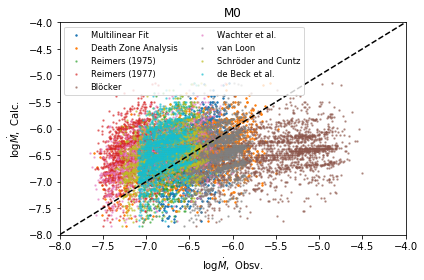


 ______________ 

Dust-Fitting Results: (array([-5.12781483, -0.79363455]), 0.7936345478649771, Intercept    0.059337
x            0.009167
dtype: float64,            Intercept         x
Intercept   0.140418  0.021653
x           0.021653  0.003351)
Death Zone-Fitting Results: (array([-3.53575329, -0.54723036]), 0.25628460625204885, Intercept    0.136682
x            0.021116
dtype: float64,            Intercept         x
Intercept   0.140418  0.021653
x           0.021653  0.003351)
Reimers 1975 Results: (array([-5.79241547, -0.86032631]), 0.8006108160021924, Intercept    0.062951
x            0.009725
dtype: float64,            Intercept         x
Intercept   0.140418  0.021653
x           0.021653  0.003351)
Reimers 1977 Results: (array([-6.24834743, -0.86032631]), 0.8006108160021923, Intercept    0.062951
x            0.009725
dtype: float64,            Intercept         x
Intercept   0.140418  0.021653
x           0.021653  0.003351)
Bloecker Results: (array([-3.14029839, -0.6328

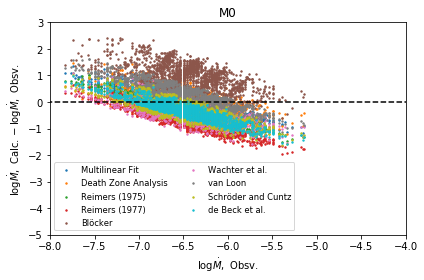


 ______________ 



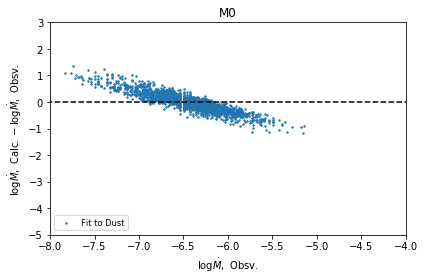


 ______________ 



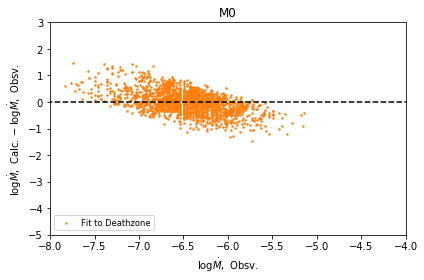


 ______________ 



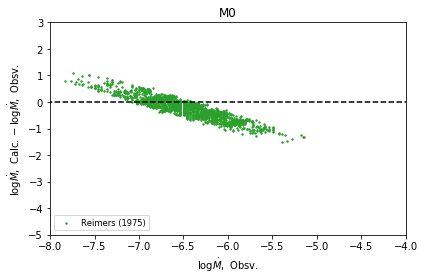


 ______________ 



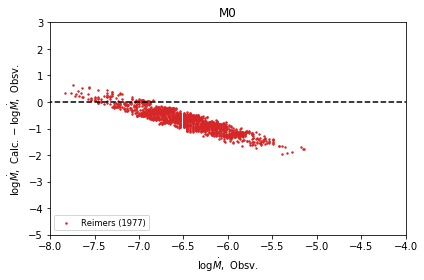


 ______________ 



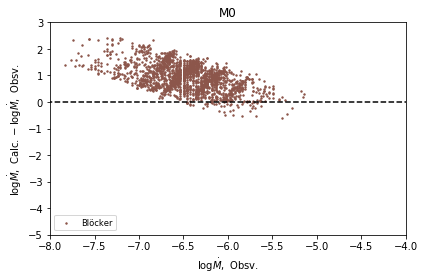


 ______________ 



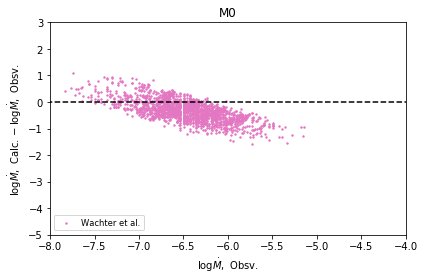


 ______________ 



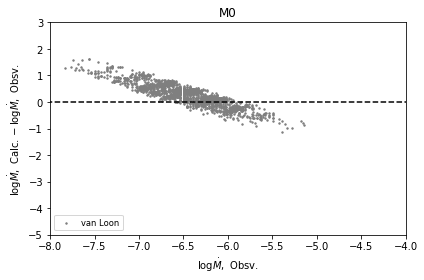


 ______________ 



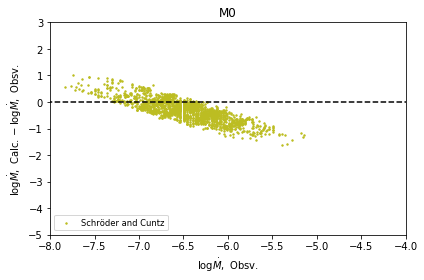


 ______________ 



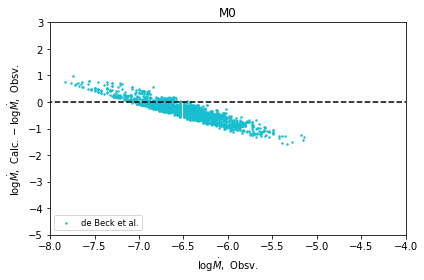


 ______________ 



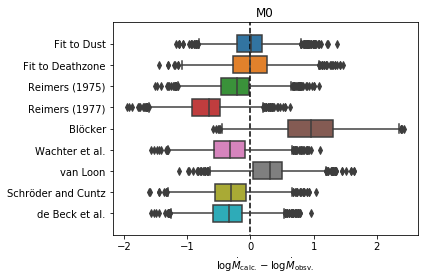

Point List: [[-7.8366895110363135, 1.3395942444455295], [-7.8366895110363135, 0.8437111625216405], [-5.137719506700295, -1.298284676570706], [-5.137719506700295, -0.8024015946468168]]
x-values: [-7.83668951 -5.13771951] 
 y-values: [[ 1.33959424 -0.80240159]
 [ 0.84371116 -1.29828468]]
Point List: [[-7.8366895110363135, 1.3923466581108839], [-7.8366895110363135, 0.11309562529973682], [-5.137719506700295, -1.3638627043819458], [-5.137719506700295, -0.08461167157079874]]
x-values: [-7.83668951 -5.13771951] 
 y-values: [[ 1.39234666 -0.08461167]
 [ 0.11309563 -1.3638627 ]]
Point List: [[-7.8366895110363135, 1.2042626234990834], [-7.8366895110363135, 0.6951268419225336], [-5.137719506700295, -1.626868074655202], [-5.137719506700295, -1.1177322930786522]]
x-values: [-7.83668951 -5.13771951] 
 y-values: [[ 1.20426262 -1.11773229]
 [ 0.69512684 -1.62686807]]
Point List: [[-7.8366895110363135, 0.7483306678493564], [-7.8366895110363135, 0.23919488627280483], [-5.137719506700295, -2.082800030304

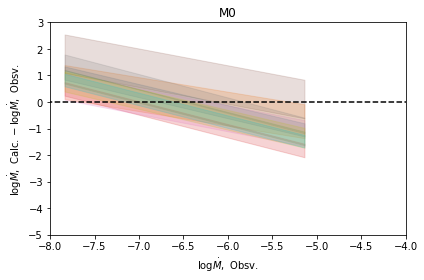


 ______________ 

log Mdot ~ logL + logP:
LRM form: logMdot = -14.090671442964444  +  1.4758349824618766 logL + logR - 2.253190194588611 logM
LM form: logMdot = -14.331671442964444  +  2.1658349824618766 logL - 2.504190194588611 logM
______________
log Mdot ~ logL + logM
LM form: logMdot = -24.06376137107629  +  4.887456400464315 logL - 5.273790150496492 logM
______________
Reimers 1975 LRM form: logMdot = -12.397940008672037 + logL + logR - logM
Reimers 1975 LM form: logMdot = -12.638940008672037 + 1.69 logL -  1.251 logM
______________
Reimers 1977 LRM form: logMdot = -12.853871964321762 + logL + logR - logM
Reimers 1977 LM form: logMdot = -13.094871964321761 + 1.69 logL -  1.251 logM
______________
VW LRM form: N/A
VW LM form apprx.: -20.133427587831438 + 2.7597899069390692 logL - 2.398954272614154 logM
______________
Bloecker LRM form: logMdot = -20.713992877920525 +3.7logL + logR - 3.1logM
Bloecker LM form: logMdot = -20.954992877920525 + 4.390000000000001 logL -  3.351 logM
____

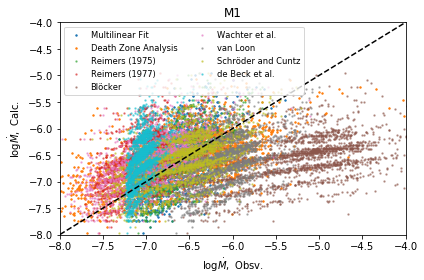


 ______________ 

Dust-Fitting Results: (array([-4.32854911, -0.65707902]), 0.6570790219180425, Intercept    0.067435
x            0.010214
dtype: float64,            Intercept         x
Intercept   0.102578  0.015501
x           0.015501  0.002353)
Death Zone-Fitting Results: (array([-1.3195985 , -0.20031666]), 0.0314687362355921, Intercept    0.157875
x            0.023912
dtype: float64,            Intercept         x
Intercept   0.102578  0.015501
x           0.015501  0.002353)
Reimers 1975 Results: (array([-4.5088404 , -0.68371633]), 0.6744685034117281, Intercept    0.067479
x            0.010220
dtype: float64,            Intercept         x
Intercept   0.102578  0.015501
x           0.015501  0.002353)
Reimers 1977 Results: (array([-4.96477236, -0.68371633]), 0.6744685034117281, Intercept    0.067479
x            0.010220
dtype: float64,            Intercept         x
Intercept   0.102578  0.015501
x           0.015501  0.002353)
Bloecker Results: (array([ 0.11701374, -0.18545

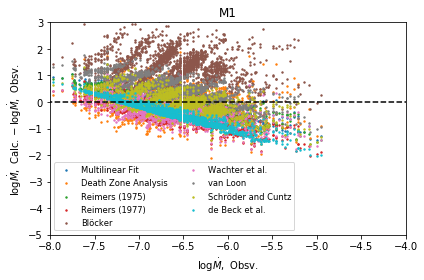


 ______________ 



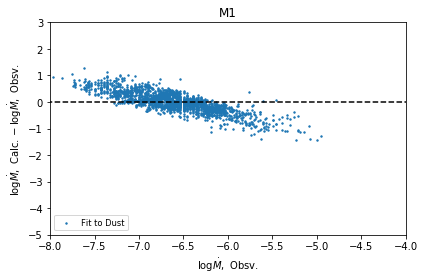


 ______________ 



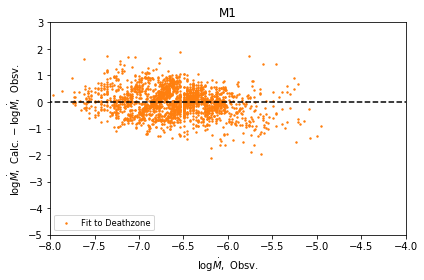


 ______________ 



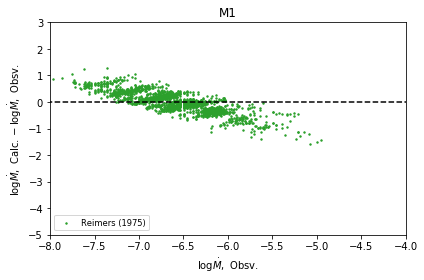


 ______________ 



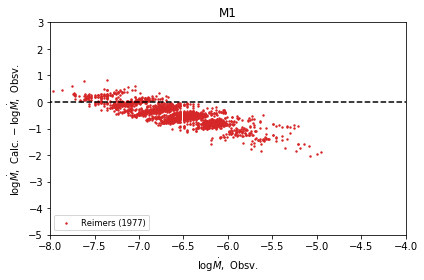


 ______________ 



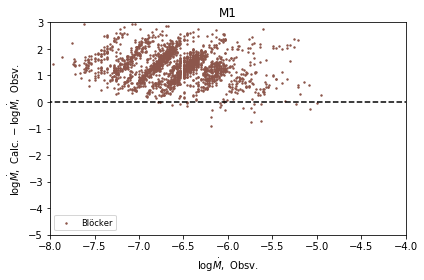


 ______________ 



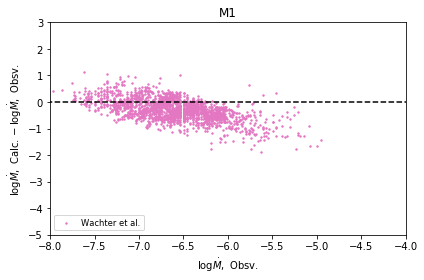


 ______________ 



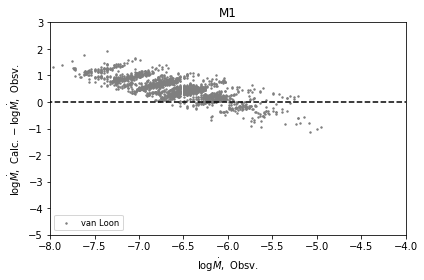


 ______________ 



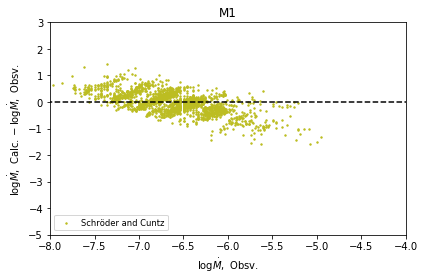


 ______________ 



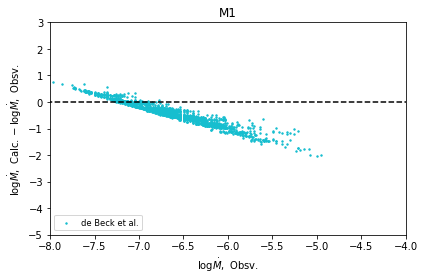


 ______________ 



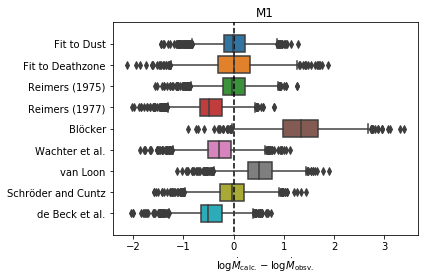

Point List: [[-7.967457791305338, 1.2584661767135188], [-7.967457791305338, 0.5549343533517312], [-4.955875918755522, -1.4239129178894068], [-4.955875918755522, -0.7203810945276192]]
x-values: [-7.96745779 -4.95587592] 
 y-values: [[ 1.25846618 -0.72038109]
 [ 0.55493435 -1.42391292]]
Point List: [[-7.967457791305338, 1.2426294055735319], [-7.967457791305338, -0.6897973700485815], [-4.955875918755522, -1.293067385037419], [-4.955875918755522, 0.6393593905846943]]
x-values: [-7.96745779 -4.95587592] 
 y-values: [[ 1.24262941  0.63935939]
 [-0.68979737 -1.29306739]]
Point List: [[-7.967457791305338, 1.2863282517966468], [-7.967457791305338, 0.5909529726634215], [-4.955875918755522, -1.4681147384080218], [-4.955875918755522, -0.7727394592747965]]
x-values: [-7.96745779 -4.95587592] 
 y-values: [[ 1.28632825 -0.77273946]
 [ 0.59095297 -1.46811474]]
Point List: [[-7.967457791305338, 0.8303962961469153], [-7.967457791305338, 0.13502101701369007], [-4.955875918755522, -1.9240466940577505], [-

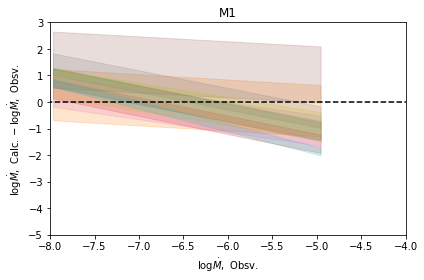


 ______________ 

log Mdot ~ logL + logP:
LRM form: logMdot = -14.779464244877559  +  1.47292367511773 logL + logR - 1.9670226554375763 logM
LM form: logMdot = -15.10246424487756  +  2.20992367511773 logL - 2.3380226554375763 logM
______________
log Mdot ~ logL + logM
LM form: logMdot = -22.590992140526403  +  4.203017828957615 logL - 3.6746716838314706 logM
______________
Reimers 1975 LRM form: logMdot = -12.397940008672037 + logL + logR - logM
Reimers 1975 LM form: logMdot = -12.720940008672038 + 1.737 logL -  1.371 logM
______________
Reimers 1977 LRM form: logMdot = -12.853871964321762 + logL + logR - logM
Reimers 1977 LM form: logMdot = -13.176871964321762 + 1.737 logL -  1.371 logM
______________
VW LRM form: N/A
VW LM form apprx.: -32.85116340847547 + 6.383442617052769 logL - 6.650025006906933 logM
______________
Bloecker LRM form: logMdot = -20.713992877920525 +3.7logL + logR - 3.1logM
Bloecker LM form: logMdot = -21.036992877920525 + 4.437 logL -  3.471 logM
______________
Wa

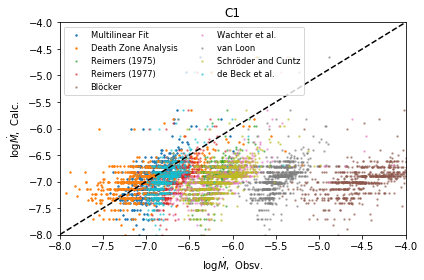


 ______________ 

Dust-Fitting Results: (array([-4.29007922, -0.61787789]), 0.6178778936298202, Intercept    0.120985
x            0.017409
dtype: float64,            Intercept         x
Intercept   0.724529  0.104166
x           0.104166  0.015002)
Death Zone-Fitting Results: (array([-1.86511475, -0.26862282]), 0.07079192862309613, Intercept    0.242318
x            0.034869
dtype: float64,            Intercept         x
Intercept   0.724529  0.104166
x           0.104166  0.015002)
Reimers 1975 Results: (array([-4.12523359, -0.69691224]), 0.7311701844793773, Intercept    0.105217
x            0.015140
dtype: float64,            Intercept         x
Intercept   0.724529  0.104166
x           0.104166  0.015002)
Reimers 1977 Results: (array([-4.58116554, -0.69691224]), 0.7311701844793772, Intercept    0.105217
x            0.015140
dtype: float64,            Intercept         x
Intercept   0.724529  0.104166
x           0.104166  0.015002)
Bloecker Results: (array([ 0.92628038, -0.2256

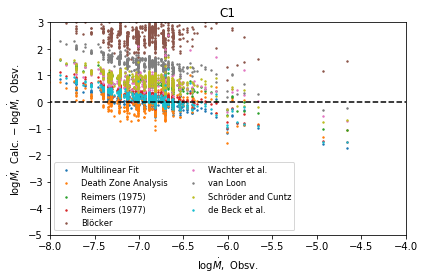


 ______________ 



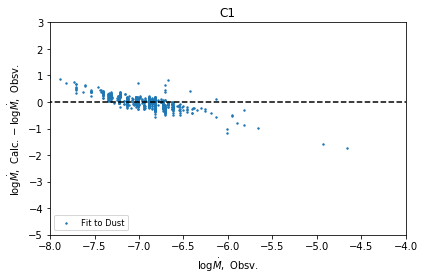


 ______________ 



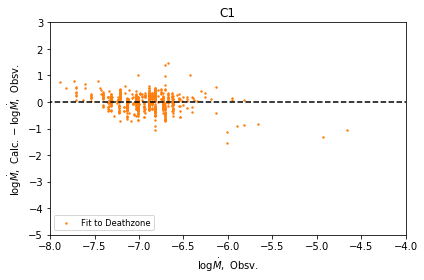


 ______________ 



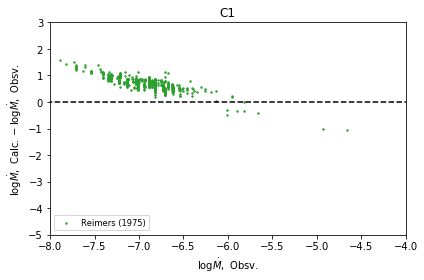


 ______________ 



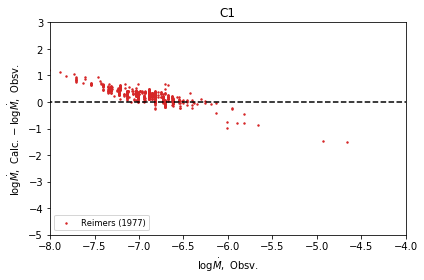


 ______________ 



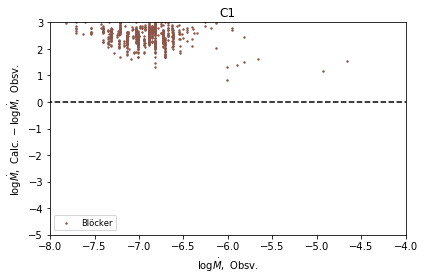


 ______________ 



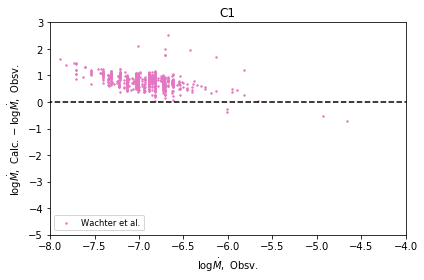


 ______________ 



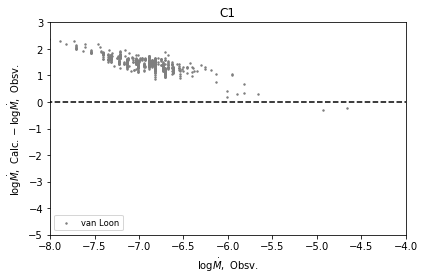


 ______________ 



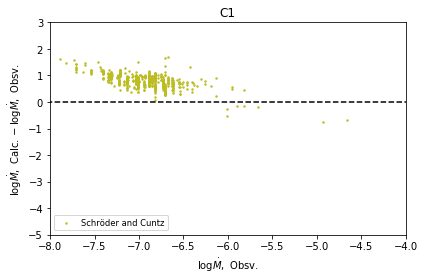


 ______________ 



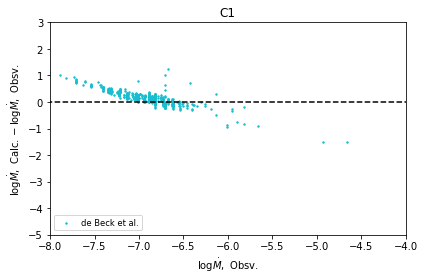


 ______________ 



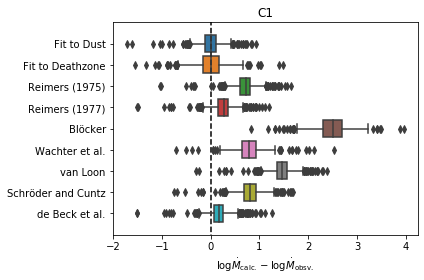

Point List: [[-8.009394788576081, 0.9002711253057445], [-8.009394788576081, 0.41722640161043323], [-4.6549204736851335, -1.6554291223097195], [-4.6549204736851335, -1.1723843986144082]]
x-values: [-8.00939479 -4.65492047] 
 y-values: [[ 0.90027113 -1.1723844 ]
 [ 0.4172264  -1.65542912]]
Point List: [[-8.009394788576081, 0.8355545972720166], [-8.009394788576081, -0.2627716840350476], [-4.6549204736851335, -1.163860031355509], [-4.6549204736851335, -0.06553375004844475]]
x-values: [-8.00939479 -4.65492047] 
 y-values: [[ 0.8355546  -0.06553375]
 [-0.26277168 -1.16386003]]
Point List: [[-8.009394788576081, 1.6591780336564068], [-8.009394788576081, 1.2540453709834685], [-4.6549204736851335, -1.0837288487433443], [-4.6549204736851335, -0.678596186070406]]
x-values: [-8.00939479 -4.65492047] 
 y-values: [[ 1.65917803 -0.67859619]
 [ 1.25404537 -1.08372885]]
Point List: [[-8.009394788576081, 1.2032460780066847], [-8.009394788576081, 0.7981134153337459], [-4.6549204736851335, -1.5396608043930

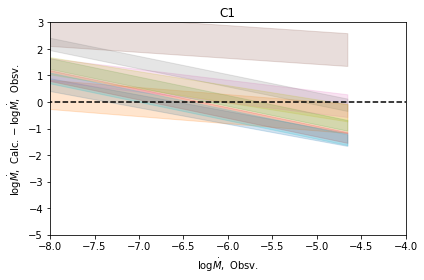


 ______________ 



In [428]:
mdot_formula_comparison (M0StarData,spec_mode_label='M0')
mdot_formula_comparison (M1StarData,spec_mode_label='M1')
mdot_formula_comparison (C1StarData,spec_mode_label='C1')

log Mdot ~ logL + logP:
LRM form: logMdot = -14.54811849748131  +  1.4764393908815636 logL + logR - 2.2509424073942057 logM
LM form: logMdot = -14.87111849748131  +  2.2134393908815637 logL - 2.6219424073942057 logM
______________
log Mdot ~ logL + logM
LM form: logMdot = -25.925639564797347  +  5.276447379609071 logL - 5.948111447513197 logM
______________
Reimers 1975 LRM form: logMdot = -12.397940008672037 + logL + logR - logM
Reimers 1975 LM form: logMdot = -12.720940008672038 + 1.737 logL -  1.371 logM
______________
Reimers 1977 LRM form: logMdot = -12.853871964321762 + logL + logR - logM
Reimers 1977 LM form: logMdot = -13.176871964321762 + 1.737 logL -  1.371 logM
______________
VW LRM form: N/A
VW LM form apprx.: -56.8342594594433 + 13.68250602352711 logL - 14.568657116242 logM
______________
Bloecker LRM form: logMdot = -20.713992877920525 +3.7logL + logR - 3.1logM
Bloecker LM form: logMdot = -21.036992877920525 + 4.437 logL -  3.471 logM
______________
Wachter LRM form: logM

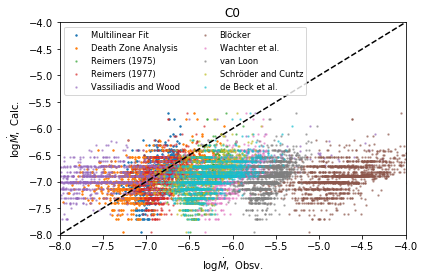


 ______________ 

Dust-Fitting Results: (array([-5.03996729, -0.72924109]), 0.7292410854748184, Intercept    0.075632
x            0.010936
dtype: float64,            Intercept         x
Intercept   0.447865  0.064715
x           0.064715  0.009364)
Death Zone-Fitting Results: (array([-2.37133822, -0.34311279]), 0.09079448529706335, Intercept    0.184805
x            0.026722
dtype: float64,            Intercept         x
Intercept   0.447865  0.064715
x           0.064715  0.009364)
Reimers 1975 Results: (array([-4.69375798, -0.7598901 ]), 0.7034998132705897, Intercept    0.083967
x            0.012141
dtype: float64,            Intercept         x
Intercept   0.447865  0.064715
x           0.064715  0.009364)
Reimers 1977 Results: (array([-5.14968993, -0.7598901 ]), 0.7034998132705896, Intercept    0.083967
x            0.012141
dtype: float64,            Intercept         x
Intercept   0.447865  0.064715
x           0.064715  0.009364)
VW Results: (array([5.1668053 , 0.81394443]), 

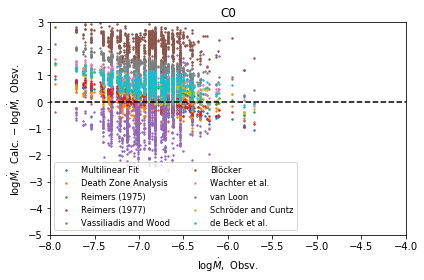


 ______________ 



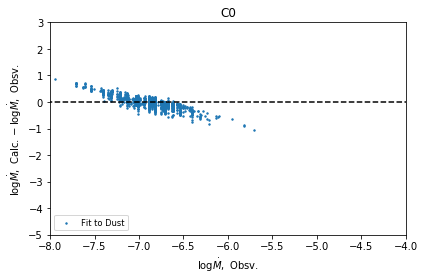


 ______________ 



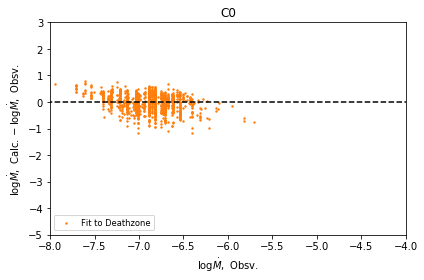


 ______________ 



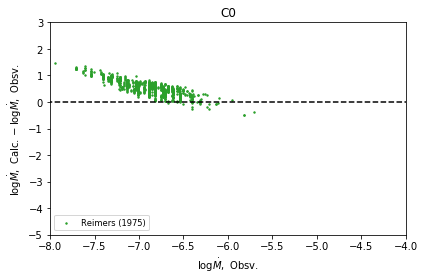


 ______________ 



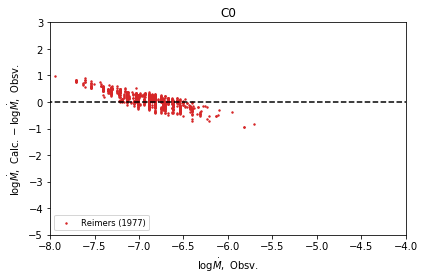


 ______________ 



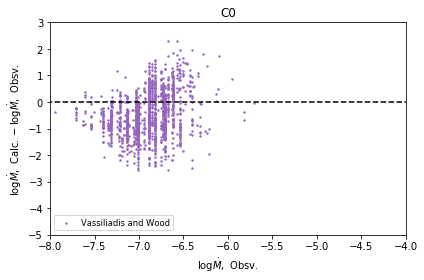


 ______________ 



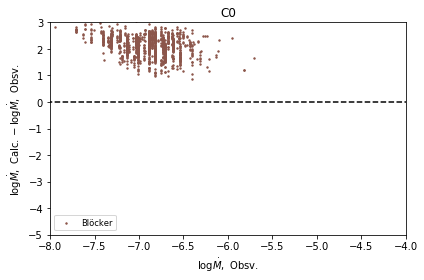


 ______________ 



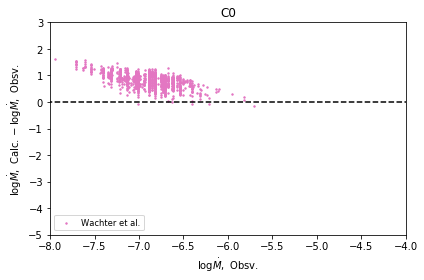


 ______________ 



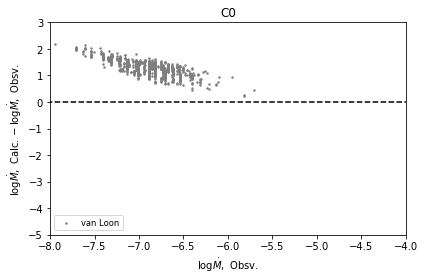


 ______________ 



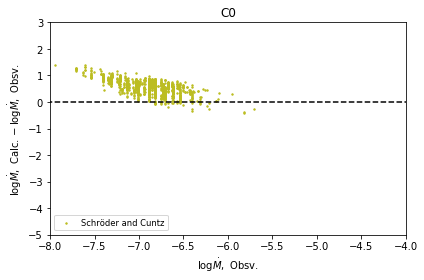


 ______________ 



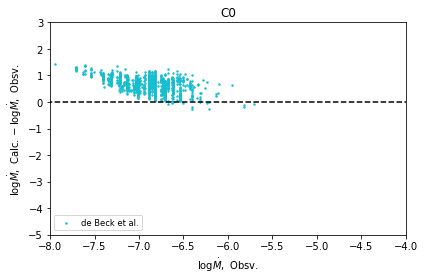


 ______________ 



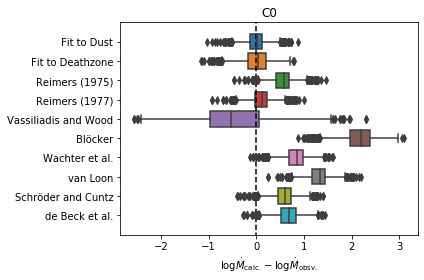

Point List: [[-7.942447998945467, 0.9345065665371335], [-7.942447998945467, 0.5694776528419832], [-5.703225153259688, -1.0634556457659272], [-5.703225153259688, -0.6984267320707769]]
x-values: [-7.942448   -5.70322515] 
 y-values: [[ 0.93450657 -0.69842673]
 [ 0.56947765 -1.06345565]]
Point List: [[-7.942447998945467, 0.8759017519080317], [-7.942447998945467, -0.1682671459043128], [-5.703225153259688, -0.9365731537079052], [-5.703225153259688, 0.10759574410443928]]
x-values: [-7.942448   -5.70322515] 
 y-values: [[ 0.87590175  0.10759574]
 [-0.16826715 -0.93657315]]
Point List: [[-7.942447998945467, 1.541305717296023], [-7.942447998945467, 1.1419534826038458], [-5.703225153259688, -0.5596097823665618], [-5.703225153259688, -0.1602575476743846]]
x-values: [-7.942448   -5.70322515] 
 y-values: [[ 1.54130572 -0.16025755]
 [ 1.14195348 -0.55960978]]
Point List: [[-7.942447998945467, 1.0853737616462986], [-7.942447998945467, 0.6860215269541214], [-5.703225153259688, -1.015541738016287], [-5

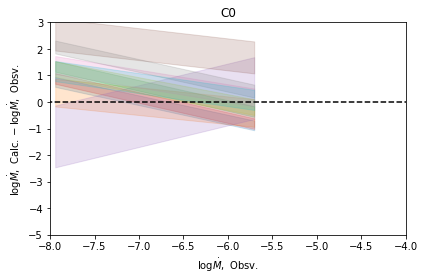


 ______________ 

log Mdot ~ logL + logP:
LRM form: logMdot = -18.512591005524992  +  2.7512165735041902 logL + logR - 3.594884381059299 logM
LM form: logMdot = -18.835591005524993  +  3.4882165735041903 logL - 3.965884381059299 logM
______________
log Mdot ~ logL + logM
LM form: logMdot = -40.49983892150037  +  9.40165901426434 logL - 10.918270658522166 logM
______________
Reimers 1975 LRM form: logMdot = -12.397940008672037 + logL + logR - logM
Reimers 1975 LM form: logMdot = -12.720940008672038 + 1.737 logL -  1.371 logM
______________
Reimers 1977 LRM form: logMdot = -12.853871964321762 + logL + logR - logM
Reimers 1977 LM form: logMdot = -13.176871964321762 + 1.737 logL -  1.371 logM
______________
VW LRM form: N/A
VW LM form apprx.: -68.28395730979759 + 16.815950951454685 logL - 17.68417570655686 logM
______________
Bloecker LRM form: logMdot = -20.713992877920525 +3.7logL + logR - 3.1logM
Bloecker LM form: logMdot = -21.036992877920525 + 4.437 logL -  3.471 logM
______________


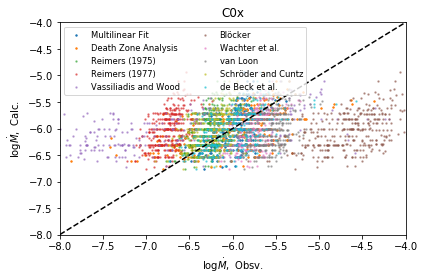


 ______________ 

Dust-Fitting Results: (array([-4.21009746, -0.69842383]), 0.6984238309652573, Intercept    0.150497
x            0.024926
dtype: float64,            Intercept         x
Intercept   0.915662  0.151415
x           0.151415  0.025119)
Death Zone-Fitting Results: (array([-1.28778619, -0.21363414]), 0.0307497915714261, Intercept    0.393312
x            0.065143
dtype: float64,            Intercept         x
Intercept   0.915662  0.151415
x           0.151415  0.025119)
Reimers 1975 Results: (array([-4.994145  , -0.78414046]), 0.8030822948394556, Intercept    0.127329
x            0.021089
dtype: float64,            Intercept         x
Intercept   0.915662  0.151415
x           0.151415  0.025119)
Reimers 1977 Results: (array([-5.45007696, -0.78414046]), 0.8030822948394556, Intercept    0.127329
x            0.021089
dtype: float64,            Intercept         x
Intercept   0.915662  0.151415
x           0.151415  0.025119)
VW Results: (array([3.25461789, 0.61242616]), 0

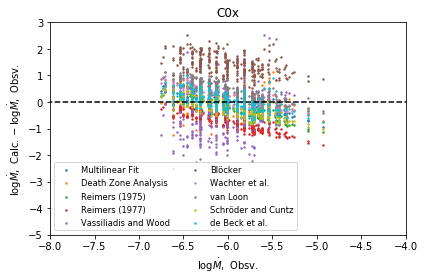


 ______________ 



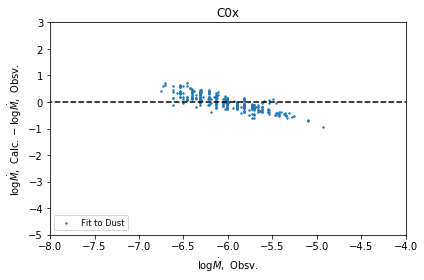


 ______________ 



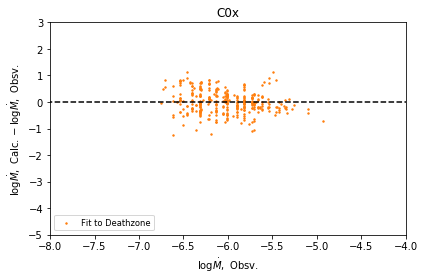


 ______________ 



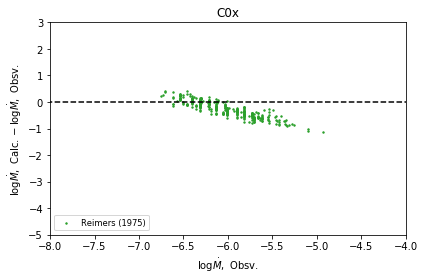


 ______________ 



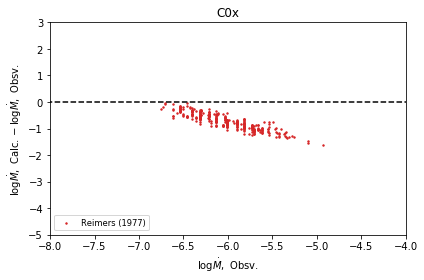


 ______________ 



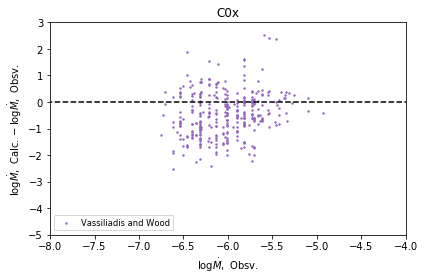


 ______________ 



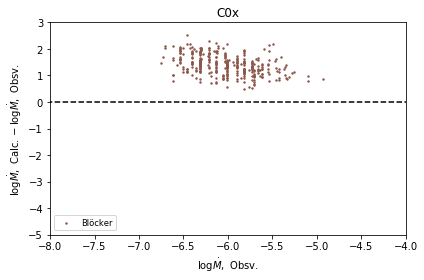


 ______________ 



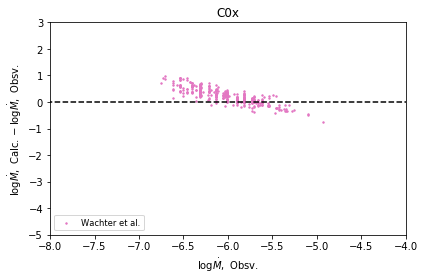


 ______________ 



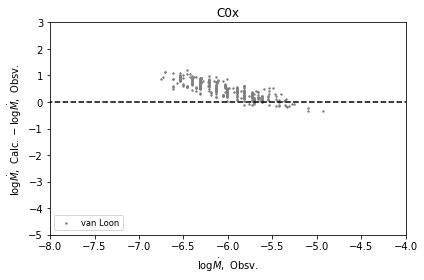


 ______________ 



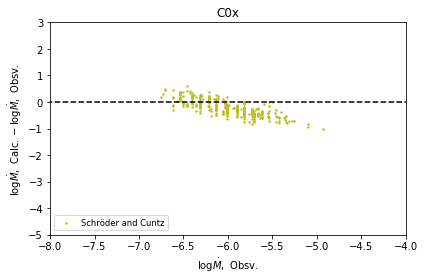


 ______________ 



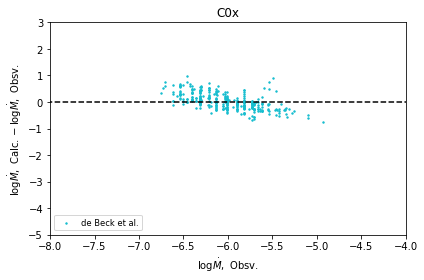


 ______________ 



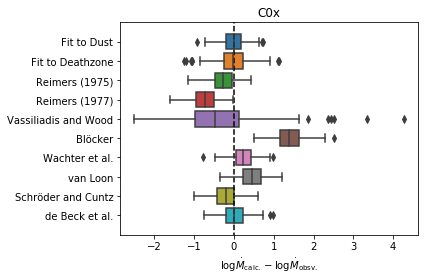

Point List: [[-6.757582815582281, 0.7666825545301084], [-6.757582815582281, 0.2524362795498707], [-4.933674074637962, -1.0214250506314801], [-4.933674074637962, -0.5071787756512425]]
x-values: [-6.75758282 -4.93367407] 
 y-values: [[ 0.76668255 -0.50717878]
 [ 0.25243628 -1.02142505]]
Point List: [[-6.757582815582281, 0.9574155210214621], [-6.757582815582281, -0.6456870708261802], [-4.933674074637962, -1.0353362510217554], [-4.933674074637962, 0.5677663408258868]]
x-values: [-6.75758282 -4.93367407] 
 y-values: [[ 0.95741552  0.56776634]
 [-0.64568707 -1.03533625]]
Point List: [[-6.757582815582281, 0.5135543321137597], [-6.757582815582281, 0.09594385488715851], [-4.933674074637962, -1.334256783294013], [-4.933674074637962, -0.9166463060674119]]
x-values: [-6.75758282 -4.93367407] 
 y-values: [[ 0.51355433 -0.91664631]
 [ 0.09594385 -1.33425678]]
Point List: [[-6.757582815582281, 0.057622376464032676], [-6.757582815582281, -0.3599881007625685], [-4.933674074637962, -1.7901887389437405],

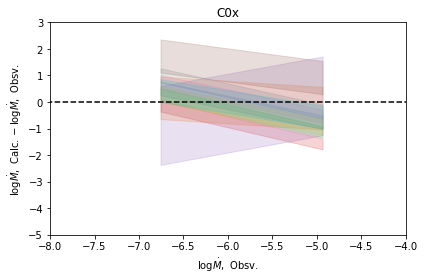


 ______________ 



In [429]:
mdot_formula_comparison (C0StarData_n,spec_mode_label='C0')
mdot_formula_comparison (C0StarData_x,spec_mode_label='C0x')

C0 and C0x
Data set 0 :
log Mdot ~ logL + logP:
LRM form: logMdot = -14.54811849748131  +  1.4764393908815636 logL + logR - 2.2509424073942057 logM
LM form: logMdot = -14.87111849748131  +  2.2134393908815637 logL - 2.6219424073942057 logM
Data set 1 :
log Mdot ~ logL + logP:
LRM form: logMdot = -18.512591005524992  +  2.7512165735041902 logL + logR - 3.594884381059299 logM
LM form: logMdot = -18.835591005524993  +  3.4882165735041903 logL - 3.965884381059299 logM
______________
log Mdot ~ logL + logM
LM form: logMdot = -34.76628082574503  +  7.786478388592237 logL - 9.619854377543422 logM
______________
Reimers 1975 LRM form: logMdot = -12.397940008672037 + logL + logR - logM
Reimers 1975 LM form: logMdot = -12.720940008672038 + 1.737 logL -  1.371 logM
______________
Reimers 1977 LRM form: logMdot = -12.853871964321762 + logL + logR - logM
Reimers 1977 LM form: logMdot = -13.176871964321762 + 1.737 logL -  1.371 logM
______________
VW LRM form: N/A
VW LM form apprx.: -59.001429162154

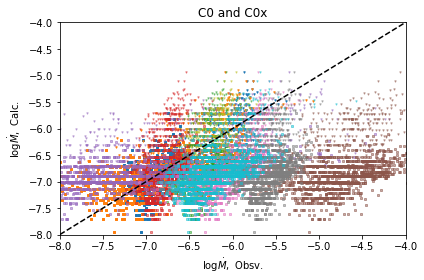


 ______________ 

Dust-Fitting Results: (array([-1.94599718, -0.28786079]), 0.2878607942339241, Intercept    0.068717
x            0.010144
dtype: float64,            Intercept         x
Intercept   0.124979  0.018413
x           0.018413  0.002724)
Death Zone-Fitting Results: (array([-1.75666712, -0.25985423]), 0.07741879359720316, Intercept    0.136144
x            0.020099
dtype: float64,            Intercept         x
Intercept   0.124979  0.018413
x           0.018413  0.002724)
Reimers 1975 Results: (array([-5.44685878, -0.86739126]), 0.8889814567224048, Intercept    0.046522
x            0.006868
dtype: float64,            Intercept         x
Intercept   0.124979  0.018413
x           0.018413  0.002724)
Reimers 1977 Results: (array([-5.90279074, -0.86739126]), 0.8889814567224048, Intercept    0.046522
x            0.006868
dtype: float64,            Intercept         x
Intercept   0.124979  0.018413
x           0.018413  0.002724)
VW Results: (array([1.69339067, 0.31778412]), 

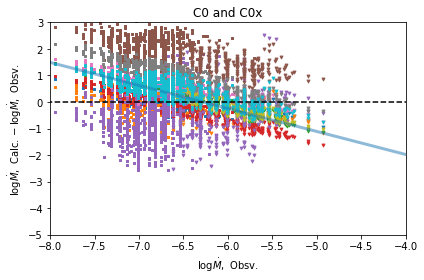


 ______________ 

len(logMdotData[k]): 1654
len(residual_list[k][i]): 1654
len(logMdotData[k]): 341
len(residual_list[k][i]): 341


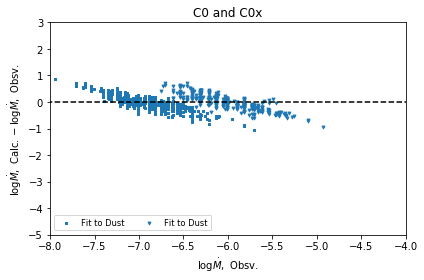


 ______________ 

len(logMdotData[k]): 1654
len(residual_list[k][i]): 1654
len(logMdotData[k]): 341
len(residual_list[k][i]): 341


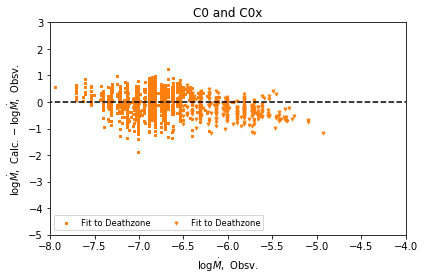


 ______________ 

len(logMdotData[k]): 1654
len(residual_list[k][i]): 1654
len(logMdotData[k]): 341
len(residual_list[k][i]): 341


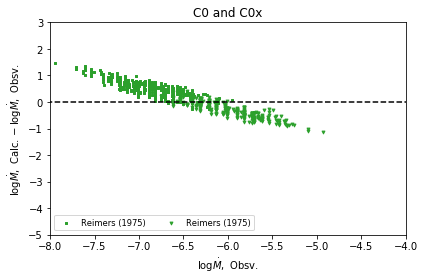


 ______________ 

len(logMdotData[k]): 1654
len(residual_list[k][i]): 1654
len(logMdotData[k]): 341
len(residual_list[k][i]): 341


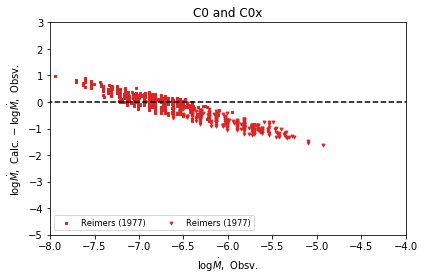


 ______________ 

len(logMdotData[k]): 1654
len(residual_list[k][i]): 1654
len(logMdotData[k]): 341
len(residual_list[k][i]): 341


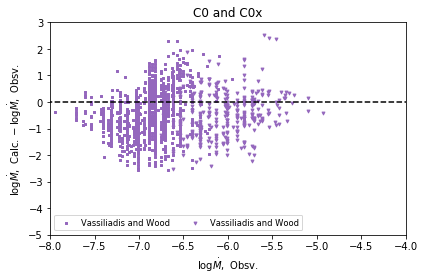


 ______________ 

len(logMdotData[k]): 1654
len(residual_list[k][i]): 1654
len(logMdotData[k]): 341
len(residual_list[k][i]): 341


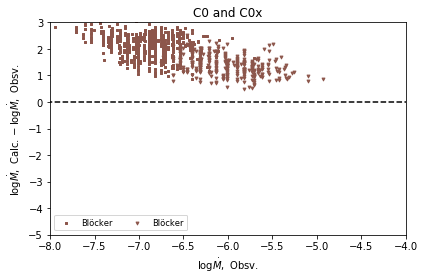


 ______________ 

len(logMdotData[k]): 1654
len(residual_list[k][i]): 1654
len(logMdotData[k]): 341
len(residual_list[k][i]): 341


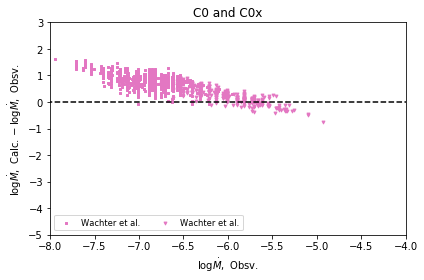


 ______________ 

len(logMdotData[k]): 1654
len(residual_list[k][i]): 1654
len(logMdotData[k]): 341
len(residual_list[k][i]): 341


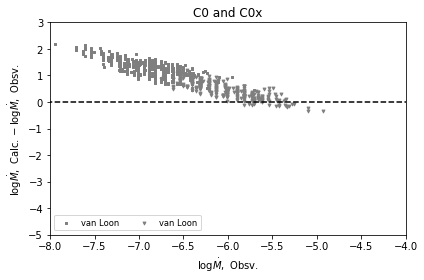


 ______________ 

len(logMdotData[k]): 1654
len(residual_list[k][i]): 1654
len(logMdotData[k]): 341
len(residual_list[k][i]): 341


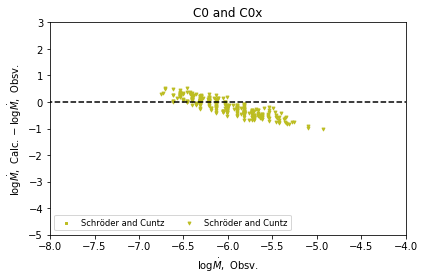


 ______________ 

len(logMdotData[k]): 1654
len(residual_list[k][i]): 1654
len(logMdotData[k]): 341
len(residual_list[k][i]): 341


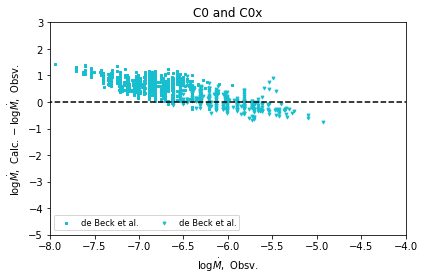


 ______________ 



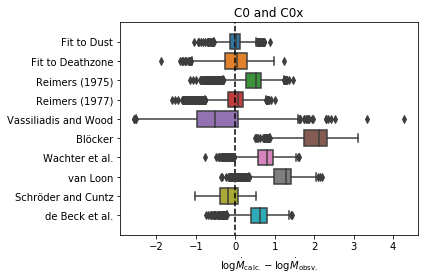


 ______________ 



In [430]:
mdot_formula_comparison_multidata ([C0StarData_n, C0StarData_x],spec_mode_label_list=['C0', 'C0x'],marker_size=8)

# Method does not work. Saved for archival purposes.
def deathline_analysis_use_const_mdot (star_data,spec_mode_label = ''):
    # Find deathzone using lines of pseudo-constant Mdot
    bound_line_1_indices = []
    bound_line_2_indices = []
    i = 0
    while i < len(star_data[MdotIndex]):
        if np.log10(star_data[MdotIndex][i]) < -7.4:
            i +=1
        elif np.log10(star_data[MdotIndex][i]) > -7.3:
            i +=1
        else:
            bound_line_1_indices.append(i)
            i +=1
    i = 0
    while i < len(star_data[MdotIndex]):
        if np.log10(star_data[MdotIndex][i]) < -5.15:
            i +=1
        elif np.log10(star_data[MdotIndex][i]) > -5.05:
            i +=1
        else:
            bound_line_2_indices.append(i)
            i +=1
    print(bound_line_1_indices)
    print(bound_line_2_indices)
    
    
    
    
    plot.scatter(star_data[LIndex], star_data[MIndex],s=2)
    plot.scatter(star_data[LIndex][bound_line_1_indices], star_data[MIndex][bound_line_1_indices],s=10,color='purple')
    plot.scatter(star_data[LIndex][bound_line_2_indices], star_data[MIndex][bound_line_2_indices],s=10,color='red')
    #plot.plot(10**line_x_vals,10**line_y_vals,linestyle='--',color='black')
    #plot.plot(10**line_x_vals,10**line_y_vals_up,linestyle='--',color='red')
    #plot.plot(10**line_x_vals,10**line_y_vals_down,linestyle='--',color='red')
    #plot.errorbar(star_data[LIndex],star_data[MIndex],xerr=star_data[LErrorIndex],fmt='none',markersize=1)
    plot.xscale('log')
    plot.yscale('log')
    plot.xlabel(r'$L$')
    plot.ylabel(r'$M$')
    plot.title(spec_mode_label)
    '''
    # Find width of deltaLogL and deltaLogM using fit line, and plot them
    logL_left = (np.average(line_y_vals) - deathline_coeffs[0]-std_multiplier*np.nanstd(np.log10(star_data[MIndex])))/deathline_coeffs[1]
    logL_right = (np.average(line_y_vals) - deathline_coeffs[0]+std_multiplier*np.nanstd(np.log10(star_data[MIndex])))/deathline_coeffs[1]
    delta_logL = logL_right - logL_left
    print('∆logL =',delta_logL)
    plot.plot([10**logL_left,10**logL_right],[10**(np.average(line_y_vals)),10**(np.average(line_y_vals))],color='purple')
    delta_logM = line_y_vals_up[1] - line_y_vals_down[1]
    print('∆logM =',delta_logM)
    plot.vlines(10**np.average(line_x_vals),10**(np.average(line_y_vals)-delta_logM/2),10**(np.average(line_y_vals)+delta_logM/2),color='green',linestyle='-')
    # Using data, calculate deltaLogMdot
    delta_logMdot = np.nanmax(np.log10(star_data[MdotIndex])) - np.nanmin(np.log10(star_data[MdotIndex]))
    print('∆logMdot =',delta_logMdot)
    # Calculate B = deltaLogMdot/deltaLogL and C = deltaLogMdot/deltaLogM
    B = delta_logMdot/delta_logL
    C = delta_logMdot/delta_logM
    print('For set '+spec_mode_label+', B=',B, ', C=',C )
    '''
    plot.show()
    plot.close()

In [431]:
def sort_data (stellar_data,sorting_index,num_bins=2):
    a = stellar_data[sorting_index]
    ind=np.argsort(a)
    sorted_data=np.asarray(np.transpose(combined_data_set)[ind])
    
    return np.array_split(sorted_data,num_bins)

def deathline_analysis_use_bins (star_data,sorting_index,num_bins=2,spec_mode_label = ''):
    # Find deathzone using lines through bins
    sorted_data = sort_data(star_data, sorting_index, num_bins = num_bins)
    for i in range (0, len(sorted_data)):
        bin_label = str(np.log10(np.nanmin(np.transpose(sorted_data[i])[MdotIndex])))[0:7] + '<Mdot<' + str(np.log10(np.nanmax(np.transpose(sorted_data[i])[MdotIndex])))[0:7]
        plot.scatter(np.transpose(sorted_data[i])[LIndex], np.transpose(sorted_data[i])[MIndex],s=2,label=bin_label)

    plot.xscale('log')
    plot.yscale('log')
    plot.xlabel(r'$L$')
    plot.ylabel(r'$M$')
    plot.title(spec_mode_label)
    plot.legend()
    '''
    # Find width of deltaLogL and deltaLogM using fit line, and plot them
    logL_left = (np.average(line_y_vals) - deathline_coeffs[0]-std_multiplier*np.nanstd(np.log10(star_data[MIndex])))/deathline_coeffs[1]
    logL_right = (np.average(line_y_vals) - deathline_coeffs[0]+std_multiplier*np.nanstd(np.log10(star_data[MIndex])))/deathline_coeffs[1]
    delta_logL = logL_right - logL_left
    print('∆logL =',delta_logL)
    plot.plot([10**logL_left,10**logL_right],[10**(np.average(line_y_vals)),10**(np.average(line_y_vals))],color='purple')
    delta_logM = line_y_vals_up[1] - line_y_vals_down[1]
    print('∆logM =',delta_logM)
    plot.vlines(10**np.average(line_x_vals),10**(np.average(line_y_vals)-delta_logM/2),10**(np.average(line_y_vals)+delta_logM/2),color='green',linestyle='-')
    # Using data, calculate deltaLogMdot
    delta_logMdot = np.nanmax(np.log10(star_data[MdotIndex])) - np.nanmin(np.log10(star_data[MdotIndex]))
    print('∆logMdot =',delta_logMdot)
    # Calculate B = deltaLogMdot/deltaLogL and C = deltaLogMdot/deltaLogM
    B = delta_logMdot/delta_logL
    C = delta_logMdot/delta_logM
    print('For set '+spec_mode_label+', B=',B, ', C=',C )
    '''
    plot.show()
    plot.close()

deathline_analysis_use_bins (combined_data_set, MdotIndex, num_bins = 3, spec_mode_label = 'All Stars')

In [432]:
c0_true_mdots = deathzone_values_C0[0] + deathzone_values_C0[1]*np.log10(C0StarData_n[LIndex]) - deathzone_values_C1[2]*np.log10(C0StarData_n[MIndex])

In [433]:
np.nanmin(c0_true_mdots)

-9.001317294051594

In [434]:
np.nanmax(c0_true_mdots)

-0.6402286071033969

In [435]:
def deathzone_mlr_check (star_data, deathzone_ABC,spec_mode_label):
    
    print(spec_mode_label+':')
    logLData = np.log10(star_data[LIndex])
    logMData = np.log10(star_data[MIndex])
    logPData = np.log10(star_data[PIndex])
    logRData = np.log10(star_data[RIndex])
    logTData = np.log10(star_data[TeffCalcIndex])
    logMdotData = np.log10(star_data[MdotIndex])
    
    color_list = ['tab:blue','tab:orange','tab:green','tab:red','tab:purple','tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
    
    # log Mdot = A + BlogL + ClogP
    if spec_mode_label[0] == 'M':
        RLM = RLM_M
    if spec_mode_label[0] == 'C':
        RLM = RLM_C
    if spec_mode_label == 'M0':
        PMR = PMR_M0
    if spec_mode_label == 'M1':
        PMR = PMR_M1
    if spec_mode_label == 'C0':
        PMR = PMR_C0
    if spec_mode_label == 'C0x':
        PMR = PMR_C0
    if spec_mode_label == 'C0 and C0x':
        PMR = PMR_C0
    if spec_mode_label == 'C1':
        PMR = PMR_C1
    # Take stellar data and associated death zone analysis results to see if we get MLR fit results similar to fitting to 
    # dust mass loss rate directly, or if we recover our deathzone formulas
    calculated_mdot = deathzone_ABC[0] + deathzone_ABC[1]*logLData + deathzone_ABC[2]*logMData
    
    
    print('Death Zone Values:',deathzone_ABC)
    
    artificial_fit = multilinear_fit_2var([logLData,logPData],calculated_mdot)
    LPCoeffs = artificial_fit[0]
    a = LPCoeffs[0]
    arlm = RLM[0]
    aRLM = arlm
    apmr = PMR[0]
    aPMR = apmr
    c = LPCoeffs[2]
    cpmr = PMR[2]
    cPMR = cpmr
    b = LPCoeffs[1]
    brlm = RLM[1]
    bRLM = brlm
    bpmr = PMR[1]
    bPMR = bpmr
    crlm = RLM[2]
    cRLM = crlm
    PMLCoeffs = calculate_PML_coeffs(RLM, PMR)
    aPML = PMLCoeffs[0]
    bPML = PMLCoeffs[1]
    cPML = PMLCoeffs[2]
    
    Anew = a - arlm + apmr*c + arlm*c*cpmr
    Bnew = b - brlm + brlm*c*cpmr 
    Cnew = bpmr*c - crlm + c*cpmr*crlm
    print('Death Zone Mdot Fit:',artificial_fit[0])
    print('     LM form: logMdot =',Anew+arlm,' + ',Bnew+brlm,'logL -',-(Cnew+crlm),'logM')
    
    
    data_fit = multilinear_fit_2var([logLData,logPData],logMdotData)
    LPCoeffs = data_fit[0]
    a = LPCoeffs[0]
    arlm = RLM[0]
    aRLM = arlm
    apmr = PMR[0]
    aPMR = apmr
    c = LPCoeffs[2]
    cpmr = PMR[2]
    cPMR = cpmr
    b = LPCoeffs[1]
    brlm = RLM[1]
    bRLM = brlm
    bpmr = PMR[1]
    bPMR = bpmr
    crlm = RLM[2]
    cRLM = crlm
    PMLCoeffs = calculate_PML_coeffs(RLM, PMR)
    aPML = PMLCoeffs[0]
    bPML = PMLCoeffs[1]
    cPML = PMLCoeffs[2]
    
    Anew = a - arlm + apmr*c + arlm*c*cpmr
    Bnew = b - brlm + brlm*c*cpmr 
    Cnew = bpmr*c - crlm + c*cpmr*crlm
    print('Observed Mdot Fit:',data_fit[0])
    print('     LM form: logMdot =',Anew+arlm,' + ',Bnew+brlm,'logL -',-(Cnew+crlm),'logM')

In [436]:

deathzone_mlr_check(M0StarData, deathzone_values_M0,'M0')
print('\n')


deathzone_mlr_check(M1StarData, deathzone_values_M1,'M1')
print('\n')


deathzone_mlr_check(C0StarData, deathzone_values_C0_and_C0x,'C0 and C0x')
print('\n')


deathzone_mlr_check(C1StarData, deathzone_values_C1, 'C1')
print('\n')

M0:
Death Zone Values: (-22.010528157677143, 4.426524721325467, -5.311766715095943)
Death Zone Mdot Fit: [-10.79207686  -1.33674216   4.12193097]
     LM form: logMdot = -22.014062777225778  +  4.428314149296414 logL - 5.313074217096397 logM
Observed Mdot Fit: [-7.38815877 -1.00566532  2.03877208]
     LM form: logMdot = -12.938730017492958  +  1.845822471134391 logL - 2.627930313100934 logM


M1:
Death Zone Values: (-24.06376137107629, 4.887456400464315, -5.273790150496492)
Death Zone Mdot Fit: [-13.01854623  -1.30444788   5.71488996]
     LM form: logMdot = -24.06182814094469  +  4.886492414910279 logL - 5.275243474162458 logM
Observed Mdot Fit: [-9.08935829 -0.77304207  2.71289306]
     LM form: logMdot = -14.331671442964444  +  2.1658349824618766 logL - 2.504190194588611 logM


C0 and C0x:
Death Zone Values: (-34.76628082574503, 7.786478388592237, -9.619854377543422)
Death Zone Mdot Fit: [-16.88297154  -1.36200312   6.07012811]
     LM form: logMdot = -34.758825044188356  +  7.7777

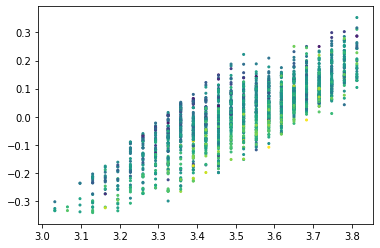

In [437]:
plot.scatter(np.log10(M0StarData[LIndex]),np.log10(M0StarData[MIndex]),c=np.log10(M0StarData[MdotIndex]),s=4)

In [438]:
print(np.nanmin(M0StarData[MdotIndex]))
print(np.nanmin(M1StarData[MdotIndex]))
print(np.nanmin(C0StarData[MdotIndex]))
print(np.nanmin(C1StarData[MdotIndex]))
print(np.nanmax(M0StarData[MdotIndex]))
print(np.nanmax(M1StarData[MdotIndex]))
print(np.nanmax(C0StarData[MdotIndex]))
print(np.nanmax(C1StarData[MdotIndex]))

1.4564999999999998e-08
1.07781e-08
1.1416999999999999e-08
9.785999999999999e-09
7.2825e-06
1.1069400000000001e-05
1.165e-05
2.2135e-05


In [439]:
np.histogram(np.log10(M0StarData[MdotIndex]),bins=8,range=(-9,-5))

(array([  0,   0,  18, 146, 636, 948, 187,  16], dtype=int64),
 array([-9. , -8.5, -8. , -7.5, -7. , -6.5, -6. , -5.5, -5. ]))

In [440]:
def bin_locations (star_mdot_data):
    # Digitize will return which bin a value falls into
    digitized_list = np.digitize(np.log10(star_mdot_data),[-10,-9,-8,-7,-6,-5,-4])
    bin_0, bin_1, bin_2, bin_3, bin_4, bin_5, bin_6 = [],[],[],[],[],[],[]
    for i in range(0, len(star_mdot_data)):
        if digitized_list[i] == 0:
            bin_0.append(i)
        elif digitized_list[i] == 1:
            bin_1.append(i)
        elif digitized_list[i] == 2:
            bin_2.append(i)
        elif digitized_list[i] == 3:
            bin_3.append(i)
        elif digitized_list[i] == 4:
            bin_4.append(i)
        elif digitized_list[i] == 5:
            bin_5.append(i)
        elif digitized_list[i] == 6:
            bin_6.append(i)
        else:
            print('Sorting Failed for index',i)
    return bin_0, bin_1, bin_2, bin_3, bin_4, bin_5, bin_6

In [441]:
def plot_binned_stellar_data (star_data, bin_list,spec_mode_label=''):
    for i in range(0, len(bin_list)):
        logLData = np.log10(star_data[LIndex][bin_list[i]])
        logMData = np.log10(star_data[MIndex][bin_list[i]])
        logMdotData = np.log10(star_data[MdotIndex][bin_list[i]])
        if len(logLData)>0:
            plot.scatter(logLData,logMData,label=str(-11+i)+'<'+r'$\log \dot{M}$'+'<'+str(-10+i),s=2)
            print('Min observed value in bin:',np.nanmin(logMdotData))
            print('Max observed value in bin:',np.nanmax(logMdotData))
        else:
            print('Bin list ',i,' is empty. Continuing to next bin.')
    plot.legend()
    plot.title(spec_mode_label)
    plot.xlabel(r'$\log L$')
    plot.ylabel(r'$\log M$')
    plot.show()
    plot.close()

In [442]:
M0_bin_ids = bin_locations (M0StarData[MdotIndex])
M1_bin_ids = bin_locations (M1StarData[MdotIndex])
C0_bin_ids = bin_locations (C0StarData[MdotIndex])
C1_bin_ids = bin_locations (C1StarData[MdotIndex])

Sorting Failed for index 0


Bin list  0  is empty. Continuing to next bin.
Bin list  1  is empty. Continuing to next bin.
Bin list  2  is empty. Continuing to next bin.
Min observed value in bin: -7.8366895110363135
Max observed value in bin: -7.004180598330078
Min observed value in bin: -6.9915914710220575
Max observed value in bin: -6.004180598330078
Min observed value in bin: -5.9915914710220575
Max observed value in bin: -5.137719506700295
Bin list  6  is empty. Continuing to next bin.


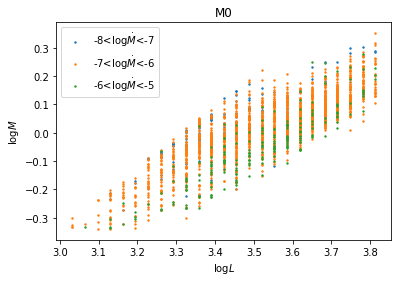

Bin list  0  is empty. Continuing to next bin.
Bin list  1  is empty. Continuing to next bin.
Bin list  2  is empty. Continuing to next bin.
Min observed value in bin: -7.967457791305338
Max observed value in bin: -7.004180598330078
Min observed value in bin: -6.9915914710220575
Max observed value in bin: -6.004180598330078
Min observed value in bin: -5.9915914710220575
Max observed value in bin: -5.073261517473377
Min observed value in bin: -4.9915914710220575
Max observed value in bin: -4.955875918755522


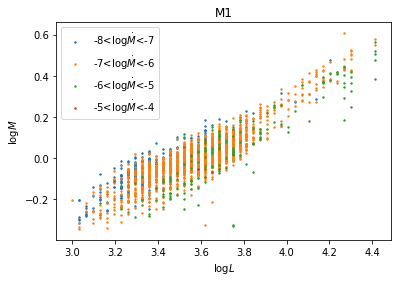

Bin list  0  is empty. Continuing to next bin.
Bin list  1  is empty. Continuing to next bin.
Bin list  2  is empty. Continuing to next bin.
Min observed value in bin: -7.942447998945467
Max observed value in bin: -7.0042551489236695
Min observed value in bin: -6.989191402487793
Max observed value in bin: -6.00939478857608
Min observed value in bin: -5.984284067993049
Max observed value in bin: -5.101165161931726
Min observed value in bin: -4.933674074637962
Max observed value in bin: -4.933674074637962


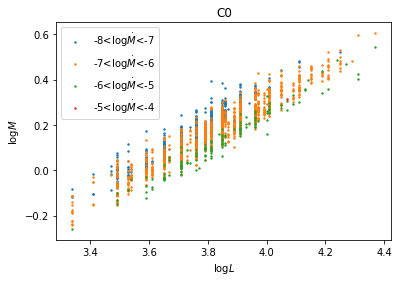

Bin list  0  is empty. Continuing to next bin.
Bin list  1  is empty. Continuing to next bin.
Min observed value in bin: -8.009394788576081
Max observed value in bin: -8.009394788576081
Min observed value in bin: -7.892281389479737
Max observed value in bin: -7.0042551489236695
Min observed value in bin: -6.984284067993049
Max observed value in bin: -6.0042551489236695
Min observed value in bin: -5.955950469349115
Max observed value in bin: -5.6549204736851335
Min observed value in bin: -4.933674074637962
Max observed value in bin: -4.6549204736851335


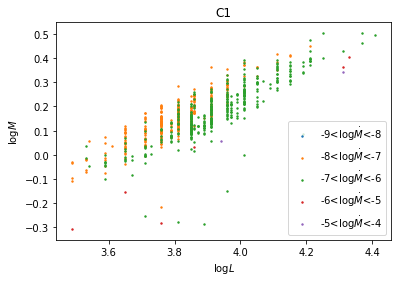

In [443]:
plot_binned_stellar_data(M0StarData,M0_bin_ids,'M0')
plot_binned_stellar_data(M1StarData,M1_bin_ids,'M1')
plot_binned_stellar_data(C0StarData,C0_bin_ids,'C0')
plot_binned_stellar_data(C1StarData,C1_bin_ids,'C1')

In [444]:
deathzone_M0_mdot = 10**(deathzone_values_M0[0] + deathzone_values_M0[1]*np.log10(M0StarData[LIndex])+ deathzone_values_M0[2]*np.log10(M0StarData[MIndex]))
deathzone_M1_mdot = 10**(deathzone_values_M1[0] + deathzone_values_M1[1]*np.log10(M1StarData[LIndex])+ deathzone_values_M1[2]*np.log10(M1StarData[MIndex]))
deathzone_C0_mdot = 10**(deathzone_values_C0[0] + deathzone_values_C0[1]*np.log10(C0StarData[LIndex])+ deathzone_values_C0[2]*np.log10(C0StarData[MIndex]))
deathzone_C1_mdot = 10**(deathzone_values_C1[0] + deathzone_values_C1[1]*np.log10(C1StarData[LIndex])+ deathzone_values_C1[2]*np.log10(C1StarData[MIndex]))

M0_bin_ids = bin_locations (deathzone_M0_mdot)
M1_bin_ids = bin_locations (deathzone_M1_mdot)
C0_bin_ids = bin_locations (deathzone_C0_mdot)
C1_bin_ids = bin_locations (deathzone_C1_mdot)

Sorting Failed for index 0


Bin list  0  is empty. Continuing to next bin.
Bin list  1  is empty. Continuing to next bin.
Bin list  2  is empty. Continuing to next bin.
Min observed value in bin: -7.8366895110363135
Max observed value in bin: -5.729479541388446
Min observed value in bin: -7.743267825874079
Max observed value in bin: -5.155448273660727
Min observed value in bin: -7.389531479694095
Max observed value in bin: -5.137719506700295
Bin list  6  is empty. Continuing to next bin.


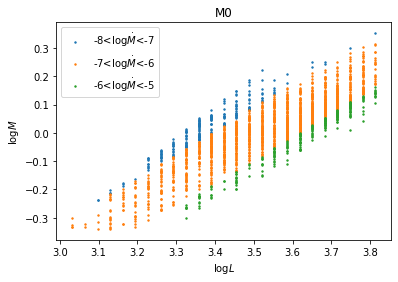

Bin list  0  is empty. Continuing to next bin.
Bin list  1  is empty. Continuing to next bin.
Min observed value in bin: -7.5671765668183975
Max observed value in bin: -6.1932368345501265
Min observed value in bin: -7.967457791305338
Max observed value in bin: -5.621845662988616
Min observed value in bin: -7.750329680361566
Max observed value in bin: -4.9915914710220575
Min observed value in bin: -7.359568256316652
Max observed value in bin: -4.955875918755522
Min observed value in bin: -6.535659515372332
Max observed value in bin: -5.213440220638414


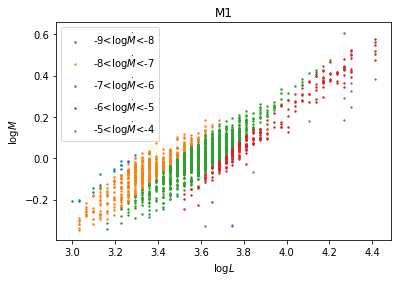

Bin list  0  is empty. Continuing to next bin.
Bin list  1  is empty. Continuing to next bin.
Min observed value in bin: -7.13433352518438
Max observed value in bin: -7.00939478857608
Min observed value in bin: -7.942447998945467
Max observed value in bin: -5.729554091982037
Min observed value in bin: -7.611454779904043
Max observed value in bin: -4.933674074637962
Min observed value in bin: -5.611454779904043
Max observed value in bin: -5.4565528199183
Bin list  6  is empty. Continuing to next bin.


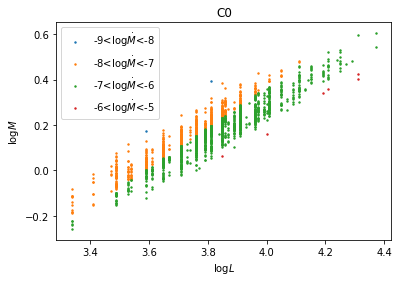

Bin list  0  is empty. Continuing to next bin.
Bin list  1  is empty. Continuing to next bin.
Bin list  2  is empty. Continuing to next bin.
Min observed value in bin: -8.009394788576081
Max observed value in bin: -6.0042551489236695
Min observed value in bin: -7.729554091982037
Max observed value in bin: -4.933674074637962
Min observed value in bin: -7.00939478857608
Max observed value in bin: -4.6549204736851335
Bin list  6  is empty. Continuing to next bin.


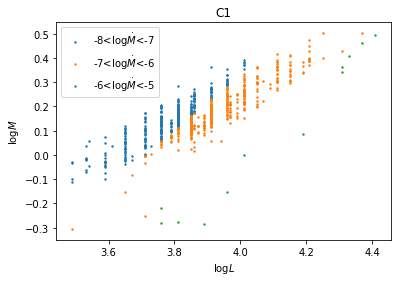

In [445]:
plot_binned_stellar_data(M0StarData,M0_bin_ids,'M0')
plot_binned_stellar_data(M1StarData,M1_bin_ids,'M1')
plot_binned_stellar_data(C0StarData,C0_bin_ids,'C0')
plot_binned_stellar_data(C1StarData,C1_bin_ids,'C1')

In [446]:
def quick_mlr_fit(star_data):
    logLData = np.log10(star_data[LIndex])
    logPData = np.log10(star_data[PIndex])
    logMdotData = np.log10(star_data[MdotIndex])
    fit = multilinear_fit_2var([logLData,logPData],logMdotData)
    return fit

In [447]:
quick_mlr_fit(M0StarData)

(array([-7.38815877, -1.00566532,  2.03877208]),
 0.20636545213502622,
 Intercept    0.168589
 x0           0.076281
 x1           0.093964
 dtype: float64,
            Intercept        x0        x1
 Intercept   0.233797 -0.067902  0.002839
 x0         -0.067902  0.047865 -0.045992
 x1          0.002839 -0.045992  0.072627)

In [448]:
coeffs_M0 = quick_mlr_fit(M0StarData)[0]
coeffs_M1 = quick_mlr_fit(M1StarData)[0]
coeffs_C0 = quick_mlr_fit(C0StarData)[0]
coeffs_C1 = quick_mlr_fit(C1StarData)[0]

In [449]:
dustfit_M0_mdot = 10**(coeffs_M0[0] + coeffs_M0[1]*np.log10(M0StarData[LIndex])+ coeffs_M0[2]*np.log10(M0StarData[PIndex]))
dustfit_M1_mdot = 10**(coeffs_M1[0] + coeffs_M1[1]*np.log10(M1StarData[LIndex])+ coeffs_M1[2]*np.log10(M1StarData[PIndex]))
dustfit_C0_mdot = 10**(coeffs_C0[0] + coeffs_C0[1]*np.log10(C0StarData[LIndex])+ coeffs_C0[2]*np.log10(C0StarData[PIndex]))
dustfit_C1_mdot = 10**(coeffs_C1[0] + coeffs_C1[1]*np.log10(C1StarData[LIndex])+ coeffs_C1[2]*np.log10(C1StarData[PIndex]))

M0_bin_ids = bin_locations (dustfit_M0_mdot)
M1_bin_ids = bin_locations (dustfit_M1_mdot)
C0_bin_ids = bin_locations (dustfit_C0_mdot)
C1_bin_ids = bin_locations (dustfit_C1_mdot)

Sorting Failed for index 0


Bin list  0  is empty. Continuing to next bin.
Bin list  1  is empty. Continuing to next bin.
Bin list  2  is empty. Continuing to next bin.
Min observed value in bin: -6.456478269324708
Max observed value in bin: -6.456478269324708
Min observed value in bin: -7.8366895110363135
Max observed value in bin: -5.137719506700295
Bin list  5  is empty. Continuing to next bin.
Bin list  6  is empty. Continuing to next bin.


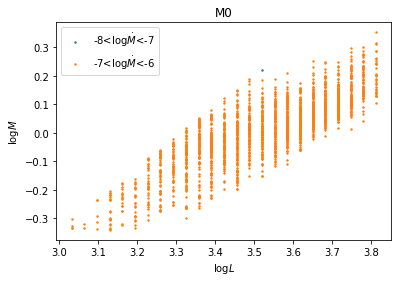

Bin list  0  is empty. Continuing to next bin.
Bin list  1  is empty. Continuing to next bin.
Bin list  2  is empty. Continuing to next bin.
Min observed value in bin: -7.967457791305338
Max observed value in bin: -5.743267825874079
Min observed value in bin: -7.863561657436615
Max observed value in bin: -4.955875918755522
Min observed value in bin: -6.7648075037301885
Max observed value in bin: -5.088501484030114
Bin list  6  is empty. Continuing to next bin.


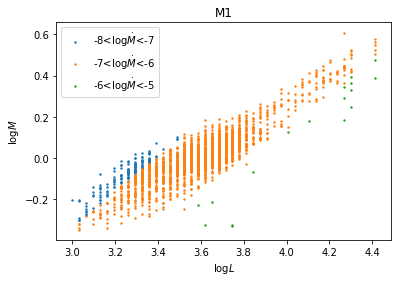

Bin list  0  is empty. Continuing to next bin.
Bin list  1  is empty. Continuing to next bin.
Min observed value in bin: -7.00939478857608
Max observed value in bin: -7.00939478857608
Min observed value in bin: -7.942447998945467
Max observed value in bin: -6.0360469833475205
Min observed value in bin: -7.703225153259688
Max observed value in bin: -4.933674074637962
Min observed value in bin: -5.611454779904043
Max observed value in bin: -5.4565528199183
Bin list  6  is empty. Continuing to next bin.


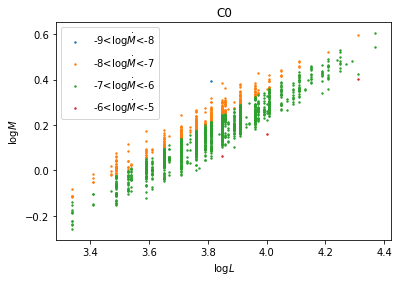

Bin list  0  is empty. Continuing to next bin.
Bin list  1  is empty. Continuing to next bin.
Bin list  2  is empty. Continuing to next bin.
Min observed value in bin: -8.009394788576081
Max observed value in bin: -6.0042551489236695
Min observed value in bin: -7.729554091982037
Max observed value in bin: -4.6549204736851335
Min observed value in bin: -6.678401569534656
Max observed value in bin: -6.678401569534656
Bin list  6  is empty. Continuing to next bin.


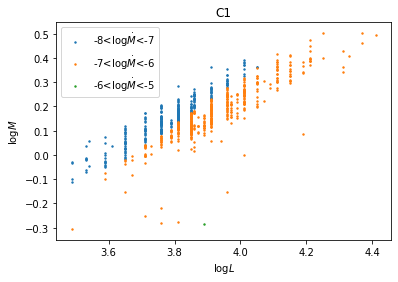

In [450]:
plot_binned_stellar_data(M0StarData,M0_bin_ids,'M0')
plot_binned_stellar_data(M1StarData,M1_bin_ids,'M1')
plot_binned_stellar_data(C0StarData,C0_bin_ids,'C0')
plot_binned_stellar_data(C1StarData,C1_bin_ids,'C1')

In [451]:
M0BCResid = np.asarray([[1.8458,-2.6279,-0.7936],[1,-1,-0.8603],[4.3900,-3.351,0.6328],[0.9499,-1.4621,-0.6475],[1.6485,-0.7907,-0.8821],[2.5094,-2.066,-0.7845],[1.7096,-1.5781,-0.8548]])
M1BCResid = np.asarray([[2.1658, -2.5042, -0.6571],[1, -1, -0.6837],[4.3900, -3.351, -0.1855],[1.3008, -1.7645, -0.4868],[1.6485, -0.7907, -0.6616],[2.5405, -2.0957, -0.5397],[0.7585, -0.5802, -0.8584]])
C0BCResid = np.asarray([[2.2134, -2.6219, -0.7292],[1, -1, -0.7599],[4.4370, -3.4710, -0.3854],[0.8268, -1.7674, -0.5466],[1.7965, -1.1687, -0.7415],[2.6618, -2.3039, -0.6396],[3.8115, -3.9779, -0.4846],[13.6825, -14.5687, 0.8139]])
C1BCResid = np.asarray([[2.2099, -2.3380, -0.6179],[1, -1, -0.6969],[4.437, -3.471, -0.2256],[1.2799, 2.1018, -0.4058],[1.7965, -1.1687, -0.6851],[2.7044, -2.3597, -0.5297],[1.7959, -1.8315, -0.6949]])

In [452]:
def randrange(n, vmin, vmax):
    """
    Helper function to make an array of random numbers having shape (n, )
    with each number distributed Uniform(vmin, vmax).
    """
    return (vmax - vmin)*np.random.rand(n) + vmin
for az_angle in range(0,360):
    fig = plt.figure()
    ax = fig.add_subplot(projection='3d')
    to_plot_list = [M0BCResid,M1BCResid,C0BCResid,C1BCResid]
    marker_list = ['o', 'v', '^', 's']
    label_list = ['M0','M1','C0','C1']
    for i in range (0,4):
        xs = np.transpose(to_plot_list[i])[0]
        ys = np.transpose(to_plot_list[i])[1]
        zs = np.transpose(to_plot_list[i])[2]
        ax.scatter(xs, ys, zs, marker=marker_list[i])
    plot.tight_layout()
    ax.view_init(10, az_angle)

    ax.set_xlabel('B')
    ax.set_ylabel('C')
    ax.set_zlabel('Residual Slope')

    #plt.show()
    plt.savefig('BCResid_gif_elem/'+'BCResid_gif_elem_'+str(az_angle)+'.jpg')
    plt.close()


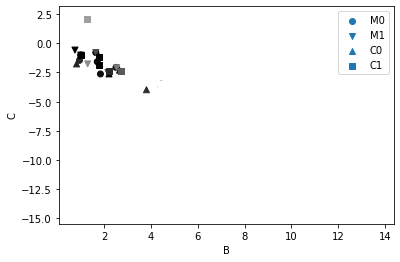

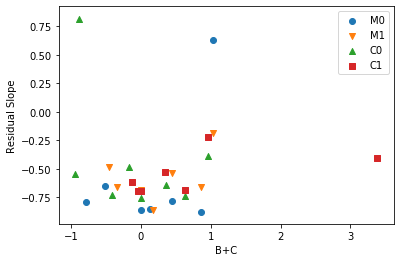

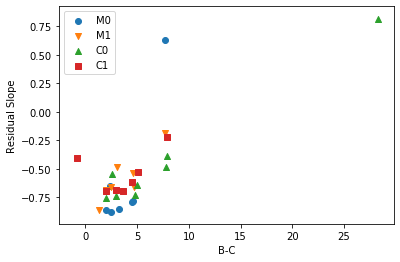

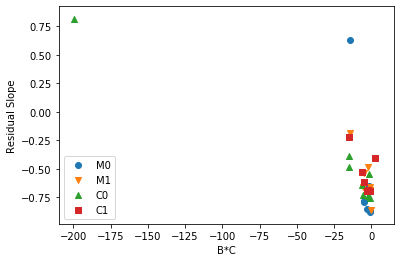

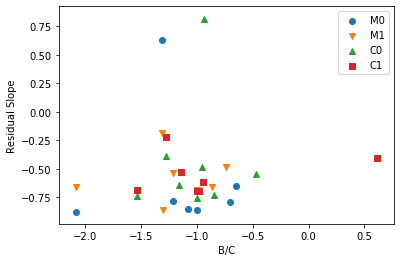

In [453]:

for i in range (0,4):
    xs = np.transpose(to_plot_list[i])[0]
    ys = np.transpose(to_plot_list[i])[1]
    zs = np.transpose(to_plot_list[i])[2]
    plt.scatter(xs, ys, c=zs, marker=marker_list[i],label=label_list[i],cmap='gray')
plt.legend()
plt.xlabel('B')
plt.ylabel('C')
plt.show()
plt.close()


for i in range (0,4):
    xs = np.transpose(to_plot_list[i])[0]
    ys = np.transpose(to_plot_list[i])[1]
    xs = xs+ys
    zs = np.transpose(to_plot_list[i])[2]
    plt.scatter(xs, zs, marker=marker_list[i],label=label_list[i],cmap='gray')
plt.legend()
plt.xlabel('B+C')
plt.ylabel('Residual Slope')
plt.show()
plt.close()


for i in range (0,4):
    xs = np.transpose(to_plot_list[i])[0]
    ys = np.transpose(to_plot_list[i])[1]
    xs = xs-ys
    zs = np.transpose(to_plot_list[i])[2]
    plt.scatter(xs, zs, marker=marker_list[i],label=label_list[i],cmap='gray')
plt.legend()
plt.xlabel('B-C')
plt.ylabel('Residual Slope')
plt.show()
plt.close()



for i in range (0,4):
    xs = np.transpose(to_plot_list[i])[0]
    ys = np.transpose(to_plot_list[i])[1]
    xs = xs*ys
    zs = np.transpose(to_plot_list[i])[2]
    plt.scatter(xs, zs, marker=marker_list[i],label=label_list[i],cmap='gray')
plt.legend()
plt.xlabel('B*C')
plt.ylabel('Residual Slope')
plt.show()
plt.close()

for i in range (0,4):
    xs = np.transpose(to_plot_list[i])[0]
    ys = np.transpose(to_plot_list[i])[1]
    xs = xs/ys
    zs = np.transpose(to_plot_list[i])[2]
    plt.scatter(xs, zs, marker=marker_list[i],label=label_list[i],cmap='gray')
plt.legend()
plt.xlabel('B/C')
plt.ylabel('Residual Slope')
plt.show()
plt.close()

In [454]:
# Attenuation Test - What do we get when we fit log L(log Mdot, log P) as opposed to log Mdot(log L, log P)? 
def attenuation_test (star_data,spec_mode_label='',text_x=0.03):
    color_list = ['tab:blue','tab:orange','tab:green','tab:red','tab:purple','tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
    logMData = np.log10(star_data[MIndex])
    logLData = np.log10(star_data[LIndex])
    logPData = np.log10(star_data[PIndex])
    logMdotData = np.log10(star_data[MdotIndex])
    logMdotperMData = np.log10(star_data[MdotIndex]/star_data[MIndex])
    fit_primary = multilinear_fit_2var([logLData,logPData],logMdotData)
    # Returns logMdot = A + BlogL + ClogP
    fit_secondary = multilinear_fit_2var([logMdotData,logPData],logLData)
    # Returns logL = A + BlogMdot + ClogP
    
    LPCoeffs = fit_primary[0]
    MdotPCoeffs = fit_secondary[0]
    our_log_mdot = LPCoeffs[0] + LPCoeffs[1]*logLData + LPCoeffs[2]*logPData
    attenuation_log_mdot = (logLData - MdotPCoeffs[0] - MdotPCoeffs[2]*logPData)/MdotPCoeffs[1]
    # log Mdot = A + BlogL + ClogP
    if spec_mode_label[0] == 'M':
        RLM = RLM_M
    if spec_mode_label[0] == 'C':
        RLM = RLM_C
    if spec_mode_label == 'M0':
        PMR = PMR_M0
        dz_values = deathzone_values_M0
    if spec_mode_label == 'M1':
        PMR = PMR_M1
        dz_values = deathzone_values_M1
    if spec_mode_label == 'C0':
        PMR = PMR_C0
        dz_values = deathzone_values_C0
    if spec_mode_label == 'C0x':
        PMR = PMR_C0
        dz_values = deathzone_values_C0x
    if spec_mode_label == 'C0 and C0x':
        PMR = PMR_C0
        dz_values = deathzone_values_C0_and_C0x
    if spec_mode_label == 'C1':
        PMR = PMR_C1
        dz_values = deathzone_values_C1
    if spec_mode_label == 'C0 and C0x':
        PMR = PMR_C0
        dz_values = deathzone_values_C0_and_C0x
    
    #artificial_data = make_artificial_set([star_data],0.2,grid_spacing = 75j)
    #artificial_logLData = artificial_data[0]
    #artificial_logMData = artificial_data[1]
    #artificial_logRData = RLM[0] + RLM[1]*artificial_logLData + RLM[2]*artificial_logMData
    #artificial_logPData = PMR[0] + PMR[1]*artificial_logMData + PMR[2]*artificial_logRData
    #artificial_logTData = np.log10(5778*np.sqrt(10**(artificial_logRData)/np.sqrt(10**artificial_logLData)))
        
    a = LPCoeffs[0]
    arlm = RLM[0]
    aRLM = arlm
    apmr = PMR[0]
    aPMR = apmr
    c = LPCoeffs[2]
    cpmr = PMR[2]
    cPMR = cpmr
    b = LPCoeffs[1]
    brlm = RLM[1]
    bRLM = brlm
    bpmr = PMR[1]
    bPMR = bpmr
    crlm = RLM[2]
    cRLM = crlm
    PMLCoeffs = calculate_PML_coeffs(RLM, PMR)
    aPML = PMLCoeffs[0]
    bPML = PMLCoeffs[1]
    cPML = PMLCoeffs[2]
    
    
    # Coefficients for the Mdot(L,P) fit as a function Mdot(L, P)
    aMdotLP = a
    bMdotLP   = b
    cMdotLP  = c
    
    Anew = a - arlm + apmr*c + arlm*c*cpmr
    Bnew = b - brlm + brlm*c*cpmr 
    Cnew = bpmr*c - crlm + c*cpmr*crlm
    print('log Mdot(logL, logP):')
    #print('LRM form: logMdot =',Anew,' + ',Bnew,'logL + logR -',-Cnew,'logM')
    print('LM form: logMdot =',Anew+arlm,' + ',Bnew+brlm,'logL -',-(Cnew+crlm),'logM')
    #####
    
    # Type 1: Calc Mdot vs Obsv Mdot
    fig, ax = plt.subplots()
    plot.scatter(logMdotData,our_log_mdot,s=2,color=color_list[0])
    title=spec_mode_label+r' ($\log \dot{M}(\log L, \log P)$)'
    ax.text(text_x, .97,title,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot.xlabel(r'$\log \dot{M}_{obsv.}$')
    plot.ylabel(r'$\log \dot{M}_{calc.}$')
    plot.plot([-9,-3],[-9,-3],color = 'black', alpha = 1,linestyle='--',linewidth=1.5)
    plot.xlim([-8,-4])
    plot.ylim([-8,-4])
    plot.tight_layout()
    plot.savefig('Final_Fit/Attenuation_Demonstration/'+spec_mode_label+'_logMdot(logL,logP)_calc_vs_obsv'+'.pdf',format='pdf')
    plot.savefig('Final_Fit/Attenuation_Demonstration/'+spec_mode_label+'_logMdot(logL,logP)_calc_vs_obsv'+'.png',format='png')
    plot.show()
    plot.close()
    # Type 2: Residual vs Obsv Mdot
    fig, ax = plt.subplots()
    plot.scatter(logMdotData,our_log_mdot-logMdotData,s=2,color=color_list[0])
    title=spec_mode_label+r' ($\log \dot{M}(\log L, \log P)$)'
    ax.text(text_x, .97,title,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot.xlabel(r'$\log \dot{M}_{obsv.}$')
    plot.ylabel(r'$\log \dot{M}_{calc.}-\log \dot{M}_{obsv.}$')
    plot.plot([-8,-4],[0,0],color = 'black', alpha = 1,linestyle='--',linewidth=1.5)
    plot.xlim([-8,-4])
    plot.tight_layout()
    plot.savefig('Final_Fit/Attenuation_Demonstration/'+spec_mode_label+'_logL(logMdot,logP)_resid_vs_obsv'+'.pdf',format='pdf')
    plot.savefig('Final_Fit/Attenuation_Demonstration/'+spec_mode_label+'_logL(logMdot,logP)_resid_vs_obsv'+'.png',format='png')
    plot.show()
    plot.close()
    
    
    # Returns logL = A + BlogMdot + ClogP
    a_LMdotP = MdotPCoeffs[0]
    b_LMdotP = MdotPCoeffs[1]
    c_LMdotP = MdotPCoeffs[2]
    a = -a_LMdotP/b_LMdotP
    b = 1/b_LMdotP
    c = -c_LMdotP/b_LMdotP
    arlm = RLM[0]
    aRLM = arlm
    apmr = PMR[0]
    aPMR = apmr
    cpmr = PMR[2]
    cPMR = cpmr
    brlm = RLM[1]
    bRLM = brlm
    bpmr = PMR[1]
    bPMR = bpmr
    crlm = RLM[2]
    cRLM = crlm
    PMLCoeffs = calculate_PML_coeffs(RLM, PMR)
    aPML = PMLCoeffs[0]
    bPML = PMLCoeffs[1]
    cPML = PMLCoeffs[2]
    
    # Coefficients for the L(Mdot,P) fit as a function Mdot(L, P)
    aLMdotP = a
    bLMdotP  = b
    cLMdotP  = c
    
    
    Anew = a - arlm + apmr*c + arlm*c*cpmr
    Bnew = b - brlm + brlm*c*cpmr 
    Cnew = bpmr*c - crlm + c*cpmr*crlm
    print('log L(logMdot, logP):')
    print('LM form: logMdot =',Anew+arlm,' + ',Bnew+brlm,'logL -',-(Cnew+crlm),'logM' )
    
    # Type 1: Calc Mdot vs Obsv Mdot
    fig, ax = plt.subplots()
    plot.scatter(logMdotData,attenuation_log_mdot,s=2,color=color_list[1])
    title=spec_mode_label+r' ($\log L(\log \dot{M}, \log P)$)'
    ax.text(text_x, .97,title,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot.xlabel(r'$\log \dot{M}_{obsv.}$')
    plot.ylabel(r'$\log \dot{M}_{calc.}$')
    plot.plot([-9,-3],[-9,-3],color = 'black', alpha = 1,linestyle='--',linewidth=1.5)
    plot.xlim([-8,-4])
    plot.ylim([-8,-4])
    plot.tight_layout()
    plot.savefig('Final_Fit/Attenuation_Demonstration/'+spec_mode_label+'_logL(logMdot,logP)_calc_vs_obsv'+'.pdf',format='pdf')
    plot.savefig('Final_Fit/Attenuation_Demonstration/'+spec_mode_label+'_logL(logMdot,logP)_calc_vs_obsv'+'.png',format='png')
    plot.show()
    plot.close()
    
    # Type 2: Residual vs Obsv Mdot
    plot.scatter(logMdotData,attenuation_log_mdot-logMdotData,s=2,color=color_list[1])
    title=spec_mode_label+r' ($\log L(\log \dot{M}, \log P)$)'
    ax.text(text_x, .97,title,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot.xlabel(r'$\log \dot{M}_{obsv.}$')
    plot.ylabel(r'$\log \dot{M}_{calc.}-\log \dot{M}_{obsv.}$')
    plot.plot([-8,-4],[0,0],color = 'black', alpha = 1,linestyle='--',linewidth=1.5)
    plot.xlim([-8,-4])
    plot.tight_layout()
    plot.savefig('Final_Fit/Attenuation_Demonstration/'+spec_mode_label+'_logL(logMdot,logP)_resid_vs_obsv'+'.pdf',format='pdf')
    plot.savefig('Final_Fit/Attenuation_Demonstration/'+spec_mode_label+'_logL(logMdot,logP)_resid_vs_obsv'+'.png',format='png')
    plot.show()
    plot.close()
    
    
    dz_log_mdot = dz_values[0] + dz_values[1]*np.log10(star_data[LIndex]) + dz_values[2]*np.log10(star_data[MIndex])
    
    print('log Mdot(logL, logM):')
    print('LM form: logMdot =',dz_values[0],' + ',dz_values[1],'logL -',-(dz_values[2]),'logM' )
    # Type 1: Calc Mdot vs Obsv Mdot
    plot.scatter(logMdotData,dz_log_mdot,s=2,color=color_list[2])
    title=spec_mode_label+r' ($\log \dot{M}(\log L, \log M)$)'
    ax.text(text_x, .97,title,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot.xlabel(r'$\log \dot{M}_{obsv.}$')
    plot.ylabel(r'$\log \dot{M}_{calc.}$')
    plot.plot([-9,-3],[-9,-3],color = 'black', alpha = 1,linestyle='--',linewidth=1.5)
    plot.xlim([-8,-4])
    plot.ylim([-8,-4])
    plot.savefig('Final_Fit/Attenuation_Demonstration/'+spec_mode_label+'_logMdot(logL,logM)_calc_vs_obsv'+'.pdf',format='pdf')
    plot.savefig('Final_Fit/Attenuation_Demonstration/'+spec_mode_label+'_logMdot(logL,logM)_calc_vs_obsv'+'.png',format='png')
    plot.tight_layout()
    plot.show()
    plot.close()
    
    # Type 2: Residual vs Obsv Mdot
    plot.scatter(logMdotData,dz_log_mdot-logMdotData,s=2,color=color_list[2])
    title=spec_mode_label+r' ($\log \dot{M}(\log L, \log M)$)'
    ax.text(text_x, .97,title,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot.xlabel(r'$\log \dot{M}_{obsv.}$')
    plot.ylabel(r'$\log \dot{M}_{calc.}-\log \dot{M}_{obsv.}$')
    plot.plot([-8,-4],[0,0],color = 'black', alpha = 1,linestyle='--',linewidth=1.5)
    plot.xlim([-8,-4])
    plot.tight_layout()
    plot.savefig('Final_Fit/Attenuation_Demonstration/'+spec_mode_label+'_logMdot(logL,logM)_resid_vs_obsv'+'.pdf',format='pdf')
    plot.savefig('Final_Fit/Attenuation_Demonstration/'+spec_mode_label+'_logMdot(logL,logM)_resid_vs_obsv'+'.png',format='png')
    plot.show()
    plot.close()
    
    
    
    # Now an overlaid version
    # Type 1: Calc Mdot vs Obsv Mdot
    fig, ax = plt.subplots()
    alpha_set=0.33
    plot.scatter(logMdotData,our_log_mdot,s=2,label=r'$\log \dot{M}(\log L, \log P)$',alpha=alpha_set,color=color_list[0])
    fit = linear_fit_1var(logMdotData,our_log_mdot)
    fit_params = fit[0]
    fit_x = np.asarray([-9,-3])
    fit_y = fit_params[0]+fit_params[1]*fit_x
    plot.plot(fit_x,fit_y,color = color_list[0])
    
    plot.scatter(logMdotData,attenuation_log_mdot,s=2,label=r'$\log L(\log \dot{M}, \log P)$',alpha=alpha_set,color=color_list[1])
    fit = linear_fit_1var(logMdotData,attenuation_log_mdot)
    fit_params = fit[0]
    fit_x = np.asarray([-9,-3])
    fit_y = fit_params[0]+fit_params[1]*fit_x
    plot.plot(fit_x,fit_y,color = color_list[1])
    
    plot.scatter(logMdotData,dz_log_mdot,s=2,label=r'$\log \dot{M}(\log L, \log M)$',alpha=alpha_set,color=color_list[2])
    fit = linear_fit_1var(logMdotData,dz_log_mdot)
    fit_params = fit[0]
    fit_x = np.asarray([-9,-3])
    fit_y = fit_params[0]+fit_params[1]*fit_x
    plot.plot(fit_x,fit_y,color = color_list[2])
    
    #plot.title(spec_mode_label)
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot.xlabel(r'$\log \dot{M}_{obsv.}$')
    plot.ylabel(r'$\log \dot{M}_{calc.}$')
    plot.plot([-9,-3],[-9,-3],color = 'black', alpha = 1,linestyle='--',linewidth=1.5)
    plot.xlim([-8,-4])
    plot.ylim([-8,-4])
    plot.tight_layout()
    plot.legend(loc=4)
    plot.savefig('Final_Fit/Attenuation_Demonstration/'+spec_mode_label+'_all_calc_vs_obsv'+'.pdf',format='pdf')
    plot.savefig('Final_Fit/Attenuation_Demonstration/'+spec_mode_label+'_all_calc_vs_obsv'+'.png',format='png')
    plot.show()
    plot.close()
    
    # Type 2: Residual vs Obsv Mdot
    fig, ax = plt.subplots()
    plot.scatter(logMdotData,our_log_mdot-logMdotData,s=2,label=r'$\log \dot{M}(\log L, \log P)$',alpha=alpha_set,color=color_list[0])
    fit = linear_fit_1var(logMdotData,our_log_mdot-logMdotData)
    fit_params = fit[0]
    fit_x = np.asarray([-9,-3])
    fit_y = fit_params[0]+fit_params[1]*fit_x
    plot.plot(fit_x,fit_y,color = color_list[0])
    print('Mdot(L,P) Slope=',fit_params[1])
    print('Mdot(L,P) R^2=',fit[1])
    
    
    plot.scatter(logMdotData,attenuation_log_mdot-logMdotData,s=2, label=r'$\log L(\log \dot{M}, \log P)$',alpha=alpha_set,color=color_list[1])
    fit = linear_fit_1var(logMdotData,attenuation_log_mdot-logMdotData)
    fit_params = fit[0]
    fit_x = np.asarray([-9,-3])
    fit_y = fit_params[0]+fit_params[1]*fit_x
    plot.plot(fit_x,fit_y,color = color_list[1])
    print('L(Mdot,P) Slope=',fit_params[1])
    print('L(Mdot,P) R^2=',fit[1])
    
    plot.scatter(logMdotData,dz_log_mdot-logMdotData,s=2,label=r'$\log \dot{M}(\log L, \log M)$',alpha=alpha_set,color=color_list[2])
    fit = linear_fit_1var(logMdotData,dz_log_mdot-logMdotData)
    fit_params = fit[0]
    fit_x = np.asarray([-9,-3])
    fit_y = fit_params[0]+fit_params[1]*fit_x
    plot.plot(fit_x,fit_y,color = color_list[2])
    print('Mdot(L,M) Slope=',fit_params[1])
    print('Mdot(L,M) R^2=',fit[1])
    
    #plot.title(spec_mode_label)
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot.xlabel(r'$\log \dot{M}_{obsv.}$')
    plot.ylabel(r'$\log \dot{M}_{calc.}-\log \dot{M}_{obsv.}$')
    plot.plot([-8,-4],[0,0],color = 'black', alpha = 1,linestyle='--',linewidth=1.5)
    plot.xlim([-8,-4])
    plot.tight_layout
    plot.legend(loc=4)
    plot.savefig('Final_Fit/Attenuation_Demonstration/'+spec_mode_label+'_all_resid_vs_obsv'+'.pdf',format='pdf')
    plot.savefig('Final_Fit/Attenuation_Demonstration/'+spec_mode_label+'_all_resid_vs_obsv'+'.png',format='png')
    plot.show()
    plot.close()
    
    # Test plots: Residual vs log M and vs log P
    
    resid_MdotLP = our_log_mdot-logMdotData
    resid_LMdotP = attenuation_log_mdot-logMdotData
    resid_MdotLM = dz_log_mdot-logMdotData
    
    plot.scatter(logPData,resid_MdotLP,s=2)
    plot.show()
    plot.close()
    plot.scatter(logPData,resid_LMdotP,s=2)
    plot.show()
    plot.close()
    plot.scatter(logMData,resid_MdotLM,s=2)
    plot.show()
    plot.close()
    
    plot.scatter(logLData,resid_MdotLP,s=2)
    plot.show()
    plot.close()
    plot.scatter(logLData,resid_LMdotP,s=2)
    plot.show()
    plot.close()
    plot.scatter(logLData,resid_MdotLM,s=2)
    plot.show()
    plot.close()
    
    return [aMdotLP, bMdotLP, cMdotLP], [aLMdotP, bLMdotP, cLMdotP]

M0:
log Mdot(logL, logP):
LM form: logMdot = -12.938730017492958  +  1.845822471134391 logL - 2.627930313100934 logM


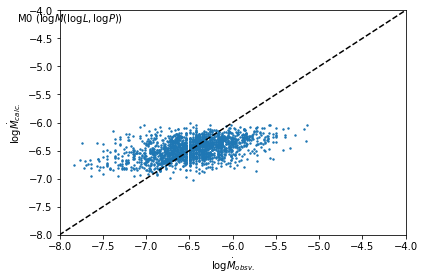

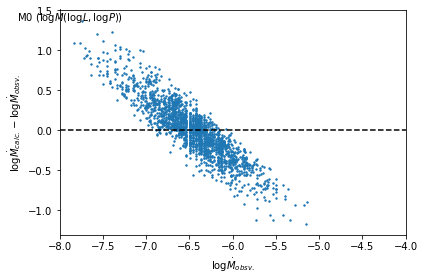

log L(logMdot, logP):
LM form: logMdot = -26.434182089563695  +  5.721974364433084 logL - 16.587679509001223 logM


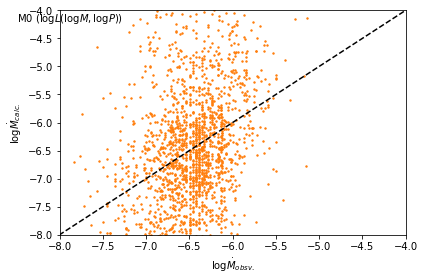

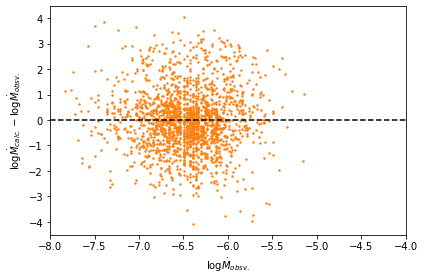

log Mdot(logL, logM):
LM form: logMdot = -22.010528157677143  +  4.426524721325467 logL - 5.311766715095943 logM


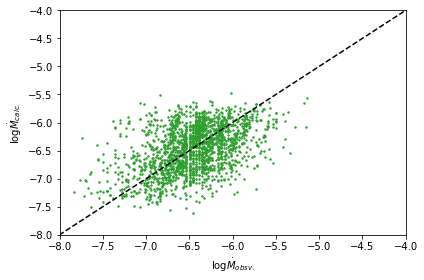

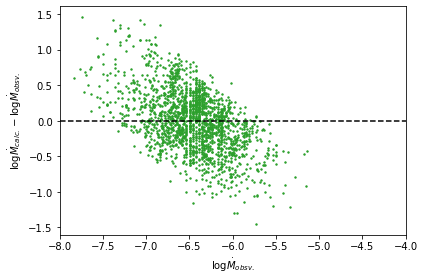

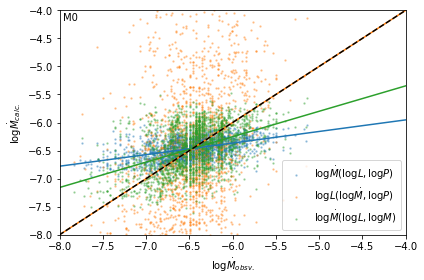

Mdot(L,P) Slope= -0.7936345478649754
Mdot(L,P) R^2= 0.7936345478649771
L(Mdot,P) Slope= 7.02476271596808e-15
L(Mdot,P) R^2= -2.220446049250313e-16
Mdot(L,M) Slope= -0.5472303609558021
Mdot(L,M) R^2= 0.25628460625204885


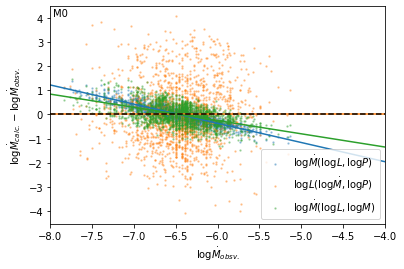

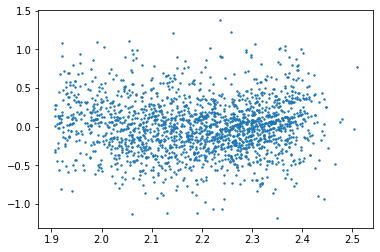

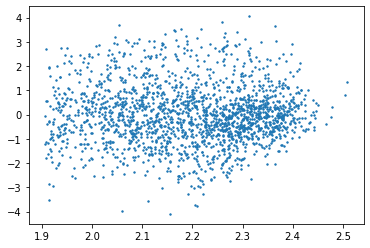

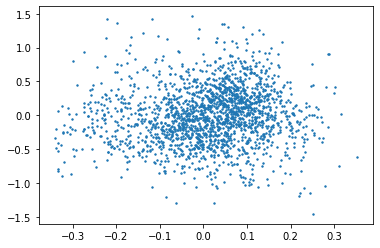

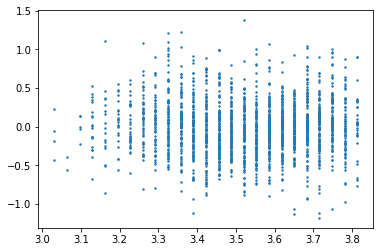

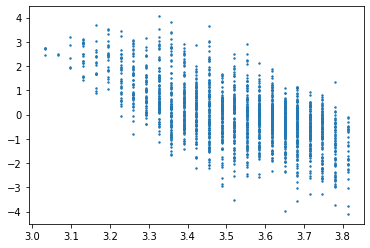

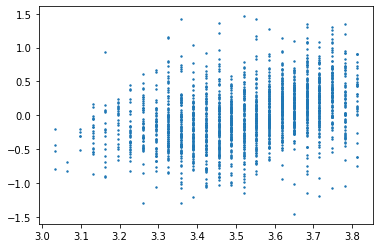

M1:
log Mdot(logL, logP):
LM form: logMdot = -14.331671442964444  +  2.1658349824618766 logL - 2.504190194588611 logM


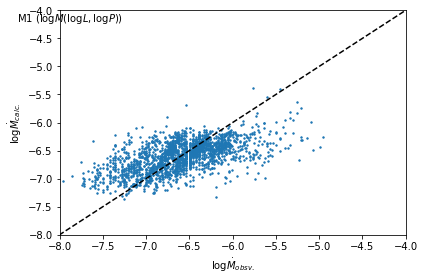

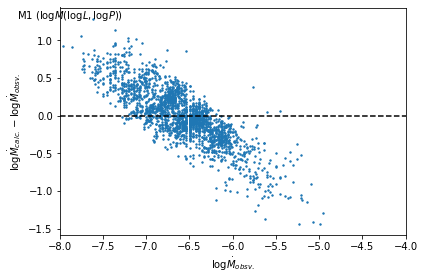

log L(logMdot, logP):
LM form: logMdot = -54.82132888171585  +  13.517235076993826 logL - 32.06134003667905 logM


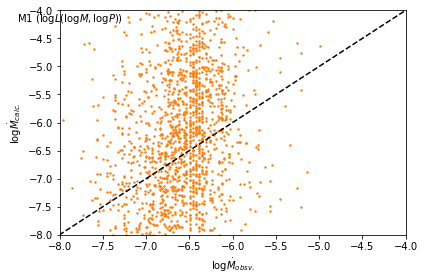

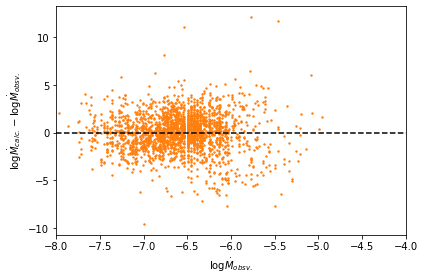

log Mdot(logL, logM):
LM form: logMdot = -24.06376137107629  +  4.887456400464315 logL - 5.273790150496492 logM


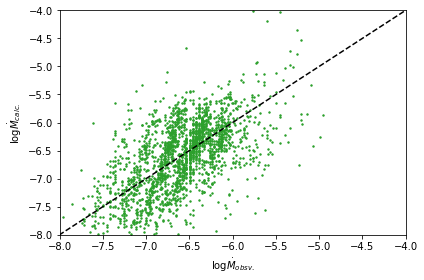

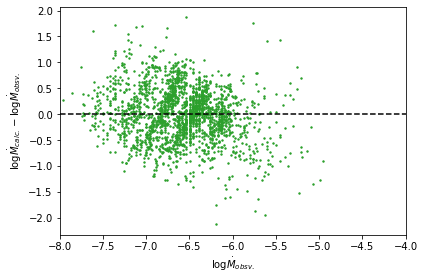

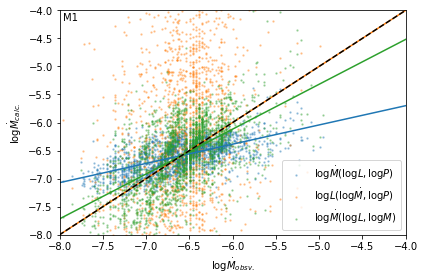

Mdot(L,P) Slope= -0.6570790219180418
Mdot(L,P) R^2= 0.6570790219180425
L(Mdot,P) Slope= -2.079239558305801e-14
L(Mdot,P) R^2= -2.220446049250313e-16
Mdot(L,M) Slope= -0.2003166576633917
Mdot(L,M) R^2= 0.0314687362355921


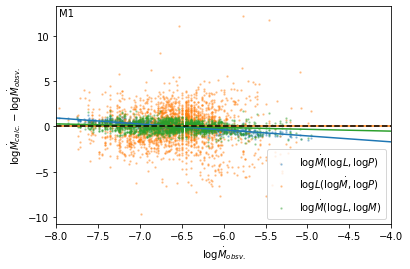

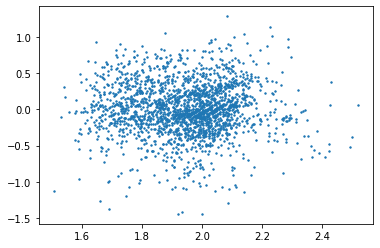

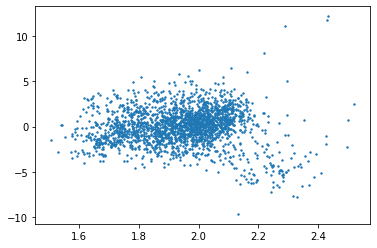

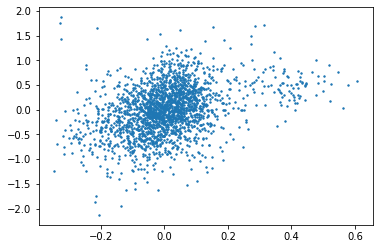

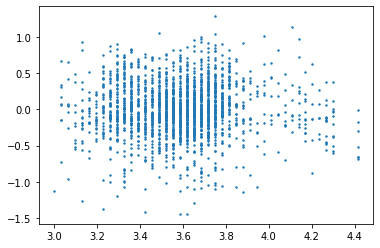

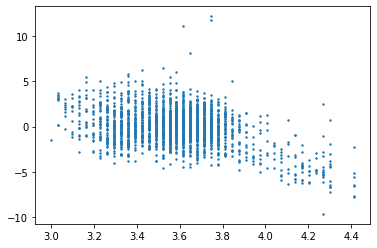

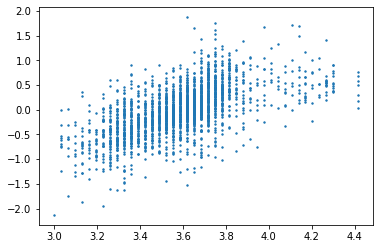

C0:
log Mdot(logL, logP):
LM form: logMdot = -21.899136660341252  +  4.225637806117329 logL - 5.663741216898915 logM


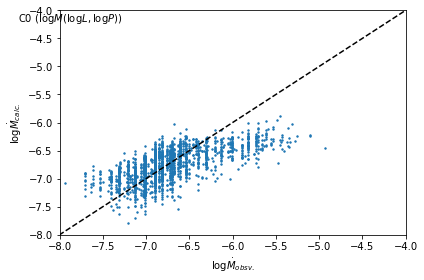

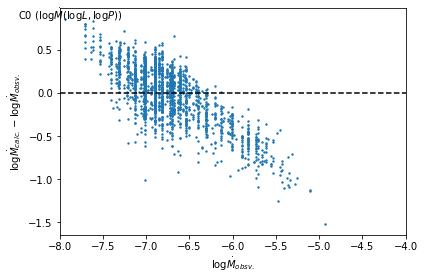

log L(logMdot, logP):
LM form: logMdot = -33.57042057795684  +  7.7359052335317 logL - 15.844802884488407 logM


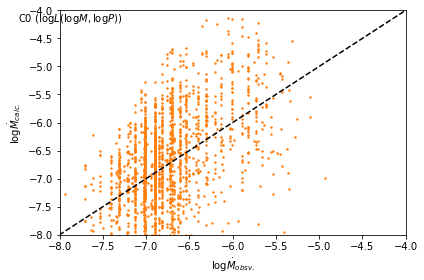

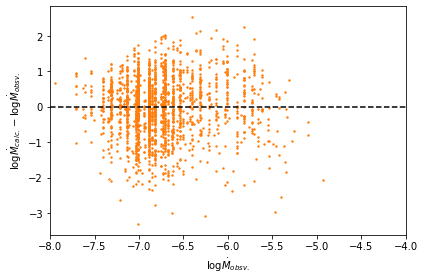

log Mdot(logL, logM):
LM form: logMdot = -25.925639564797347  +  5.276447379609071 logL - 5.948111447513197 logM


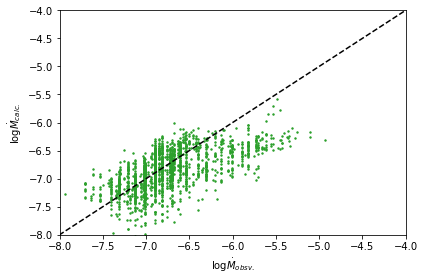

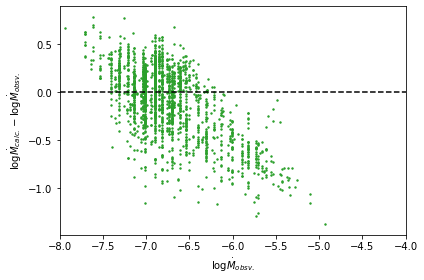

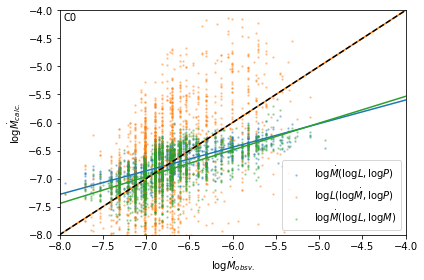

Mdot(L,P) Slope= -0.5793979207365173
Mdot(L,P) R^2= 0.5793979207365181
L(Mdot,P) Slope= 6.612765890423589e-15
L(Mdot,P) R^2= 2.220446049250313e-16
Mdot(L,M) Slope= -0.5223808944145352
Mdot(L,M) R^2= 0.3996582750094958


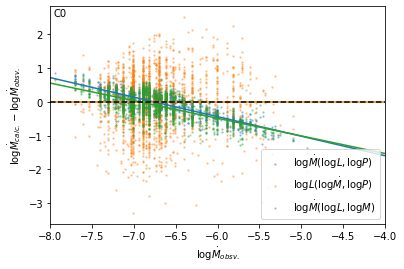

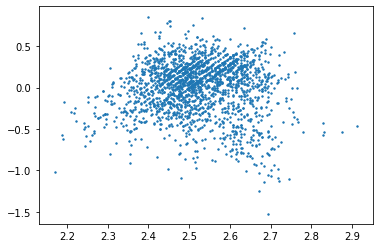

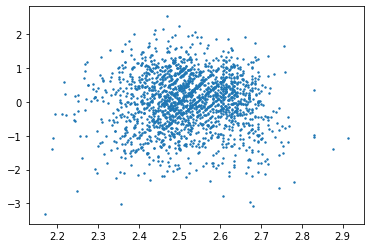

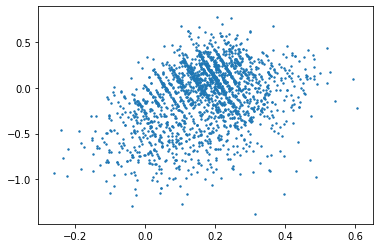

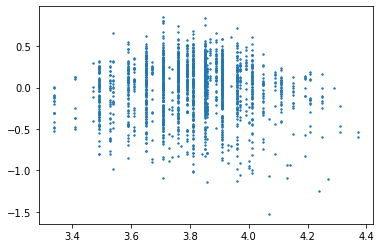

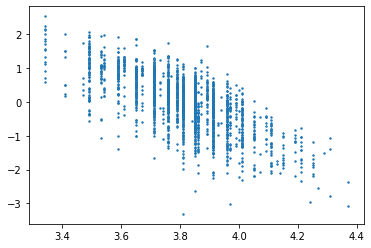

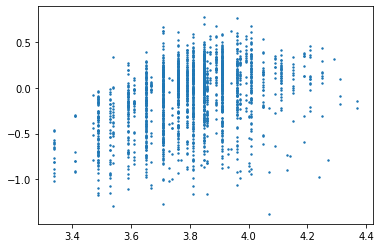

C0x:
log Mdot(logL, logP):
LM form: logMdot = -21.899136660341252  +  4.225637806117329 logL - 5.663741216898915 logM


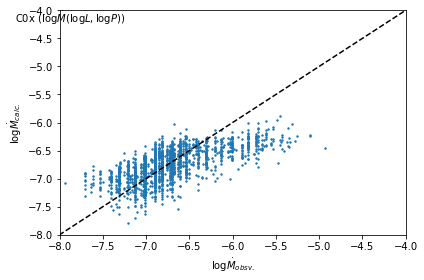

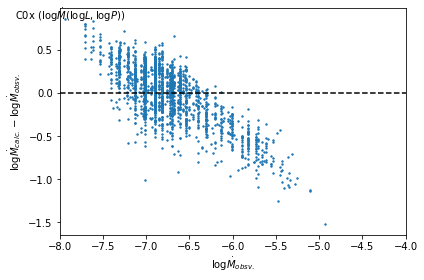

log L(logMdot, logP):
LM form: logMdot = -33.57042057795684  +  7.7359052335317 logL - 15.844802884488407 logM


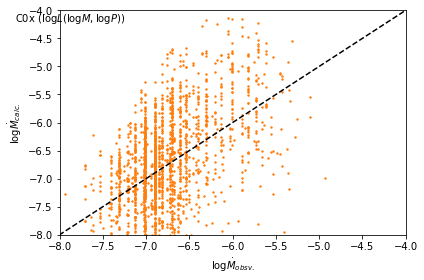

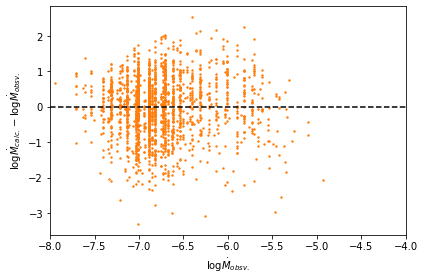

log Mdot(logL, logM):
LM form: logMdot = -40.49983892150037  +  9.40165901426434 logL - 10.918270658522166 logM


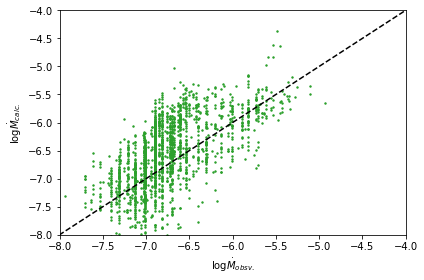

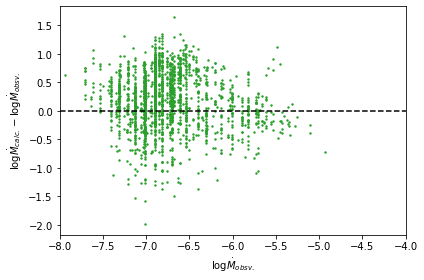

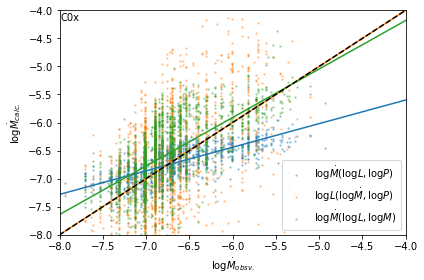

Mdot(L,P) Slope= -0.5793979207365173
Mdot(L,P) R^2= 0.5793979207365181
L(Mdot,P) Slope= 6.612765890423589e-15
L(Mdot,P) R^2= 2.220446049250313e-16
Mdot(L,M) Slope= -0.13555721740687934
Mdot(L,M) R^2= 0.014562406238673109


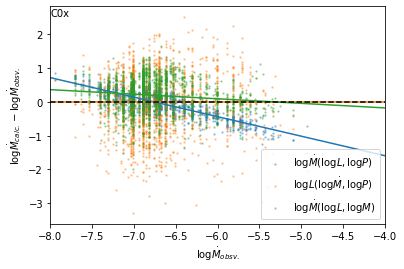

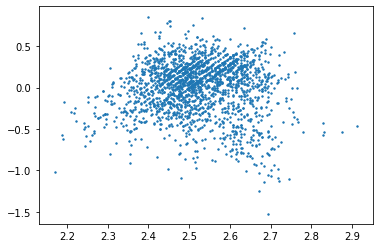

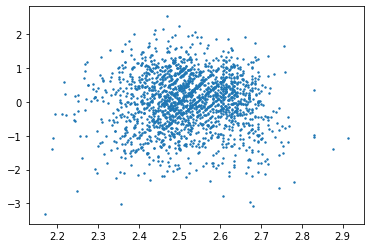

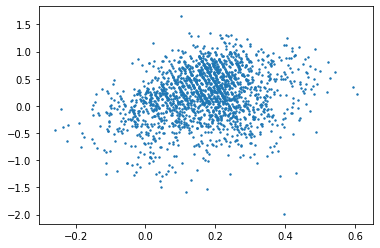

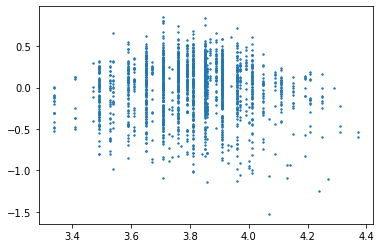

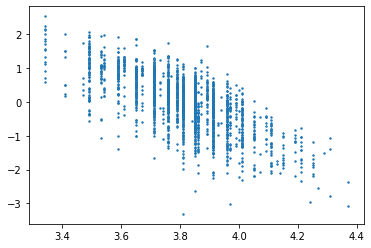

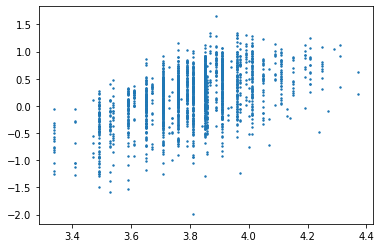

C1:
log Mdot(logL, logP):
LM form: logMdot = -15.10246424487756  +  2.20992367511773 logL - 2.3380226554375763 logM


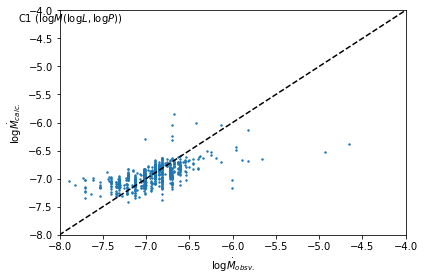

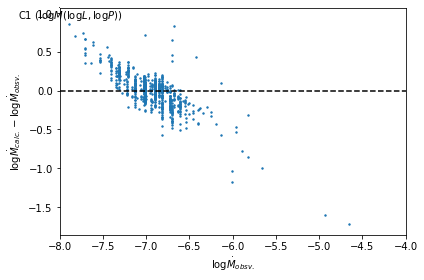

log L(logMdot, logP):
LM form: logMdot = -27.354879778189876  +  6.4691326966646425 logL - 27.737910863060566 logM


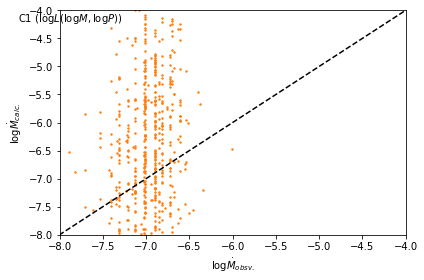

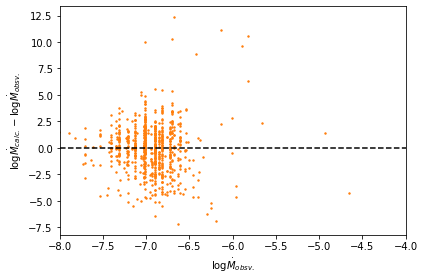

log Mdot(logL, logM):
LM form: logMdot = -22.590992140526403  +  4.203017828957615 logL - 3.6746716838314706 logM


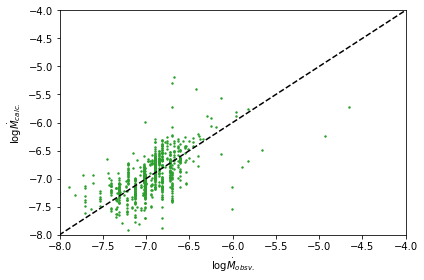

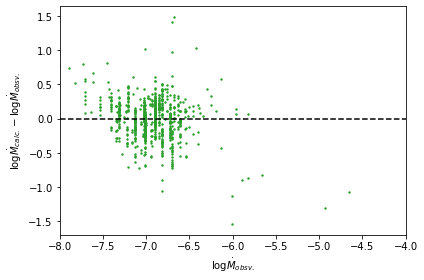

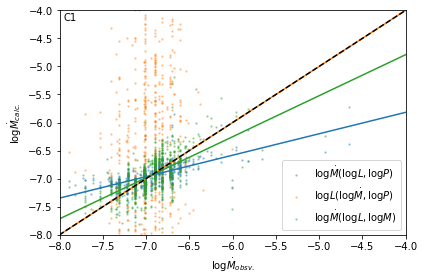

Mdot(L,P) Slope= -0.6178778936298202
Mdot(L,P) R^2= 0.6178778936298202
L(Mdot,P) Slope= 2.2923503373295517e-14
L(Mdot,P) R^2= -4.440892098500626e-16
Mdot(L,M) Slope= -0.2686228191762904
Mdot(L,M) R^2= 0.07079192862309613


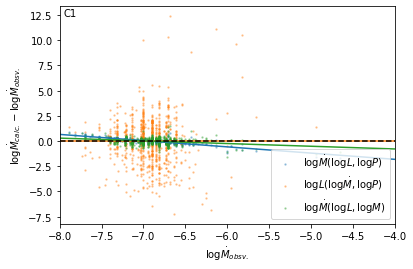

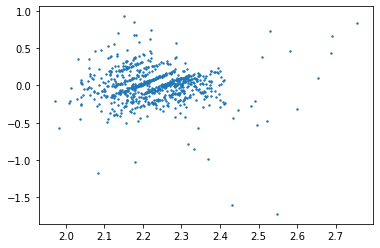

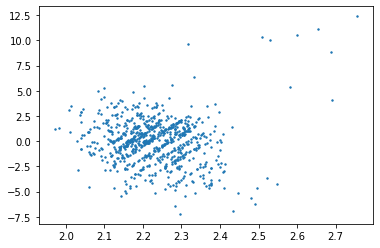

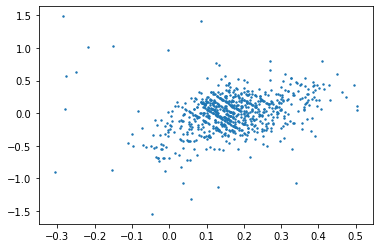

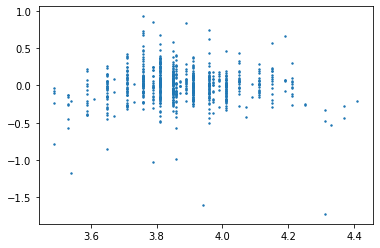

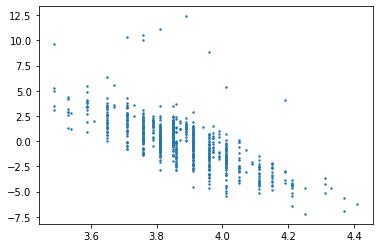

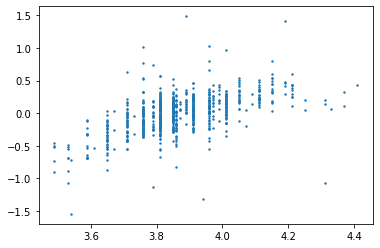

In [455]:
print('M0:')
MdotLP_Coeffs_M0, LMdotP_Coeffs_M0 = attenuation_test (M0StarData,spec_mode_label='M0')
print('M1:')
MdotLP_Coeffs_M1, LMdotP_Coeffs_M1 = attenuation_test (M1StarData,spec_mode_label='M1')
print('C0:')
MdotLP_Coeffs_C0, LMdotP_Coeffs_C0 = attenuation_test (C0StarData,spec_mode_label='C0')
print('C0x:')
MdotLP_Coeffs_C0x, LMdotP_Coeffs_C0x = attenuation_test (C0StarData,spec_mode_label='C0x')
print('C1:')
MdotLP_Coeffs_C1, LMdotP_Coeffs_C1 = attenuation_test (C1StarData,spec_mode_label='C1')

C0 & C0x:
log Mdot(logL, logP):
LM form: logMdot = -21.899136660341252  +  4.225637806117329 logL - 5.663741216898915 logM


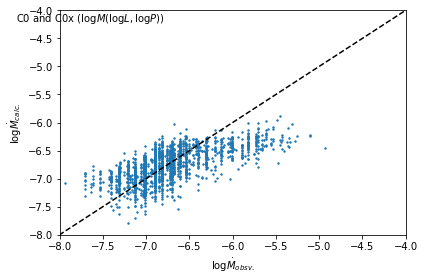

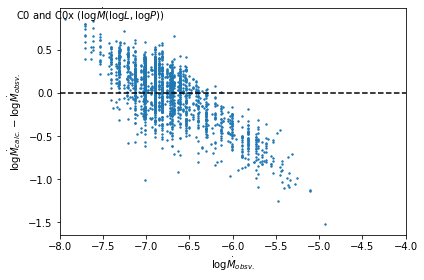

log L(logMdot, logP):
LM form: logMdot = -33.57042057795684  +  7.7359052335317 logL - 15.844802884488407 logM


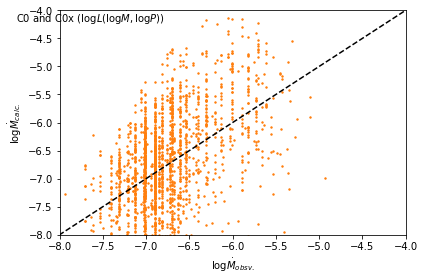

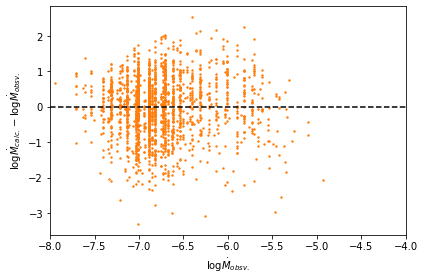

log Mdot(logL, logM):
LM form: logMdot = -34.76628082574503  +  7.786478388592237 logL - 9.619854377543422 logM


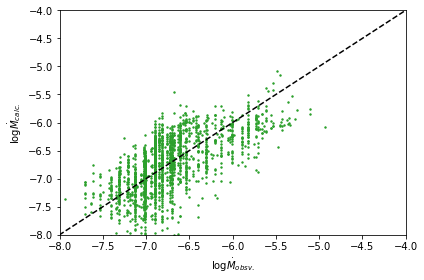

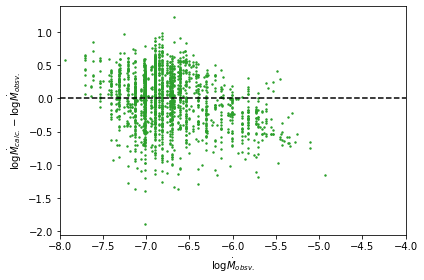

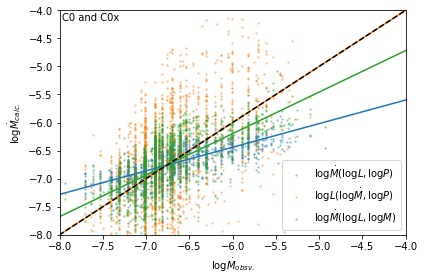

Mdot(L,P) Slope= -0.5793979207365173
Mdot(L,P) R^2= 0.5793979207365181
L(Mdot,P) Slope= 6.612765890423589e-15
L(Mdot,P) R^2= 2.220446049250313e-16
Mdot(L,M) Slope= -0.25985422735837105
Mdot(L,M) R^2= 0.0774187935972026


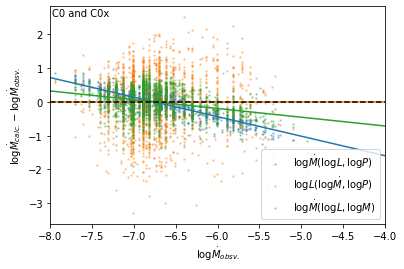

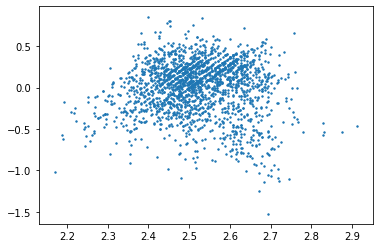

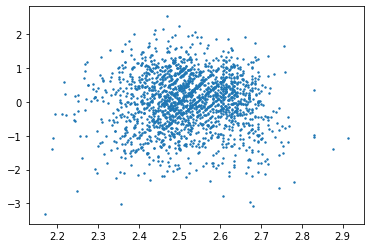

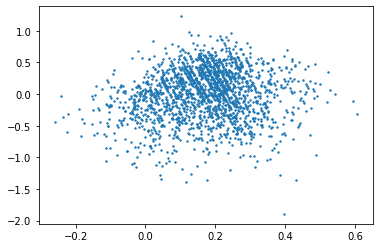

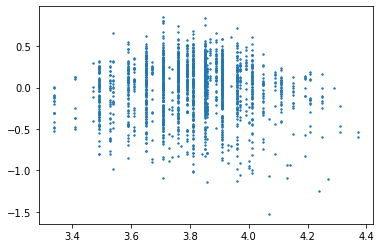

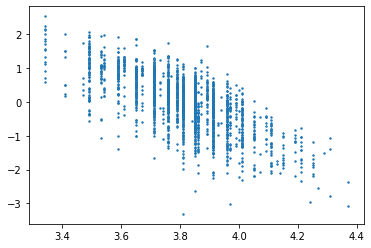

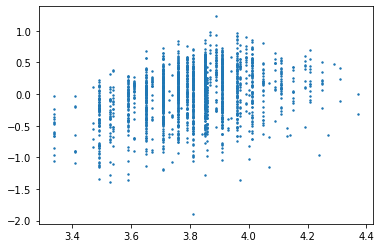

In [456]:
print('C0 & C0x:')
MdotLP_Coeffs_C0andC0x, LMdotP_Coeffs_C0andC0x = attenuation_test (C0StarData,spec_mode_label='C0 and C0x',text_x=0.09)

In [457]:
np.shape(M0StarData)[1]+np.shape(M1StarData)[1]+np.shape(C0StarData)[1]+np.shape(C1StarData)[1]

6889

In [458]:
def calculate_formula_correction (coeffs_1, coeffs_2, data_set,coeffs_labels = ['',''],grid_spacing=50,Mdotlimits=[-8, -4],Mdotdustlimits=[-12,-8],Llimits=[2.8, 4.6],Plimits=[1.2, 3.4],deltaMdotlimits=[-1, 1.75]):
    coeffs_1_LPMdot = coeffs_1[0]
    coeffs_1_PML = coeffs_1[1]
    coeffs_2_LPMdot = coeffs_2[0]
    coeffs_2_PML = coeffs_2[1]
    
    
    # create data sets of constant mass
    checked_log_m_array = []
    working_log_m = 0
    proceed = False
    constant_mass_lists = []
    i = 0
    while i < len(data_set[1]):
        indices_of_current_mass = []
        if i == 0:
            checked_log_m_array.append(data_set[1][0])
            working_log_m = data_set[1][0]
            for k in range(0, len(data_set[1])):
                if working_log_m == data_set[1][k]:
                    indices_of_current_mass.append(k)
            constant_mass_lists.append(indices_of_current_mass)
        else:
            working_log_m = data_set[1][i]
            for k in range(0, len(checked_log_m_array)):
                if working_log_m == checked_log_m_array[k]:
                    proceed = False
                    break
                else:
                    proceed = True
            if proceed == True:
                for l in range(0, len(data_set[1])):
                    checked_log_m_array.append(data_set[1][i])
                    if working_log_m == data_set[1][l]:
                        indices_of_current_mass.append(l)
                constant_mass_lists.append(indices_of_current_mass)
        #print('i:',i)
        i += 1
    #print('constant_mass_lists:',constant_mass_lists)
    i = 0
    constant_mass_arrays = []
    for i in range(0, len(constant_mass_lists)):
        constant_mass_arrays.append(np.transpose(np.transpose(data_set)[constant_mass_lists[i]]))
    #print(constant_mass_arrays)
    
    
    # Calculate pulsation periods
    #print(coeffs_1_PML)
    logP_1 = coeffs_1_PML[0] + coeffs_1_PML[1]*data_set[1] + coeffs_1_PML[2]*data_set[0] 
    #print(logP_1)
    #print(coeffs_2_PML)
    logP_2 = coeffs_2_PML[0] + coeffs_2_PML[1]*data_set[1] + coeffs_2_PML[2]*data_set[0]
    #print(logP_2)
    
    # some testing plots
    plot.scatter(data_set[0],logP_1,s=2,label=coeffs_labels[0])
    plot.scatter(data_set[0],logP_2,s=2,label=coeffs_labels[1])
    plot.legend()
    plot.xlabel(r'$\log L$')
    plot.xlim(Llimits)
    plot.ylabel(r'$\log P$')
    plot.ylim(Plimits)
    plot.show()
    plot.close()
    
    # Now, figure out the difference between the mass-loss rates
    logMdot_1 = coeffs_1_LPMdot[0] + coeffs_1_LPMdot[1]*data_set[0] + coeffs_1_LPMdot[2]*logP_1
    logMdot_2 = coeffs_2_LPMdot[0] + coeffs_2_LPMdot[1]*data_set[0] + coeffs_2_LPMdot[2]*logP_2
    
    #print(logMdot_1)
    #print(logMdot_2)
    
    plot.scatter(data_set[0],logMdot_1,s=2,label=coeffs_labels[0])
    plot.scatter(data_set[0],logMdot_2,s=2,label=coeffs_labels[1])
    plot.legend()
    plot.xlabel(r'$\log L$')
    plot.xlim(Llimits)
    plot.ylabel(r'$log \dot{M}_{\mathrm{tot.}}$'+ ' (' + coeffs_labels[0] + '), (' + coeffs_labels[1] + ')' )
    plot.ylim(Mdotlimits)
    plot.show()
    plot.close()
    
    plot.scatter(logP_1,logMdot_1,s=2,label=coeffs_labels[0])
    plot.scatter(logP_2,logMdot_2,s=2,label=coeffs_labels[1])
    plot.legend()
    plot.xlabel(r'$\log P$')
    plot.xlim(Plimits)
    plot.ylabel(r'$\log \dot{M}_{\mathrm{tot.}}$'+ ' (' + coeffs_labels[0] + '), (' + coeffs_labels[1] + ')' )
    plot.ylim(Mdotlimits)
    plot.show()
    plot.close()
    
    differences = logMdot_1 - logMdot_2
    
    diff_vs_logL_fit = linear_fit_1var(data_set[0],differences)
    diff_vs_logL_Coeffs = diff_vs_logL_fit[0]
    print('Difference vs logL fit:','logMdot_1-logMdot_2=',diff_vs_logL_Coeffs[0],'+',diff_vs_logL_Coeffs[1],'logL')
    diff_vs_logL_err = diff_vs_logL_fit[2]
    print('Difference vs logL fit errors:',diff_vs_logL_err[0],', ',diff_vs_logL_err[1])
    
    diff_vs_logL_yval = diff_vs_logL_Coeffs[0] + diff_vs_logL_Coeffs[1]*np.asarray(Llimits)
    
    ####
    i = 0
    while i < len(constant_mass_arrays):
        subset = constant_mass_arrays[i]
        #print(coeffs_1_PML)
        logP_subset_1 = coeffs_1_PML[0] + coeffs_1_PML[1]*subset[1] + coeffs_1_PML[2]*subset[0] 
        #print(logP_1)
        #print(coeffs_2_PML)
        logP_subset_2 = coeffs_2_PML[0] + coeffs_2_PML[1]*subset[1] + coeffs_2_PML[2]*subset[0]
        
        logMdot_subset_1 = coeffs_1_LPMdot[0] + coeffs_1_LPMdot[1]*subset[0] + coeffs_1_LPMdot[2]*logP_subset_1
        logMdot_subset_2 = coeffs_2_LPMdot[0] + coeffs_2_LPMdot[1]*subset[0] + coeffs_2_LPMdot[2]*logP_subset_2
        
        differences_subset = logMdot_subset_1 - logMdot_subset_2
        if subset[1][0] < 0:
            label_mass = str(10**(subset[1][0]))[0:6] # Take the current mass and make string
        else:
            label_mass = str(10**(subset[1][0]))[0:5] # Take the current mass and make string
        plot.plot(subset[0],differences_subset,linewidth=1,linestyle = '--',label=label_mass)
        #if coeffs_labels[1] == 'C1':
        #    i = i + 3
        #else:
        #    i = i + 5
        i = i + 5
    ####
    #plot.scatter(data_set[0],differences,s=2)
    #plot.plot(np.asarray(Llimits),diff_vs_logL_yval,color='orange')
    plot.xlabel('log L')
    plot.xlim(Llimits)
    #plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{tot.}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylabel(r'$\log \dot{M}_{\mathrm{tot.}}$'+' (' + coeffs_labels[0] + ') ' + r'$-\log \dot{M}_{\mathrm{tot.}}$' + ' ('+ coeffs_labels[1] + ')')
    #plot.ylim(deltaMdotlimits)
    plot.legend(title=r'$M$',ncol=2)
    plot.tight_layout(pad=1.2)
    plot.savefig('Final_Fit/'+'deltalogMdot_vs_L_'+coeffs_labels[0]+'_'+coeffs_labels[1]+'.png')
    plot.savefig('Final_Fit/'+'deltalogMdot_vs_L_'+coeffs_labels[0]+'_'+coeffs_labels[1]+'.pdf')
    plot.show()
    plot.close()
    
    plot.scatter(logP_1,differences,s=2)
    plot.xlabel('log P'+ ' (' + coeffs_labels[0] + ')')
    plot.xlim(Plimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{tot.}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.show()
    plot.close()
    
    plot.scatter(logP_2,differences,s=2)
    plot.xlabel('log P'+ ' (' + coeffs_labels[1] + ')')
    plot.xlim(Plimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{tot.}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.show()
    plot.close()
    
    plot.scatter(logMdot_1,differences,s=2)
    plot.xlabel(r'$log Mdot_{\mathrm{tot.}}$' + ' (' + coeffs_labels[0] + ')' )
    plot.xlim(Mdotlimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{tot.}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.show()
    plot.close()
    
    plot.scatter(logMdot_1,differences,s=2)
    plot.xlabel(r'$log Mdot_{\mathrm{tot.}}$' + ' (' + coeffs_labels[1] + ')' )
    plot.xlim(Mdotlimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{tot.}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.show()
    plot.close()
    
    # And again without the dust scaling
    
    # Now, figure out the difference between the mass-loss rates
    logMdot_1 = coeffs_1_LPMdot[0] + coeffs_1_LPMdot[1]*data_set[0] + coeffs_1_LPMdot[2]*logP_1
    logMdot_2 = coeffs_2_LPMdot[0] + coeffs_2_LPMdot[1]*data_set[0] + coeffs_2_LPMdot[2]*logP_2
    if coeffs_labels[0][0] == 'M':
        logMdot_1 = logMdot_1-np.log10(ratios_M[1])
    elif coeffs_labels[0][0] == 'C':
        logMdot_1 = logMdot_1-np.log10(ratios_C[1])
    else:
        print('Error. Invalid spectral type encountered.')
    if coeffs_labels[1][0] == 'M':
        logMdot_2 = logMdot_2-np.log10(ratios_M[1])
    elif coeffs_labels[1][0] == 'C':
        logMdot_2 = logMdot_2-np.log10(ratios_C[1])
    else:
        print('Error. Invalid spectral type encountered.')
    
    
    plot.scatter(data_set[0],logMdot_1,s=2,label=coeffs_labels[0])
    plot.scatter(data_set[0],logMdot_2,s=2,label=coeffs_labels[1])
    plot.legend()
    plot.xlabel(r'$\log L$')
    plot.xlim(Llimits)
    plot.ylabel(r'$log \dot{M}_{\mathrm{dust}}$'+ ' (' + coeffs_labels[0] + '), (' + coeffs_labels[1] + ')' )
    plot.ylim(Mdotdustlimits)
    plot.tight_layout()
    plot.show()
    plot.close()
    
    plot.scatter(logP_1,logMdot_1,s=2,label=coeffs_labels[0])
    plot.scatter(logP_2,logMdot_2,s=2,label=coeffs_labels[1])
    plot.legend()
    plot.xlabel(r'$\log P$')
    plot.xlim(Plimits)
    plot.ylabel(r'$\log \dot{M}_{\mathrm{dust}}$'+ ' (' + coeffs_labels[0] + '), (' + coeffs_labels[1] + ')' )
    plot.ylim(Mdotdustlimits)
    plot.tight_layout()
    plot.show()
    plot.close()
    
    differences = logMdot_1 - logMdot_2
    
    diff_vs_logL_fit = linear_fit_1var(data_set[0],differences)
    diff_vs_logL_Coeffs = diff_vs_logL_fit[0]
    print('Difference vs logL fit:','logMdot_1-logMdot_2=',diff_vs_logL_Coeffs[0],'+',diff_vs_logL_Coeffs[1],'logL')
    diff_vs_logL_err = diff_vs_logL_fit[2]
    print('Difference vs logL fit errors:',diff_vs_logL_err[0],', ',diff_vs_logL_err[1])
    
    diff_vs_logL_yval = diff_vs_logL_Coeffs[0] + diff_vs_logL_Coeffs[1]*np.asarray(Llimits)
    
    ####
    i = 0
    while i < len(constant_mass_arrays):
        subset = constant_mass_arrays[i]
        #print(coeffs_1_PML)
        logP_subset_1 = coeffs_1_PML[0] + coeffs_1_PML[1]*subset[1] + coeffs_1_PML[2]*subset[0] 
        #print(logP_1)
        #print(coeffs_2_PML)
        logP_subset_2 = coeffs_2_PML[0] + coeffs_2_PML[1]*subset[1] + coeffs_2_PML[2]*subset[0]
        
        logMdot_subset_1 = coeffs_1_LPMdot[0] + coeffs_1_LPMdot[1]*subset[0] + coeffs_1_LPMdot[2]*logP_subset_1
        logMdot_subset_2 = coeffs_2_LPMdot[0] + coeffs_2_LPMdot[1]*subset[0] + coeffs_2_LPMdot[2]*logP_subset_2
        if coeffs_labels[0][0] == 'M':
            logMdot_subset_1 = logMdot_subset_1-np.log10(ratios_M[1])
        elif coeffs_labels[0][0] == 'C':
            logMdot_subset_1 = logMdot_subset_1-np.log10(ratios_C[1])
        else:
            print('Error. Invalid spectral type encountered.')
        if coeffs_labels[1][0] == 'M':
            logMdot_subset_2 = logMdot_subset_2-np.log10(ratios_M[1])
        elif coeffs_labels[1][0] == 'C':
            logMdot_subset_2 = logMdot_subset_2-np.log10(ratios_C[1])
        else:
            print('Error. Invalid spectral type encountered.')
        
        
        differences_subset = logMdot_subset_1 - logMdot_subset_2
        if subset[1][0] < 0:
            label_mass = str(10**(subset[1][0]))[0:6] # Take the current mass and make string
        else:
            label_mass = str(10**(subset[1][0]))[0:5] # Take the current mass and make string
        plot.plot(subset[0],differences_subset,linewidth=1,linestyle = '--',label=label_mass)
        #if coeffs_labels[1] == 'C1':
        #    i = i + 3
        #else:
        #    i = i + 5
        i = i + 5
    ####
    #plot.scatter(data_set[0],differences,s=2)
    #plot.plot(np.asarray(Llimits),diff_vs_logL_yval,color='orange')
    plot.xlabel('log L')
    plot.xlim(Llimits)
    #plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{dust}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylabel(r'$\log \dot{M}_{\mathrm{dust}}$'+' (' + coeffs_labels[0] + ') ' + r'$-\log \dot{M}_{\mathrm{dust}}$' + ' ('+ coeffs_labels[1] + ')')
    #plot.ylim(deltaMdotlimits)
    plot.legend(title=r'$M$',ncol=2)
    plot.tight_layout(pad=1.2)
    plot.savefig('Final_Fit/'+'deltalogMdotdust_vs_L_'+coeffs_labels[0]+'_'+coeffs_labels[1]+'.png')
    plot.savefig('Final_Fit/'+'deltalogMdotdust_vs_L_'+coeffs_labels[0]+'_'+coeffs_labels[1]+'.pdf')
    plot.show()
    plot.close()
    
    plot.scatter(logP_1,differences,s=2)
    plot.xlabel('log P'+ ' (' + coeffs_labels[0] + ')')
    plot.xlim(Plimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{dust}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.tight_layout()
    plot.show()
    plot.close()
    
    plot.scatter(logP_2,differences,s=2)
    plot.xlabel('log P'+ ' (' + coeffs_labels[1] + ')')
    plot.xlim(Plimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{tot.}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.tight_layout()
    plot.show()
    plot.close()
    
    plot.scatter(logMdot_1,differences,s=2)
    plot.xlabel(r'$log Mdot_{\mathrm{tot.}}$' + ' (' + coeffs_labels[0] + ')' )
    plot.xlim(Mdotlimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{dust}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.tight_layout()
    plot.show()
    plot.close()
    
    plot.scatter(logMdot_1,differences,s=2)
    plot.xlabel(r'$log Mdot_{\mathrm{tot.}}$' + ' (' + coeffs_labels[1] + ')' )
    plot.xlim(Mdotlimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{dust}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.tight_layout()
    plot.show()
    plot.close()
    
    
    
    '''
    # Figure out average difference at a given luminosity
    working_array = np.transpose(np.vstack((data_set[0],differences)))
    i = 0
    luminosity_pos_array = []
    luminosity_pos_array_all = []
    # Loop finds all of the indices where luminosities match, and saves them in arrays
    while i < len(working_array):
        current_L = working_array[i][0]
        if i == len(working_array)-1:
            next_L = 0 # reset
        else:
            next_L = working_array[i+1][0]
        if i == len(working_array):
            # Handles the final value
            luminosity_pos_array.append(i)
            luminosity_pos_array_all.append(luminosity_pos_array)
            luminosity_pos_array = [] # reset after saving
        elif current_L == next_L:
            luminosity_pos_array.append(i)
        else:
            luminosity_pos_array.append(i) # Last position of current luminosity needs to be appended
            luminosity_pos_array_all.append(luminosity_pos_array)
            luminosity_pos_array = [] # reset after saving
        i += 1
    #print(luminosity_pos_array_all)
    # Now, we need to average the Mdots at each luminosity
    i = 0
    average_differences = []
    for i in range(0,len(luminosity_pos_array_all)):
        differences_sum = 0
        for k in range(0,len(luminosity_pos_array_all[i])):
            differences_sum = differences_sum + differences[luminosity_pos_array_all[i][k]]
        differences_mean = differences_sum/len(luminosity_pos_array_all[i])
        average_differences.append(differences_mean)
    unique_luminosities = []
    for i in range(0, len(luminosity_pos_array_all)):
        unique_luminosities.append(data_set[0][luminosity_pos_array_all[i][0]])
    #print(len(average_differences))
    #print(len(unique_luminosities))
    # And now plot
    fit_line = chi_sq_fit_2d(unique_luminosities,average_differences)[0]
    left_point = np.nanmin(unique_luminosities)
    right_point = np.nanmax(unique_luminosities)
    fit_x = np.asarray([left_point,right_point])
    fit_y = fit_line[0]+fit_line[1]*fit_x
    plot.scatter(unique_luminosities, average_differences,s=2)
    if fit_line[1]<0:
        fit_label = str(fit_line[0]) + str(fit_line[1])+'logL'
    else:
        fit_label = str(fit_line[0]) + '+' + str(fit_line[1])+'logL'
    plot.plot(fit_x, fit_y,color = 'black',label=fit_label)
    plot.xlabel('log L')
    plot.ylabel('<log Mdot - log Mdot>' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.legend()
    plot.show()
    plot.close()
    '''
    
    '''# Figure out average difference at a given period
    working_array = np.transpose(np.vstack((data_set[1],differences)))
    i = 0
    print(data_set[1])
    i = 0
    average_periods = []
    for i in range(0,len(luminosity_pos_array_all)):
        sum_P = 0
        for k in range(0,len(luminosity_pos_array_all[i])):
            sum_P = sum_P + data_set[1][luminosity_pos_array_all[i][k]]
        average_P = sum_P/len(luminosity_pos_array_all[i])
        average_periods.append(average_P)
    #print(len(average_differences))
    #print(len(average_periods))
    # Now plot
    fit_line = chi_sq_fit_2d(average_periods,average_differences)[0]
    left_point = np.nanmin(average_periods)
    right_point = np.nanmax(average_periods)
    fit_x = np.asarray([left_point,right_point])
    fit_y = fit_line[0]+fit_line[1]*fit_x
    plot.scatter(average_periods, average_differences,s=2)
    fit_label = str(fit_line[0]) + str(fit_line[1])+'<logP>'
    plot.plot(fit_x, fit_y,color = 'black',label=fit_label)
    plot.xlabel('log P')
    plot.ylabel('<log Mdot - log Mdot>' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.legend()
    plot.show()
    plot.close()
     '''



In [459]:
def calculate_formula_correction_MdotP (coeffs_1, coeffs_2, data_set,coeffs_labels = ['',''],grid_spacing=50,Mdotlimits=[-8, -4],Mdotdustlimits=[-12,-8],Llimits=[2.8, 4.6],Plimits=[1.2, 3.4],deltaMdotlimits=[-7, 7]):
    coeffs_1_LPMdot = coeffs_1[0]
    coeffs_1_PML = coeffs_1[1]
    coeffs_2_LPMdot = coeffs_2[0]
    coeffs_2_PML = coeffs_2[1]
    
    
    # create data sets of constant mass
    checked_log_m_array = []
    working_log_m = 0
    proceed = False
    constant_mass_lists = []
    i = 0
    while i < len(data_set[1]):
        indices_of_current_mass = []
        if i == 0:
            checked_log_m_array.append(data_set[1][0])
            working_log_m = data_set[1][0]
            for k in range(0, len(data_set[1])):
                if working_log_m == data_set[1][k]:
                    indices_of_current_mass.append(k)
            constant_mass_lists.append(indices_of_current_mass)
        else:
            working_log_m = data_set[1][i]
            for k in range(0, len(checked_log_m_array)):
                if working_log_m == checked_log_m_array[k]:
                    proceed = False
                    break
                else:
                    proceed = True
            if proceed == True:
                for l in range(0, len(data_set[1])):
                    checked_log_m_array.append(data_set[1][i])
                    if working_log_m == data_set[1][l]:
                        indices_of_current_mass.append(l)
                constant_mass_lists.append(indices_of_current_mass)
        #print('i:',i)
        i += 1
    #print('constant_mass_lists:',constant_mass_lists)
    i = 0
    constant_mass_arrays = []
    for i in range(0, len(constant_mass_lists)):
        constant_mass_arrays.append(np.transpose(np.transpose(data_set)[constant_mass_lists[i]]))
    #print(constant_mass_arrays)
    
    
    # Calculate pulsation periods
    #print(coeffs_1_PML)
    logP_1 = coeffs_1_PML[0] + coeffs_1_PML[1]*data_set[1] + coeffs_1_PML[2]*data_set[0] 
    #print(logP_1)
    #print(coeffs_2_PML)
    logP_2 = coeffs_2_PML[0] + coeffs_2_PML[1]*data_set[1] + coeffs_2_PML[2]*data_set[0]
    #print(logP_2)
    
    # some testing plots
    plot.scatter(data_set[0],logP_1,s=2,label=coeffs_labels[0])
    plot.scatter(data_set[0],logP_2,s=2,label=coeffs_labels[1])
    plot.legend()
    plot.xlabel(r'$\log L$')
    plot.xlim(Llimits)
    plot.ylabel(r'$\log P$')
    plot.ylim(Plimits)
    plot.show()
    plot.close()
    
    # Now, figure out the difference between the mass-loss rates
    logMdot_1 = coeffs_1_LPMdot[0] + coeffs_1_LPMdot[1]*data_set[0] + coeffs_1_LPMdot[2]*logP_1
    logMdot_2 = coeffs_2_LPMdot[0] + coeffs_2_LPMdot[1]*data_set[0] + coeffs_2_LPMdot[2]*logP_2
    
    #print(logMdot_1)
    #print(logMdot_2)
    
    plot.scatter(data_set[0],logMdot_1,s=2,label=coeffs_labels[0])
    plot.scatter(data_set[0],logMdot_2,s=2,label=coeffs_labels[1])
    plot.legend()
    plot.xlabel(r'$\log L$')
    plot.xlim(Llimits)
    plot.ylabel(r'$log \dot{M}_{\mathrm{tot.}}$'+ ' (' + coeffs_labels[0] + '), (' + coeffs_labels[1] + ')' )
    plot.ylim(Mdotlimits)
    plot.show()
    plot.close()
    
    plot.scatter(logP_1,logMdot_1,s=2,label=coeffs_labels[0])
    plot.scatter(logP_2,logMdot_2,s=2,label=coeffs_labels[1])
    plot.legend()
    plot.xlabel(r'$\log P$')
    plot.xlim(Plimits)
    plot.ylabel(r'$\log \dot{M}_{\mathrm{tot.}}$'+ ' (' + coeffs_labels[0] + '), (' + coeffs_labels[1] + ')' )
    plot.ylim(Mdotlimits)
    plot.show()
    plot.close()
    
    differences = logMdot_1 - logMdot_2
    
    diff_vs_logL_fit = linear_fit_1var(data_set[0],differences)
    diff_vs_logL_Coeffs = diff_vs_logL_fit[0]
    print('Difference vs logL fit:','logMdot_1-logMdot_2=',diff_vs_logL_Coeffs[0],'+',diff_vs_logL_Coeffs[1],'logL')
    diff_vs_logL_err = diff_vs_logL_fit[2]
    print('Difference vs logL fit errors:',diff_vs_logL_err[0],', ',diff_vs_logL_err[1])
    
    diff_vs_logL_yval = diff_vs_logL_Coeffs[0] + diff_vs_logL_Coeffs[1]*np.asarray(Llimits)
    
    ####
    i = 0
    while i < len(constant_mass_arrays):
        subset = constant_mass_arrays[i]
        #print(coeffs_1_PML)
        logP_subset_1 = coeffs_1_PML[0] + coeffs_1_PML[1]*subset[1] + coeffs_1_PML[2]*subset[0] 
        #print(logP_1)
        #print(coeffs_2_PML)
        logP_subset_2 = coeffs_2_PML[0] + coeffs_2_PML[1]*subset[1] + coeffs_2_PML[2]*subset[0]
        
        logMdot_subset_1 = coeffs_1_LPMdot[0] + coeffs_1_LPMdot[1]*subset[0] + coeffs_1_LPMdot[2]*logP_subset_1
        logMdot_subset_2 = coeffs_2_LPMdot[0] + coeffs_2_LPMdot[1]*subset[0] + coeffs_2_LPMdot[2]*logP_subset_2
        
        differences_subset = logMdot_subset_1 - logMdot_subset_2
        if subset[1][0] < 0:
            label_mass = str(10**(subset[1][0]))[0:6] # Take the current mass and make string
        else:
            label_mass = str(10**(subset[1][0]))[0:5] # Take the current mass and make string
        plot.plot(subset[0],differences_subset,linewidth=1,linestyle = '--',label=label_mass)
        #if coeffs_labels[1] == 'C1':
        #    i = i + 3
        #else:
        #    i = i + 5
        i = i + 5
    ####
    #plot.scatter(data_set[0],differences,s=2)
    #plot.plot(np.asarray(Llimits),diff_vs_logL_yval,color='orange')
    plot.xlabel(r'$\log L$')
    plot.xlim(Llimits)
    #plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{tot.}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylabel(r'$\log \dot{M}_{\mathrm{tot.}}$'+' (' + coeffs_labels[0] + ') ' + r'$-\log \dot{M}_{\mathrm{tot.}}$' + ' ('+ coeffs_labels[1] + ')')
    #plot.ylim(deltaMdotlimits)
    plot.legend(title=r'$M$',ncol=2)
    plot.tight_layout(pad=1.2)
    plot.savefig('Final_Fit/'+'LMdotP_'+'deltalogMdot_vs_L_'+coeffs_labels[0]+'_'+coeffs_labels[1]+'.png')
    plot.savefig('Final_Fit/'+'LMdotP_'+'deltalogMdot_vs_L_'+coeffs_labels[0]+'_'+coeffs_labels[1]+'.pdf')
    plot.show()
    plot.close()
    
    plot.scatter(logP_1,differences,s=2)
    plot.xlabel('log P'+ ' (' + coeffs_labels[0] + ')')
    plot.xlim(Plimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{tot.}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.show()
    plot.close()
    
    plot.scatter(logP_2,differences,s=2)
    plot.xlabel('log P'+ ' (' + coeffs_labels[1] + ')')
    plot.xlim(Plimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{tot.}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.show()
    plot.close()
    
    plot.scatter(logMdot_1,differences,s=2)
    plot.xlabel(r'$log Mdot_{\mathrm{tot.}}$' + ' (' + coeffs_labels[0] + ')' )
    plot.xlim(Mdotlimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{tot.}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.show()
    plot.close()
    
    plot.scatter(logMdot_1,differences,s=2)
    plot.xlabel(r'$log Mdot_{\mathrm{tot.}}$' + ' (' + coeffs_labels[1] + ')' )
    plot.xlim(Mdotlimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{tot.}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.show()
    plot.close()
    
    # And again without the dust scaling
    
    # Now, figure out the difference between the mass-loss rates
    logMdot_1 = coeffs_1_LPMdot[0] + coeffs_1_LPMdot[1]*data_set[0] + coeffs_1_LPMdot[2]*logP_1
    logMdot_2 = coeffs_2_LPMdot[0] + coeffs_2_LPMdot[1]*data_set[0] + coeffs_2_LPMdot[2]*logP_2
    if coeffs_labels[0][0] == 'M':
        logMdot_1 = logMdot_1-np.log10(ratios_M[1])
    elif coeffs_labels[0][0] == 'C':
        logMdot_1 = logMdot_1-np.log10(ratios_C[1])
    else:
        print('Error. Invalid spectral type encountered.')
    if coeffs_labels[1][0] == 'M':
        logMdot_2 = logMdot_2-np.log10(ratios_M[1])
    elif coeffs_labels[1][0] == 'C':
        logMdot_2 = logMdot_2-np.log10(ratios_C[1])
    else:
        print('Error. Invalid spectral type encountered.')
    
    
    plot.scatter(data_set[0],logMdot_1,s=2,label=coeffs_labels[0])
    plot.scatter(data_set[0],logMdot_2,s=2,label=coeffs_labels[1])
    plot.legend()
    plot.xlabel(r'$\log L$')
    plot.xlim(Llimits)
    plot.ylabel(r'$log \dot{M}_{\mathrm{dust}}$'+ ' (' + coeffs_labels[0] + '), (' + coeffs_labels[1] + ')' )
    plot.ylim(Mdotdustlimits)
    plot.tight_layout()
    plot.show()
    plot.close()
    
    plot.scatter(logP_1,logMdot_1,s=2,label=coeffs_labels[0])
    plot.scatter(logP_2,logMdot_2,s=2,label=coeffs_labels[1])
    plot.legend()
    plot.xlabel(r'$\log P$')
    plot.xlim(Plimits)
    plot.ylabel(r'$\log \dot{M}_{\mathrm{dust}}$'+ ' (' + coeffs_labels[0] + '), (' + coeffs_labels[1] + ')' )
    plot.ylim(Mdotdustlimits)
    plot.tight_layout()
    plot.show()
    plot.close()
    
    differences = logMdot_1 - logMdot_2
    
    diff_vs_logL_fit = linear_fit_1var(data_set[0],differences)
    diff_vs_logL_Coeffs = diff_vs_logL_fit[0]
    print('Difference vs logL fit:','logMdot_1-logMdot_2=',diff_vs_logL_Coeffs[0],'+',diff_vs_logL_Coeffs[1],'logL')
    diff_vs_logL_err = diff_vs_logL_fit[2]
    print('Difference vs logL fit errors:',diff_vs_logL_err[0],', ',diff_vs_logL_err[1])
    
    diff_vs_logL_yval = diff_vs_logL_Coeffs[0] + diff_vs_logL_Coeffs[1]*np.asarray(Llimits)
    
    ####
    i = 0
    while i < len(constant_mass_arrays):
        subset = constant_mass_arrays[i]
        #print(coeffs_1_PML)
        logP_subset_1 = coeffs_1_PML[0] + coeffs_1_PML[1]*subset[1] + coeffs_1_PML[2]*subset[0] 
        #print(logP_1)
        #print(coeffs_2_PML)
        logP_subset_2 = coeffs_2_PML[0] + coeffs_2_PML[1]*subset[1] + coeffs_2_PML[2]*subset[0]
        
        logMdot_subset_1 = coeffs_1_LPMdot[0] + coeffs_1_LPMdot[1]*subset[0] + coeffs_1_LPMdot[2]*logP_subset_1
        logMdot_subset_2 = coeffs_2_LPMdot[0] + coeffs_2_LPMdot[1]*subset[0] + coeffs_2_LPMdot[2]*logP_subset_2
        if coeffs_labels[0][0] == 'M':
            logMdot_subset_1 = logMdot_subset_1-np.log10(ratios_M[1])
        elif coeffs_labels[0][0] == 'C':
            logMdot_subset_1 = logMdot_subset_1-np.log10(ratios_C[1])
        else:
            print('Error. Invalid spectral type encountered.')
        if coeffs_labels[1][0] == 'M':
            logMdot_subset_2 = logMdot_subset_2-np.log10(ratios_M[1])
        elif coeffs_labels[1][0] == 'C':
            logMdot_subset_2 = logMdot_subset_2-np.log10(ratios_C[1])
        else:
            print('Error. Invalid spectral type encountered.')
        
        
        differences_subset = logMdot_subset_1 - logMdot_subset_2
        if subset[1][0] < 0:
            label_mass = str(10**(subset[1][0]))[0:6] # Take the current mass and make string
        else:
            label_mass = str(10**(subset[1][0]))[0:5] # Take the current mass and make string
        plot.plot(subset[0],differences_subset,linewidth=1,linestyle = '--',label=label_mass)
        #if coeffs_labels[1] == 'C1':
        #    i = i + 3
        #else:
        #    i = i + 5
        i = i + 5
    ####
    #plot.scatter(data_set[0],differences,s=2)
    #plot.plot(np.asarray(Llimits),diff_vs_logL_yval,color='orange')
    plot.xlabel(r'$\log L$')
    plot.xlim(Llimits)
    #plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{dust}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylabel(r'$\log \dot{M}_{\mathrm{dust}}$'+' (' + coeffs_labels[0] + ') ' + r'$-\log \dot{M}_{\mathrm{dust}}$' + ' ('+ coeffs_labels[1] + ')')
    #plot.ylim(deltaMdotlimits)
    plot.legend(title=r'$M$',ncol=2)
    plot.tight_layout(pad=1.2)
    plot.savefig('Final_Fit/'+'LMdotP_'+'deltalogMdotdust_vs_L_'+coeffs_labels[0]+'_'+coeffs_labels[1]+'.png')
    plot.savefig('Final_Fit/'+'LMdotP_'+'deltalogMdotdust_vs_L_'+coeffs_labels[0]+'_'+coeffs_labels[1]+'.pdf')
    plot.show()
    plot.close()
    
    plot.scatter(logP_1,differences,s=2)
    plot.xlabel('log P'+ ' (' + coeffs_labels[0] + ')')
    plot.xlim(Plimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{dust}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.tight_layout()
    plot.show()
    plot.close()
    
    plot.scatter(logP_2,differences,s=2)
    plot.xlabel('log P'+ ' (' + coeffs_labels[1] + ')')
    plot.xlim(Plimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{tot.}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.tight_layout()
    plot.show()
    plot.close()
    
    plot.scatter(logMdot_1,differences,s=2)
    plot.xlabel(r'$log Mdot_{\mathrm{tot.}}$' + ' (' + coeffs_labels[0] + ')' )
    plot.xlim(Mdotlimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{dust}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.tight_layout()
    plot.show()
    plot.close()
    
    plot.scatter(logMdot_1,differences,s=2)
    plot.xlabel(r'$log Mdot_{\mathrm{tot.}}$' + ' (' + coeffs_labels[1] + ')' )
    plot.xlim(Mdotlimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{dust}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.tight_layout()
    plot.show()
    plot.close()
    
    
    
    '''
    # Figure out average difference at a given luminosity
    working_array = np.transpose(np.vstack((data_set[0],differences)))
    i = 0
    luminosity_pos_array = []
    luminosity_pos_array_all = []
    # Loop finds all of the indices where luminosities match, and saves them in arrays
    while i < len(working_array):
        current_L = working_array[i][0]
        if i == len(working_array)-1:
            next_L = 0 # reset
        else:
            next_L = working_array[i+1][0]
        if i == len(working_array):
            # Handles the final value
            luminosity_pos_array.append(i)
            luminosity_pos_array_all.append(luminosity_pos_array)
            luminosity_pos_array = [] # reset after saving
        elif current_L == next_L:
            luminosity_pos_array.append(i)
        else:
            luminosity_pos_array.append(i) # Last position of current luminosity needs to be appended
            luminosity_pos_array_all.append(luminosity_pos_array)
            luminosity_pos_array = [] # reset after saving
        i += 1
    #print(luminosity_pos_array_all)
    # Now, we need to average the Mdots at each luminosity
    i = 0
    average_differences = []
    for i in range(0,len(luminosity_pos_array_all)):
        differences_sum = 0
        for k in range(0,len(luminosity_pos_array_all[i])):
            differences_sum = differences_sum + differences[luminosity_pos_array_all[i][k]]
        differences_mean = differences_sum/len(luminosity_pos_array_all[i])
        average_differences.append(differences_mean)
    unique_luminosities = []
    for i in range(0, len(luminosity_pos_array_all)):
        unique_luminosities.append(data_set[0][luminosity_pos_array_all[i][0]])
    #print(len(average_differences))
    #print(len(unique_luminosities))
    # And now plot
    fit_line = chi_sq_fit_2d(unique_luminosities,average_differences)[0]
    left_point = np.nanmin(unique_luminosities)
    right_point = np.nanmax(unique_luminosities)
    fit_x = np.asarray([left_point,right_point])
    fit_y = fit_line[0]+fit_line[1]*fit_x
    plot.scatter(unique_luminosities, average_differences,s=2)
    if fit_line[1]<0:
        fit_label = str(fit_line[0]) + str(fit_line[1])+'logL'
    else:
        fit_label = str(fit_line[0]) + '+' + str(fit_line[1])+'logL'
    plot.plot(fit_x, fit_y,color = 'black',label=fit_label)
    plot.xlabel('log L')
    plot.ylabel('<log Mdot - log Mdot>' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.legend()
    plot.show()
    plot.close()
    '''
    
    '''# Figure out average difference at a given period
    working_array = np.transpose(np.vstack((data_set[1],differences)))
    i = 0
    print(data_set[1])
    i = 0
    average_periods = []
    for i in range(0,len(luminosity_pos_array_all)):
        sum_P = 0
        for k in range(0,len(luminosity_pos_array_all[i])):
            sum_P = sum_P + data_set[1][luminosity_pos_array_all[i][k]]
        average_P = sum_P/len(luminosity_pos_array_all[i])
        average_periods.append(average_P)
    #print(len(average_differences))
    #print(len(average_periods))
    # Now plot
    fit_line = chi_sq_fit_2d(average_periods,average_differences)[0]
    left_point = np.nanmin(average_periods)
    right_point = np.nanmax(average_periods)
    fit_x = np.asarray([left_point,right_point])
    fit_y = fit_line[0]+fit_line[1]*fit_x
    plot.scatter(average_periods, average_differences,s=2)
    fit_label = str(fit_line[0]) + str(fit_line[1])+'<logP>'
    plot.plot(fit_x, fit_y,color = 'black',label=fit_label)
    plot.xlabel('log P')
    plot.ylabel('<log Mdot - log Mdot>' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.legend()
    plot.show()
    plot.close()
     '''



In [460]:
def calculate_formula_correction_dz (coeffs_1, coeffs_2, data_set,coeffs_labels = ['',''],grid_spacing=50,Mdotlimits=[-8, -4],
                                     Mdotdustlimits=[-12,-8],Llimits=[2.8, 4.6],Plimits=[1.2, 3.4],deltaMdotlimits=[-2.5, 3.5]):
    coeffs_1_LMMdot = coeffs_1[0]
    coeffs_1_PML = coeffs_1[1]
    coeffs_2_LMMdot = coeffs_2[0]
    coeffs_2_PML = coeffs_2[1]
    
    
    # create data sets of constant mass
    checked_log_m_array = []
    working_log_m = 0
    proceed = False
    constant_mass_lists = []
    i = 0
    while i < len(data_set[1]):
        indices_of_current_mass = []
        if i == 0:
            checked_log_m_array.append(data_set[1][0])
            working_log_m = data_set[1][0]
            for k in range(0, len(data_set[1])):
                if working_log_m == data_set[1][k]:
                    indices_of_current_mass.append(k)
            constant_mass_lists.append(indices_of_current_mass)
        else:
            working_log_m = data_set[1][i]
            for k in range(0, len(checked_log_m_array)):
                if working_log_m == checked_log_m_array[k]:
                    proceed = False
                    break
                else:
                    proceed = True
            if proceed == True:
                for l in range(0, len(data_set[1])):
                    checked_log_m_array.append(data_set[1][i])
                    if working_log_m == data_set[1][l]:
                        indices_of_current_mass.append(l)
                constant_mass_lists.append(indices_of_current_mass)
        #print('i:',i)
        i += 1
    #print('constant_mass_lists:',constant_mass_lists)
    i = 0
    constant_mass_arrays = []
    for i in range(0, len(constant_mass_lists)):
        constant_mass_arrays.append(np.transpose(np.transpose(data_set)[constant_mass_lists[i]]))
    #print(constant_mass_arrays)
    
    
    # Calculate pulsation periods
    #print('coeffs_1_PML',coeffs_1_PML)
    logP_1 = coeffs_1_PML[0] + coeffs_1_PML[1]*data_set[1] + coeffs_1_PML[2]*data_set[0] 
    #print('logP_1',logP_1)
    #print('coeffs_2_PML',coeffs_2_PML)
    logP_2 = coeffs_2_PML[0] + coeffs_2_PML[1]*data_set[1] + coeffs_2_PML[2]*data_set[0]
    #print('logP_2',logP_2)
    
    # some testing plots
    plot.scatter(data_set[0],logP_1,s=2,label=coeffs_labels[0])
    plot.scatter(data_set[0],logP_2,s=2,label=coeffs_labels[1])
    plot.legend()
    plot.xlabel('log L')
    plot.xlim(Llimits)
    plot.ylabel('log P')
    plot.ylim(Plimits)
    plot.show()
    plot.close()
    
    # Now, figure out the difference between the mass-loss rates
    logMdot_1 = coeffs_1_LMMdot[0] + coeffs_1_LMMdot[1]*data_set[0] - coeffs_1_LMMdot[2]*data_set[1]
    logMdot_2 = coeffs_2_LMMdot[0] + coeffs_2_LMMdot[1]*data_set[0] - coeffs_2_LMMdot[2]*data_set[1]
        
    differences = logMdot_1 - logMdot_2
    
    
    #print(logMdot_1)
    #print(logMdot_2)
    
    plot.scatter(data_set[0],logMdot_1,s=2,label=coeffs_labels[0])
    plot.scatter(data_set[0],logMdot_2,s=2,label=coeffs_labels[1])
    plot.legend()
    plot.xlabel(r'$\log L$')
    plot.xlim(Llimits)
    plot.ylabel(r'$log \dot{M}_{\mathrm{tot.}}$'+ ' (' + coeffs_labels[0] + '), (' + coeffs_labels[1] + ')' )
    plot.ylim(Mdotlimits)
    plot.show()
    plot.close()
    
    plot.scatter(logP_1,logMdot_1,s=2,label=coeffs_labels[0])
    plot.scatter(logP_2,logMdot_2,s=2,label=coeffs_labels[1])
    plot.legend()
    plot.xlabel(r'$\log P$')
    plot.xlim(Plimits)
    plot.ylabel(r'$\log \dot{M}_{\mathrm{tot.}}$'+ ' (' + coeffs_labels[0] + '), (' + coeffs_labels[1] + ')' )
    plot.ylim(Mdotlimits)
    plot.show()
    plot.close()
    
    differences = logMdot_1 - logMdot_2
    
    diff_vs_logL_fit = linear_fit_1var(data_set[0],differences)
    diff_vs_logL_Coeffs = diff_vs_logL_fit[0]
    print('Difference vs logL fit:','logMdot_1-logMdot_2=',diff_vs_logL_Coeffs[0],'+',diff_vs_logL_Coeffs[1],'logL')
    diff_vs_logL_err = diff_vs_logL_fit[2]
    print('Difference vs logL fit errors:',diff_vs_logL_err[0],', ',diff_vs_logL_err[1])
    
    diff_vs_logL_yval = diff_vs_logL_Coeffs[0] + diff_vs_logL_Coeffs[1]*np.asarray(Llimits)
    
    ####
    i = 0
    while i < len(constant_mass_arrays):
        subset = constant_mass_arrays[i]
        
        logMdot_subset_1 = coeffs_1_LMMdot[0] + coeffs_1_LMMdot[1]*subset[0] + coeffs_1_LMMdot[2]*subset[1]
        logMdot_subset_2 = coeffs_2_LMMdot[0] + coeffs_2_LMMdot[1]*subset[0] + coeffs_2_LMMdot[2]*subset[1]
        
        differences_subset = logMdot_subset_1 - logMdot_subset_2
        if subset[1][0] < 0:
            label_mass = str(10**(subset[1][0]))[0:6] # Take the current mass and make string
        else:
            label_mass = str(10**(subset[1][0]))[0:5] # Take the current mass and make string
        plot.plot(subset[0],differences_subset,linewidth=1,linestyle = '--',label=label_mass)
        #if coeffs_labels[1] == 'C1':
        #    i = i + 3
        #else:
        #    i = i + 5
        i = i + 5
    ####
    #plot.scatter(data_set[0],differences,s=2)
    #plot.plot(np.asarray(Llimits),diff_vs_logL_yval,color='orange')
    plot.xlabel('log L')
    plot.xlim(Llimits)
    #plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{tot.}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylabel(r'$\log \dot{M}_{\mathrm{tot.}}$'+' (' + coeffs_labels[0] + ') ' + r'$-\log \dot{M}_{\mathrm{tot.}}$' + ' ('+ coeffs_labels[1] + ')')
    
    #plot.ylim(deltaMdotlimits)
    plot.legend(title=r'$M$',ncol=2)
    plot.tight_layout(pad=1.2)
    plot.savefig('Final_Fit/'+'dz_'+'deltalogMdot_vs_L_'+coeffs_labels[0]+'_'+coeffs_labels[1]+'.png')
    plot.savefig('Final_Fit/'+'dz_'+'deltalogMdot_vs_L_'+coeffs_labels[0]+'_'+coeffs_labels[1]+'.pdf')
    plot.show()
    plot.close()
    
    plot.scatter(logP_1,differences,s=2)
    plot.xlabel('log P'+ ' (' + coeffs_labels[0] + ')')
    plot.xlim(Plimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{tot.}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.show()
    plot.close()
    
    plot.scatter(logP_2,differences,s=2)
    plot.xlabel('log P'+ ' (' + coeffs_labels[1] + ')')
    plot.xlim(Plimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{tot.}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.show()
    plot.close()
    
    plot.scatter(logMdot_1,differences,s=2)
    plot.xlabel(r'$log Mdot_{\mathrm{tot.}}$' + ' (' + coeffs_labels[0] + ')' )
    plot.xlim(Mdotlimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{tot.}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.show()
    plot.close()
    
    plot.scatter(logMdot_1,differences,s=2)
    plot.xlabel(r'$log Mdot_{\mathrm{tot.}}$' + ' (' + coeffs_labels[1] + ')' )
    plot.xlim(Mdotlimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{tot.}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.show()
    plot.close()
    
    # And again without the dust scaling
    
    
    logMdot_1 = coeffs_1_LMMdot[0] + coeffs_1_LMMdot[1]*data_set[0] - coeffs_1_LMMdot[2]*data_set[1]
    logMdot_2 = coeffs_2_LMMdot[0] + coeffs_2_LMMdot[1]*data_set[0] - coeffs_2_LMMdot[2]*data_set[1]
    if coeffs_labels[0][0] == 'M':
        logMdot_1 = logMdot_1-np.log10(ratios_M[1])
    elif coeffs_labels[0][0] == 'C':
        logMdot_1 = logMdot_1-np.log10(ratios_C[1])
    else:
        print('Error. Invalid spectral type encountered.')
    if coeffs_labels[1][0] == 'M':
        logMdot_2 = logMdot_2-np.log10(ratios_M[1])
    elif coeffs_labels[1][0] == 'C':
        logMdot_2 = logMdot_2-np.log10(ratios_C[1])
    else:
        print('Error. Invalid spectral type encountered.')
    
    plot.scatter(data_set[0],logMdot_1,s=2,label=coeffs_labels[0])
    plot.scatter(data_set[0],logMdot_2,s=2,label=coeffs_labels[1])
    plot.legend()
    plot.xlabel(r'$\log L$')
    plot.xlim(Llimits)
    plot.ylabel(r'$log \dot{M}_{\mathrm{dust}}$'+ ' (' + coeffs_labels[0] + '), (' + coeffs_labels[1] + ')' )
    plot.ylim(Mdotdustlimits)
    plot.tight_layout()
    plot.show()
    plot.close()
    
    plot.scatter(logP_1,logMdot_1,s=2,label=coeffs_labels[0])
    plot.scatter(logP_2,logMdot_2,s=2,label=coeffs_labels[1])
    plot.legend()
    plot.xlabel(r'$\log P$')
    plot.xlim(Plimits)
    plot.ylabel(r'$\log \dot{M}_{\mathrm{dust}}$'+ ' (' + coeffs_labels[0] + '), (' + coeffs_labels[1] + ')' )
    plot.ylim(Mdotdustlimits)
    plot.tight_layout()
    plot.show()
    plot.close()
    
    differences = logMdot_1 - logMdot_2
    
    diff_vs_logL_fit = linear_fit_1var(data_set[0],differences)
    diff_vs_logL_Coeffs = diff_vs_logL_fit[0]
    print('Difference vs logL fit:','logMdot_1-logMdot_2=',diff_vs_logL_Coeffs[0],'+',diff_vs_logL_Coeffs[1],'logL')
    diff_vs_logL_err = diff_vs_logL_fit[2]
    print('Difference vs logL fit errors:',diff_vs_logL_err[0],', ',diff_vs_logL_err[1])
    
    diff_vs_logL_yval = diff_vs_logL_Coeffs[0] + diff_vs_logL_Coeffs[1]*np.asarray(Llimits)
    
    ####
    i = 0
    while i < len(constant_mass_arrays):
        subset = constant_mass_arrays[i]
        
        logMdot_subset_1 = coeffs_1_LMMdot[0] + coeffs_1_LMMdot[1]*subset[0] - coeffs_1_LMMdot[2]*subset[1]
        logMdot_subset_2 = coeffs_2_LMMdot[0] + coeffs_2_LMMdot[1]*subset[0] - coeffs_2_LMMdot[2]*subset[1]
        if coeffs_labels[0][0] == 'M':
            logMdot_subset_1 = logMdot_subset_1-np.log10(ratios_M[1])
        elif coeffs_labels[0][0] == 'C':
            logMdot_subset_1 = logMdot_subset_1-np.log10(ratios_C[1])
        else:
            print('Error. Invalid spectral type encountered.')
        if coeffs_labels[1][0] == 'M':
            logMdot_subset_2 = logMdot_subset_2-np.log10(ratios_M[1])
        elif coeffs_labels[1][0] == 'C':
            logMdot_subset_2 = logMdot_subset_2-np.log10(ratios_C[1])
        else:
            print('Error. Invalid spectral type encountered.')
        
        differences_subset = logMdot_subset_1 - logMdot_subset_2
        if subset[1][0] < 0:
            label_mass = str(10**(subset[1][0]))[0:6] # Take the current mass and make string
        else:
            label_mass = str(10**(subset[1][0]))[0:5] # Take the current mass and make string
        plot.plot(subset[0],differences_subset,linewidth=1,linestyle = '--',label=label_mass)
        #if coeffs_labels[1] == 'C1':
        #    i = i + 3
        #else:
        #    i = i + 5
        i = i + 5
    ####
    #plot.scatter(data_set[0],differences,s=2)
    #plot.plot(np.asarray(Llimits),diff_vs_logL_yval,color='orange')
    plot.xlabel('log L')
    plot.xlim(Llimits)
    #plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{dust}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylabel(r'$\log \dot{M}_{\mathrm{dust}}$'+' (' + coeffs_labels[0] + ') ' + r'$-\log \dot{M}_{\mathrm{dust}}$' + ' ('+ coeffs_labels[1] + ')')
    #plot.ylim(deltaMdotlimits)
    plot.legend(title=r'$M$',ncol=2)
    plot.tight_layout(pad=1.2)
    plot.savefig('Final_Fit/'+'dz_'+'deltalogMdotdust_vs_L_'+coeffs_labels[0]+'_'+coeffs_labels[1]+'.png')
    plot.savefig('Final_Fit/'+'dz_'+'deltalogMdotdust_vs_L_'+coeffs_labels[0]+'_'+coeffs_labels[1]+'.pdf')
    plot.show()
    plot.close()
    
    plot.scatter(logP_1,differences,s=2)
    plot.xlabel('log P'+ ' (' + coeffs_labels[0] + ')')
    plot.xlim(Plimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{dust}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.tight_layout()
    plot.show()
    plot.close()
    
    plot.scatter(logP_2,differences,s=2)
    plot.xlabel('log P'+ ' (' + coeffs_labels[1] + ')')
    plot.xlim(Plimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{tot.}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.tight_layout()
    plot.show()
    plot.close()
    
    plot.scatter(logMdot_1,differences,s=2)
    plot.xlabel(r'$log Mdot_{\mathrm{tot.}}$' + ' (' + coeffs_labels[0] + ')' )
    plot.xlim(Mdotlimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{dust}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.tight_layout()
    plot.show()
    plot.close()
    
    plot.scatter(logMdot_1,differences,s=2)
    plot.xlabel(r'$log Mdot_{\mathrm{tot.}}$' + ' (' + coeffs_labels[1] + ')' )
    plot.xlim(Mdotlimits)
    plot.ylabel(r'$\Delta \log \dot{M}_{\mathrm{dust}}$' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.ylim(deltaMdotlimits)
    plot.tight_layout()
    plot.show()
    plot.close()
    
    
    print('__________________________________________________________________')
    
    
    
    '''
    # Figure out average difference at a given luminosity
    working_array = np.transpose(np.vstack((data_set[0],differences)))
    i = 0
    luminosity_pos_array = []
    luminosity_pos_array_all = []
    # Loop finds all of the indices where luminosities match, and saves them in arrays
    while i < len(working_array):
        current_L = working_array[i][0]
        if i == len(working_array)-1:
            next_L = 0 # reset
        else:
            next_L = working_array[i+1][0]
        if i == len(working_array):
            # Handles the final value
            luminosity_pos_array.append(i)
            luminosity_pos_array_all.append(luminosity_pos_array)
            luminosity_pos_array = [] # reset after saving
        elif current_L == next_L:
            luminosity_pos_array.append(i)
        else:
            luminosity_pos_array.append(i) # Last position of current luminosity needs to be appended
            luminosity_pos_array_all.append(luminosity_pos_array)
            luminosity_pos_array = [] # reset after saving
        i += 1
    #print(luminosity_pos_array_all)
    # Now, we need to average the Mdots at each luminosity
    i = 0
    average_differences = []
    for i in range(0,len(luminosity_pos_array_all)):
        differences_sum = 0
        for k in range(0,len(luminosity_pos_array_all[i])):
            differences_sum = differences_sum + differences[luminosity_pos_array_all[i][k]]
        differences_mean = differences_sum/len(luminosity_pos_array_all[i])
        average_differences.append(differences_mean)
    unique_luminosities = []
    for i in range(0, len(luminosity_pos_array_all)):
        unique_luminosities.append(data_set[0][luminosity_pos_array_all[i][0]])
    #print(len(average_differences))
    #print(len(unique_luminosities))
    # And now plot
    fit_line = chi_sq_fit_2d(unique_luminosities,average_differences)[0]
    left_point = np.nanmin(unique_luminosities)
    right_point = np.nanmax(unique_luminosities)
    fit_x = np.asarray([left_point,right_point])
    fit_y = fit_line[0]+fit_line[1]*fit_x
    plot.scatter(unique_luminosities, average_differences,s=2)
    if fit_line[1]<0:
        fit_label = str(fit_line[0]) + str(fit_line[1])+'logL'
    else:
        fit_label = str(fit_line[0]) + '+' + str(fit_line[1])+'logL'
    plot.plot(fit_x, fit_y,color = 'black',label=fit_label)
    plot.xlabel('log L')
    plot.ylabel('<log Mdot - log Mdot>' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.legend()
    plot.show()
    plot.close()
    '''
    
    '''# Figure out average difference at a given period
    working_array = np.transpose(np.vstack((data_set[1],differences)))
    i = 0
    print(data_set[1])
    i = 0
    average_periods = []
    for i in range(0,len(luminosity_pos_array_all)):
        sum_P = 0
        for k in range(0,len(luminosity_pos_array_all[i])):
            sum_P = sum_P + data_set[1][luminosity_pos_array_all[i][k]]
        average_P = sum_P/len(luminosity_pos_array_all[i])
        average_periods.append(average_P)
    #print(len(average_differences))
    #print(len(average_periods))
    # Now plot
    fit_line = chi_sq_fit_2d(average_periods,average_differences)[0]
    left_point = np.nanmin(average_periods)
    right_point = np.nanmax(average_periods)
    fit_x = np.asarray([left_point,right_point])
    fit_y = fit_line[0]+fit_line[1]*fit_x
    plot.scatter(average_periods, average_differences,s=2)
    fit_label = str(fit_line[0]) + str(fit_line[1])+'<logP>'
    plot.plot(fit_x, fit_y,color = 'black',label=fit_label)
    plot.xlabel('log P')
    plot.ylabel('<log Mdot - log Mdot>' + ' ('+coeffs_labels[0]+'->'+coeffs_labels[1]+')')
    plot.legend()
    plot.show()
    plot.close()
     '''

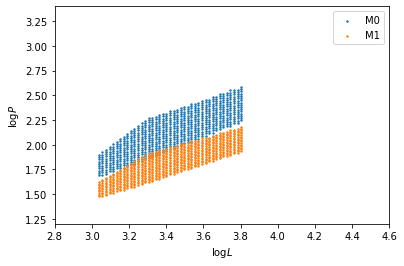

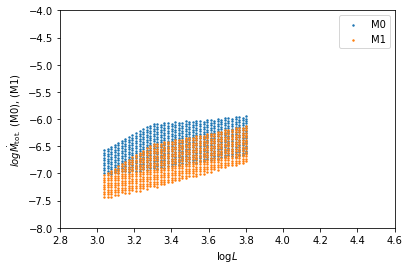

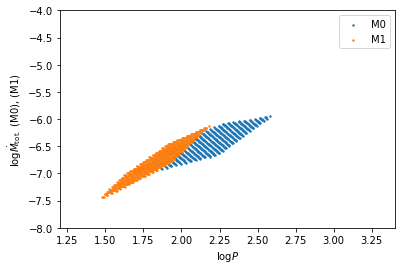

Difference vs logL fit: logMdot_1-logMdot_2= 1.6040670686869514 + -0.37979849213278377 logL
Difference vs logL fit errors: 0.006476186960031612 ,  0.0018817064396376496


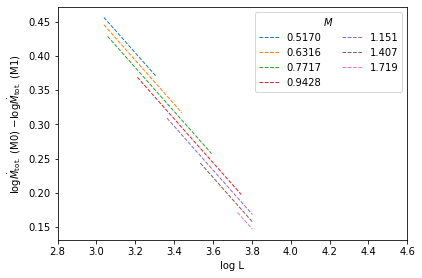

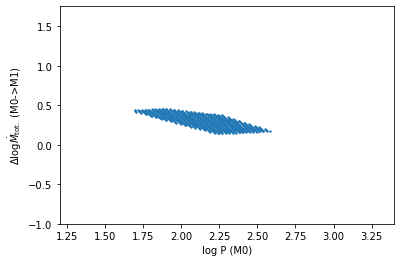

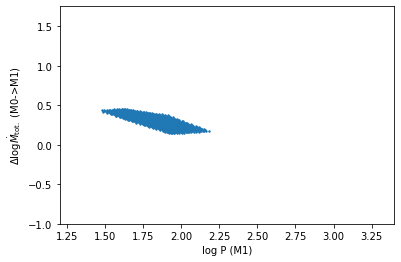

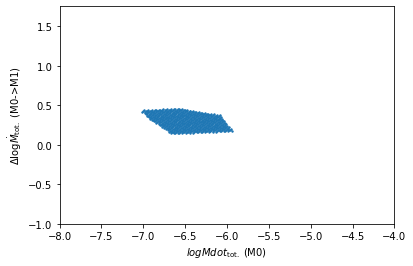

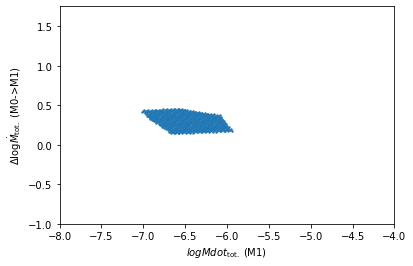

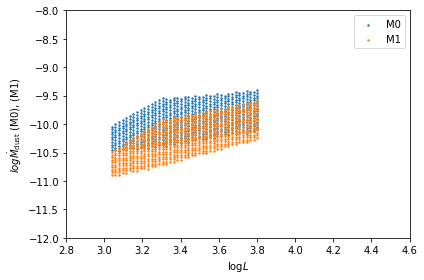

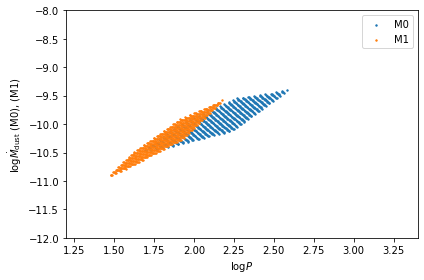

Difference vs logL fit: logMdot_1-logMdot_2= 1.6040670686869496 + -0.37979849213278366 logL
Difference vs logL fit errors: 0.006476186960031616 ,  0.0018817064396376509


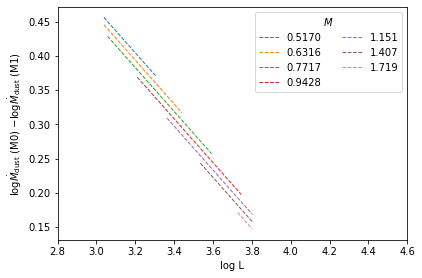

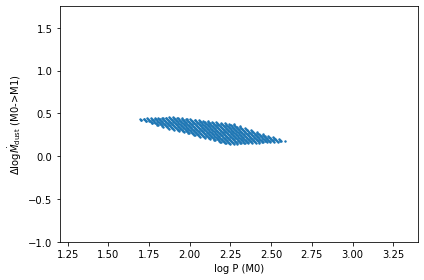

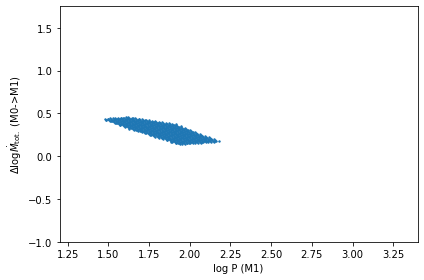

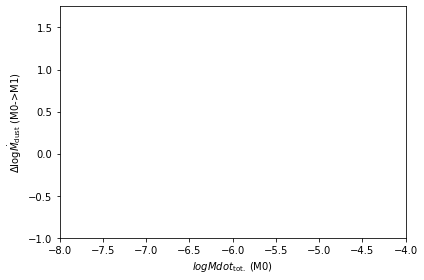

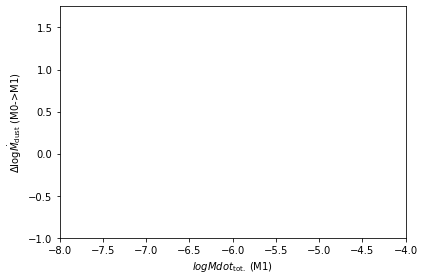

In [461]:
calculate_formula_correction ([MdotLP_Coeffs_M0,PML_M0],[MdotLP_Coeffs_M1,PML_M1],artifical_set_M_stars,coeffs_labels = ['M0','M1'])

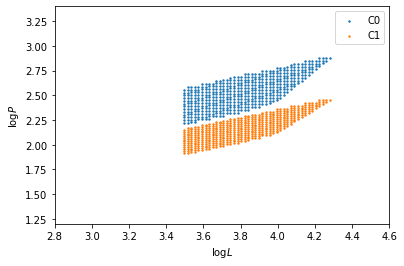

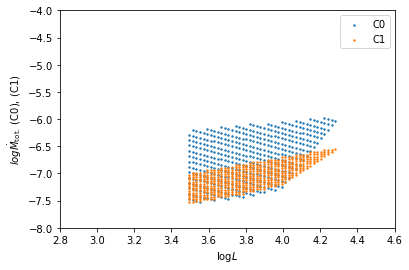

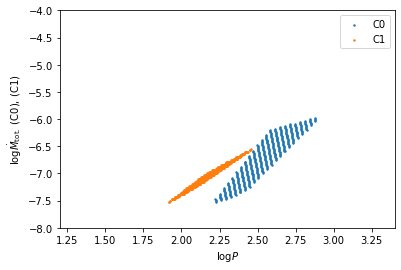

Difference vs logL fit: logMdot_1-logMdot_2= 0.33960963367988123 + 0.001882648705326678 logL
Difference vs logL fit errors: 0.1910345973909064 ,  0.049942006792644954


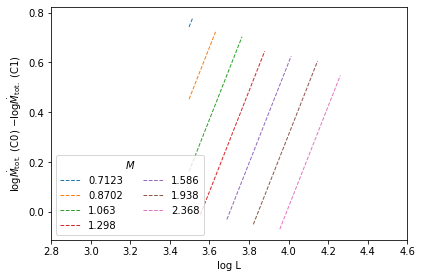

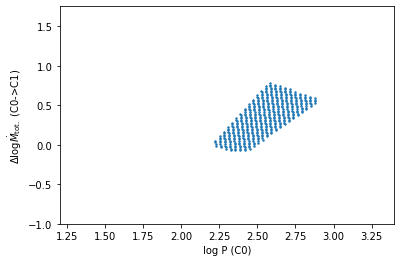

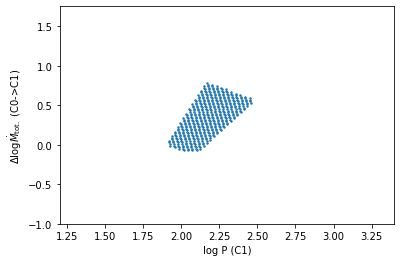

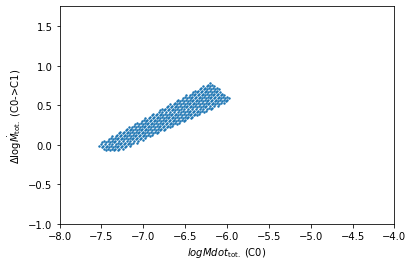

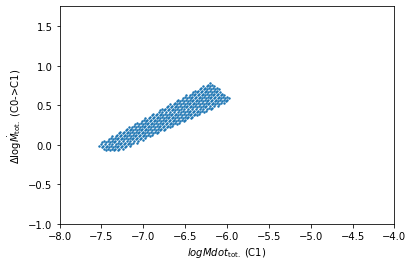

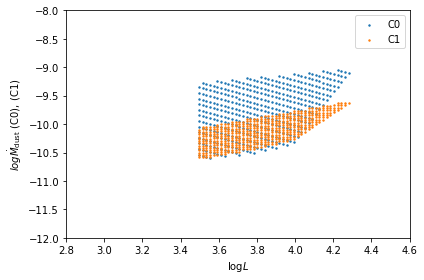

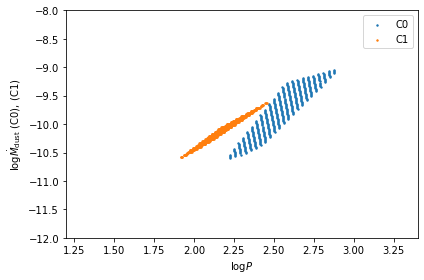

Difference vs logL fit: logMdot_1-logMdot_2= 0.3396096336798809 + 0.0018826487053267543 logL
Difference vs logL fit errors: 0.19103459739090636 ,  0.04994200679264495


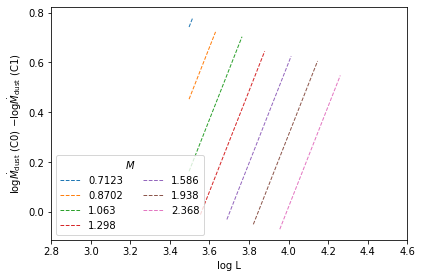

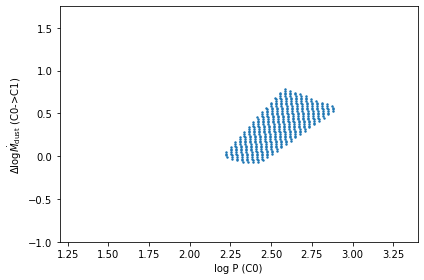

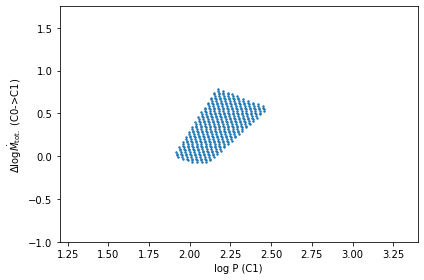

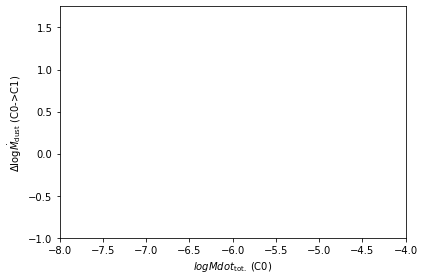

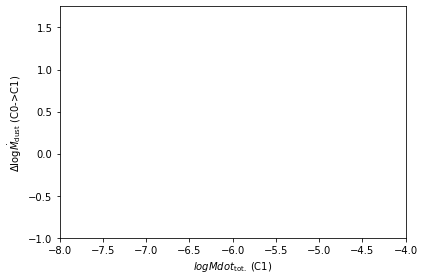

In [462]:
calculate_formula_correction ([MdotLP_Coeffs_C0andC0x,PML_C0],[MdotLP_Coeffs_C1,PML_C1],artifical_set_C_stars,coeffs_labels = ['C0','C1'])

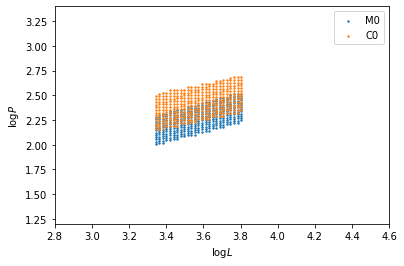

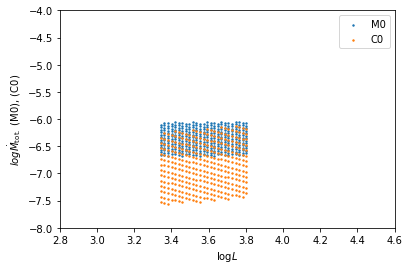

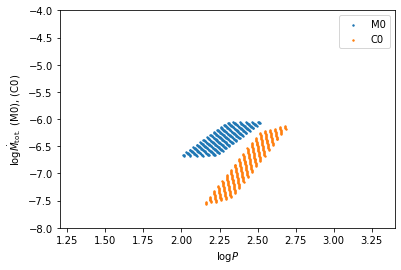

Difference vs logL fit: logMdot_1-logMdot_2= 1.4737812679338158 + -0.2777523613988125 logL
Difference vs logL fit errors: 0.294065242246236 ,  0.08222517572276394


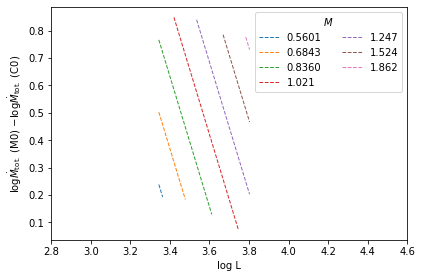

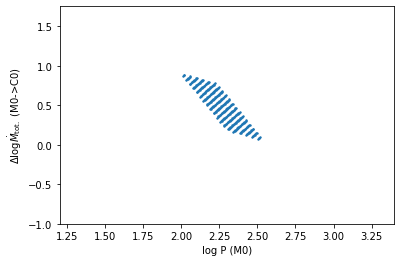

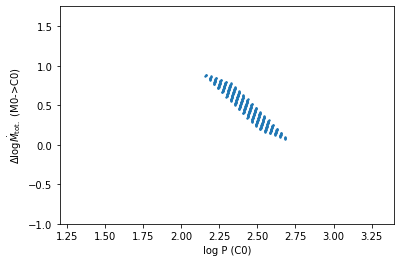

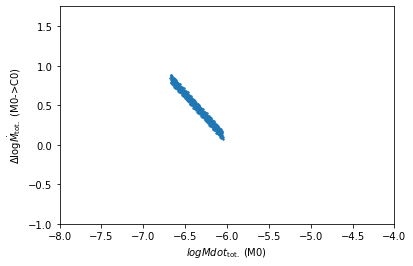

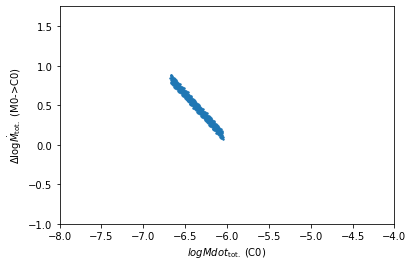

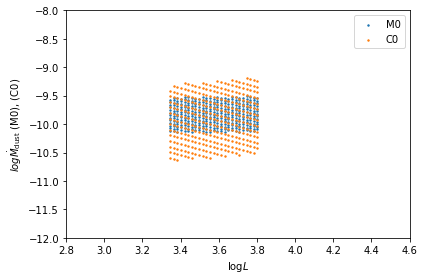

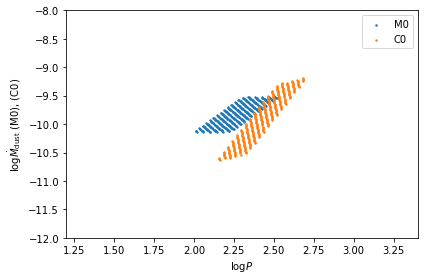

Difference vs logL fit: logMdot_1-logMdot_2= 1.075841259261777 + -0.27775236139881193 logL
Difference vs logL fit errors: 0.294065242246236 ,  0.08222517572276394


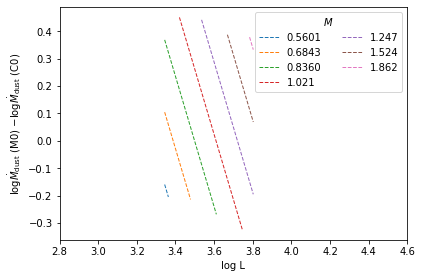

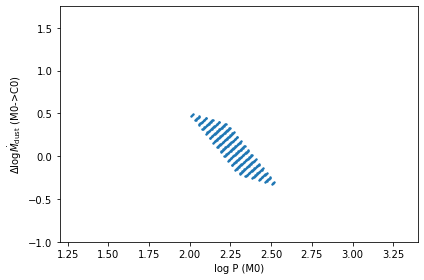

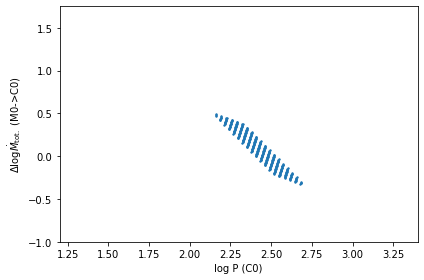

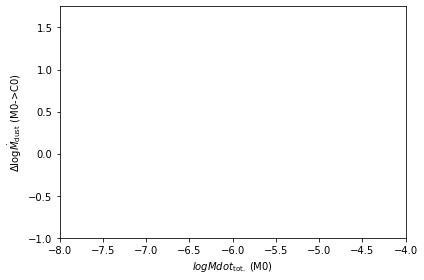

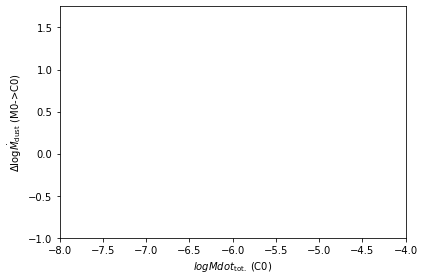

In [463]:
calculate_formula_correction ([LPCoeffsM0_GRAMS,PML_M0],[MdotLP_Coeffs_C0andC0x,PML_C0],artifical_set_0_stars,coeffs_labels = ['M0','C0'])

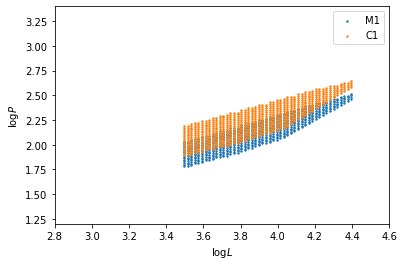

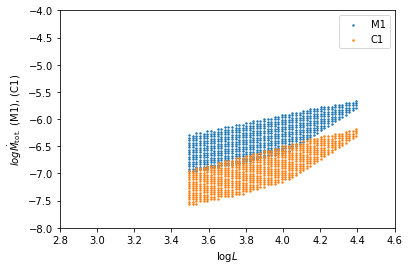

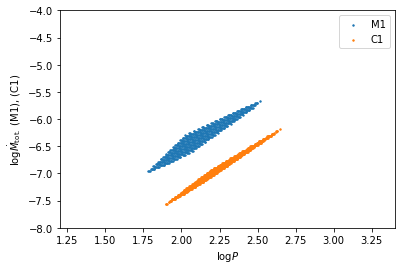

Difference vs logL fit: logMdot_1-logMdot_2= 1.0610982363382266 + -0.12585352499014743 logL
Difference vs logL fit errors: 0.00832741286025448 ,  0.0021413168807886164


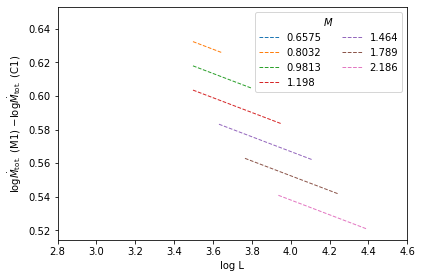

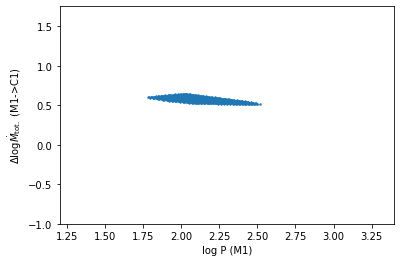

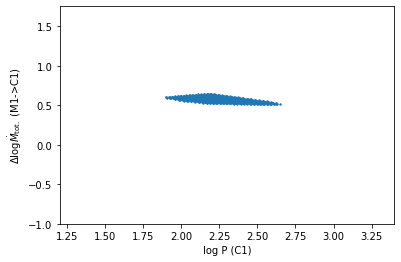

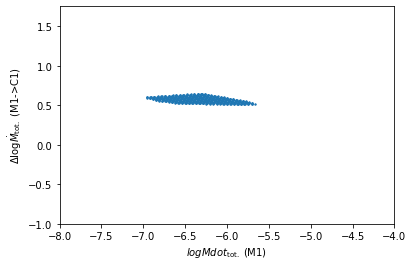

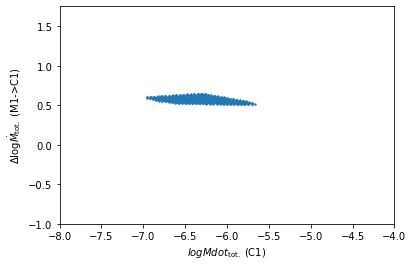

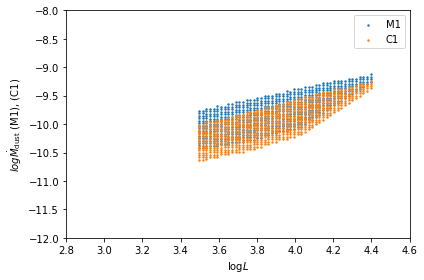

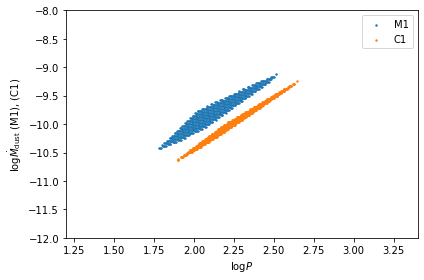

Difference vs logL fit: logMdot_1-logMdot_2= 0.6631582276661883 + -0.12585352499014707 logL
Difference vs logL fit errors: 0.008327412860254471 ,  0.002141316880788614


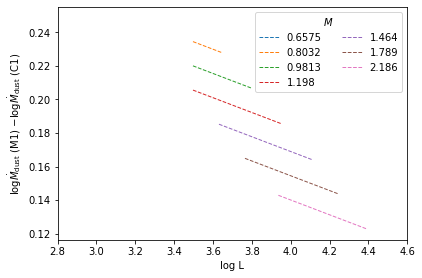

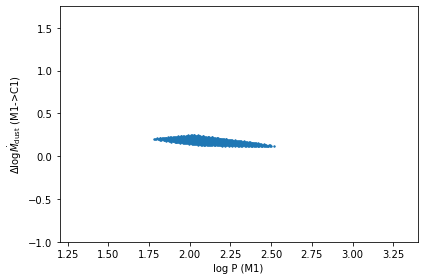

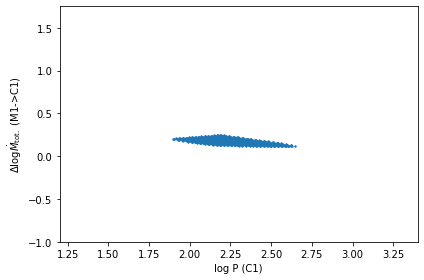

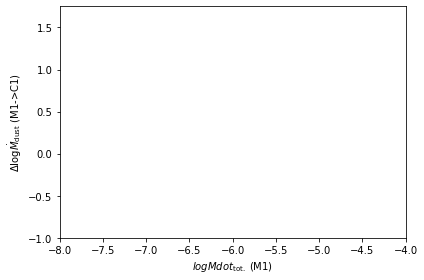

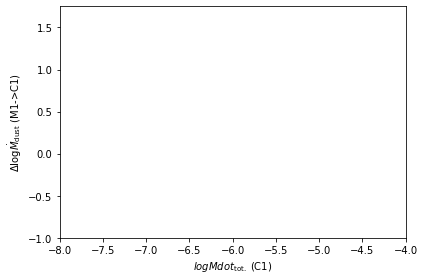

In [464]:
calculate_formula_correction ([MdotLP_Coeffs_M1,PML_M1],[MdotLP_Coeffs_C1,PML_C1],artifical_set_1_stars,coeffs_labels = ['M1','C1'])

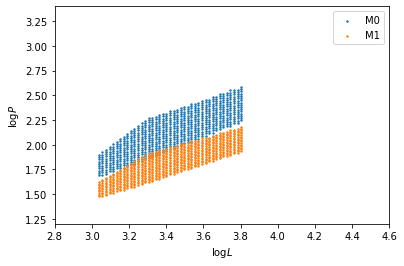

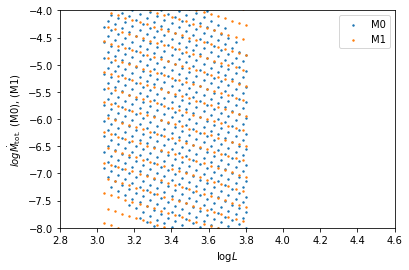

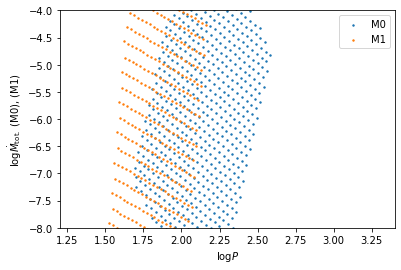

Difference vs logL fit: logMdot_1-logMdot_2= 1.985955561044788 + -0.3190437635418012 logL
Difference vs logL fit errors: 0.8098450182373452 ,  0.23530676234804745


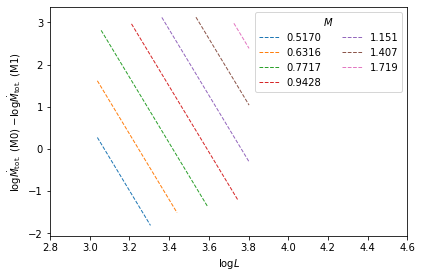

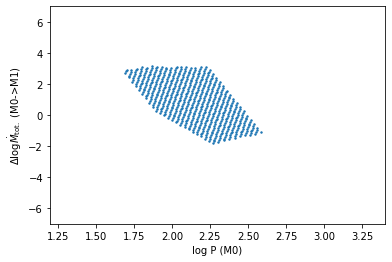

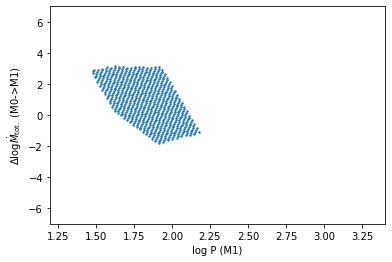

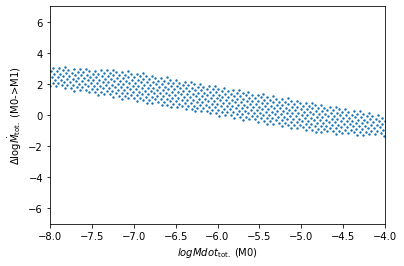

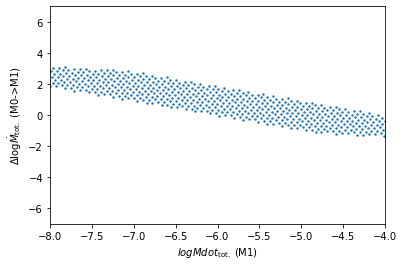

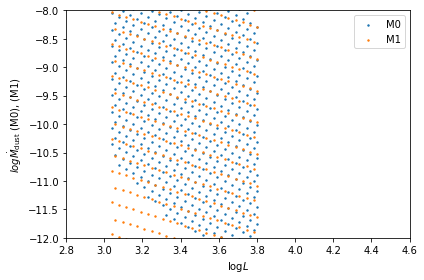

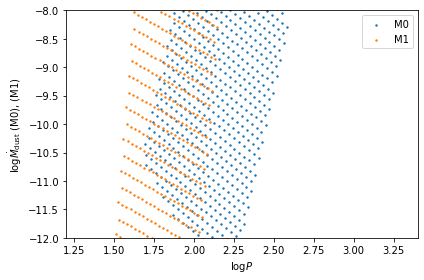

Difference vs logL fit: logMdot_1-logMdot_2= 1.985955561044788 + -0.3190437635418012 logL
Difference vs logL fit errors: 0.8098450182373452 ,  0.23530676234804745


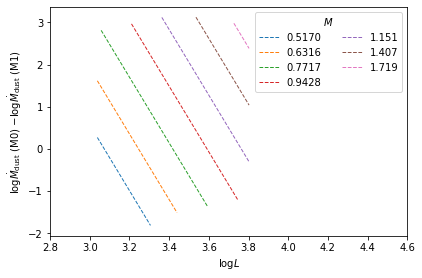

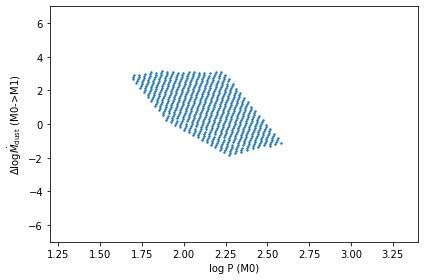

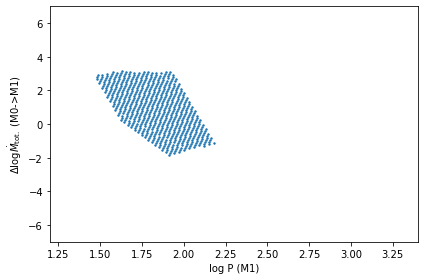

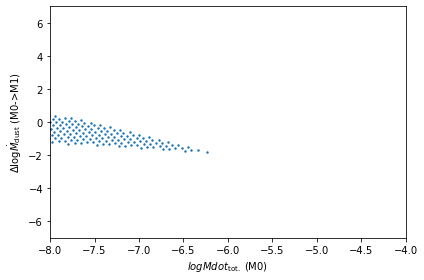

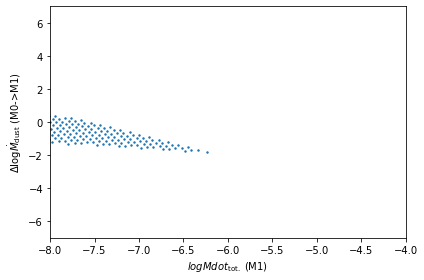

In [465]:
calculate_formula_correction_MdotP ([LMdotP_Coeffs_M0,PML_M0],[LMdotP_Coeffs_M1,PML_M1],artifical_set_M_stars,coeffs_labels = ['M0','M1'])

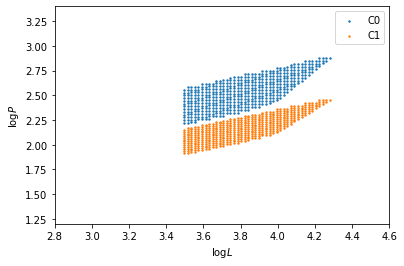

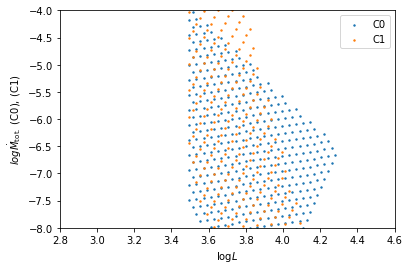

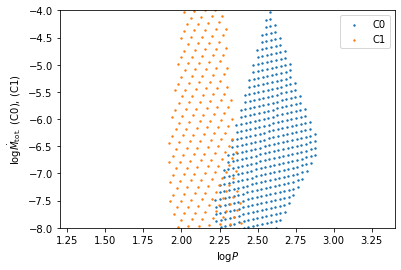

Difference vs logL fit: logMdot_1-logMdot_2= -31.735611547640854 + 8.468438831518812 logL
Difference vs logL fit errors: 0.683159158667588 ,  0.17859769805371595


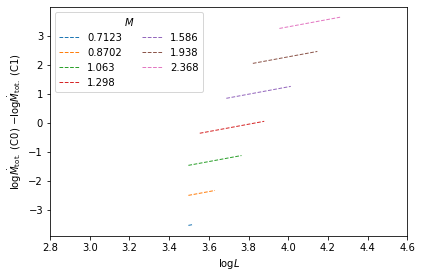

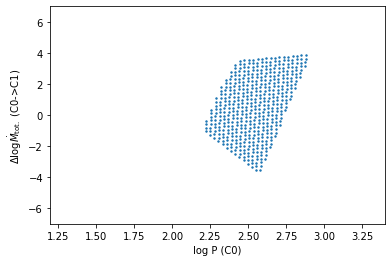

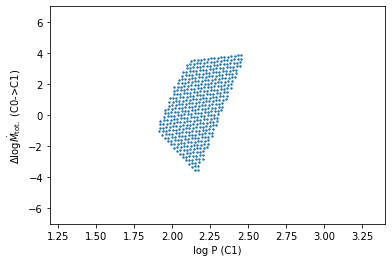

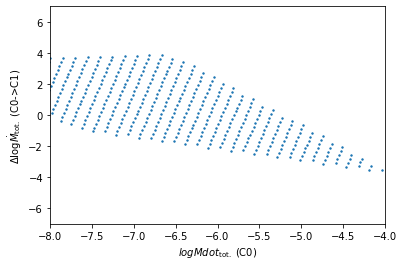

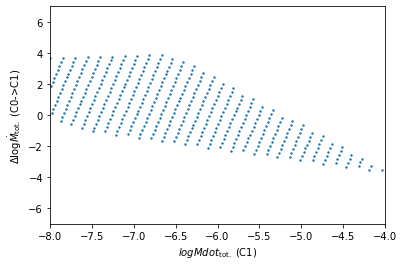

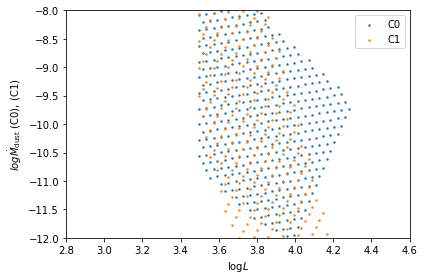

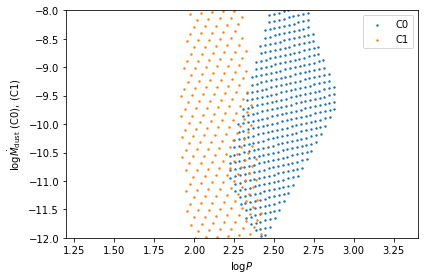

Difference vs logL fit: logMdot_1-logMdot_2= -31.735611547640854 + 8.468438831518812 logL
Difference vs logL fit errors: 0.683159158667588 ,  0.17859769805371595


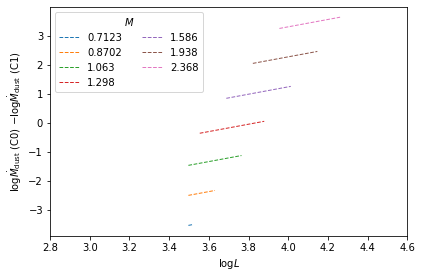

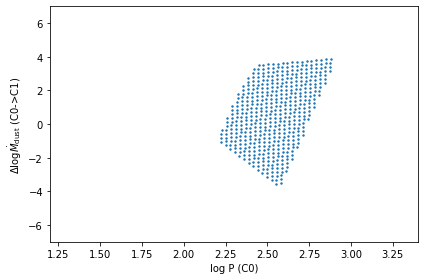

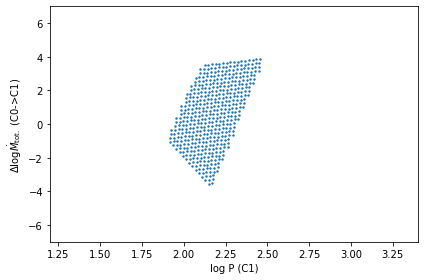

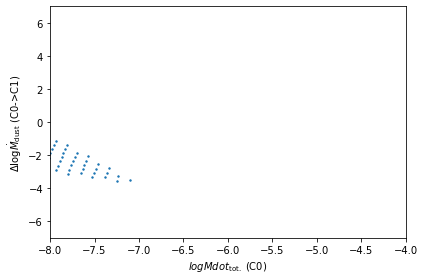

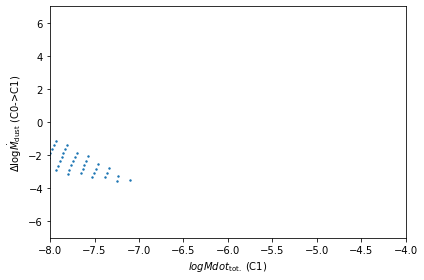

In [466]:
calculate_formula_correction_MdotP ([LMdotP_Coeffs_C0andC0x,PML_C0],[LMdotP_Coeffs_C1,PML_C1],artifical_set_C_stars,coeffs_labels = ['C0','C1'])

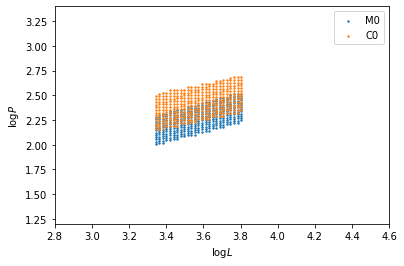

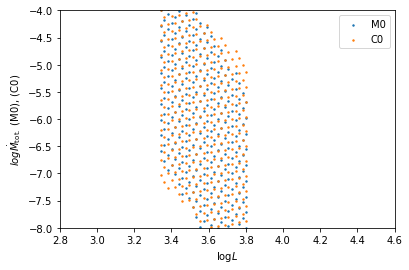

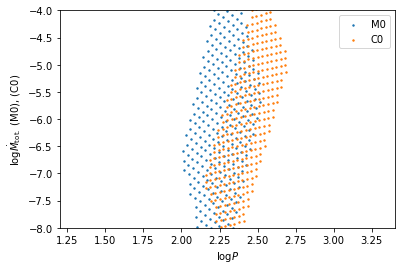

Difference vs logL fit: logMdot_1-logMdot_2= 8.968249494266592 + -2.5283151623943354 logL
Difference vs logL fit errors: 0.0719590914813325 ,  0.020120871466164397


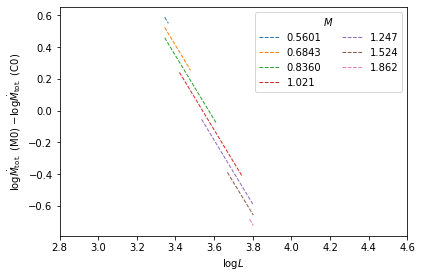

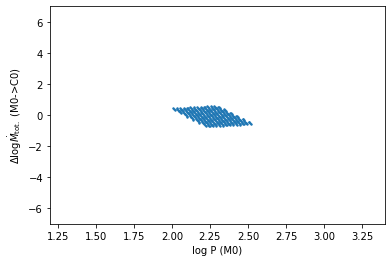

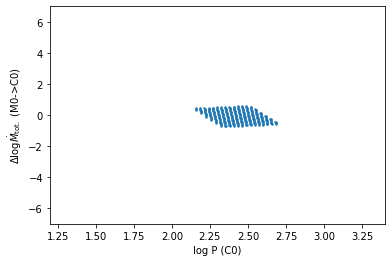

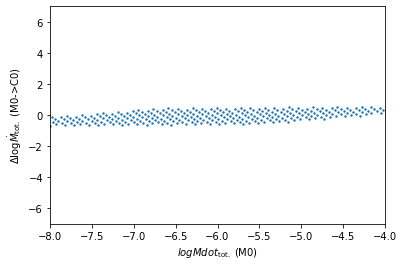

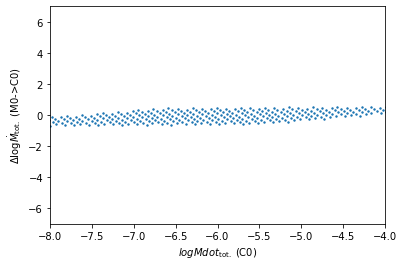

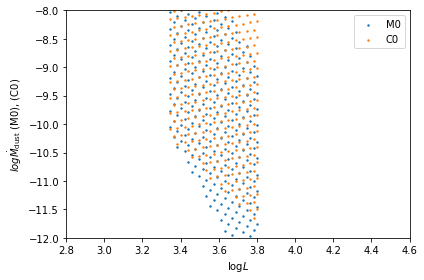

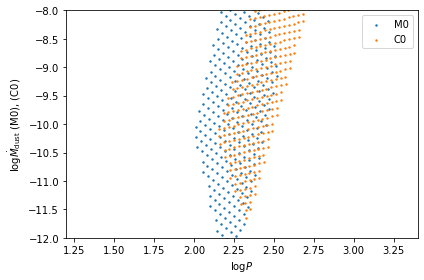

Difference vs logL fit: logMdot_1-logMdot_2= 8.570309485594551 + -2.5283151623943327 logL
Difference vs logL fit errors: 0.07195909148133253 ,  0.020120871466164408


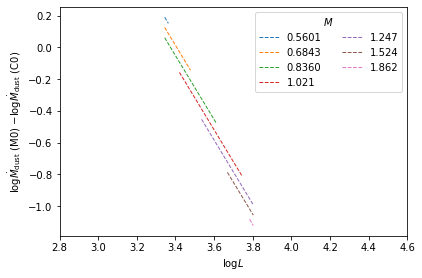

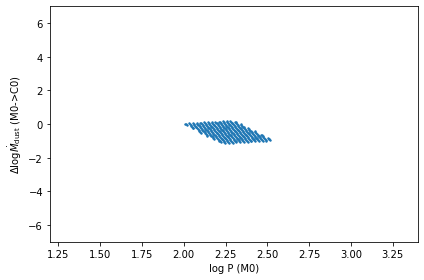

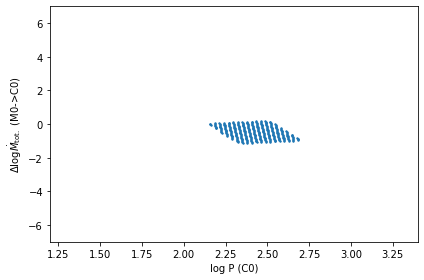

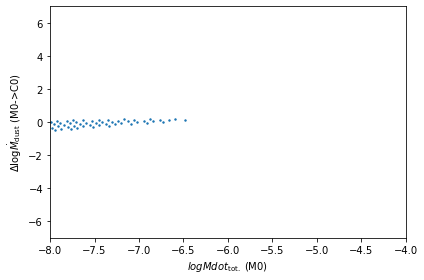

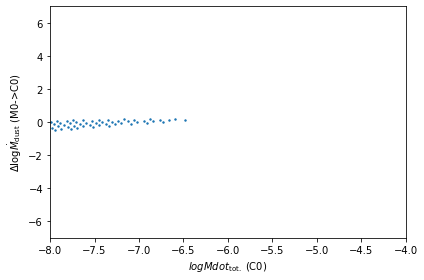

In [467]:
calculate_formula_correction_MdotP ([LMdotP_Coeffs_M0,PML_M0],[LMdotP_Coeffs_C0andC0x,PML_C0],artifical_set_0_stars,coeffs_labels = ['M0','C0'])

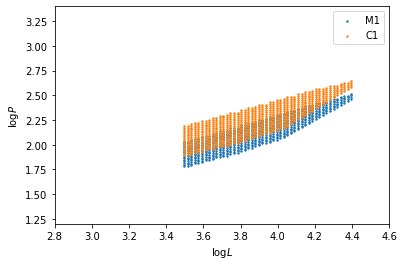

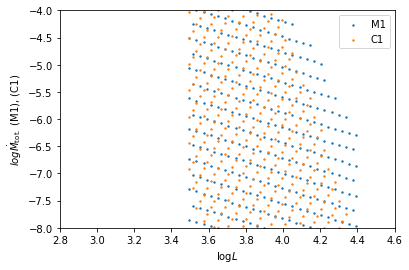

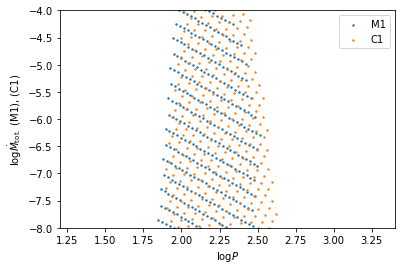

Difference vs logL fit: logMdot_1-logMdot_2= -19.91313880678566 + 4.920704554639543 logL
Difference vs logL fit errors: 0.2166667442072775 ,  0.055713841100749076


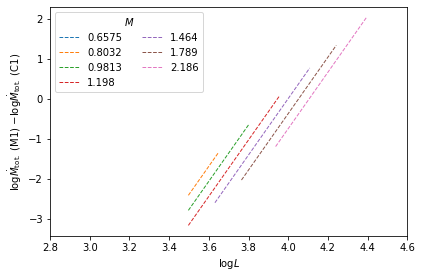

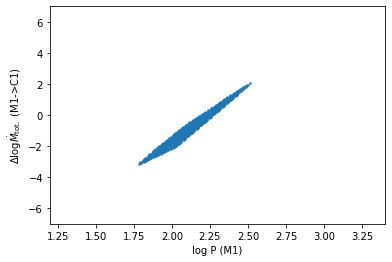

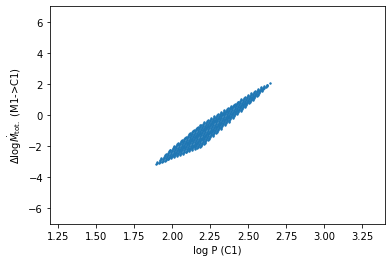

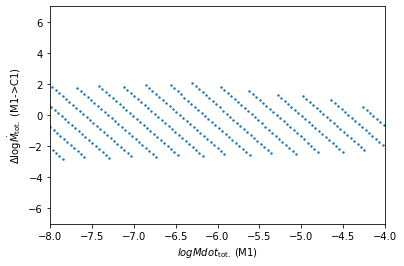

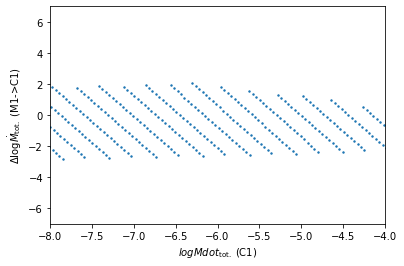

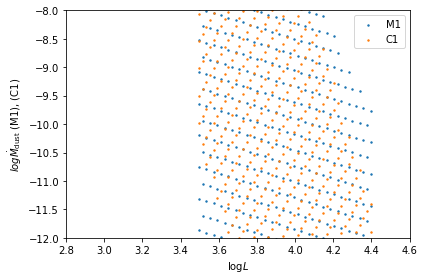

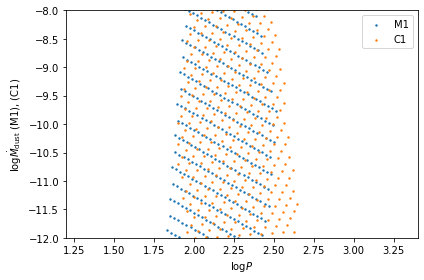

Difference vs logL fit: logMdot_1-logMdot_2= -20.3110788154577 + 4.920704554639547 logL
Difference vs logL fit errors: 0.21666674420727747 ,  0.05571384110074907


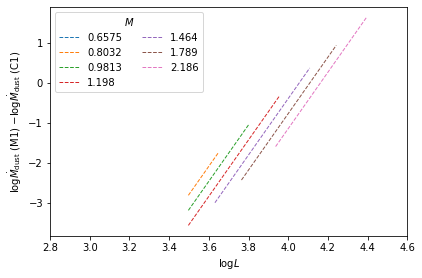

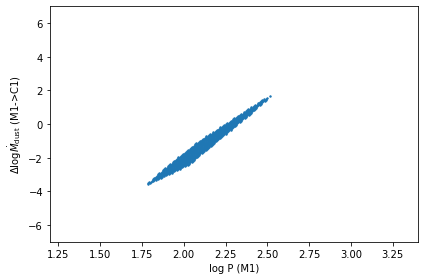

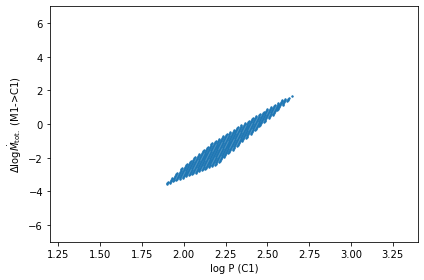

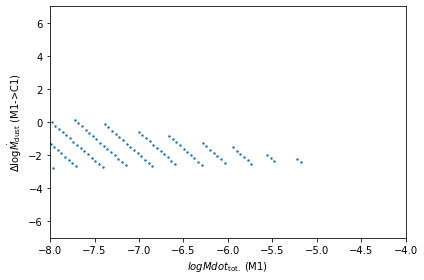

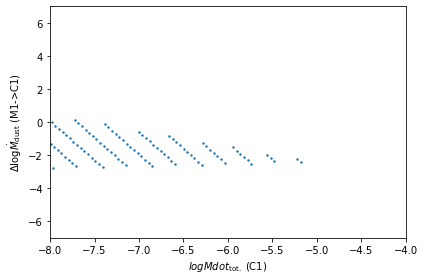

In [468]:
calculate_formula_correction_MdotP ([LMdotP_Coeffs_M1,PML_M1],[LMdotP_Coeffs_C1,PML_C1],artifical_set_1_stars,coeffs_labels = ['M1','C1'])

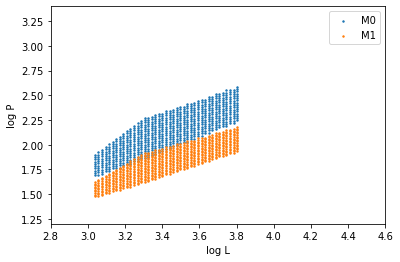

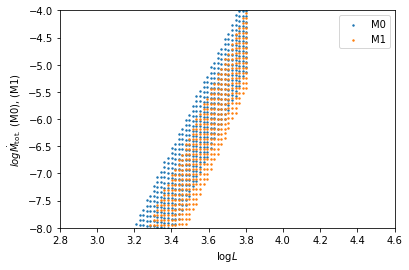

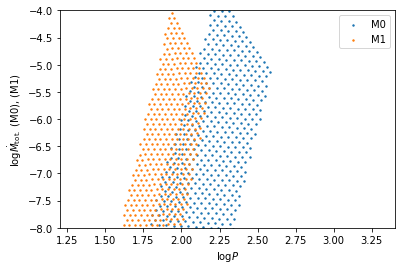

Difference vs logL fit: logMdot_1-logMdot_2= 1.9884375212294003 + -0.4425830126797352 logL
Difference vs logL fit errors: 0.0019875795772837557 ,  0.0005775066891905889


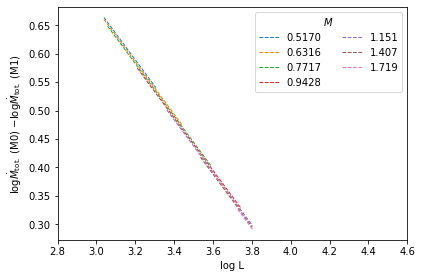

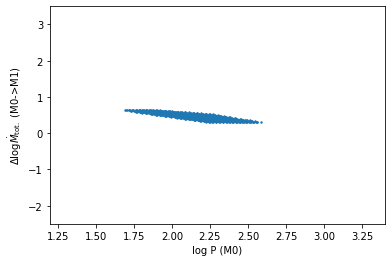

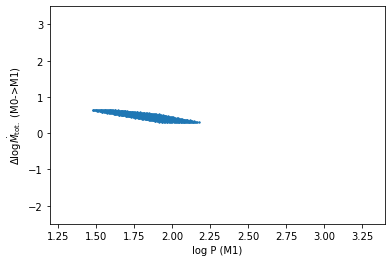

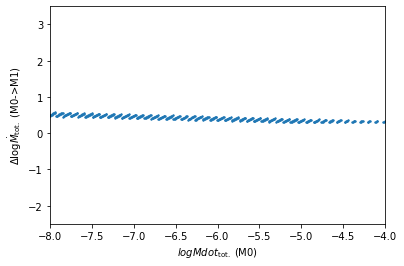

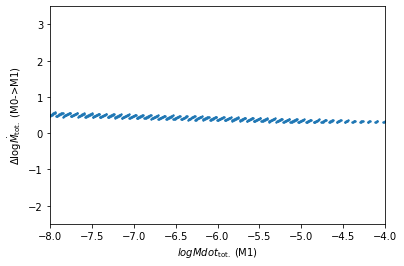

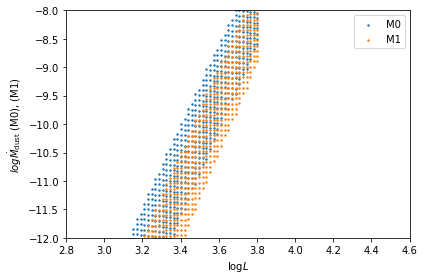

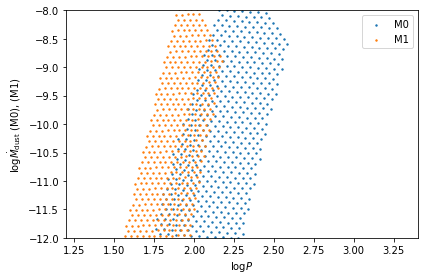

Difference vs logL fit: logMdot_1-logMdot_2= 1.988437521229399 + -0.44258301267973493 logL
Difference vs logL fit errors: 0.0019875795772837934 ,  0.0005775066891905998


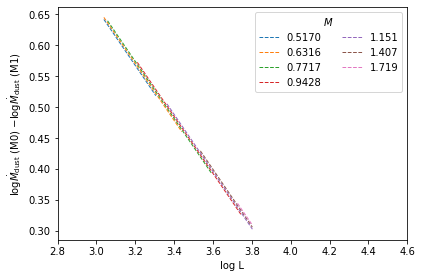

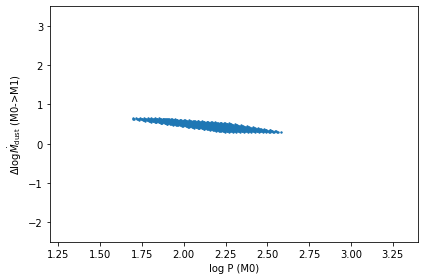

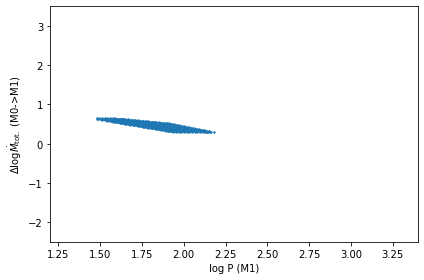

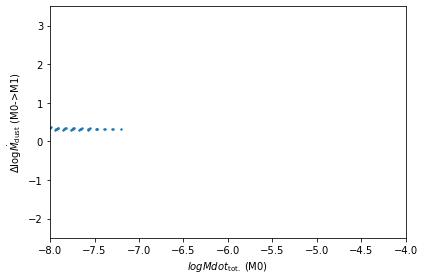

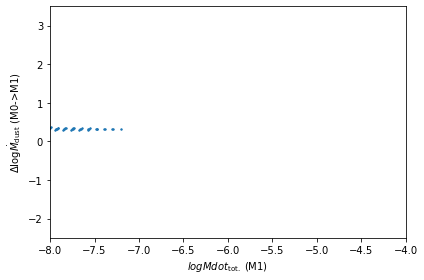

__________________________________________________________________


In [469]:
calculate_formula_correction_dz ([deathzone_values_M0,PML_M0],[deathzone_values_M1,PML_M1],artifical_set_M_stars,coeffs_labels = ['M0','M1'])


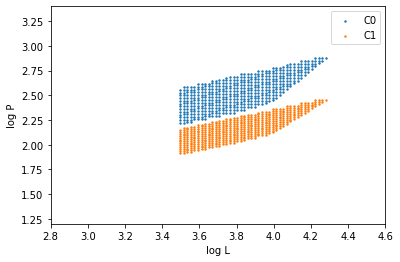

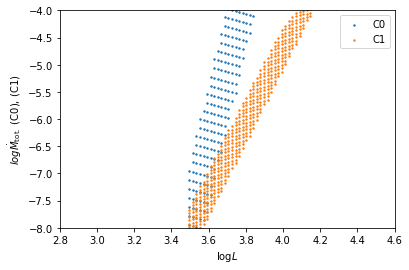

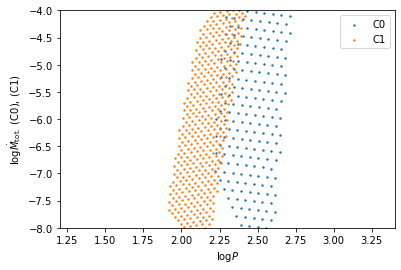

Difference vs logL fit: logMdot_1-logMdot_2= -24.932381551601527 + 7.183463342590307 logL
Difference vs logL fit errors: 0.3415008099210893 ,  0.08927825640856749


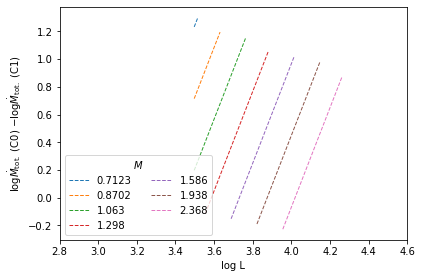

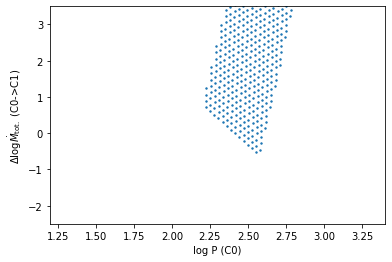

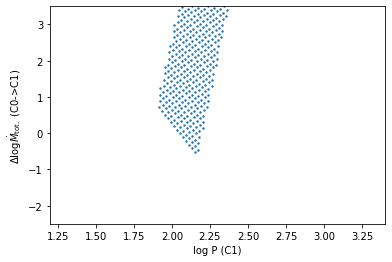

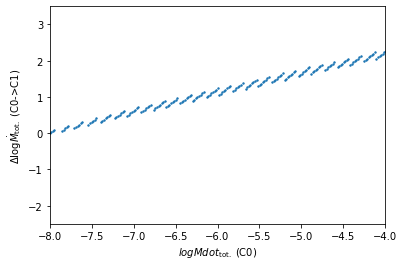

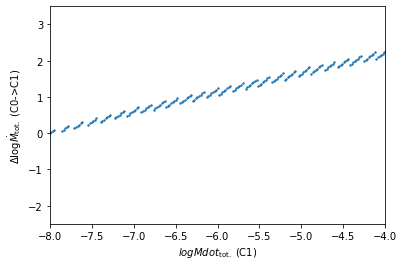

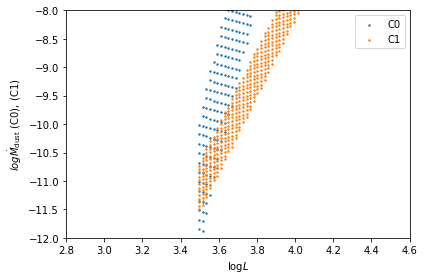

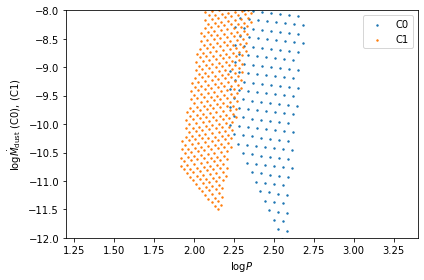

Difference vs logL fit: logMdot_1-logMdot_2= -24.932381551601527 + 7.183463342590306 logL
Difference vs logL fit errors: 0.3415008099210892 ,  0.08927825640856746


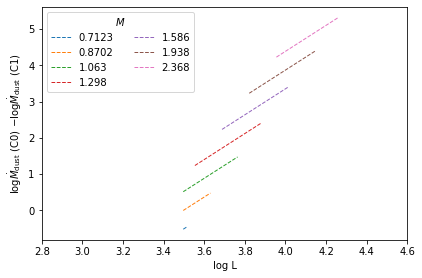

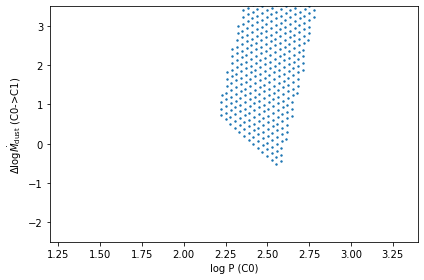

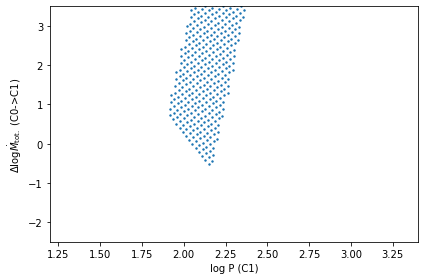

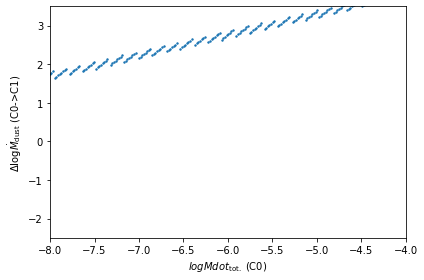

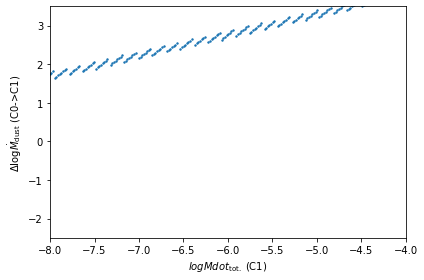

__________________________________________________________________


In [470]:
calculate_formula_correction_dz ([deathzone_values_C0_and_C0x,PML_C0],[deathzone_values_C1,PML_C1],artifical_set_C_stars,coeffs_labels = ['C0','C1'])


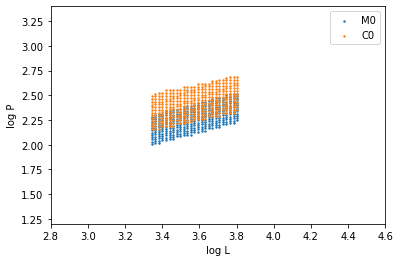

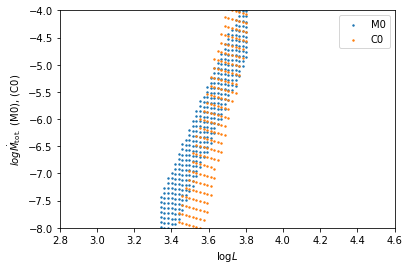

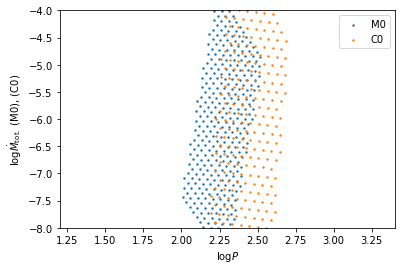

Difference vs logL fit: logMdot_1-logMdot_2= 23.379944830591857 + -6.342969358677592 logL
Difference vs logL fit errors: 0.4173049251818427 ,  0.11668489121988737


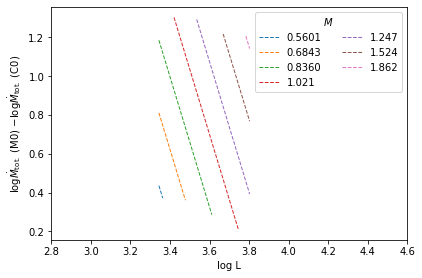

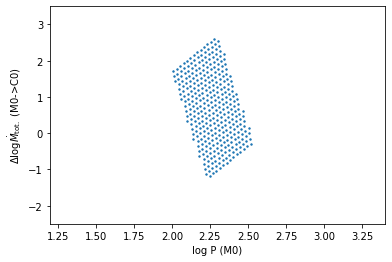

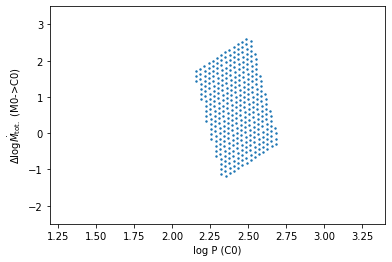

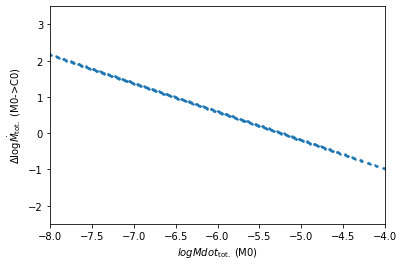

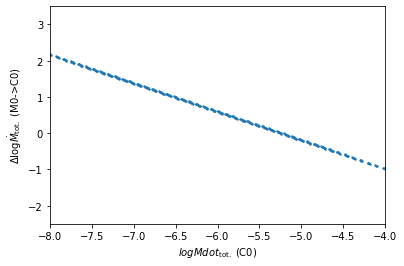

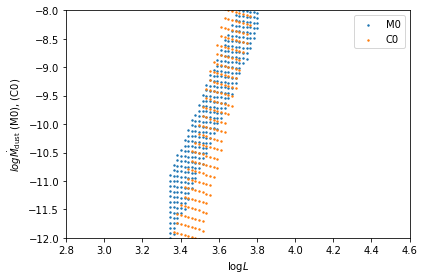

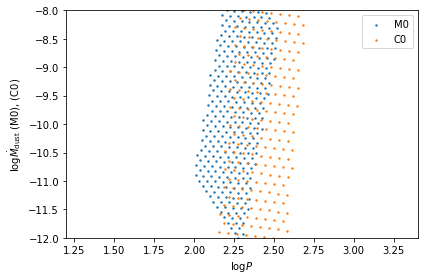

Difference vs logL fit: logMdot_1-logMdot_2= 22.982004821919816 + -6.342969358677594 logL
Difference vs logL fit errors: 0.4173049251818427 ,  0.11668489121988737


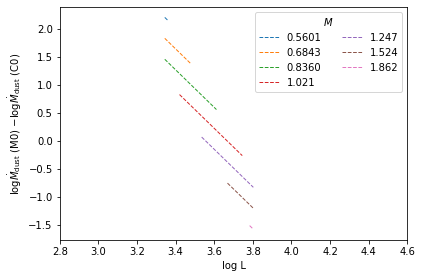

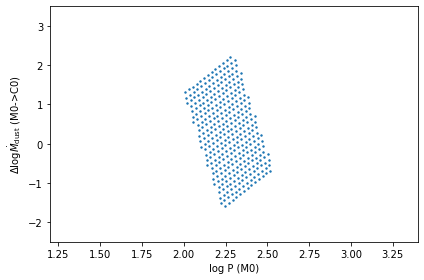

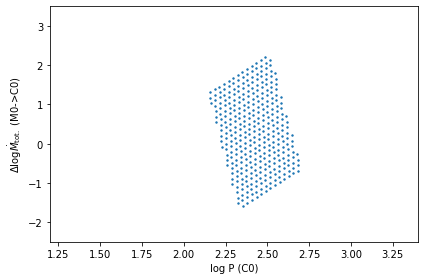

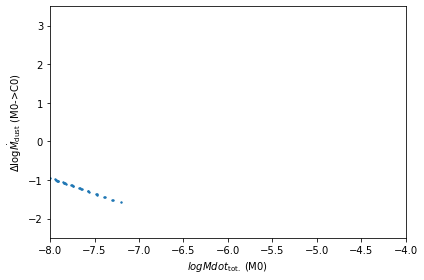

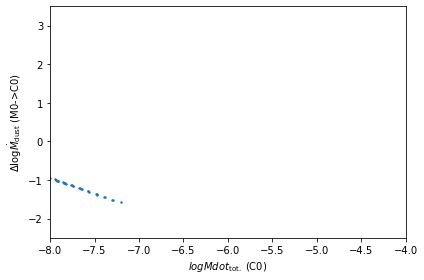

__________________________________________________________________


In [471]:
calculate_formula_correction_dz ([deathzone_values_M0,PML_M0],[deathzone_values_C0_and_C0x,PML_C0],artifical_set_0_stars,coeffs_labels = ['M0','C0'])


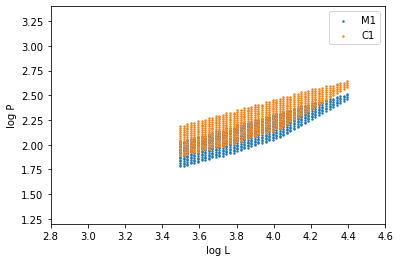

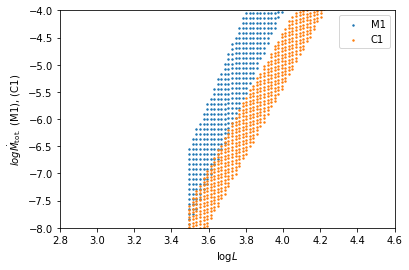

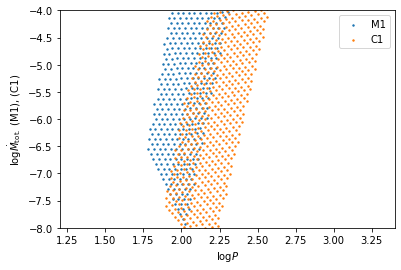

Difference vs logL fit: logMdot_1-logMdot_2= -4.2665325824910205 + 1.4713049713917852 logL
Difference vs logL fit errors: 0.08013911593330494 ,  0.020607029414681594


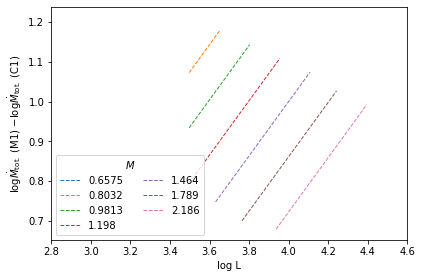

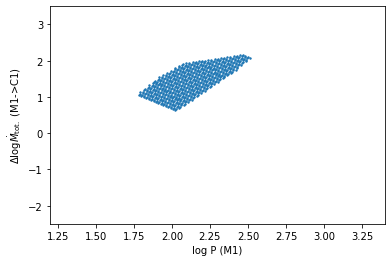

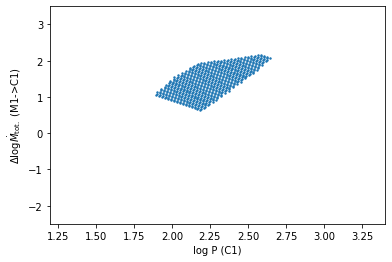

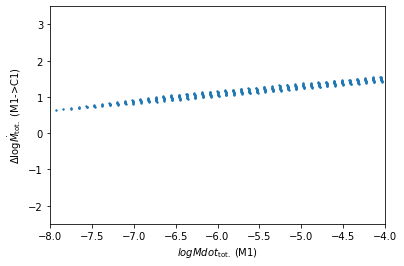

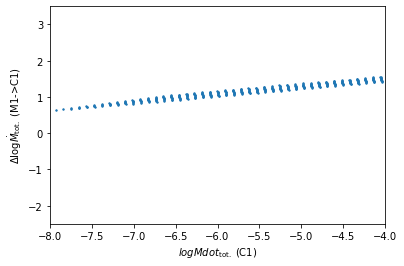

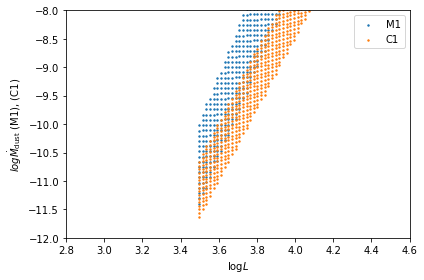

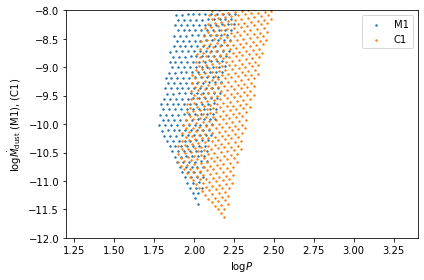

Difference vs logL fit: logMdot_1-logMdot_2= -4.664472591163057 + 1.4713049713917852 logL
Difference vs logL fit errors: 0.08013911593330493 ,  0.02060702941468159


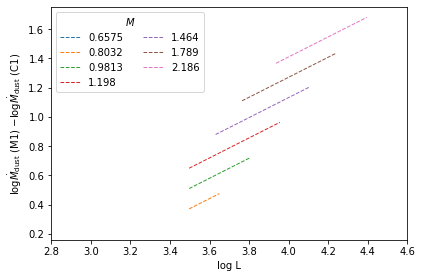

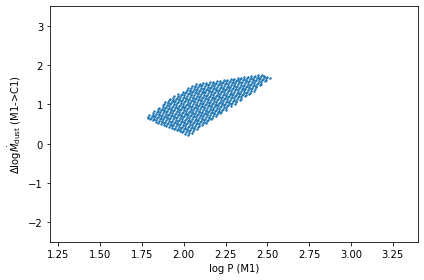

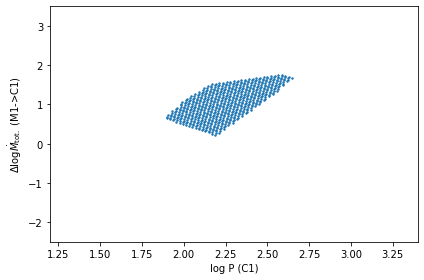

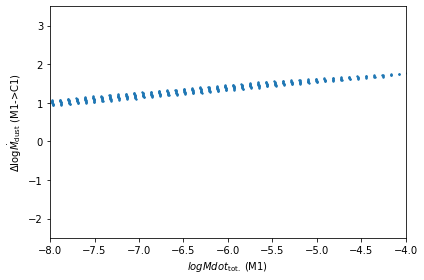

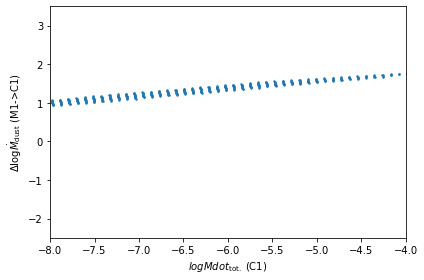

__________________________________________________________________


In [472]:
calculate_formula_correction_dz ([deathzone_values_M1,PML_M1],[deathzone_values_C1,PML_C1],artifical_set_1_stars,coeffs_labels = ['M1','C1'])

In [473]:
def residual_histograms (star_data,MdotLP_coeffs, LMdotP_coeffs, MdotLM_coeffs,spec_mode_label=''):
    # Ex: residual_histograms (M0StarData, MdotLP_Coeffs_M0 ,LMdotP_Coeffs_M0, deathzone_values_M0)
    logPData = np.log10(star_data[PIndex])
    logLData = np.log10(star_data[LIndex])
    logMData = np.log10(star_data[MIndex])
    logMdotData = np.log10(star_data[MdotIndex])
    
    logMdot_MdotLP = MdotLP_coeffs[0]+MdotLP_coeffs[1]*logLData+MdotLP_coeffs[2]*logPData
    logMdot_LMdotP = LMdotP_coeffs[0]+LMdotP_coeffs[1]*logLData+LMdotP_coeffs[2]*logPData
    logMdot_MdotLM = MdotLM_coeffs[0]+MdotLM_coeffs[1]*logLData+MdotLM_coeffs[2]*logMData
    
    residual_MdotLP = logMdot_MdotLP - logMdotData
    residual_LMdotP = logMdot_LMdotP - logMdotData
    residual_MdotLM = logMdot_MdotLM - logMdotData
    
    plot.hist([residual_MdotLP, residual_LMdotP, residual_MdotLM],bins=20,histtype='step',label=['Mdot(L,P)','L(Mdot,P)','Mdot(L,M)'])
    plot.legend()
    plot.xlabel(r'$\log \dot{M}_{\mathrm{calc.}}-\log \dot{M}_{\mathrm{obsv.}}$')
    plot.title(spec_mode_label)

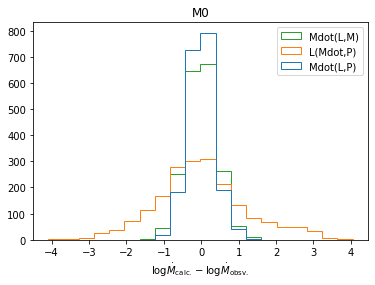

In [474]:
residual_histograms (M0StarData, MdotLP_Coeffs_M0 ,LMdotP_Coeffs_M0, deathzone_values_M0,spec_mode_label='M0')

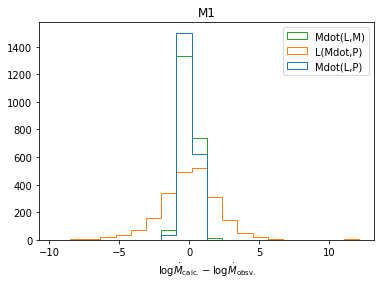

In [475]:
residual_histograms (M1StarData, MdotLP_Coeffs_M1 ,LMdotP_Coeffs_M1, deathzone_values_M1,spec_mode_label='M1')

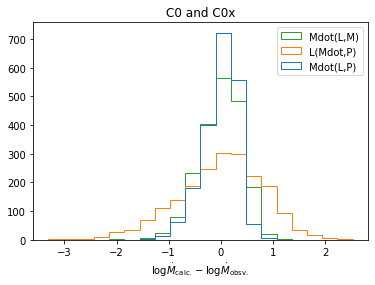

In [476]:
residual_histograms (C0StarData, MdotLP_Coeffs_C0andC0x ,LMdotP_Coeffs_C0andC0x, deathzone_values_C0_and_C0x,spec_mode_label='C0 and C0x')

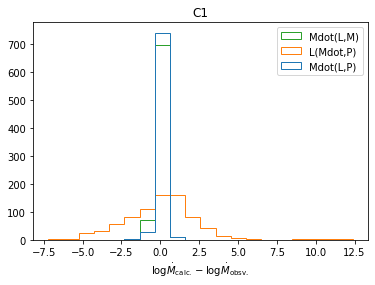

In [477]:
residual_histograms (C1StarData, MdotLP_Coeffs_C1 ,LMdotP_Coeffs_C1, deathzone_values_C1,spec_mode_label='C1')